# Calculadora independiente de UM con la TG-71: el motor por dentro

> **Datos inventados para estudiar el motor; no es un cálculo clínico.**
> Todas las tablas, los planes y los resultados del «planeador» de este cuaderno son simulados.

**Para qué sirve.** Este cuaderno muestra funcionando lo esencial de una calculadora independiente de unidades monitor
(UM), organizada como estará en la app: cómo se leen las tablas del haz, cómo se arma la geometría a partir de un plan
con los nombres del RTPLAN de DICOM, cómo entra cada factor en las ecuaciones de la TG-71 (y de dónde sale), cómo se
integra la dispersión de un campo irregular con el método de Clarkson y cómo se compara el resultado con el planeador
usando los niveles de acción de la TG-114.

**Cómo usarlo en Colab.** Menú «Entorno de ejecución → Ejecutar todas». No hay que instalar nada (solo usa numpy,
pandas y matplotlib) ni subir archivos: todo se genera dentro del cuaderno, y corre en menos de dos minutos. Se puede
cambiar cualquier dato de un caso y volver a ejecutar desde esa celda hacia abajo: cada celda de caso borra primero
las filas que dejó en el resumen en una corrida anterior (aunque cambie el nombre de un haz, la SSD o el número de
campos), y las pruebas de la sección 13 usan **datos propios**, así que cambiar un caso no las hace fallar.

**Tres piezas, separadas a propósito.**
1. **El mundo simulado** («la verdad»): un modelo físico sencillo de un haz de 6 MV con filtro aplanador y láminas
   terciarias tipo Varian, y de un haz de electrones de 9 MeV. Con él se «miden» las tablas del comisionamiento y se
   simula el planeador («Eclipse»).
2. **El motor**: lo que irá a la app. Solo lee las tablas medidas y el plan, igual que en la clínica; nunca consulta el
   modelo verdadero (una prueba de la sección 13 lo comprueba).
3. **Los casos**: nueve situaciones típicas, desde un campo abierto hasta un pulmón y un campo de electrones.

**Las ecuaciones generales de la TG-71 para fotones**

$$\mathrm{UM}=\frac{D}{D'_0\cdot S_c(r_c)\cdot S_p(r_d)\cdot \mathrm{TPR}(d,r_d)\cdot \mathrm{WF}(d,r_d,x)\cdot \mathrm{TF}\cdot \mathrm{OAR}(d,x)\cdot\left(\dfrac{SSD_0+d_0}{SPD}\right)^2}\qquad (1)$$

$$\mathrm{UM}=\frac{D}{D'_0\cdot S_c(r_c)\cdot S_p(r_d)\cdot \mathrm{TPR}(d,r_d)\cdot \mathrm{WF}(d,r_d)\cdot \mathrm{TF}\cdot\left(\dfrac{SSD_0+d_0}{SAD}\right)^2}\qquad (2)$$

$$\mathrm{UM}=\frac{D\cdot 100\,\%}{D'_0\cdot S_c(r_c)\cdot S_p(r_{d_0})\cdot \mathrm{PDD}_N(d,r,SSD)\cdot \mathrm{WF}(d,r_d,x)\cdot \mathrm{TF}\cdot \mathrm{OAR}(d,x)\cdot\left(\dfrac{SSD_0+d_0}{SSD+d_0}\right)^2}\qquad (3)$$

La ecuación 2 es la 1 con el punto en el isocentro ($SPD = SAD$, $\mathrm{OAR}=1$). Como en la TG-71, $SPD$ es la
distancia de la fuente al **plano perpendicular al eje** que contiene el punto, y $d$ la profundidad medida en esa
dirección: el inverso del cuadrado va hasta el plano del punto, y lo que cambia fuera del eje ya viene en el OAR
medido. Con heterogeneidades, la dosis por UM del cálculo en agua se multiplica por un factor de corrección CF
(ecuación 5): profundidad efectiva (ecuación 7) o Batho (ecuación 8). Para electrones se usan las ecuaciones 10 a 13
y 22.

**Índice**
1. Esta portada
2. Importaciones y estilo de los gráficos
3. El mundo simulado («la verdad»)
4. Las tablas del comisionamiento simulado
5. Lectura de tablas: interpolación, campo cero y tabla de dispersión (SMR)
6. Del plan al campo: RTPLAN, láminas, abertura, geometría IEC, maniquíes y profundidades
7. Clarkson paso a paso
8. El motor: factores, ecuaciones, orquestador y desglose
9. Comparación con el planeador (TG-114) y reporte
10. El «Eclipse» simulado
11. Casos 1 a 9
12. Validación con los ejemplos resueltos de la TG-71
13. Pruebas de coherencia
14. Qué se lleva a la app y qué falta para uso clínico
15. Referencias

**Mapa del cuaderno**

```
 MUNDO SIMULADO (secciones 3, 4 y 10)        MOTOR: lo que va a la app (secciones 5 a 9)

 ModeloVerdadero ──«mide»──► tablas ──────► DatosHaz: Sc, Scp → Sp, TMR, PDD, OAR, WF, TF, láminas
 (6 MV y 9 MeV)              redondeadas            │
       │                                             ▼
       └──► «Eclipse» ──► plan con UM ──► plan tipo ──► geometría ──► factores ──► ecuaciones ──► TG-114 ──► reporte
            simulado      y dosis por     RTPLAN       IEC 61217,     Sc, Sp, TPR,   1, 2, 3       niveles de
                          campo                        láminas,       OAR, WF, CF,   (10 a 13 y    acción
                                                       profundidades  Clarkson       22 en e⁻)
```

## 2. Importaciones y estilo de los gráficos

Solo se usan `numpy`, `pandas` y `matplotlib`, y de la biblioteca estándar de Python `math`, `dataclasses`, `types`,
`gc` y `typing`: Colab ya trae todo.
Los colores de los gráficos tienen un significado fijo en todo el cuaderno: **azul** = tramo abierto o dato medido,
**naranja** = tramo bloqueado (láminas o bloque) o segundo dato, **rojo** = punto de cálculo, **gris** = láminas,
**azul claro** = abertura del campo. Las tablas se imprimen como texto con decimales fijos: factores con 4 decimales,
distancias con 2 y UM con 1.

In [1]:
import dataclasses
import gc
import math
import types
from dataclasses import dataclass, field
from typing import List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse as ParcheElipse, Patch, Polygon, Rectangle

# Colores con significado fijo (orden de la paleta categórica validada para daltonismo)
COLOR = {
    "azul": "#2a78d6", "naranja": "#eb6834", "aguamarina": "#1baf7a", "amarillo": "#eda100",
    "magenta": "#e87ba4", "verde": "#008300", "violeta": "#6250d6", "rojo": "#e34948",
    "azul_claro": "#cde2fb", "gris_laminas": "#b9b8b0", "tinta": "#0b0b0b", "tinta_2": "#52514e",
    "tenue": "#898781", "rejilla": "#e1e0d9", "eje": "#c3c2b7", "fondo": "#fcfcfb",
}
SERIES = [COLOR[k] for k in ("azul", "naranja", "aguamarina", "amarillo", "magenta", "verde", "violeta", "rojo")]

plt.rcParams.update({
    "figure.facecolor": COLOR["fondo"], "axes.facecolor": COLOR["fondo"], "savefig.facecolor": COLOR["fondo"],
    "figure.dpi": 100, "font.size": 9.5, "axes.titlesize": 10.5, "axes.labelsize": 9.5,
    "axes.edgecolor": COLOR["eje"], "axes.labelcolor": COLOR["tinta_2"], "axes.titlecolor": COLOR["tinta"],
    "xtick.color": COLOR["eje"], "ytick.color": COLOR["eje"],
    "xtick.labelcolor": COLOR["tinta_2"], "ytick.labelcolor": COLOR["tinta_2"],
    "axes.grid": True, "grid.color": COLOR["rejilla"], "grid.linewidth": 0.7, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "lines.markersize": 4.5, "legend.frameon": False, "legend.fontsize": 8.5,
})
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 300)


def imprimir_tabla(tabla, titulo="", decimales=4):
    """Imprime una tabla con decimales fijos (texto: se ve igual en Colab y en el registro de la corrida)."""
    if titulo:
        print(titulo)
    if isinstance(tabla, pd.Series):
        tabla = tabla.to_frame()
    limite = 0.5 * 10 ** (-decimales)          # para no imprimir «-0.00» por ruido numérico
    print(tabla.to_string(float_format=lambda v: f"{(0.0 if abs(v) < limite else v):.{decimales}f}", na_rep="—"))
    print()


def _texto_celda(v, formato):
    """Texto de una celda: números con su formato (un cero sale sin signo), vacíos como «—», sí/no para booleanos."""
    if v is None:
        return "—"
    if isinstance(v, (bool, np.bool_)):
        return "sí" if v else "no"
    if isinstance(v, (int, float, np.integer, np.floating)):
        if math.isnan(float(v)):
            return "—"
        texto = formato.format(v)
        try:
            if float(texto) == 0.0:          # «+0.000» o «-0.000» por ruido numérico: sin signo
                texto = texto.lstrip("+-")
        except ValueError:
            pass
        return texto
    return str(v)


def imprimir_tabla_formato(tabla, formatos, titulo="", por_omision="{:.4f}"):
    """Imprime una tabla con un formato por columna, p. ej. {"d (cm)": "{:.2f}", "UM": "{:.1f}"}; el resto con 4 decimales."""
    if titulo:
        print(titulo)
    t = tabla.copy().astype(object)
    for c in t.columns:
        t[c] = [_texto_celda(v, formatos.get(c, por_omision)) for v in tabla[c]]
    print(t.to_string())
    print()


def plural(n, singular, plural_=None):
    """El número con la palabra en singular o en plural: «1 capa», «2 capas», «1 par», «60 pares»."""
    return f"{n} {singular if n == 1 else (plural_ or singular + 's')}"


def en_letras(n):
    """Números pequeños en letras para los textos («tres opciones»); los demás, en cifras."""
    return {2: "dos", 3: "tres", 4: "cuatro", 5: "cinco", 6: "seis", 7: "siete", 8: "ocho", 9: "nueve"}.get(n, str(n))


def segun_signo(dif, positivo, negativo, igual, tolerancia=0.005):
    """La palabra que sale del signo de una diferencia en %: «igual» si |dif| < 0.005 % (lo que se imprime como 0.00)."""
    if abs(dif) < tolerancia:
        return igual
    return positivo if dif > 0 else negativo


print("numpy", np.__version__, "· pandas", pd.__version__, "· matplotlib", matplotlib.__version__)

numpy 1.26.4 · pandas 2.1.4 · matplotlib 3.6.3


## 3. El mundo simulado («la verdad»)

**Qué es.** Un modelo físico pequeño de un haz de 6 MV que hace de «máquina real». Con él se generan las tablas que en
la clínica se medirían en el comisionamiento, y se simula el planeador. **El motor no lo ve nunca.**

**Por qué un modelo y no tablas sueltas.** Porque así las tablas son coherentes entre sí (como datos medidos de una
misma máquina) y hay una «verdad» contra la cual medir los errores del método (por ejemplo, el de Clarkson o el de
4A/P). El modelo separa la dosis en primaria y dispersión, que es justo lo que hace Clarkson:

* Primaria de campo cero: $\mathrm{TMR}_0(d)=e^{-\mu\,(d-d_{max})}$.
* Dispersión de un campo circular de radio $\rho$ (en el plano del punto):
  $\mathrm{SMR}_{círculo}(d,\rho)=s_\infty(d)\,\left(1-e^{-\rho/\lambda}\right)$ (la misma notación de la sección 5.2,
  donde $\mathrm{SMR}(d,s)$ sin subíndice es la tabla por **lado** $s$ del cuadrado), con
  $s_\infty(d)=s_0+s_1\left(1-e^{-(d-d_{max})/\tau}\right)e^{-\kappa\,(d-d_{max})}$.
* Rectángulo $X\times Y$ centrado en el punto: $g(X,Y)=1-\big\langle e^{-R(\theta)/\lambda}\big\rangle_\theta$, con
  $R(\theta)=\min\!\left(\frac{X/2}{|\cos\theta|},\frac{Y/2}{|\sin\theta|}\right)$ promediado en 7200 ángulos. Es la integral
  exacta del núcleo de dispersión sobre el rectángulo.
* Factor de maniquí y TMR verdaderos (normalizados a 10 × 10 en $d_{max}$):
  $S_p(s)=\dfrac{1+s_0\,g(s)}{1+s_0\,g(10)}$ y $\mathrm{TMR}(d,s)=\dfrac{\mathrm{TMR}_0(d)+s_\infty(d)\,g(s)}{1+s_0\,g(s)}$.
* Dispersión de cabezal: $S_c(s)=1+k\,\ln(s/10)$. Para un rectángulo se usa el equivalente de «vista desde el punto» de
  la TG-71 (apéndice B): $F=\dfrac{c\,(a-b)}{b\,(a-c)}$ (ecuación B1) y $r_c=\dfrac{(F+1)\,Y\,X}{F\,Y+X}$ (ecuación B2), con
  $c$ y $b$ las distancias de la fuente a las mandíbulas superiores (Y) e inferiores (X) y $a$ = SAD. Así 5 × 20 y
  20 × 5 dan Sc distintos (efecto de intercambio del colimador).
* Perfil primario (cuernos del filtro aplanador): $\mathrm{OAR}(d,x)=1+a\,e^{-d/\ell}\,\left(1-e^{-x/\kappa}\right)$, con
  $a$ = 0.065, $\ell$ = 25 cm y $\kappa$ = 8 cm: sube rápido cerca del eje y se satura, como la tabla V de la TG-71.
  $x$ es la distancia radial proyectada a 100 cm y $d$ la profundidad del **plano** del punto: es el perfil que se
  mediría a profundidad constante, que ya contiene la distancia y el camino oblicuos hasta el punto.
* Cuña física de 30°: $\mathrm{WF}=w_0\,[1+w_s(s-10)]\,[1+w_d(d-10)]\,e^{-w_k\,x_g}$, con $w_0$ = 0.549,
  $w_s$ = 0.0030 cm⁻¹ y $w_d$ = 0.0025 cm⁻¹ (tabla VI de la TG-71) y $x_g$ positiva hacia el talón.
* PDD a SSD 100 con la ecuación 16 al revés.
* Distancias como en la TG-71: el inverso del cuadrado va de la fuente al plano del punto (perpendicular al eje).

Los electrones de 9 MeV se inventan con tablas sencillas (factor de cono, recorte, PDD, SSD efectiva y factor de aire).

**Qué mirar en la salida.** Los valores de control: TMR(10 cm; 10 × 10) ≈ 0.775, PDD(10 cm; 10 × 10; SSD 100) ≈ 66.7 %,
Sp(3) ≈ 0.975, Sp(40) ≈ 1.032, Sc(3) ≈ 0.945, Sc(40) ≈ 1.064 y el intercambio de colimador de ≈ 1 %.

In [2]:
@dataclass(frozen=True)
class ModeloVerdadero:
    """Haz de 6 MV inventado: «la verdad» del mundo simulado.

    Solo lo usan la generación de las tablas «medidas» (sección 4) y el «Eclipse» simulado (sección 10).
    El motor de la calculadora nunca lo llama.
    """
    SAD: float = 100.0            # cm, distancia fuente-eje
    dmax: float = 1.5             # cm, profundidad de máximo
    mu: float = 0.0465            # 1/cm, atenuación efectiva de la primaria
    lam: float = 7.5              # cm, alcance radial del núcleo de dispersión
    s0: float = 0.080             # dispersión de campo infinito en dmax
    s1: float = 0.2213            # crecimiento de la dispersión con la profundidad
    tau: float = 4.0              # cm
    kap: float = 0.012            # 1/cm
    sc_k: float = 0.046           # pendiente de Sc con ln(campo)
    dist_mand_sup: float = 28.0   # cm, fuente → mandíbulas superiores (Y en Varian)
    dist_mand_inf: float = 36.7   # cm, fuente → mandíbulas inferiores (X en Varian)
    poar_a: float = 0.065         # altura de los cuernos del perfil (tabla V de la TG-71)
    poar_l: float = 25.0          # cm, caída de los cuernos con la profundidad
    poar_k: float = 8.0           # cm, distancia radial en que los cuernos se saturan
    wf0: float = 0.549            # cuña de 30° en el eje, 10 × 10, 10 cm (tabla VI de la TG-71)
    wf_s: float = 0.0030          # 1/cm, variación con el campo
    wf_d: float = 0.0025          # 1/cm, variación con la profundidad
    wf_k: float = 0.0289          # 1/cm, gradiente hacia el talón
    TF: float = 0.970             # bandeja porta-bloques
    t_mlc: float = 0.015          # transmisión de las láminas
    t_bloque: float = 0.030       # transmisión de un bloque de cerrobend
    eps_sc_mlc: float = 0.012     # cuánto bajan las láminas la dispersión de cabezal (solo «Eclipse»)
    lat_k: float = 0.15           # desequilibrio lateral en pulmón (solo «Eclipse»)
    lat_s: float = 4.0            # cm
    D0p: float = 1.000            # cGy/UM en normalización (10 × 10, punto a 100 cm, dmax)
    SSD0: float = 98.5            # cm
    n_angulos: int = 7200

    # --- Primaria y dispersión en agua ---
    def tmr0(self, d):
        """Primaria de campo cero: exp(−μ·(d − dmax))."""
        return np.exp(-self.mu * (np.asarray(d, dtype=float) - self.dmax))

    def s_inf(self, d):
        """Escala de la dispersión con la profundidad (campo infinito)."""
        x = np.asarray(d, dtype=float) - self.dmax
        return self.s0 + self.s1 * (1 - np.exp(-x / self.tau)) * np.exp(-self.kap * x)

    def smr_circ(self, d, rho):
        """Dispersión de un campo circular de radio ρ (cm, plano del punto): integral exacta del núcleo."""
        return self.s_inf(d) * (1 - np.exp(-np.asarray(rho, dtype=float) / self.lam))

    def g_rect(self, X, Y):
        """Fracción del núcleo de dispersión que cubre un rectángulo X × Y centrado en el punto (7200 ángulos)."""
        th = (np.arange(self.n_angulos) + 0.5) * 2 * np.pi / self.n_angulos
        R = np.minimum((X / 2) / np.abs(np.cos(th)), (Y / 2) / np.abs(np.sin(th)))
        return float(1 - np.mean(np.exp(-R / self.lam)))

    def g_sq(self, s):
        return self.g_rect(s, s)

    # --- Factores verdaderos ---
    def sp_verdadero(self, s):
        """Sp del cuadrado de lado s, normalizado a 10 × 10 en dmax."""
        return (1 + self.s0 * self.g_sq(s)) / (1 + self.s0 * self.g_sq(10.0))

    @property
    def sp0_verdadero(self):
        """Sp de campo cero (solo primaria)."""
        return 1 / (1 + self.s0 * self.g_sq(10.0))

    def tmr_verdadero(self, d, s):
        """TMR del cuadrado de lado s (plano del punto) a la profundidad d."""
        g = self.g_sq(s)
        return float((self.tmr0(d) + self.s_inf(d) * g) / (1 + self.s0 * g))

    def sc_verdadero(self, s):
        """Sc del cuadrado de lado s (s ≥ 1 cm)."""
        return float(1 + self.sc_k * np.log(s / 10.0))

    @property
    def F_pev(self):
        """Factor de reducción de la mandíbula superior (ecuación B1 de la TG-71), con a = SAD."""
        a, b, c = self.SAD, self.dist_mand_inf, self.dist_mand_sup
        return c * (a - b) / (b * (a - c))

    def rc_pev(self, X, Y):
        """Equivalente de cabezal de vista desde el punto (ecuación B2): Y = superiores, X = inferiores."""
        F = self.F_pev
        return (F + 1) * Y * X / (F * Y + X)

    def poar_verdadero(self, d, x):
        """Perfil primario medido en un plano a profundidad constante d (como la tabla V de la TG-71), x radial a 100 cm.

        Ya contiene la distancia y el camino oblicuos hasta el punto: con él, el inverso del cuadrado va hasta el plano.
        """
        d, x = np.asarray(d, dtype=float), np.asarray(x, dtype=float)
        return 1 + self.poar_a * np.exp(-d / self.poar_l) * (1 - np.exp(-x / self.poar_k))

    def wf_verdadero(self, d, s, x_g):
        """Factor de la cuña física de 30°; x_g (cm a 100 cm) positiva hacia el talón."""
        return self.wf0 * (1 + self.wf_s * (s - 10)) * (1 + self.wf_d * (d - 10)) * np.exp(-self.wf_k * x_g)

    def pdd_verdadero(self, d, r, SSD=100.0):
        """PDD (%) normalizado en dmax, campo r en la superficie (ecuación 16 de la TG-71 al revés)."""
        rd = r * (SSD + d) / SSD
        rd0 = r * (SSD + self.dmax) / SSD
        return 100 * self.tmr_verdadero(d, rd) * self.sp_verdadero(rd) / self.sp_verdadero(rd0) * ((SSD + self.dmax) / (SSD + d)) ** 2


@dataclass(frozen=True)
class ModeloElectrones:
    """Haz de electrones de 9 MeV inventado: «la verdad» de los electrones (factor de cono, recorte, PDD, SSD efectiva, aire)."""
    dm: float = 2.1               # cm, profundidad de máximo
    D0p: float = 1.000            # cGy/UM en dm, cono 10 × 10, SSD 100
    SSD0: float = 100.0           # cm
    conos: Tuple[Tuple[float, float], ...] = ((6, 0.978), (10, 1.000), (15, 1.004), (20, 0.996), (25, 0.987))
    pdd_cono10: Tuple[Tuple[float, float], ...] = (
        (0.0, 81.0), (0.5, 85.5), (1.0, 91.0), (1.5, 96.5), (2.0, 99.6), (2.1, 100.0), (2.5, 97.8), (2.8, 92.0),
        (3.0, 85.0), (3.5, 62.0), (4.0, 34.0), (4.5, 12.5), (5.0, 3.5), (6.0, 2.5))
    ssdef_por_lado: Tuple[Tuple[float, float], ...] = ((4, 70.0), (6, 76.0), (8, 81.5), (10, 86.0), (15, 89.0), (20, 90.5))
    aplicadores: Tuple[Tuple[str, float], ...] = (("A6", 6), ("A10", 10), ("A15", 15), ("A20", 20), ("A25", 25))
    k_recorte: float = 0.30
    k_aire: float = 0.004         # desviación del inverso del cuadrado que no explica la SSD efectiva
    eclipse_rect: float = 0.997   # el «Eclipse» de electrones da 0.3 % menos que la raíz cuadrada

    def factor_cono(self, C):
        return dict(self.conos)[C]

    def factor_recorte(self, L, C):
        """Recorte cuadrado de lado L dentro del cono C."""
        return (1 - self.k_recorte * np.exp(-L / 2)) / (1 - self.k_recorte * np.exp(-C / 2))

    def se_verdadero(self, C, L):
        return self.factor_cono(C) * self.factor_recorte(L, C)

    def ssdef_verdadera(self, L):
        x, y = zip(*self.ssdef_por_lado)
        return float(np.interp(L, x, y))

    def f_aire_verdadero(self, ssd, L):
        """Factor de aire: [ISF con SSD efectiva / ISF nominal]·(1 + 0.004·g/10)."""
        g = ssd - self.SSD0
        s = self.ssdef_verdadera(L)
        isf_ef = ((s + self.dm) / (s + self.dm + g)) ** 2
        isf_nom = ((self.SSD0 + self.dm) / (self.SSD0 + self.dm + g)) ** 2
        return isf_ef / isf_nom * (1 + self.k_aire * g / 10)


modelo = ModeloVerdadero()
modelo_e = ModeloElectrones()

m = modelo
print("Comprobación del modelo verdadero (entre paréntesis, el valor que se buscó al inventar el modelo, con sus parámetros"
      " por omisión):")
print(f"  TMR(10 cm; 10 × 10)          = {m.tmr_verdadero(10, 10):.4f}      (≈ 0.775)")
print(f"  PDD(10 cm; 10 × 10; SSD 100) = {m.pdd_verdadero(10, 10):.2f} %    (≈ 66.7 %)")
print(f"  Sp(3 cm) = {m.sp_verdadero(3):.4f} (≈ 0.975)    Sp(40 cm) = {m.sp_verdadero(40):.4f} (≈ 1.032)")
print(f"  Sc(3 cm) = {m.sc_verdadero(3):.4f} (≈ 0.945)    Sc(40 cm) = {m.sc_verdadero(40):.4f} (≈ 1.064)")
print(f"  Sp(0) = {m.sp0_verdadero:.4f}   factor F de vista desde el punto (ec. B1) = {m.F_pev:.4f}")
sc_5x20, sc_20x5 = m.sc_verdadero(m.rc_pev(5, 20)), m.sc_verdadero(m.rc_pev(20, 5))
print(f"  Intercambio de colimador: Sc(X = 5, Y = 20) = {sc_5x20:.4f}, Sc(X = 20, Y = 5) = {sc_20x5:.4f}"
      f"  → diferencia {100 * (sc_5x20 / sc_20x5 - 1):.2f} %")
print(f"  OAR(1.5 cm; 10 cm) = {float(m.poar_verdadero(1.5, 10)):.4f}   OAR(10 cm; 5 cm) = {float(m.poar_verdadero(10, 5)):.4f}"
      f"   WF de 30° (10 × 10, 10 cm) = {m.wf_verdadero(10, 10, 0):.4f}")
del m

Comprobación del modelo verdadero (entre paréntesis, el valor que se buscó al inventar el modelo, con sus parámetros por omisión):
  TMR(10 cm; 10 × 10)          = 0.7754      (≈ 0.775)
  PDD(10 cm; 10 × 10; SSD 100) = 66.70 %    (≈ 66.7 %)
  Sp(3 cm) = 0.9751 (≈ 0.975)    Sp(40 cm) = 1.0324 (≈ 1.032)
  Sc(3 cm) = 0.9446 (≈ 0.945)    Sc(40 cm) = 1.0638 (≈ 1.064)
  Sp(0) = 0.9597   factor F de vista desde el punto (ec. B1) = 0.6708
  Intercambio de colimador: Sc(X = 5, Y = 20) = 0.9955, Sc(X = 20, Y = 5) = 0.9846  → diferencia 1.11 %
  OAR(1.5 cm; 10 cm) = 1.0437   OAR(10 cm; 5 cm) = 1.0202   WF de 30° (10 × 10, 10 cm) = 0.5490


### 3.1 Los datos inventados frente a las tablas de muestra de la TG-71

**Qué se hace.** Para que los datos inventados sean realistas, el perfil primario y la cuña de 30° del modelo se
ajustaron a las tablas de muestra de la TG-71 para un 6 MV (Varian Clinac 2100C): la **tabla V** (OAR de campo
abierto; distancias radiales proyectadas a 100 cm) y la **tabla VI** (factor de la cuña física de 30° por profundidad y
lado del cuadrado equivalente). Aquí se imprimen las dos comparaciones.

**Qué mirar.** La fila de 1.5 cm (dmax) de la tabla V queda dentro de ±1 %, que era el objetivo del ajuste. Las filas
más profundas quedan dentro de ±1.6 %: el modelo baja los cuernos con la profundidad de forma suave, y la tabla V los
baja de golpe entre 8 y 10 cm de profundidad, lejos del eje (a x = 18 cm pasa de 1.051 a 1.032), algo que una ley tan
simple no sigue. La
cuña coincide en el punto de referencia (10 × 10 a 10 cm: 0.549) y queda dentro de ±2.4 % hasta 20 cm de lado; la
columna de 30 cm de la tabla VI no es monótona (0.586 a 10 cm, 0.578 a 25 cm), y ahí la diferencia llega a 4.5 %.

In [3]:
TABLA_V_TG71 = pd.DataFrame(
    [[1.006, 1.022, 1.030, 1.034, 1.043, 1.055, 1.058], [1.011, 1.027, 1.033, 1.040, 1.045, 1.056, 1.058],
     [1.017, 1.033, 1.041, 1.046, 1.048, 1.058, 1.057], [1.011, 1.030, 1.036, 1.040, 1.043, 1.050, 1.051],
     [1.006, 1.028, 1.030, 1.031, 1.031, 1.033, 1.032], [1.006, 1.023, 1.028, 1.029, 1.026, 1.026, 1.026],
     [1.007, 1.016, 1.025, 1.025, 1.018, 1.016, 1.016]],
    index=pd.Index([1.5, 3.0, 5.0, 8.0, 10.0, 12.0, 15.0], name="d"), columns=pd.Index([2.0, 4.0, 6.0, 8.0, 10.0, 15.0, 18.0], name="x"))
TABLA_VI_TG71 = pd.DataFrame(
    [[0.531, 0.539, 0.553, 0.567, 0.578], [0.536, 0.544, 0.557, 0.570, 0.570], [0.546, 0.549, 0.558, 0.566, 0.586],
     [0.551, 0.561, 0.565, 0.569, 0.572], [0.554, 0.565, 0.572, 0.579, 0.580], [0.557, 0.565, 0.579, 0.593, 0.578]],
    index=pd.Index([1.5, 5.0, 10.0, 15.0, 20.0, 25.0], name="d"), columns=pd.Index([5.0, 10.0, 15.0, 20.0, 30.0], name="s"))

oar_modelo = pd.DataFrame([[float(modelo.poar_verdadero(d, x)) for x in TABLA_V_TG71.columns] for d in TABLA_V_TG71.index],
                          index=TABLA_V_TG71.index, columns=TABLA_V_TG71.columns)
dif_v = 100 * (oar_modelo / TABLA_V_TG71 - 1)
imprimir_tabla(oar_modelo, "OAR del modelo (filas: d en cm; columnas: x radial a 100 cm, en cm):")
imprimir_tabla(TABLA_V_TG71, "Tabla V de la TG-71 (6 MV, Clinac 2100C):", 3)
imprimir_tabla(dif_v, "Diferencia modelo − tabla V (%):", 2)
print(f"Fila de 1.5 cm: diferencia máxima {dif_v.loc[1.5].abs().max():.2f} % (objetivo ±1 %);"
      f" todas las filas: {dif_v.abs().to_numpy().max():.2f} %\n")
wf_modelo = pd.DataFrame([[modelo.wf_verdadero(d, s, 0.0) for s in TABLA_VI_TG71.columns] for d in TABLA_VI_TG71.index],
                         index=TABLA_VI_TG71.index, columns=TABLA_VI_TG71.columns)
dif_vi = 100 * (wf_modelo / TABLA_VI_TG71 - 1)
imprimir_tabla(wf_modelo, "WF de la cuña de 30° en el eje, modelo (filas: d en cm; columnas: lado del cuadrado equivalente, cm):")
imprimir_tabla(TABLA_VI_TG71, "Tabla VI de la TG-71, cuña física de 30° (6 MV, Clinac 2100C):", 3)
imprimir_tabla(dif_vi, "Diferencia modelo − tabla VI (%):", 2)
print(f"Cuña: en 10 × 10 a 10 cm, modelo {wf_modelo.loc[10.0, 10.0]:.4f} y tabla {TABLA_VI_TG71.loc[10.0, 10.0]:.3f};"
      f" hasta 20 cm de lado, diferencia máxima {dif_vi.loc[:, :20.0].abs().to_numpy().max():.2f} %;"
      f" con la columna de 30 cm, {dif_vi.abs().to_numpy().max():.2f} %")

OAR del modelo (filas: d en cm; columnas: x radial a 100 cm, en cm):
x      2.0    4.0    6.0    8.0    10.0   15.0   18.0
d                                                    
1.5  1.0135 1.0241 1.0323 1.0387 1.0437 1.0518 1.0548
3.0  1.0128 1.0227 1.0304 1.0364 1.0411 1.0488 1.0516
5.0  1.0118 1.0209 1.0281 1.0336 1.0380 1.0451 1.0476
8.0  1.0104 1.0186 1.0249 1.0298 1.0337 1.0400 1.0422
10.0 1.0096 1.0171 1.0230 1.0275 1.0311 1.0369 1.0390
12.0 1.0089 1.0158 1.0212 1.0254 1.0287 1.0341 1.0360
15.0 1.0079 1.0140 1.0188 1.0225 1.0255 1.0302 1.0319

Tabla V de la TG-71 (6 MV, Clinac 2100C):
x     2.0   4.0   6.0   8.0   10.0  15.0  18.0
d                                             
1.5  1.006 1.022 1.030 1.034 1.043 1.055 1.058
3.0  1.011 1.027 1.033 1.040 1.045 1.056 1.058
5.0  1.017 1.033 1.041 1.046 1.048 1.058 1.057
8.0  1.011 1.030 1.036 1.040 1.043 1.050 1.051
10.0 1.006 1.028 1.030 1.031 1.031 1.033 1.032
12.0 1.006 1.023 1.028 1.029 1.026 1.026 1.026
15.0 1.007 1.016 1.025 1.0

## 4. Las tablas del comisionamiento simulado

**Qué se hace.** Se «miden» con el modelo las tablas que la calculadora necesita y se **redondean** como datos medidos
(factores a 4 decimales, PDD a 2). A partir de aquí el motor solo ve estas tablas. De dónde saldría cada una en la
realidad:

| Tabla | Medición real |
|---|---|
| `sc`: Sc de cuadrados de 3 a 40 cm | En aire, con minifantoma en el isocentro (TG-74), relativo a 10 × 10 |
| `sc_matriz`: Sc(X, Y) | Igual, con rectángulos (filas Y = mandíbulas superiores, columnas X = inferiores) para ver el intercambio de colimador |
| `scp`: factor de campo total | En tanque de agua, a $SSD_0$ = 98.5 cm y $d_0$ = $d_{max}$ = 1.5 cm (punto a 100 cm) |
| `tpr` (TMR) | En tanque, cámara a 100 cm de la fuente variando el agua encima (o desde el PDD con la ecuación 16) |
| `pdd100` | En tanque a SSD 100, normalizado en $d_{max}$, campo definido en la superficie |
| `poar` | Perfil **primario** (POAR) medido en un plano a profundidad constante, como la tabla V de la TG-71, con la distancia radial proyectada a 100 cm. Ya contiene la distancia y el camino oblicuos hasta el punto: el inverso del cuadrado del cálculo va solo hasta el plano del punto |
| `wf30`, `wf30_fuera_eje` | Factor de la cuña física de 30° en el eje por profundidad y campo, y su perfil a 10 cm |
| `TF`, `t_mlc`, `t_bloque` | Bandeja porta-bloques, transmisión de las láminas y del cerrobend |
| Límites de láminas | Configuración de la máquina (tipo Millennium 120: 60 pares, 0.5 cm en los 20 cm centrales) |

Como $d_0 = d_{max}$, la tabla de TPR es una TMR y el motor la llama así (`nombre_tpr = "TMR"`). La TG-71 recomienda
$d_0$ = 10 cm; la sección 5.3 muestra que cambiar la normalización no cambia las UM.

Para los electrones de 9 MeV: factor de cono, factor de recorte, PDD del cono 10 abierto, SSD efectiva por lado del
recorte y factor de aire por SSD y lado (con un término de 0.4 % que hace que los dos métodos de la TG-71 no coincidan
exactamente, como advierte el reporte), y la lista de aplicadores de la máquina (`ApplicatorID` → lado del cono).

**Qué mirar.** Que las tablas se vean como datos medidos reales de un 6 MV: TMR que baja con la profundidad y sube con
el campo, Sc que crece suavemente, Sc(5 × 20) distinto de Sc(20 × 5).

In [4]:
LADOS = [3, 4, 5, 6, 7, 8, 10, 12, 15, 20, 25, 30, 35, 40]                      # cm
PROFUNDIDADES = [1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 22, 25, 28, 30, 35]  # cm
LADOS_MATRIZ = [3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 35, 40]                   # cm
PROF_OAR, X_OAR = [1.5, 5, 10, 15, 20, 25, 30, 35], list(range(0, 29, 2))       # cm
PROF_WF, LADOS_WF = [1.5, 5, 10, 15, 20, 25, 30], [4, 5, 6, 8, 10, 12, 15, 20, 25, 30]
XG_WF = list(range(-15, 16))                                                     # cm, positivo hacia el talón
CONOS_E, RECORTES_E = [6, 10, 15, 20, 25], [3, 4, 5, 6, 8, 10, 12, 15, 20, 25]   # cm
SSD_AIRE_E, LADOS_AIRE_E = [100, 105, 110, 115, 120], [4, 6, 8, 10, 15, 20]      # cm


def indice(valores, nombre):
    """Índice de pandas con números reales y un nombre corto (d, s, x...)."""
    return pd.Index([float(v) for v in valores], name=nombre)


def limites_millennium120():
    """Límites de los 60 pares de láminas tipo Millennium 120 (61 valores, cm, plano del isocentro)."""
    return np.concatenate([np.arange(-20.0, -10.0, 1.0), np.arange(-10.0, 10.0, 0.5), np.arange(10.0, 20.001, 1.0)])


def simular_comisionamiento(m):
    """«Mide» las tablas del haz de 6 MV con el modelo verdadero y las redondea como datos medidos."""
    lados, prof = indice(LADOS, "s"), indice(PROFUNDIDADES, "d")
    sc = pd.Series([m.sc_verdadero(s) for s in lados], index=lados, name="Sc").round(4)
    scp = pd.Series([m.sc_verdadero(s) * m.sp_verdadero(s) for s in lados], index=lados, name="Scp").round(4)
    sc_matriz = pd.DataFrame([[m.sc_verdadero(m.rc_pev(X, Y)) for X in LADOS_MATRIZ] for Y in LADOS_MATRIZ],
                             index=indice(LADOS_MATRIZ, "Y"), columns=indice(LADOS_MATRIZ, "X")).round(4)
    tpr = pd.DataFrame([[m.tmr_verdadero(d, s) for s in lados] for d in prof], index=prof, columns=lados).round(4)
    pdd100 = pd.DataFrame([[m.pdd_verdadero(d, r, 100.0) for r in lados] for d in prof],
                          index=prof, columns=indice(LADOS, "r")).round(2)
    poar = pd.DataFrame([[m.poar_verdadero(d, x) for x in X_OAR] for d in PROF_OAR],
                        index=indice(PROF_OAR, "d"), columns=indice(X_OAR, "x")).round(4)
    wf30 = pd.DataFrame([[m.wf_verdadero(d, s, 0.0) for s in LADOS_WF] for d in PROF_WF],
                        index=indice(PROF_WF, "d"), columns=indice(LADOS_WF, "s")).round(4)
    wf30_fuera = pd.Series([m.wf_verdadero(10, 10, x) / m.wf_verdadero(10, 10, 0) for x in XG_WF],
                           index=indice(XG_WF, "x_g"), name="WF(x_g)/WF(0)").round(4)
    return {"energia": "6 MV (simulado)", "SAD": m.SAD, "d0": m.dmax, "SSD0": m.SSD0, "D0p": m.D0p,
            "nombre_tpr": "TMR", "sc": sc, "sc_matriz": sc_matriz, "scp": scp, "tpr": tpr, "pdd100": pdd100,
            "poar": poar, "wf30": wf30, "wf30_fuera_eje": wf30_fuera, "TF": m.TF, "t_mlc": m.t_mlc,
            "t_bloque": m.t_bloque, "dist_mand_sup": m.dist_mand_sup, "dist_mand_inf": m.dist_mand_inf,
            "limites_mlc": limites_millennium120()}


def simular_comisionamiento_electrones(me):
    """«Mide» las tablas del haz de electrones de 9 MeV (Se con 3 decimales, NaN si el recorte no cabe en el cono)."""
    conos, recortes = indice(CONOS_E, "cono"), indice(RECORTES_E, "L")
    se = pd.DataFrame([[me.se_verdadero(C, L) if L <= C else np.nan for L in recortes] for C in conos],
                      index=conos, columns=recortes).round(3)
    pdd = pd.Series(dict(me.pdd_cono10), name="PDD (%)")
    pdd.index = indice(pdd.index, "d")
    ssdef = pd.Series(dict(me.ssdef_por_lado), name="SSDef (cm)")
    ssdef.index = indice(ssdef.index, "L")
    f_aire = pd.DataFrame([[me.f_aire_verdadero(s, L) for L in LADOS_AIRE_E] for s in SSD_AIRE_E],
                          index=indice(SSD_AIRE_E, "SSD"), columns=indice(LADOS_AIRE_E, "L")).round(3)
    factor_cono = pd.Series(dict(me.conos), name="factor de cono")
    factor_cono.index = indice(factor_cono.index, "cono")
    return {"energia": "9 MeV (simulado)", "dm": me.dm, "D0p": me.D0p, "SSD0": me.SSD0,
            "factor_cono": factor_cono, "se": se, "pdd": pdd, "ssdef": ssdef, "f_aire": f_aire,
            "aplicadores": {nombre: float(lado) for nombre, lado in me.aplicadores}}


tablas = simular_comisionamiento(modelo)
tablas_e = simular_comisionamiento_electrones(modelo_e)
print("Tablas generadas:", ", ".join(k for k, v in tablas.items() if isinstance(v, (pd.Series, pd.DataFrame))))
print("Tablas de electrones:", ", ".join(k for k, v in tablas_e.items() if isinstance(v, (pd.Series, pd.DataFrame))))

Tablas generadas: sc, sc_matriz, scp, tpr, pdd100, poar, wf30, wf30_fuera_eje
Tablas de electrones: factor_cono, se, pdd, ssdef, f_aire


### 4.1 Lo que lee el motor: `DatosHaz`

**Qué se hace.** Se cargan las tablas en dos estructuras: `DatosHaz` (fotones) y `DatosElectrones`. Es lo que en la app
vendrá de la base de datos del comisionamiento. Al cargar, el motor calcula el factor de maniquí con la **ecuación 17**
de la TG-71:

$$S_p(r)=\frac{S_{c,p}(r)}{S_c(r)}$$

Los demás derivados (Sp y TPR de campo cero y la tabla de dispersión, SMR, para Clarkson) se calculan en la sección 5.

**Qué mirar.** Que la columna Sp = Scp/Sc vale 1 en 10 × 10 y crece con el campo; las tablas completas quedan impresas
para consultarlas cuando se lea un desglose.

In [5]:
@dataclass
class DatosHaz:
    """Datos de un haz de fotones tal como los lee el motor (en la app vendrán de la base de datos)."""
    energia: str
    SAD: float                  # cm
    d0: float                   # cm, profundidad de normalización
    SSD0: float                 # cm, SSD de normalización
    D0p: float                  # cGy/UM en normalización
    nombre_tpr: str             # "TMR" si d0 = dmax; "TPR" si no
    campos: np.ndarray          # cm, lados de los cuadrados de las tablas
    profundidades: np.ndarray   # cm
    sc: pd.Series
    sc_matriz: pd.DataFrame
    scp: pd.Series
    sp: pd.Series
    tpr: pd.DataFrame
    pdd100: pd.DataFrame
    poar: pd.DataFrame
    wf30: pd.DataFrame
    wf30_fuera_eje: pd.Series
    TF: float
    t_mlc: float
    t_bloque: float
    dist_mand_sup: float        # cm
    dist_mand_inf: float        # cm
    limites_mlc: np.ndarray     # cm, 61 valores
    ssd_pdd: float = 100.0      # cm, SSD a la que se midió la tabla de PDD
    # Derivados al cargar (los llena preparar_datos, sección 5)
    sp0: float = float("nan")
    tpr0: Optional[pd.Series] = None
    spr: Optional[pd.DataFrame] = None
    sp_ext: Optional[pd.Series] = None
    tpr_ext: Optional[pd.DataFrame] = None
    ajustes_cero: Optional[dict] = None


@dataclass
class DatosElectrones:
    """Datos de un haz de electrones tal como los lee el motor."""
    energia: str
    dm: float                   # cm
    D0p: float                  # cGy/UM
    SSD0: float                 # cm
    factor_cono: pd.Series
    se: pd.DataFrame            # filas cono, columnas lado del recorte
    pdd: pd.Series              # cono 10 abierto, normalizado en dm
    ssdef: pd.Series            # SSD efectiva por lado del recorte
    f_aire: pd.DataFrame        # filas SSD, columnas lado
    aplicadores: dict = field(default_factory=dict)   # ApplicatorID del RTPLAN → lado del cono (cm)


def cargar_datos_haz(t):
    """Arma los datos del haz desde las tablas medidas; Sp = Scp/Sc (ecuación 17 de la TG-71)."""
    sp = (t["scp"] / t["sc"]).rename("Sp")
    return DatosHaz(energia=t["energia"], SAD=t["SAD"], d0=t["d0"], SSD0=t["SSD0"], D0p=t["D0p"],
                    nombre_tpr=t["nombre_tpr"], campos=t["sc"].index.to_numpy(dtype=float),
                    profundidades=t["tpr"].index.to_numpy(dtype=float), sc=t["sc"], sc_matriz=t["sc_matriz"],
                    scp=t["scp"], sp=sp, tpr=t["tpr"], pdd100=t["pdd100"], poar=t["poar"], wf30=t["wf30"],
                    wf30_fuera_eje=t["wf30_fuera_eje"], TF=t["TF"], t_mlc=t["t_mlc"], t_bloque=t["t_bloque"],
                    dist_mand_sup=t["dist_mand_sup"], dist_mand_inf=t["dist_mand_inf"],
                    limites_mlc=np.asarray(t["limites_mlc"], dtype=float))


def cargar_datos_electrones(t):
    """Arma los datos de electrones desde sus tablas medidas."""
    return DatosElectrones(energia=t["energia"], dm=t["dm"], D0p=t["D0p"], SSD0=t["SSD0"],
                           factor_cono=t["factor_cono"], se=t["se"], pdd=t["pdd"], ssdef=t["ssdef"],
                           f_aire=t["f_aire"], aplicadores=dict(t["aplicadores"]))


datos = cargar_datos_haz(tablas)
datos_e = cargar_datos_electrones(tablas_e)

print(f"Haz: {datos.energia}   SAD = {datos.SAD:.2f} cm   d0 = {datos.d0:.2f} cm (= dmax)   SSD0 = {datos.SSD0:.2f} cm"
      f"   D'0 = {datos.D0p:.4f} cGy/UM")
print(f"TF = {datos.TF:.4f}   transmisión de láminas = {datos.t_mlc:.4f}   de bloque = {datos.t_bloque:.4f}"
      f"   mandíbulas Y a {datos.dist_mand_sup:.2f} cm y X a {datos.dist_mand_inf:.2f} cm de la fuente")
anchos = np.diff(datos.limites_mlc)
print(f"Láminas: {plural(len(anchos), 'par', 'pares')}; {np.sum(anchos == 0.5)} de 0.50 cm y {np.sum(anchos == 1.0)} de 1.00 cm;"
      f" límites de {datos.limites_mlc[0]:.2f} a {datos.limites_mlc[-1]:.2f} cm en el plano del isocentro\n")
factores = pd.DataFrame({"Sc": datos.sc, "Scp": datos.scp, "Sp = Scp/Sc": datos.sp}).T
imprimir_tabla(factores, "Factores de campo (columnas: lado del cuadrado en el isocentro, cm):")
imprimir_tabla(datos.sc_matriz, "Sc(X, Y) medido (filas: Y = mandíbulas superiores; columnas: X = inferiores; cm):")
imprimir_tabla(datos.tpr, "TMR(d, s) (filas: profundidad d en cm; columnas: lado s del cuadrado en el plano del punto, cm):")
imprimir_tabla(datos.pdd100, "PDD a SSD 100 en % (filas: d en cm; columnas: lado r en la superficie, cm):", 2)
imprimir_tabla(datos.poar, "OAR(d, x) (filas: d en cm; columnas: distancia radial x a 100 cm, cm):")
imprimir_tabla(datos.wf30, "Cuña física de 30°, WF en el eje (filas: d en cm; columnas: lado s, cm):")
imprimir_tabla(datos.wf30_fuera_eje.to_frame().T, "Cuña de 30°, WF(x_g)/WF(0) a 10 cm (columnas: x_g en cm, + hacia el talón):")
print(f"Electrones: {datos_e.energia}   dm = {datos_e.dm:.2f} cm   D'0 = {datos_e.D0p:.4f} cGy/UM   SSD0 = {datos_e.SSD0:.2f} cm")
print("Aplicadores (ApplicatorID → lado del cono): " + ", ".join(f"{k} → {v:.0f} cm" for k, v in datos_e.aplicadores.items()) + "\n")
imprimir_tabla(datos_e.factor_cono.to_frame().T, "Factor de cono abierto (columnas: cono, cm):", 3)
imprimir_tabla(datos_e.se, "Se = factor de cono × factor de recorte (filas: cono; columnas: lado L del recorte cuadrado; cm):", 3)
imprimir_tabla(datos_e.pdd.to_frame().T, "PDD del cono 10 abierto en % (columnas: profundidad en cm):", 1)
imprimir_tabla(datos_e.ssdef.to_frame().T, "SSD efectiva en cm (columnas: lado del recorte, cm):", 1)
imprimir_tabla(datos_e.f_aire, "Factor de aire (filas: SSD en cm; columnas: lado del recorte, cm):", 3)

Haz: 6 MV (simulado)   SAD = 100.00 cm   d0 = 1.50 cm (= dmax)   SSD0 = 98.50 cm   D'0 = 1.0000 cGy/UM
TF = 0.9700   transmisión de láminas = 0.0150   de bloque = 0.0300   mandíbulas Y a 28.00 cm y X a 36.70 cm de la fuente
Láminas: 60 pares; 40 de 0.50 cm y 20 de 1.00 cm; límites de -20.00 a 20.00 cm en el plano del isocentro

Factores de campo (columnas: lado del cuadrado en el isocentro, cm):
s             3.0    4.0    5.0    6.0    7.0    8.0    10.0   12.0   15.0   20.0   25.0   30.0   35.0   40.0
Sc          0.9446 0.9579 0.9681 0.9765 0.9836 0.9897 1.0000 1.0084 1.0187 1.0319 1.0421 1.0505 1.0576 1.0638
Scp         0.9211 0.9382 0.9522 0.9642 0.9746 0.9840 1.0000 1.0135 1.0301 1.0515 1.0676 1.0800 1.0900 1.0983
Sp = Scp/Sc 0.9751 0.9794 0.9836 0.9874 0.9908 0.9942 1.0000 1.0051 1.0112 1.0190 1.0245 1.0281 1.0306 1.0324

Sc(X, Y) medido (filas: Y = mandíbulas superiores; columnas: X = inferiores; cm):
X      3.0    4.0    5.0    6.0    8.0    10.0   12.0   15.0   20.0   25.0   3

### 4.2 Las tablas en gráficos

**Qué mirar.** (a) La TMR cae con la profundidad y es mayor en campos grandes (más dispersión). (b) Sc y Sp crecen con
el campo; Scp es su producto. (c) El PDD a SSD 100. (d) Los cuernos del perfil: el OAR sube rápido en los primeros
centímetros fuera del eje y se satura (≈ 3 % a 6 cm en dmax), menos en profundidad. (e) y (f) La cuña: el factor en
el eje sube ≈ 3 % por cada 10 cm de lado y ≈ 2.5 % por cada 10 cm de profundidad, y cae hacia el talón.
Abajo, los electrones: el PDD del cono 10 y el factor Se de recortes cuadrados en cada cono.

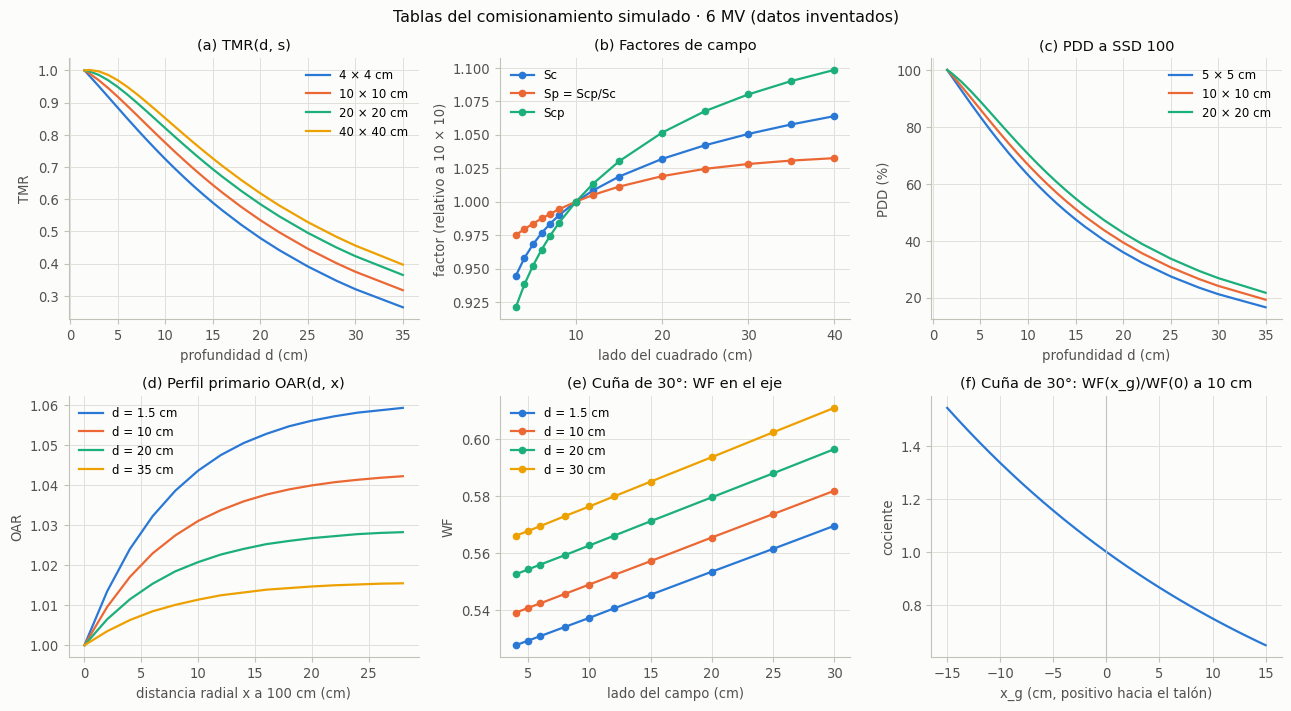

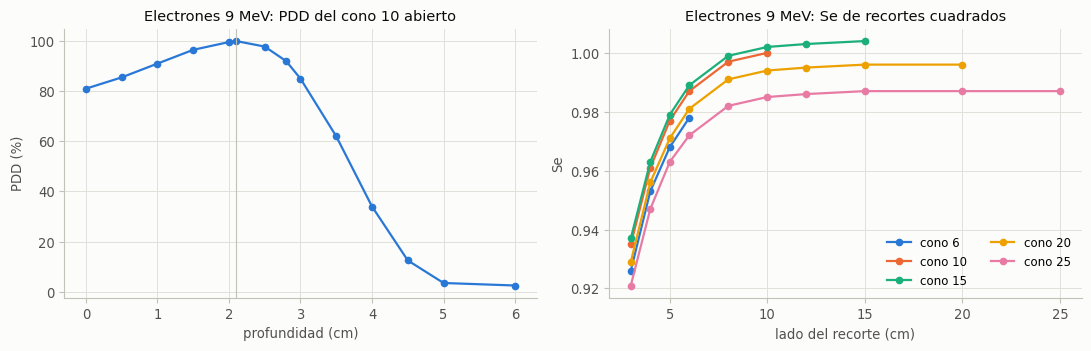

In [6]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7.2))
ax = ejes[0, 0]
for k, s in enumerate([4.0, 10.0, 20.0, 40.0]):
    ax.plot(datos.tpr.index, datos.tpr[s], color=SERIES[k], label=f"{s:g} × {s:g} cm")
ax.set(title="(a) TMR(d, s)", xlabel="profundidad d (cm)", ylabel="TMR")
ax.legend()
ax = ejes[0, 1]
for k, (nombre, serie) in enumerate([("Sc", datos.sc), ("Sp = Scp/Sc", datos.sp), ("Scp", datos.scp)]):
    ax.plot(serie.index, serie.values, "o-", color=SERIES[k], label=nombre)
ax.set(title="(b) Factores de campo", xlabel="lado del cuadrado (cm)", ylabel="factor (relativo a 10 × 10)")
ax.legend()
ax = ejes[0, 2]
for k, r in enumerate([5.0, 10.0, 20.0]):
    ax.plot(datos.pdd100.index, datos.pdd100[r], color=SERIES[k], label=f"{r:g} × {r:g} cm")
ax.set(title="(c) PDD a SSD 100", xlabel="profundidad d (cm)", ylabel="PDD (%)")
ax.legend()
ax = ejes[1, 0]
for k, d in enumerate([1.5, 10.0, 20.0, 35.0]):
    ax.plot(datos.poar.columns, datos.poar.loc[d], color=SERIES[k], label=f"d = {d:g} cm")
ax.set(title="(d) Perfil primario OAR(d, x)", xlabel="distancia radial x a 100 cm (cm)", ylabel="OAR")
ax.legend()
ax = ejes[1, 1]
for k, d in enumerate([1.5, 10.0, 20.0, 30.0]):
    ax.plot(datos.wf30.columns, datos.wf30.loc[d], "o-", color=SERIES[k], label=f"d = {d:g} cm")
ax.set(title="(e) Cuña de 30°: WF en el eje", xlabel="lado del campo (cm)", ylabel="WF")
ax.legend()
ax = ejes[1, 2]
ax.plot(datos.wf30_fuera_eje.index, datos.wf30_fuera_eje.values, color=SERIES[0])
ax.axvline(0, color=COLOR["eje"], lw=0.8)
ax.set(title="(f) Cuña de 30°: WF(x_g)/WF(0) a 10 cm", xlabel="x_g (cm, positivo hacia el talón)", ylabel="cociente")
fig.suptitle("Tablas del comisionamiento simulado · 6 MV (datos inventados)", color=COLOR["tinta"])
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = ejes[0]
ax.plot(datos_e.pdd.index, datos_e.pdd.values, "o-", color=SERIES[0])
ax.axvline(datos_e.dm, color=COLOR["eje"], lw=0.8)
ax.set(title="Electrones 9 MeV: PDD del cono 10 abierto", xlabel="profundidad (cm)", ylabel="PDD (%)")
ax = ejes[1]
for k, C in enumerate(datos_e.se.index):
    fila = datos_e.se.loc[C].dropna()
    ax.plot(fila.index, fila.values, "o-", color=SERIES[k], label=f"cono {C:g}")
ax.set(title="Electrones 9 MeV: Se de recortes cuadrados", xlabel="lado del recorte (cm)", ylabel="Se")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

## 5. Lectura de tablas

**Qué se hace.** Se definen las funciones con las que el motor lee cualquier tabla, igual que lo hará la app:

* `interp1`: interpolación lineal en una tabla de una entrada (Sc, Sp, cociente de la cuña fuera del eje).
* `interp2`: interpolación bilineal en una tabla de dos entradas (TMR, PDD, OAR, WF, SMR): lineal en las filas y luego
  en las columnas.

**Por qué así.** La TG-71 pide que el error de interpolación sea pequeño frente al 2 % de exactitud total; con tablas
bien espaciadas la interpolación lineal basta. Si un valor cae **fuera** de la tabla no se extrapola en silencio: se
usa el extremo y el cálculo lleva un aviso («Sc: 45.00 cm fuera de la tabla [3, 40]; se usó el extremo»).

**Qué mirar.** Un valor entre dos columnas, uno entre filas y columnas, y el aviso de un valor fuera de la tabla.

In [7]:
def agregar_aviso(avisos, texto):
    """Agrega un aviso a la lista una sola vez (si hay lista)."""
    if avisos is not None and texto not in avisos:
        avisos.append(texto)


def _acotar(valor, bajo, alto, nombre, eje, avisos):
    """Deja el valor dentro de la tabla; si estaba fuera, usa el extremo y avisa."""
    if valor < bajo - 1e-9 or valor > alto + 1e-9:
        agregar_aviso(avisos, f"{nombre}: {eje}{valor:.2f} cm fuera de la tabla [{bajo:g}, {alto:g}]; se usó el extremo")
        return min(max(valor, bajo), alto)
    return valor


def _posicion(valor, ejes):
    """Intervalo de la tabla que contiene el valor y fracción dentro de él."""
    i = int(np.clip(np.searchsorted(ejes, valor) - 1, 0, len(ejes) - 2))
    return i, (valor - ejes[i]) / (ejes[i + 1] - ejes[i])


def interp1(x, xs, ys, nombre="", avisos=None):
    """Interpolación lineal en una tabla de una entrada; fuera de rango usa el extremo y deja un aviso."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    x = _acotar(float(x), xs[0], xs[-1], nombre, "", avisos)
    return float(np.interp(x, xs, ys))


def interp2(tabla, fila, columna, nombre="", avisos=None):
    """Interpolación bilineal en un DataFrame (índice y columnas ascendentes), con el mismo manejo de bordes."""
    filas = tabla.index.to_numpy(dtype=float)
    cols = tabla.columns.to_numpy(dtype=float)
    v = tabla.to_numpy(dtype=float)
    f = _acotar(float(fila), filas[0], filas[-1], nombre, f"{tabla.index.name or 'fila'} = ", avisos)
    c = _acotar(float(columna), cols[0], cols[-1], nombre, f"{tabla.columns.name or 'columna'} = ", avisos)
    i, tf = _posicion(f, filas)
    j, tc = _posicion(c, cols)
    return float((1 - tf) * (1 - tc) * v[i, j] + (1 - tf) * tc * v[i, j + 1]
                 + tf * (1 - tc) * v[i + 1, j] + tf * tc * v[i + 1, j + 1])


def fila_a_profundidad(tabla, d, nombre="", avisos=None):
    """Interpola una fila completa (profundidad d) de una tabla, para leer muchas columnas de una vez."""
    filas = tabla.index.to_numpy(dtype=float)
    d = _acotar(float(d), filas[0], filas[-1], nombre, f"{tabla.index.name or 'fila'} = ", avisos)
    i, t = _posicion(d, filas)
    v = tabla.to_numpy(dtype=float)
    return (1 - t) * v[i] + t * v[i + 1]


def sc_de(datos, s, avisos=None):
    """Sc del cuadrado de lado s (cm, en el isocentro)."""
    return interp1(s, datos.sc.index, datos.sc.values, "Sc", avisos)


def sp_de(datos, s, avisos=None):
    """Sp del cuadrado de lado s (cm, en el plano del punto)."""
    return interp1(s, datos.sp.index, datos.sp.values, "Sp", avisos)


def tpr_de(datos, d, s, avisos=None):
    """TPR (o TMR) a la profundidad d (cm) del cuadrado de lado s (cm, en el plano del punto)."""
    return interp2(datos.tpr, d, s, datos.nombre_tpr, avisos)


avisos_demo = []
lados_sc, filas_t, cols_t = (datos.sc.index.to_numpy(dtype=float), datos.tpr.index.to_numpy(dtype=float),
                             datos.tpr.columns.to_numpy(dtype=float))
i_sc, i_d, j_s = _posicion(12.5, lados_sc)[0], _posicion(10.5, filas_t)[0], _posicion(11.3, cols_t)[0]   # vecinos en la tabla


def dentro_o_fuera(valor, ejes):
    """«dentro de la tabla» o «fuera de la tabla [a, b]», según el valor caiga o no entre el primero y el último."""
    return "dentro de la tabla" if ejes[0] <= valor <= ejes[-1] else f"fuera de la tabla [{ejes[0]:g}, {ejes[-1]:g}]"


print(f"Sc(12.50 cm)            = {sc_de(datos, 12.5, avisos_demo):.4f}   (entre las columnas vecinas: Sc({lados_sc[i_sc]:g})"
      f" = {datos.sc.iloc[i_sc]:.4f} y Sc({lados_sc[i_sc + 1]:g}) = {datos.sc.iloc[i_sc + 1]:.4f})")
print(f"{datos.nombre_tpr}(10.50 cm; 11.30 cm) = {tpr_de(datos, 10.5, 11.3, avisos_demo):.4f}   (bilineal entre d ="
      f" {filas_t[i_d]:g} y {filas_t[i_d + 1]:g} cm, s = {cols_t[j_s]:g} y {cols_t[j_s + 1]:g} cm)")
print(f"Sc(45.00 cm)            = {sc_de(datos, 45.0, avisos_demo):.4f}   ({dentro_o_fuera(45.0, lados_sc)})")
print(f"{datos.nombre_tpr}(36.00 cm; 10.00 cm) = {tpr_de(datos, 36.0, 10.0, avisos_demo):.4f}   ({dentro_o_fuera(36.0, filas_t)})")
print("Avisos que quedan en el cálculo:")
for a in avisos_demo:
    print("  -", a)

Sc(12.50 cm)            = 1.0101   (entre las columnas vecinas: Sc(12) = 1.0084 y Sc(15) = 1.0187)
TMR(10.50 cm; 11.30 cm) = 0.7695   (bilineal entre d = 10 y 11 cm, s = 10 y 12 cm)
Sc(45.00 cm)            = 1.0638   (fuera de la tabla [3, 40])
TMR(36.00 cm; 10.00 cm) = 0.3171   (fuera de la tabla [1.5, 35])
Avisos que quedan en el cálculo:
  - Sc: 45.00 cm fuera de la tabla [3, 40]; se usó el extremo
  - TMR: d = 36.00 cm fuera de la tabla [1.5, 35]; se usó el extremo


### 5.1 Campo cero: la primaria sola

**Qué se hace.** Clarkson separa la dosis en primaria y dispersión, y para eso necesita los valores de **campo cero**:
$S_p(0)$ y $\mathrm{TPR}(d,0)$, que no se pueden medir. Se obtienen ajustando una **parábola** (`np.polyfit`, grado 2)
a los cuatro campos más pequeños de la tabla (3, 4, 5 y 6 cm) y evaluándola en $s=0$, para Sp y para la TPR de cada
profundidad.

**Por qué una parábola y cuatro campos.** Una recta entre 3 y 4 cm sobrestima la primaria; la parábola sigue la
curvatura de los campos pequeños. Con datos medidos reales conviene revisar este ajuste (los campos de 3 cm ya
tienen falta de equilibrio lateral).

**Qué mirar.** El ajuste pasa por los puntos medidos y cae cerca del valor verdadero del modelo (que el motor no
conoce: solo se muestra para ver el error). El error es de 1 a 2 milésimas (0.1 % en Sp(0), 0.3 % en TMR(10 cm, 0)):
el redondeo de las tablas a 4 decimales se amplifica al extrapolar. En Clarkson ese error casi se cancela, porque
la misma extrapolación entra con signo contrario en la primaria y en la SMR (sección 7).

Sp(0) extrapolado = 0.9606   (verdad del modelo, solo para comparar: 0.9597)
Primaria de campo cero por profundidad (d en cm):
     TMR(d, 0) extrapolado verdad del modelo diferencia (%)
d                                                          
1.5                 1.0000            1.0000           0.00
5.0                 0.8500            0.8498          +0.02
10.0                0.6754            0.6735          +0.28
15.0                0.5350            0.5338          +0.23
20.0                0.4249            0.4231          +0.44
30.0                0.2673            0.2657          +0.59



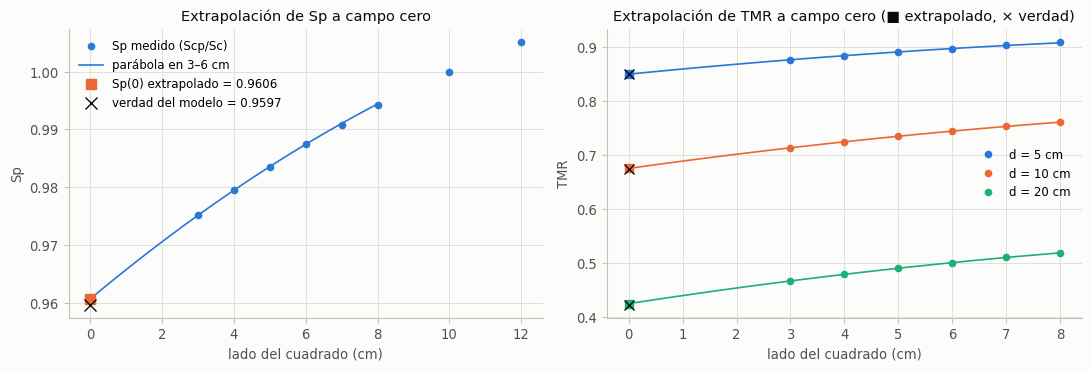

In [8]:
def extrapolar_campo_cero(datos, n_campos=4):
    """Sp(0) y TPR(d, 0): ajuste cuadrático (np.polyfit) sobre los cuatro campos más pequeños, evaluado en s = 0."""
    lados = datos.sp.index.to_numpy(dtype=float)[:n_campos]
    coef_sp = np.polyfit(lados, datos.sp.to_numpy(dtype=float)[:n_campos], 2)
    sp0 = float(np.polyval(coef_sp, 0.0))
    coef_tpr, tpr0 = {}, {}
    for d in datos.tpr.index:
        coef = np.polyfit(lados, datos.tpr.loc[d].to_numpy(dtype=float)[:n_campos], 2)
        coef_tpr[float(d)], tpr0[float(d)] = coef, float(np.polyval(coef, 0.0))
    serie = pd.Series(tpr0, name=f"{datos.nombre_tpr}(d, 0)")
    serie.index = indice(serie.index, "d")
    return sp0, serie, {"lados": lados, "sp": coef_sp, "tpr": coef_tpr}


sp0_demo, tpr0_demo, ajustes_demo = extrapolar_campo_cero(datos)
print(f"Sp(0) extrapolado = {sp0_demo:.4f}   (verdad del modelo, solo para comparar: {modelo.sp0_verdadero:.4f})")
comparacion = pd.DataFrame({"TMR(d, 0) extrapolado": tpr0_demo,
                            "verdad del modelo": [float(modelo.tmr0(d)) for d in tpr0_demo.index]})
comparacion["diferencia (%)"] = 100 * (comparacion.iloc[:, 0] / comparacion.iloc[:, 1] - 1)
imprimir_tabla_formato(comparacion.loc[[1.5, 5.0, 10.0, 15.0, 20.0, 30.0]], {"diferencia (%)": "{:+.2f}"},
                       "Primaria de campo cero por profundidad (d en cm):")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
s_fino = np.linspace(0, 8, 100)
ax = ejes[0]
lados_sp = datos.sp.index[datos.sp.index <= 12]
ax.plot(lados_sp, datos.sp.loc[lados_sp], "o", color=SERIES[0], label="Sp medido (Scp/Sc)")
ax.plot(s_fino, np.polyval(ajustes_demo["sp"], s_fino), color=SERIES[0], lw=1.2, label="parábola en 3–6 cm")
ax.plot([0], [sp0_demo], "s", color=SERIES[1], ms=7, label=f"Sp(0) extrapolado = {sp0_demo:.4f}")
ax.plot([0], [modelo.sp0_verdadero], "x", color=COLOR["tinta"], ms=8, label=f"verdad del modelo = {modelo.sp0_verdadero:.4f}")
ax.set(title="Extrapolación de Sp a campo cero", xlabel="lado del cuadrado (cm)", ylabel="Sp")
ax.legend()
ax = ejes[1]
for k, d in enumerate([5.0, 10.0, 20.0]):
    ax.plot(datos.tpr.columns[:6], datos.tpr.loc[d].iloc[:6], "o", color=SERIES[k], label=f"d = {d:g} cm")
    ax.plot(s_fino, np.polyval(ajustes_demo["tpr"][d], s_fino), color=SERIES[k], lw=1.2)
    ax.plot([0], [tpr0_demo[d]], "s", color=SERIES[k], ms=6)
    ax.plot([0], [float(modelo.tmr0(d))], "x", color=COLOR["tinta"], ms=7)
ax.set(title="Extrapolación de TMR a campo cero (■ extrapolado, × verdad)", xlabel="lado del cuadrado (cm)", ylabel="TMR")
ax.legend()
fig.tight_layout()
plt.show()

### 5.2 La tabla de dispersión (SMR) y los derivados al cargar

**Qué se hace.** Con el campo cero se construye la tabla de **dispersión por unidad de dosis de referencia**:

$$\mathrm{SMR}(d,s)=\mathrm{TMR}(d,s)\,\frac{S_p(s)}{S_p(0)}-\mathrm{TMR}(d,0),\qquad \mathrm{SMR}(d,0)=0$$

**El nombre.** Con tablas TMR ($d_0 = d_{max}$, como aquí) es la *scatter-maximum ratio*, SMR, de Khan, y así se
rotula en todo el cuaderno. Con tablas TPR ($d_0$ = 10 cm, sección 5.3) la misma construcción se llama SPR
(*scatter-phantom ratio*), y el motor la rotula así cuando los datos son TPR. **No es** el cociente dispersión/primaria
(S/P) de Bjärngard: para 10 × 10 a 10 cm, SMR = 0.132, mientras que S/P sería 0.132/0.675 ≈ 0.195.

Así, para cualquier campo, $S_p(s)\,\mathrm{TMR}(d,s)=S_p(0)\,[\mathrm{TMR}(d,0)+\mathrm{SMR}(d,s)]$: primaria más
dispersión. Clarkson necesita la dispersión de **círculos** de radio $\rho$; se toma el cuadrado de igual área,
$s=\rho\sqrt{\pi}$, y se interpola en la tabla: $\mathrm{SMR}_{círculo}(d,\rho)\approx\mathrm{SMR}(d,\rho\sqrt{\pi})$
(si $s$ pasa de 40 cm se usa 40 y se avisa una vez por cálculo).

`preparar_datos` es lo que la app hará al cargar los datos de un haz: campo cero, tabla de SMR y tablas extendidas a
$s=0$ (estas solo sirven para buscar cuadrados equivalentes).

**Qué mirar.** En el gráfico, la SMR de la tabla (línea continua) y la dispersión verdadera de un círculo (línea
punteada, del núcleo del modelo) quedan cerca, pero la de la tabla va algo por debajo. Hay tres causas, todas del
método y no errores del motor: (1) el cuadrado de igual área dispersa un poco menos que el círculo (sus esquinas están
más lejos del punto); (2) la interpolación lineal entre columnas de una curva cóncava queda por debajo de la curva; y
(3) el error de la extrapolación a campo cero (sección 5.1). La tercera es cerca de la mitad de la separación que se
ve aquí, pero en Clarkson se cancela con la primaria (sección 7). Las dos primeras quedan: por eso Clarkson da, en
cuadrados centrados, entre 0.05 y 0.3 % menos que $S_p\cdot\mathrm{TMR}$ leído en la tabla (prueba 2 de la sección 13),
más cuanto mayores son el campo y la profundidad.

Al cargar: Sp(0) = 0.9606; TMR(d, 0) para 23 profundidades; tabla de SMR de 23 × 15 (con la columna s = 0)

SMR(d, s) (filas: d en cm; columnas: lado s en cm), extracto:
s      0.0    3.0    5.0    10.0   15.0   20.0   30.0   40.0
d                                                           
1.5  0.0000 0.0151 0.0239 0.0410 0.0526 0.0607 0.0702 0.0747
5.0  0.0000 0.0399 0.0624 0.1059 0.1357 0.1564 0.1803 0.1919
10.0 0.0000 0.0489 0.0770 0.1318 0.1692 0.1952 0.2253 0.2397
15.0 0.0000 0.0508 0.0797 0.1356 0.1739 0.2004 0.2312 0.2460
20.0 0.0000 0.0490 0.0772 0.1318 0.1693 0.1951 0.2253 0.2396
30.0 0.0000 0.0457 0.0719 0.1225 0.1573 0.1813 0.2093 0.2226

Con 10 × 10 a 10 cm: SMR = 0.1318; el cociente dispersión/primaria sería 0.1318/0.6754 = 0.195 (otra magnitud)



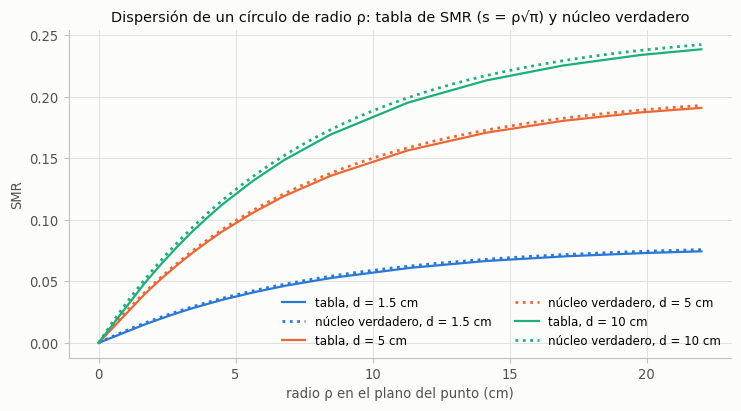

In [9]:
def nombre_dispersion(datos):
    """Nombre de la tabla de dispersión: «SMR» con tablas TMR (d0 = dmax, como Khan) y «SPR» con tablas TPR."""
    return "SMR" if datos.nombre_tpr == "TMR" else "SPR"


def tabla_spr(datos):
    """Tabla de dispersión SMR o SPR(d, s) = TPR(d, s)·Sp(s)/Sp(0) − TPR(d, 0), con la columna s = 0 igual a 0."""
    spr = datos.tpr.mul(datos.sp / datos.sp0, axis=1).sub(datos.tpr0, axis=0)
    spr.insert(0, 0.0, 0.0)
    spr.columns = indice(spr.columns, "s")
    return spr


def preparar_datos(datos):
    """Derivados que el motor calcula al cargar: Sp(0), TPR(d, 0), la tabla de dispersión y tablas extendidas a s = 0."""
    datos.sp0, datos.tpr0, datos.ajustes_cero = extrapolar_campo_cero(datos)
    datos.spr = tabla_spr(datos)
    sp_ext = pd.concat([pd.Series([datos.sp0], index=[0.0]), datos.sp])
    sp_ext.index = indice(sp_ext.index, "s")
    datos.sp_ext = sp_ext
    tpr_ext = datos.tpr.copy()
    tpr_ext.insert(0, 0.0, datos.tpr0.to_numpy())
    tpr_ext.columns = indice(tpr_ext.columns, "s")
    datos.tpr_ext = tpr_ext
    return datos


def tpr0_de(datos, d, avisos=None):
    """TPR de campo cero (primaria) a la profundidad d."""
    return interp1(d, datos.tpr0.index, datos.tpr0.values, f"{datos.nombre_tpr}(d, 0)", avisos)


def spr_de(datos, d, s, avisos=None):
    """Dispersión SMR o SPR(d, s) del cuadrado de lado s (cm, plano del punto)."""
    return interp2(datos.spr, d, s, nombre_dispersion(datos), avisos)


def spr_de_radio(datos, d, rho, avisos=None):
    """Dispersión de un sector de radio ρ (cm, plano del punto): cuadrado de igual área s = ρ·√π (acepta varios radios)."""
    s = np.asarray(rho, dtype=float) * math.sqrt(math.pi)
    lados = datos.spr.columns.to_numpy(dtype=float)
    if np.any(s > lados[-1] + 1e-9):
        agregar_aviso(avisos, f"radios mayores que la tabla: se usó {lados[-1]:g} × {lados[-1]:g}")
    fila = fila_a_profundidad(datos.spr, d, nombre_dispersion(datos), avisos)
    return np.interp(np.minimum(s, lados[-1]), lados, fila)


preparar_datos(datos)
DISP = nombre_dispersion(datos)
print(f"Al cargar: Sp(0) = {datos.sp0:.4f}; {datos.nombre_tpr}(d, 0) para {plural(len(datos.tpr0), 'profundidad', 'profundidades')};"
      f" tabla de {DISP} de {datos.spr.shape[0]} × {datos.spr.shape[1]} (con la columna s = 0)\n")
imprimir_tabla(datos.spr.loc[[1.5, 5.0, 10.0, 15.0, 20.0, 30.0], [0.0, 3.0, 5.0, 10.0, 15.0, 20.0, 30.0, 40.0]],
               f"{DISP}(d, s) (filas: d en cm; columnas: lado s en cm), extracto:")
print(f"Con 10 × 10 a 10 cm: {DISP} = {spr_de(datos, 10.0, 10.0):.4f}; el cociente dispersión/primaria sería"
      f" {spr_de(datos, 10.0, 10.0):.4f}/{tpr0_de(datos, 10.0):.4f} = {spr_de(datos, 10.0, 10.0) / tpr0_de(datos, 10.0):.3f}"
      " (otra magnitud)\n")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
radios = np.linspace(0, 22, 200)
for k, d in enumerate([1.5, 5.0, 10.0]):
    ax.plot(radios, spr_de_radio(datos, d, radios), color=SERIES[k], label=f"tabla, d = {d:g} cm")
    ax.plot(radios, modelo.smr_circ(d, radios), ":", color=SERIES[k], lw=2.0, label=f"núcleo verdadero, d = {d:g} cm")
ax.set(title=f"Dispersión de un círculo de radio ρ: tabla de {DISP} (s = ρ√π) y núcleo verdadero",
       xlabel="radio ρ en el plano del punto (cm)", ylabel=DISP)
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

### 5.3 Cambio de profundidad de normalización ($d_0$ = 10 cm)

**Qué se hace.** La TG-71 recomienda normalizar a $d_0$ = 10 cm (sección 1 del reporte; véanse también 3.B.1.a y la
tabla I). `renormalizar` pasa las tablas de $d_0 = d_{max}$ a $d_0$ = 10 cm sin cambiar la física del haz (con estos
datos la tabla de dispersión pasa a llamarse SPR):

$$\mathrm{TPR}_{10}(d,s)=\frac{\mathrm{TMR}(d,s)}{\mathrm{TMR}(10,s)},\quad S_{p,10}(s)=S_p(s)\,\frac{\mathrm{TMR}(10,s)}{\mathrm{TMR}(10,10)},\quad D'_{0,10}=D'_0\,\mathrm{TMR}(10,10),\quad SSD_{0,10}=90\ \mathrm{cm}$$

y se rehace la extrapolación a campo cero. **Qué mirar.** $D'_{0,10} = D'_0\,\mathrm{TMR}(10,10)$ ≈ 0.775 cGy/UM. En la
tabla I de la TG-71 un 6 MV calibrado a SSD 100 en $d_{max}$ da 0.810 cGy/UM: 0.786 de TMR(10, 10 × 10) de la BJR 25
por el inverso del cuadrado $(101.5/100)^2$; aquí la calibración ya es con el punto a 100 cm, así que ese factor no
aparece. La prueba 5 de la sección 13 comprueba que las UM no cambian.

In [10]:
def renormalizar(datos, d0_nuevo=10.0):
    """Pasa los datos a otra profundidad de normalización (TG-71: d0 = 10 cm) sin cambiar la física del haz."""
    tmr_d0 = datos.tpr.loc[d0_nuevo]
    ref = float(tmr_d0.loc[10.0])
    sp_n = (datos.sp * tmr_d0 / ref).rename("Sp")
    nuevo = DatosHaz(
        energia=datos.energia, SAD=datos.SAD, d0=d0_nuevo, SSD0=datos.SSD0 + datos.d0 - d0_nuevo,
        D0p=datos.D0p * ref, nombre_tpr="TPR", campos=datos.campos, profundidades=datos.profundidades,
        sc=datos.sc, sc_matriz=datos.sc_matriz, scp=(datos.sc * sp_n).rename("Scp"), sp=sp_n,
        tpr=datos.tpr.div(tmr_d0, axis=1), pdd100=100 * datos.pdd100.div(datos.pdd100.loc[d0_nuevo], axis=1),
        poar=datos.poar, wf30=datos.wf30, wf30_fuera_eje=datos.wf30_fuera_eje, TF=datos.TF, t_mlc=datos.t_mlc,
        t_bloque=datos.t_bloque, dist_mand_sup=datos.dist_mand_sup, dist_mand_inf=datos.dist_mand_inf,
        limites_mlc=datos.limites_mlc, ssd_pdd=datos.ssd_pdd)
    return preparar_datos(nuevo)


datos10 = renormalizar(datos, 10.0)
print(f"Normalización a d0 = {datos10.d0:.2f} cm: D'0 = {datos10.D0p:.4f} cGy/UM, SSD0 = {datos10.SSD0:.2f} cm,"
      f" Sp(0) = {datos10.sp0:.4f}")
imprimir_tabla(pd.DataFrame({"Sp (d0 = 1.5 cm)": datos.sp, "Sp (d0 = 10 cm)": datos10.sp}).T,
               "Sp con las dos normalizaciones (columnas: lado en cm):")
imprimir_tabla(datos10.tpr.loc[[1.5, 5.0, 10.0, 15.0, 20.0], [5.0, 10.0, 20.0]],
               "TPR con d0 = 10 cm (filas: d en cm; columnas: lado en cm), extracto:")

Normalización a d0 = 10.00 cm: D'0 = 0.7754 cGy/UM, SSD0 = 90.00 cm, Sp(0) = 0.8364
Sp con las dos normalizaciones (columnas: lado en cm):
s                  3.0    4.0    5.0    6.0    7.0    8.0    10.0   12.0   15.0   20.0   25.0   30.0   35.0   40.0
Sp (d0 = 1.5 cm) 0.9751 0.9794 0.9836 0.9874 0.9908 0.9942 1.0000 1.0051 1.0112 1.0190 1.0245 1.0281 1.0306 1.0324
Sp (d0 = 10 cm)  0.8973 0.9153 0.9322 0.9479 0.9624 0.9760 1.0000 1.0207 1.0464 1.0785 1.1007 1.1159 1.1265 1.1338

TPR con d0 = 10 cm (filas: d en cm; columnas: lado en cm), extracto:
s      5.0    10.0   20.0
d                        
1.5  1.3607 1.2897 1.2185
5.0  1.2125 1.1842 1.1560
10.0 1.0000 1.0000 1.0000
15.0 0.8170 0.8308 0.8448
20.0 0.6673 0.6897 0.7122



## 6. Del plan al campo

**Qué se hace.** El motor recibe el plan como lo entregará el RTPLAN de DICOM. Aquí el plan es un diccionario con los
mismos nombres de atributos y las mismas unidades (mm y grados; Gy para la dosis), para que después se lea igual con
`pydicom`. De dónde sale cada dato en un RTPLAN real:

| Dato del diccionario | En el RTPLAN real |
|---|---|
| `PatientID`, `PatientPosition` | Módulo del paciente; `PatientSetupSequence → PatientPosition` (HFS, FFS, HFP…) |
| `RTPlanLabel`, `NumberOfFractionsPlanned` | Módulo RT General Plan; `FractionGroupSequence` |
| `BeamNumber`, `BeamName`, `RadiationType`, `TreatmentMachineName` | `BeamSequence` |
| `GantryAngle`, `BeamLimitingDeviceAngle`, `PatientSupportAngle`, `IsocenterPosition`, `NominalBeamEnergy`, `SourceToSurfaceDistance` | `BeamSequence → ControlPointSequence[0]` |
| `ASYMX`, `ASYMY`, `MLCX` (cada uno con sus `LeafJawPositions`) | `ControlPointSequence[0] → BeamLimitingDevicePositionSequence`, uno por `RTBeamLimitingDeviceType` |
| `LeafPositionBoundaries` | `BeamSequence → BeamLimitingDeviceSequence` (el del MLCX) |
| `Wedge` | `BeamSequence → WedgeSequence` (`WedgeID`, `WedgeAngle`, `WedgeOrientation`). La orientación DICOM viene en grados y hay que traducirla a «dirección del talón» |
| `BlockTray`, `Blocks` (`BlockData` en mm, plano del isocentro) | `BeamSequence → BlockSequence` (`BlockTrayID`, `BlockType`, `BlockData`, `BlockTransmission`) |
| `ApplicatorSequence` (electrones: `ApplicatorID`, `ApplicatorType`) | `BeamSequence → ApplicatorSequence`: el cono; su lado sale de la configuración de la máquina (`ApplicatorID` → lado) |
| `Blocks` con `BlockType` = `"APERTURE"` (electrones) | `BeamSequence → BlockSequence` de tipo APERTURE: el recorte de cerrobend del cono, con su contorno en `BlockData` |
| `BeamMeterset`, `BeamDose` | `FractionGroupSequence → ReferencedBeamSequence` (UM, y Gy en el punto de dosis del haz) |
| `PuntoReferencia` | `DoseReferenceSequence → DoseReferencePointCoordinates`, o `ReferencedBeamSequence → BeamDoseSpecificationPoint` |

Las láminas se describen con una función `bordes(y_centro)` que da los dos bordes del par (en cm) o `None` si el par
está cerrado; `laminas_desde_forma` la convierte en el vector `MLCX` de 120 valores en mm: los 60 del lado X1 y luego
los 60 del lado X2, de y menor a y mayor, como `LeafJawPositions` en DICOM. «Láminas abiertas» quiere decir todos los
pares retirados 5 mm detrás de las mandíbulas. `nuevo_haz_electrones` arma un haz de electrones con su cono y su
recorte, y `plan_de_prueba` un plan de un haz con la dosis puesta a mano (sin UM ni SSD del planeador), para pruebas.

**Qué mirar.** El haz de ejemplo con sus nombres DICOM y el vector de láminas resumido, y un haz de electrones.

In [11]:
LIMITES = limites_millennium120()


def nuevo_haz(numero, nombre, brazo, asymx_mm, asymy_mm, mlcx_mm=None, colimador=0.0, camilla=0.0,
              isocentro_mm=(0.0, 0.0, 0.0), cuna=None, bandeja=False, bloques=None, limites_cm=None):
    """Un haz de fotones con nombres de atributos DICOM (mm y grados), como se leerá del RTPLAN."""
    limites_cm = LIMITES if limites_cm is None else np.asarray(limites_cm, dtype=float)
    return {
        "BeamNumber": int(numero), "BeamName": nombre, "RadiationType": "PHOTON", "NominalBeamEnergy": 6.0,
        "GantryAngle": float(brazo), "BeamLimitingDeviceAngle": float(colimador), "PatientSupportAngle": float(camilla),
        "IsocenterPosition": [float(v) for v in isocentro_mm],
        "ASYMX": [float(v) for v in asymx_mm], "ASYMY": [float(v) for v in asymy_mm],
        "MLCX": None if mlcx_mm is None else [float(v) for v in mlcx_mm],
        "LeafPositionBoundaries": [float(round(10.0 * float(v), 3)) for v in limites_cm],
        "Wedge": cuna, "BlockTray": bool(bandeja), "Blocks": list(bloques or []),
        "SourceToSurfaceDistance": None, "BeamMeterset": None, "BeamDose": None,
    }


def nuevo_haz_electrones(numero, nombre, aplicador_id, recorte_mm=None, energia=9.0, brazo=0.0,
                         isocentro_mm=(0.0, 0.0, 0.0), tipo_aplicador="ELECTRON_SQUARE"):
    """Un haz de electrones con nombres DICOM: el cono en ApplicatorSequence y el recorte como bloque APERTURE (mm)."""
    bloques = [] if recorte_mm is None else [{"BlockName": "recorte", "BlockType": "APERTURE", "MaterialID": "cerrobend",
                                              "BlockData": [[float(x), float(y)] for x, y in recorte_mm]}]
    return {
        "BeamNumber": int(numero), "BeamName": nombre, "RadiationType": "ELECTRON", "NominalBeamEnergy": float(energia),
        "GantryAngle": float(brazo), "BeamLimitingDeviceAngle": 0.0, "PatientSupportAngle": 0.0,
        "IsocenterPosition": [float(v) for v in isocentro_mm],
        "ApplicatorSequence": [{"ApplicatorID": aplicador_id, "ApplicatorType": tipo_aplicador}],
        "Blocks": bloques, "SourceToSurfaceDistance": None, "BeamMeterset": None, "BeamDose": None,
    }


def rectangulo_mm(X_cm, Y_cm, cx_cm=0.0, cy_cm=0.0):
    """Contorno (mm) de un rectángulo X × Y cm centrado en (cx, cy) cm, para BlockData."""
    x0, x1 = 10.0 * (cx_cm - X_cm / 2), 10.0 * (cx_cm + X_cm / 2)
    y0, y1 = 10.0 * (cy_cm - Y_cm / 2), 10.0 * (cy_cm + Y_cm / 2)
    return [[x0, y0], [x1, y0], [x1, y1], [x0, y1]]


def nuevo_plan(etiqueta, haces, punto_mm=(0.0, 0.0, 0.0), nombre_punto="Isocentro", fracciones=25):
    """Un plan tipo RTPLAN: paciente, posición, equipo, punto de referencia y haces."""
    return {"PatientID": "SIM-0001", "RTPlanLabel": etiqueta, "PatientPosition": "HFS",
            "TreatmentMachineName": "Clinac simulado", "NumberOfFractionsPlanned": int(fracciones),
            "PuntoReferencia": {"Nombre": nombre_punto, "Coordenadas_mm": [float(v) for v in punto_mm]},
            "Beams": haces}


def plan_de_prueba(etiqueta, haz, punto_mm, dosis_Gy=2.0):
    """Plan de un haz para pruebas: copia del haz con BeamDose puesto a mano, sin UM ni SSD del planeador."""
    haz = dict(haz, BeamDose=float(dosis_Gy), BeamMeterset=None, SourceToSurfaceDistance=None)
    return nuevo_plan(etiqueta, [haz], punto_mm=punto_mm), haz


def laminas_desde_forma(limites_cm, bordes):
    """Vector MLCX (mm) para una forma: bordes(y_centro) → (xL, xR) en cm, o None si el par está cerrado.

    Devuelve 120 valores: los 60 del lado X1 (negativo) y luego los 60 del lado X2, de y menor a y mayor.
    Un par cerrado lleva sus dos láminas en 0.0.
    """
    lado_x1, lado_x2 = [], []
    for k in range(len(limites_cm) - 1):
        par = bordes(0.5 * (limites_cm[k] + limites_cm[k + 1]))
        xl, xr = (0.0, 0.0) if par is None else par
        lado_x1.append(float(round(10.0 * float(xl), 3)))
        lado_x2.append(float(round(10.0 * float(xr), 3)))
    return lado_x1 + lado_x2


def forma_abierta(x1_cm, x2_cm, margen_cm=0.5):
    """Láminas «abiertas»: cada par retirado 5 mm detrás de las mandíbulas X."""
    return lambda y_centro: (x1_cm - margen_cm, x2_cm + margen_cm)


def resumen_lista(valores, n=3):
    """Texto corto para listas largas: los primeros y los últimos valores."""
    if len(valores) <= 2 * n:
        return str(list(valores))
    cabeza = ", ".join(f"{v:g}" for v in valores[:n])
    cola = ", ".join(f"{v:g}" for v in valores[-n:])
    return f"[{cabeza}, …, {cola}] ({plural(len(valores), 'valor', 'valores')})"


def mostrar_haz(haz):
    """Imprime un haz con sus nombres DICOM, resumiendo las listas largas."""
    for clave, valor in haz.items():
        largo = isinstance(valor, list) and len(valor) > 6 and all(isinstance(v, (int, float)) for v in valor)
        print(f"  {clave:<26} {resumen_lista(valor) if largo else repr(valor)}")


haz_ejemplo = nuevo_haz(1, "AP", 0.0, [-50, 50], [-75, 75], laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)))
plan_ejemplo = nuevo_plan("Ejemplo", [haz_ejemplo])
print("Plan (sin los haces):")
for clave, valor in plan_ejemplo.items():
    if clave != "Beams":
        print(f"  {clave:<26} {valor!r}")
print("Haz 1:")
mostrar_haz(haz_ejemplo)
print("Un haz de electrones (cono de 15 × 15 cm con recorte de 6 × 10 cm):")
mostrar_haz(nuevo_haz_electrones(1, "e⁻ 9 MeV", "A15", rectangulo_mm(6.0, 10.0)))

Plan (sin los haces):
  PatientID                  'SIM-0001'
  RTPlanLabel                'Ejemplo'
  PatientPosition            'HFS'
  TreatmentMachineName       'Clinac simulado'
  NumberOfFractionsPlanned   25
  PuntoReferencia            {'Nombre': 'Isocentro', 'Coordenadas_mm': [0.0, 0.0, 0.0]}
Haz 1:
  BeamNumber                 1
  BeamName                   'AP'
  RadiationType              'PHOTON'
  NominalBeamEnergy          6.0
  GantryAngle                0.0
  BeamLimitingDeviceAngle    0.0
  PatientSupportAngle        0.0
  IsocenterPosition          [0.0, 0.0, 0.0]
  ASYMX                      [-50.0, 50.0]
  ASYMY                      [-75.0, 75.0]
  MLCX                       [-55, -55, -55, …, 55, 55, 55] (120 valores)
  LeafPositionBoundaries     [-200, -190, -180, …, 180, 190, 200] (61 valores)
  Wedge                      None
  BlockTray                  False
  Blocks                     []
  SourceToSurfaceDistance    None
  BeamMeterset               None
  

### 6.1 La abertura: mandíbulas, láminas y bloques, y los rayos que la recorren

**Qué se hace.** `abertura_desde_haz` lee `ASYMX`, `ASYMY`, `MLCX`, `LeafPositionBoundaries` y `Blocks` (mm) y arma la
abertura en cm en el plano del isocentro: el rectángulo de las mandíbulas, una **franja** abierta por cada par de
láminas (recortada por las mandíbulas; las vacías se descartan) y los bloques como polígonos.

Sobre esa abertura se trazan rayos desde el punto $p$ en la dirección $u$: $p + t\,u$ con $t \ge 0$.
* Rectángulos (franjas y mandíbulas): **método de las losas** (intervalo en x ∩ intervalo en y).
* Polígonos (bloques): cruces con las aristas y **regla par-impar**.
* `segmentos_rayo` parte el rayo, hasta que sale de las mandíbulas, en tramos **abierto** (dentro de una franja y fuera
  de bloques), **bloque** (bajo un bloque) y **mlc** (dentro de las mandíbulas pero bajo las láminas). Fuera de las
  mandíbulas no hay tramos.

El área y el perímetro salen del **borde exacto** de la zona abierta (`borde_abertura`): se toman las aristas de las
franjas y de los bloques, se juntan las que caen sobre la misma recta, se parten donde las cruza otra arista y se
conserva cada pedazo que tiene zona abierta a un solo lado. Así quedan los bordes de franja no compartidos con otra
franja ni tapados por un bloque, y las aristas de los bloques que caen dentro de la zona abierta. El perímetro es la
suma de los largos (exacto también con bordes oblicuos o curvos, como los de un bloque de cerrobend) y el área sale
del mismo contorno (fórmula del área de Gauss). Con eso, $s = 4A/P$ (Sterling) y, para un rectángulo,
$s = 2XY/(X+Y)$ (ecuación 4). El mismo contorno da la **distancia del punto al borde** más cercano (distancia
euclídea a la zona cerrada), que decide el aviso de «menos de 2 cm del borde».

Contar celdas de una rejilla, en cambio, da el perímetro «en escalera»: con un borde a 45° sale √2 veces mayor (+41 %)
por fino que sea el paso, y 4A/P un 29 % menor.

**Qué mirar.** Un campo en L como el del caso 2 (esta demostración y la sección 7.1 tienen su propia copia; el caso 2
arma la suya en su celda, para cambiarla allí): 140 cm², 56 cm de perímetro y 4A/P = 10.0 cm; los tramos de tres rayos; y una
abertura en rombo (cuadrado de 14.14 cm girado 45°, perímetro exacto 56.57 cm).

In [12]:
@dataclass
class Abertura:
    """El campo en el plano del isocentro (cm): mandíbulas, franjas abiertas entre láminas y bloques."""
    mandibulas: Tuple[float, float, float, float]                 # x1, x2, y1, y2
    franjas: List[Tuple[float, float, float, float]]              # (x0, x1, y0, y1) por par de láminas
    bloques: List[np.ndarray] = field(default_factory=list)       # polígonos N × 2
    bandeja: bool = False
    laminas: Optional[Tuple[np.ndarray, np.ndarray, np.ndarray]] = None   # (límites, X1, X2), solo para dibujar


def abertura_desde_haz(haz, datos=None):
    """Abertura (cm, plano del isocentro) desde ASYMX, ASYMY, MLCX, LeafPositionBoundaries y Blocks del haz (mm)."""
    x1, x2 = (v / 10.0 for v in haz["ASYMX"])
    y1, y2 = (v / 10.0 for v in haz["ASYMY"])
    bloques = [np.asarray(b["BlockData"], dtype=float) / 10.0 for b in haz.get("Blocks", [])]
    bandeja = bool(haz.get("BlockTray"))
    if haz.get("MLCX") is None:
        return Abertura((x1, x2, y1, y2), [(x1, x2, y1, y2)], bloques, bandeja)
    if haz.get("LeafPositionBoundaries") is not None:
        limites = np.asarray(haz["LeafPositionBoundaries"], dtype=float) / 10.0
    else:
        limites = np.asarray(datos.limites_mlc, dtype=float)
    mlc = np.asarray(haz["MLCX"], dtype=float) / 10.0
    n = len(limites) - 1
    if len(mlc) != 2 * n:
        raise ValueError(f"MLCX tiene {plural(len(mlc), 'valor', 'valores')}; se esperaban {2 * n}")
    izq, der = mlc[:n], mlc[n:]
    franjas = []
    for k in range(n):
        xa, xb = max(izq[k], x1), min(der[k], x2)
        ya, yb = max(limites[k], y1), min(limites[k + 1], y2)
        if xb - xa > 1e-9 and yb - ya > 1e-9:
            franjas.append((xa, xb, ya, yb))
    return Abertura((x1, x2, y1, y2), franjas, bloques, bandeja, (limites, izq, der))


def abertura_rectangular(X, Y, cx=0.0, cy=0.0):
    """Abertura rectangular X × Y (cm) sin láminas ni bloques (para pruebas)."""
    r = (cx - X / 2, cx + X / 2, cy - Y / 2, cy + Y / 2)
    return Abertura(r, [r])


def intervalo_rayo_rectangulo(p, u, rect):
    """Tramo [t0, t1] (t ≥ 0) del rayo p + t·u dentro del rectángulo (x0, x1, y0, y1): método de las losas."""
    t0, t1 = 0.0, math.inf
    for pc, uc, lo, hi in ((p[0], u[0], rect[0], rect[1]), (p[1], u[1], rect[2], rect[3])):
        if abs(uc) < 1e-12:
            if pc < lo - 1e-12 or pc > hi + 1e-12:
                return None
            continue
        ta, tb = (lo - pc) / uc, (hi - pc) / uc
        if ta > tb:
            ta, tb = tb, ta
        t0, t1 = max(t0, ta), min(t1, tb)
    return (t0, t1) if t1 - t0 > 1e-12 else None


def intervalos_rayo_poligono(p, u, poligono):
    """Tramos (t ≥ 0) del rayo dentro de un polígono: cruces con las aristas y regla par-impar."""
    px, py = p
    ux, uy = u
    cruces = []
    n = len(poligono)
    for k in range(n):
        (ax_, ay_), (bx_, by_) = poligono[k], poligono[(k + 1) % n]
        da = ux * (ay_ - py) - uy * (ax_ - px)       # lado de cada vértice respecto de la recta del rayo
        db = ux * (by_ - py) - uy * (bx_ - px)
        if (da > 0) == (db > 0):
            continue
        f = da / (da - db)
        t = (ax_ + f * (bx_ - ax_) - px) * ux + (ay_ + f * (by_ - ay_) - py) * uy
        if t > 1e-12:
            cruces.append(t)
    cruces.sort()
    if len(cruces) % 2 == 1:        # número impar de cruces por delante: el punto está dentro
        cruces = [0.0] + cruces
    return [(cruces[i], cruces[i + 1]) for i in range(0, len(cruces) - 1, 2) if cruces[i + 1] - cruces[i] > 1e-12]


def unir_intervalos(intervalos):
    """Une intervalos que se tocan o se solapan."""
    unidos = []
    for a, b in sorted(intervalos):
        if unidos and a <= unidos[-1][1] + 1e-9:
            unidos[-1] = (unidos[-1][0], max(unidos[-1][1], b))
        else:
            unidos.append((a, b))
    return unidos


def intersecar_intervalos(A, B):
    """Intersección de dos listas de intervalos."""
    salida = []
    for a0, a1 in A:
        for b0, b1 in B:
            lo, hi = max(a0, b0), min(a1, b1)
            if hi - lo > 1e-9:
                salida.append((lo, hi))
    return unir_intervalos(salida)


def restar_intervalos(A, B):
    """A − B para listas de intervalos."""
    salida = []
    for a0, a1 in A:
        piezas = [(a0, a1)]
        for b0, b1 in B:
            nuevas = []
            for x0, x1 in piezas:
                if b1 <= x0 or b0 >= x1:
                    nuevas.append((x0, x1))
                    continue
                if b0 > x0:
                    nuevas.append((x0, b0))
                if b1 < x1:
                    nuevas.append((b1, x1))
            piezas = nuevas
        salida.extend(piezas)
    return [(x0, x1) for x0, x1 in salida if x1 - x0 > 1e-9]


def segmentos_rayo(abertura, p, u):
    """Parte el rayo (hasta su salida de las mandíbulas) en tramos «abierto», «bloque» y «mlc»."""
    J = intervalo_rayo_rectangulo(p, u, abertura.mandibulas)
    if J is None:
        return []
    franjas = [i for i in (intervalo_rayo_rectangulo(p, u, f) for f in abertura.franjas) if i is not None]
    bloques = [i for pol in abertura.bloques for i in intervalos_rayo_poligono(p, u, pol)]
    bloqueado = intersecar_intervalos(unir_intervalos(bloques), [J])
    abierto = restar_intervalos(intersecar_intervalos(unir_intervalos(franjas), [J]), bloqueado)
    laminas = restar_intervalos(restar_intervalos([J], abierto), bloqueado)
    tramos = [(a, b, "abierto") for a, b in abierto] + [(a, b, "bloque") for a, b in bloqueado]
    tramos += [(a, b, "mlc") for a, b in laminas]
    return sorted(tramos)


def puntos_en_poligono(X, Y, poligono):
    """Regla par-impar (rayo horizontal) para muchos puntos a la vez."""
    X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float)
    dentro = np.zeros(X.shape, dtype=bool)
    n = len(poligono)
    for k in range(n):
        (xa, ya), (xb, yb) = poligono[k], poligono[(k + 1) % n]
        cruza = (ya > Y) != (yb > Y)
        with np.errstate(divide="ignore", invalid="ignore"):
            x_cruce = xa + (Y - ya) * (xb - xa) / (yb - ya)
        dentro ^= cruza & (X < x_cruce)
    return dentro


def estado_punto(abertura, p):
    """«abierto», «mlc» (bajo las láminas), «bloque» o «fuera» (fuera de las mandíbulas)."""
    x, y = p
    x1, x2, y1, y2 = abertura.mandibulas
    tol = 1e-9
    if not (x1 - tol <= x <= x2 + tol and y1 - tol <= y <= y2 + tol):
        return "fuera"
    if any(bool(puntos_en_poligono([x], [y], pol)[0]) for pol in abertura.bloques):
        return "bloque"
    if any(a - tol <= x <= b + tol and c - tol <= y <= e + tol for a, b, c, e in abertura.franjas):
        return "abierto"
    return "mlc"


def puntos_abiertos(abertura, X, Y):
    """True donde el punto (cm, plano del isocentro) está dentro de una franja abierta y fuera de todo bloque."""
    X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float)
    abierto = np.zeros(X.shape, dtype=bool)
    for xa, xb, ya, yb in abertura.franjas:
        abierto |= (X > xa) & (X < xb) & (Y > ya) & (Y < yb)
    for pol in abertura.bloques:
        abierto &= ~puntos_en_poligono(X, Y, pol)
    return abierto


def borde_abertura(abertura, eps=1e-6):
    """Borde exacto de la zona abierta (cm, plano del isocentro): pedazos (x0, y0, x1, y1) con lo abierto a la izquierda.

    Junta las aristas de franjas y bloques que caen sobre la misma recta, las parte en cada cruce con otra arista y
    conserva cada pedazo que tiene zona abierta a un solo lado (se mira a ±eps de su punto medio).
    """
    aristas = []
    for xa, xb, ya, yb in abertura.franjas:
        aristas += [(xa, ya, xb, ya), (xb, ya, xb, yb), (xb, yb, xa, yb), (xa, yb, xa, ya)]
    for pol in abertura.bloques:
        pol = np.asarray(pol, dtype=float)
        for k in range(len(pol)):
            (xa, ya), (xb, yb) = pol[k], pol[(k + 1) % len(pol)]
            if math.hypot(xb - xa, yb - ya) > 1e-12:
                aristas.append((xa, ya, xb, yb))
    if not aristas:
        return np.zeros((0, 4))
    S = np.array(aristas, dtype=float)
    P0, D = S[:, :2], S[:, 2:] - S[:, :2]
    rectas = {}                                    # aristas agrupadas por la recta que las contiene
    for k in range(len(S)):
        ang = math.atan2(D[k, 1], D[k, 0]) % math.pi
        ang = 0.0 if ang > math.pi - 1e-9 else ang
        c = -math.sin(ang) * P0[k, 0] + math.cos(ang) * P0[k, 1]
        rectas.setdefault((round(ang, 9), round(c, 9)), {"ang": ang, "c": c, "k": []})["k"].append(k)
    piezas = []                                    # (t0, t1, u, n, c) de cada pedazo candidato
    for recta in rectas.values():
        u = np.array([math.cos(recta["ang"]), math.sin(recta["ang"])])
        n = np.array([-u[1], u[0]])                # normal hacia la izquierda de u
        ks = recta["k"]
        ta, tb = P0[ks] @ u, (P0[ks] + D[ks]) @ u
        extremos = np.concatenate([ta, tb])
        for s0, s1 in unir_intervalos([(min(a, b), max(a, b)) for a, b in zip(ta, tb)]):
            A, AB = recta["c"] * n + s0 * u, (s1 - s0) * u
            den = AB[0] * D[:, 1] - AB[1] * D[:, 0]
            ok = np.abs(den) > 1e-12
            den = np.where(ok, den, 1.0)
            CA = P0 - A
            s = (CA[:, 0] * D[:, 1] - CA[:, 1] * D[:, 0]) / den
            r = (CA[:, 0] * AB[1] - CA[:, 1] * AB[0]) / den
            sel = ok & (s > -1e-9) & (s < 1 + 1e-9) & (r > -1e-9) & (r < 1 + 1e-9)
            cortes = np.concatenate([[s0, s1], s0 + np.clip(s[sel], 0.0, 1.0) * (s1 - s0),
                                     extremos[(extremos > s0 - 1e-9) & (extremos < s1 + 1e-9)]])
            cortes = np.unique(np.round(np.clip(cortes, s0, s1), 12))
            piezas += [(a, b, u, n, recta["c"]) for a, b in zip(cortes[:-1], cortes[1:]) if b - a > 1e-9]
    if not piezas:
        return np.zeros((0, 4))
    M = np.array([p[4] * p[3] + 0.5 * (p[0] + p[1]) * p[2] for p in piezas])
    N = np.array([p[3] for p in piezas])
    izq = puntos_abiertos(abertura, M[:, 0] + eps * N[:, 0], M[:, 1] + eps * N[:, 1])
    der = puntos_abiertos(abertura, M[:, 0] - eps * N[:, 0], M[:, 1] - eps * N[:, 1])
    borde = []
    for (a, b, u, n, c), lado_izq, lado_der in zip(piezas, izq, der):
        if lado_izq != lado_der:                  # zona abierta a un solo lado: es borde
            pa, pb = c * n + a * u, c * n + b * u
            if not lado_izq:                      # lo abierto queda a la derecha: se invierte el sentido
                pa, pb = pb, pa
            borde.append((pa[0], pa[1], pb[0], pb[1]))
    return np.array(borde, dtype=float).reshape(-1, 4)


def area_perimetro(abertura):
    """Área (cm²) y perímetro (cm) exactos de la zona abierta, desde su borde (plano del isocentro)."""
    B = borde_abertura(abertura)
    if len(B) == 0:
        return 0.0, 0.0
    P = float(np.sum(np.hypot(B[:, 2] - B[:, 0], B[:, 3] - B[:, 1])))
    A = float(0.5 * np.sum(B[:, 0] * B[:, 3] - B[:, 2] * B[:, 1]))     # fórmula del área de Gauss
    return A, P


def punto_mas_cercano_del_borde(abertura, p_iso):
    """(distancia, (x, y)): el punto del borde de la zona abierta más cercano a p_iso, en el plano del isocentro (cm)."""
    B = borde_abertura(abertura)
    if len(B) == 0:
        return 0.0, tuple(p_iso)
    px, py = p_iso
    A, D = B[:, :2], B[:, 2:] - B[:, :2]
    L2 = np.sum(D ** 2, axis=1)
    t = np.clip(((px - A[:, 0]) * D[:, 0] + (py - A[:, 1]) * D[:, 1]) / np.where(L2 > 0, L2, 1.0), 0.0, 1.0)
    X, Y = A[:, 0] + t * D[:, 0], A[:, 1] + t * D[:, 1]
    distancias = np.hypot(X - px, Y - py)
    k = int(np.argmin(distancias))
    return float(distancias[k]), (float(X[k]), float(Y[k]))


def distancia_al_borde(abertura, p_iso, f_d=1.0):
    """Distancia euclídea (cm, plano del punto) del punto a la zona cerrada más cercana; 0 si el punto no está abierto."""
    if estado_punto(abertura, p_iso) != "abierto":
        return 0.0
    return punto_mas_cercano_del_borde(abertura, p_iso)[0] * f_d


def equivalente_4AP(A, P):
    """Lado del cuadrado equivalente de Sterling: 4A/P."""
    return 4.0 * A / P


def equivalente_rectangulo(X, Y):
    """4A/P de un rectángulo X × Y: 2XY/(X + Y) (ecuación 4 de la TG-71 con las mandíbulas)."""
    return 2.0 * X * Y / (X + Y)


def forma_L(y_centro):
    """Forma en L de las demostraciones 6.1, 6.2 y 7.1 (cm): ancha abajo (x de −4 a 10), angosta arriba (x de −4 a 2).

    Es la misma L del caso 2, pero el caso 2 define la suya en su celda (forma_L_caso2) y las pruebas la suya
    (forma_L_p): cambiar una no cambia las otras.
    """
    if -4.0 < y_centro < 3.0:
        return (-4.0, 10.0)
    if 3.0 < y_centro < 10.0:
        return (-4.0, 2.0)
    return None


def bloques_rombo(semilado=10.0):
    """Cuatro bloques triangulares de esquina que dejan abierto un rombo (cuadrado girado 45°) en un campo cuadrado."""
    a = semilado
    return [np.array(t, dtype=float) for t in ([[-a, 0], [-a, -a], [0, -a]], [[0, -a], [a, -a], [a, 0]],
                                                [[a, 0], [a, a], [0, a]], [[0, a], [-a, a], [-a, 0]])]


ab_L = abertura_desde_haz(nuevo_haz(1, "L", 0.0, [-45, 105], [-45, 105], laminas_desde_forma(LIMITES, forma_L)), datos)
A_L, P_L = area_perimetro(ab_L)
print(f"Campo en L: mandíbulas {ab_L.mandibulas} cm; {plural(len(ab_L.franjas), 'franja abierta', 'franjas abiertas')}")
print(f"  A = {A_L:.2f} cm²   P = {P_L:.2f} cm   4A/P = {equivalente_4AP(A_L, P_L):.2f} cm   (con la L por omisión: 140, 56 y 10.0)")
print(f"  estado del isocentro: {estado_punto(ab_L, (0.0, 0.0))};  del punto (6, 6) cm: {estado_punto(ab_L, (6.0, 6.0))}")
d_L, (xb_L, yb_L) = punto_mas_cercano_del_borde(ab_L, (0.0, 0.0))
print(f"  distancia del isocentro a la zona cerrada: {distancia_al_borde(ab_L, (0.0, 0.0)):.2f} cm, hasta el punto"
      f" ({xb_L:.2f}, {yb_L:.2f}) cm del borde")
for grados in (30.0, 100.0, 200.0):
    u = (math.cos(math.radians(grados)), math.sin(math.radians(grados)))
    tramos = segmentos_rayo(ab_L, (0.0, 0.0), u)
    print(f"  rayo a {grados:5.1f}°: " + ";  ".join(f"{tipo} de {t0:.2f} a {t1:.2f} cm" for t0, t1, tipo in tramos))
semilado_r = 10.0                                    # el rombo tiene sus vértices en el centro de cada lado del campo
campo_20 = (-semilado_r, semilado_r, -semilado_r, semilado_r)
ab_rombo = Abertura(campo_20, [campo_20], bloques_rombo(semilado_r), True)
A_r, P_r = area_perimetro(ab_rombo)
print(f"Rombo (cuadrado de {semilado_r * math.sqrt(2):.2f} cm girado 45°, con cuatro bloques de esquina): A = {A_r:.2f} cm²"
      f" (exacta {2 * semilado_r ** 2:.2f}), P = {P_r:.2f} cm (exacto {4 * semilado_r * math.sqrt(2):.2f}),"
      f" 4A/P = {equivalente_4AP(A_r, P_r):.2f} cm")

Campo en L: mandíbulas (-4.5, 10.5, -4.5, 10.5) cm; 28 franjas abiertas
  A = 140.00 cm²   P = 56.00 cm   4A/P = 10.00 cm   (con la L por omisión: 140, 56 y 10.0)
  estado del isocentro: abierto;  del punto (6, 6) cm: mlc
  distancia del isocentro a la zona cerrada: 3.61 cm, hasta el punto (2.00, 3.00) cm del borde
  rayo a  30.0°: abierto de 0.00 a 6.00 cm;  mlc de 6.00 a 12.12 cm
  rayo a 100.0°: abierto de 0.00 a 10.15 cm;  mlc de 10.15 a 10.66 cm
  rayo a 200.0°: abierto de 0.00 a 4.26 cm;  mlc de 4.26 a 4.79 cm
Rombo (cuadrado de 14.14 cm girado 45°, con cuatro bloques de esquina): A = 200.00 cm² (exacta 200.00), P = 56.57 cm (exacto 56.57), 4A/P = 14.14 cm


### 6.2 Dibujar el campo

**Qué se hace.** `dibujar_campo` muestra la vista desde la fuente en el plano del isocentro: mandíbulas punteadas,
láminas en gris, abertura en azul claro, bloques rayados y el punto de cálculo en rojo. Cuando recibe un resultado de
Clarkson (sección 7) dibuja además los radios, con los tramos abiertos en azul y los bloqueados en naranja (con más de
72 radios dibuja uno de cada k).

**Qué mirar.** El campo en L y un campo de 20 × 20 con un bloque central.

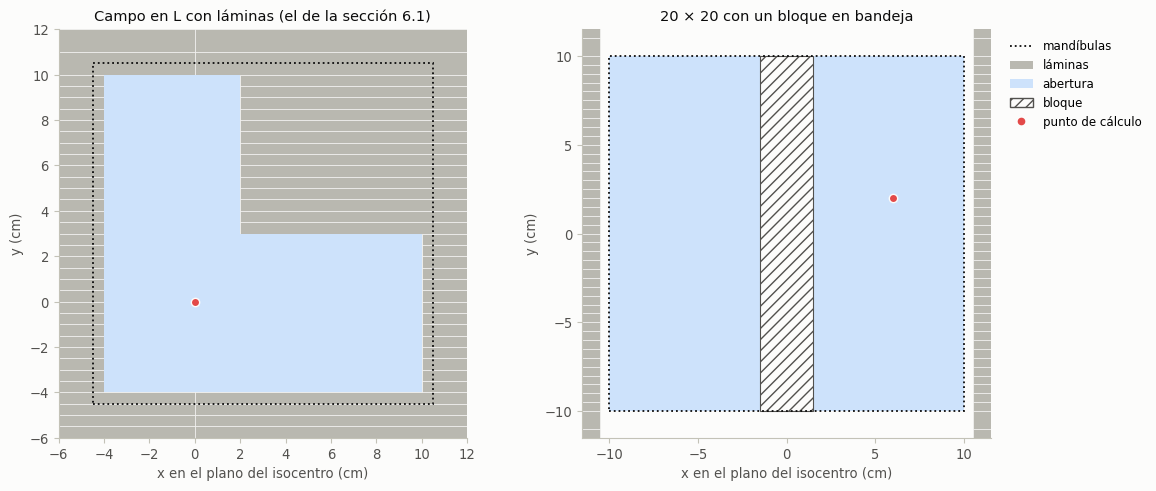

In [13]:
def dibujar_campo(ax, abertura, punto=None, res_clarkson=None, titulo="", max_rayos=72, margen=1.5):
    """Vista desde la fuente (plano del isocentro, cm) con láminas, abertura, bloques, punto y radios de Clarkson."""
    x1, x2, y1, y2 = abertura.mandibulas
    xmin, xmax, ymin, ymax = x1 - margen, x2 + margen, y1 - margen, y2 + margen
    if abertura.laminas is not None:
        limites, izq, der = abertura.laminas
        for k in range(len(limites) - 1):
            ya, yb = limites[k], limites[k + 1]
            if yb <= ymin or ya >= ymax:
                continue
            if izq[k] > xmin:
                ax.add_patch(Rectangle((xmin, ya), izq[k] - xmin, yb - ya, facecolor=COLOR["gris_laminas"],
                                       edgecolor=COLOR["fondo"], lw=0.4))
            if der[k] < xmax:
                ax.add_patch(Rectangle((der[k], ya), xmax - der[k], yb - ya, facecolor=COLOR["gris_laminas"],
                                       edgecolor=COLOR["fondo"], lw=0.4))
    for xa, xb, ya, yb in abertura.franjas:
        ax.add_patch(Rectangle((xa, ya), xb - xa, yb - ya, facecolor=COLOR["azul_claro"], edgecolor="none"))
    for pol in abertura.bloques:
        ax.add_patch(Polygon(pol, closed=True, facecolor=COLOR["fondo"], edgecolor=COLOR["tinta_2"], hatch="///", lw=0.8))
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linestyle=":", edgecolor=COLOR["tinta"], lw=1.3))
    if res_clarkson is not None:
        px, py = res_clarkson.p_iso
        cada = max(1, math.ceil(res_clarkson.n_sectores / max_rayos))
        for i in range(0, res_clarkson.n_sectores, cada):
            ux, uy = math.cos(res_clarkson.angulos[i]), math.sin(res_clarkson.angulos[i])
            for t0, t1, tipo in res_clarkson.segmentos[i]:
                a, b = t0 / res_clarkson.f_d, t1 / res_clarkson.f_d
                ax.plot([px + a * ux, px + b * ux], [py + a * uy, py + b * uy], lw=0.9, solid_capstyle="butt",
                        color=COLOR["azul"] if tipo == "abierto" else COLOR["naranja"])
    if punto is not None:
        ax.plot(punto[0], punto[1], "o", color=COLOR["rojo"], ms=6, zorder=5, markeredgecolor=COLOR["fondo"])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set(xlabel="x en el plano del isocentro (cm)", ylabel="y (cm)", title=titulo)


def leyenda_campo(ax, con_rayos=True, con_bloques=False):
    """Leyenda de los dibujos de campo (a la derecha del dibujo)."""
    elementos = [Line2D([], [], color=COLOR["tinta"], ls=":", lw=1.3, label="mandíbulas"),
                 Patch(facecolor=COLOR["gris_laminas"], label="láminas"),
                 Patch(facecolor=COLOR["azul_claro"], label="abertura")]
    if con_bloques:
        elementos.append(Patch(facecolor=COLOR["fondo"], edgecolor=COLOR["tinta_2"], hatch="///", label="bloque"))
    if con_rayos:
        elementos += [Line2D([], [], color=COLOR["azul"], label="radio: tramo abierto"),
                      Line2D([], [], color=COLOR["naranja"], label="radio: tramo bloqueado")]
    elementos.append(Line2D([], [], marker="o", ls="", color=COLOR["rojo"], label="punto de cálculo"))
    ax.legend(handles=elementos, loc="upper left", bbox_to_anchor=(1.02, 1.0))


bloque_demo = {"BlockName": "central", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
               "BlockData": [[-15.0, -100.0], [15.0, -100.0], [15.0, 100.0], [-15.0, 100.0]]}
ab_bloque = abertura_desde_haz(nuevo_haz(1, "20x20", 0.0, [-100, 100], [-100, 100],
                                         laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)),
                                         bandeja=True, bloques=[bloque_demo]), datos)
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
x1_b, x2_b, y1_b, y2_b = ab_bloque.mandibulas
dibujar_campo(ejes[0], ab_L, (0.0, 0.0), titulo="Campo en L con láminas (el de la sección 6.1)")
dibujar_campo(ejes[1], ab_bloque, (6.0, 2.0), titulo=f"{x2_b - x1_b:g} × {y2_b - y1_b:g} con un bloque en bandeja")
leyenda_campo(ejes[1], con_rayos=False, con_bloques=True)
fig.tight_layout()
plt.show()

### 6.3 Geometría IEC 61217: del paciente al haz

**Qué se hace.** `paciente_a_haz` lleva un punto del paciente (coordenadas DICOM, mm) al sistema del colimador, con las
rotaciones de la norma IEC 61217. **Solo para paciente HFS** (decúbito supino, cabeza hacia el brazo); las demás
posiciones dan un error claro, porque cambian la primera transformación.

1. $v = (\text{punto} - \text{isocentro})/10$ en cm (DICOM LPS: x hacia la izquierda del paciente, y hacia posterior,
   z hacia cefálico).
2. Mesa (HFS): $X_s = v_x$, $Y_s = v_z$, $Z_s = -v_y$ (Z hacia arriba = anterior).
3. Camilla $\psi$ alrededor de Z (antihoraria vista desde arriba): $X_f = X_s\cos\psi - Y_s\sin\psi$,
   $Y_f = X_s\sin\psi + Y_s\cos\psi$. Todos los casos usan $\psi = 0$: **la convención de la camilla hay que
   confirmarla con la máquina antes de llevarla a la app.**
4. Brazo $\theta$ alrededor de $Y_f$: $X_g = (\cos\theta, 0, -\sin\theta)$, $Y_g = (0, 1, 0)$,
   $Z_g = (\sin\theta, 0, \cos\theta)$, con $Z_g$ hacia la fuente (con 90° la fuente queda a la izquierda del paciente).
5. Colimador $\varphi$ alrededor de $Z_g$ (antihorario visto desde la fuente): $x_b = x_g\cos\varphi + y_g\sin\varphi$,
   $y_b = -x_g\sin\varphi + y_g\cos\varphi$.
6. Fuente en $(0, 0, SAD)$: $z_{plano} = SAD - z_b$ y, como define la TG-71, $SPD = z_{plano}$: **la distancia de la
   fuente al plano perpendicular al eje que contiene el punto**. La distancia oblicua fuente-punto,
   $\sqrt{x_b^2 + y_b^2 + z_{plano}^2}$, se informa como dato pero no entra en el cálculo. Proyección al plano del
   isocentro $(x_{iso}, y_{iso}) = (x_b, y_b)\cdot SAD/z_{plano}$; $x_{radial} = \sqrt{x_{iso}^2 + y_{iso}^2}$; y el
   factor $f_d = z_{plano}/SAD$ que lleva los tamaños de campo al plano del punto (la TG-71 los define en planos
   perpendiculares al eje).

**Por qué el plano y no la distancia oblicua.** El OAR de la TG-71 se mide en un plano a profundidad constante: el
punto fuera del eje se compara con el mismo campo desplazado hasta ponerlo en el eje. Ese perfil ya trae la distancia
oblicua y el camino oblicuo por el agua. En palabras sencillas: **el inverso del cuadrado va hasta el plano del punto;
lo que cambia fuera del eje ya viene en el OAR medido.** Si además se usara la distancia oblicua, la caída fuera del
eje se contaría dos veces (−0.4 % a 6 cm del eje, −1 % a 10 cm, −2.2 % a 15 cm).

Devuelve además la fuente, el punto, el isocentro y la dirección del eje central en coordenadas del maniquí: X lateral
(izquierda +), Y a lo largo de la camilla y Z anteroposterior (anterior +), en cm desde el origen DICOM del paciente.

**Qué mirar.** Con el brazo en 0° un punto 5 cm anterior queda a SPD = 95 cm; con 90°, uno 5 cm a la izquierda
también; con 180° y 270° quedan a 105 cm; con el colimador en 90°, un punto en +x del brazo pasa a $y_b$ negativo. Un
punto 5 cm a un lado del isocentro está a SPD = 100 cm (su plano es el del isocentro), aunque su distancia oblicua a la
fuente sea 100.12 cm.

In [14]:
def paciente_a_haz(punto_mm, isocentro_mm, posicion, brazo, colimador, camilla, SAD=100.0):
    """Punto del paciente (DICOM, mm) → sistema del colimador (IEC 61217, cm): SPD, proyección al isocentro y f_d.

    SPD es la distancia de la fuente al plano perpendicular al eje que contiene el punto (definición de la TG-71); la
    distancia oblicua fuente-punto se devuelve solo como dato.
    """
    if posicion != "HFS":
        raise NotImplementedError(f"Posición {posicion}: solo está implementada HFS (decúbito supino, cabeza hacia el"
                                  " brazo). FFS, HFP y FFP cambian la transformación de la mesa; quedan para la app.")
    p = np.asarray(punto_mm, dtype=float) / 10.0
    iso = np.asarray(isocentro_mm, dtype=float) / 10.0
    v = p - iso
    P_s = np.array([v[0], v[2], -v[1]])                                   # 2. mesa (HFS)
    psi = math.radians(camilla)                                           # 3. camilla
    P_f = np.array([P_s[0] * math.cos(psi) - P_s[1] * math.sin(psi),
                    P_s[0] * math.sin(psi) + P_s[1] * math.cos(psi), P_s[2]])
    th = math.radians(brazo)                                              # 4. brazo
    X_g = np.array([math.cos(th), 0.0, -math.sin(th)])
    Y_g = np.array([0.0, 1.0, 0.0])
    Z_g = np.array([math.sin(th), 0.0, math.cos(th)])
    x_g, y_g, z_g = float(P_f @ X_g), float(P_f @ Y_g), float(P_f @ Z_g)
    phi = math.radians(colimador)                                         # 5. colimador
    x_b = x_g * math.cos(phi) + y_g * math.sin(phi)
    y_b = -x_g * math.sin(phi) + y_g * math.cos(phi)
    z_b = z_g
    z_plano = SAD - z_b                                                   # 6. fuente en (0, 0, SAD)
    if z_plano <= 0:
        raise ValueError("El punto está detrás de la fuente: no se puede calcular.")
    SPD = z_plano                                                         # TG-71: fuente → plano del punto
    distancia_oblicua = math.sqrt(x_b ** 2 + y_b ** 2 + z_plano ** 2)     # solo como dato
    x_iso, y_iso = x_b * SAD / z_plano, y_b * SAD / z_plano
    S_f = SAD * Z_g                                                       # fuente en el sistema fijo
    S_s = np.array([S_f[0] * math.cos(psi) + S_f[1] * math.sin(psi),      # deshacer la camilla
                    -S_f[0] * math.sin(psi) + S_f[1] * math.cos(psi), S_f[2]])
    iso_m = np.array([iso[0], iso[2], -iso[1]])                           # isocentro en coordenadas del maniquí
    fuente, punto = iso_m + S_s, iso_m + P_s
    return {"x_b": x_b, "y_b": y_b, "z_b": z_b, "z_plano": z_plano, "SPD": SPD, "distancia_oblicua": distancia_oblicua,
            "x_iso": x_iso, "y_iso": y_iso, "x_radial": math.hypot(x_iso, y_iso), "f_d": z_plano / SAD,
            "fuente": fuente, "punto": punto, "isocentro": iso_m,
            "direccion": (punto - fuente) / np.linalg.norm(punto - fuente), "eje": -S_s / SAD}


filas = []
for nombre, punto, brazo, colim in [("5 cm anterior", (0, -50, 0), 0, 0), ("5 cm a la izquierda", (50, 0, 0), 90, 0),
                                    ("5 cm anterior", (0, -50, 0), 180, 0), ("5 cm a la izquierda", (50, 0, 0), 270, 0),
                                    ("5 cm a la izquierda", (50, 0, 0), 0, 0), ("5 cm a la izquierda", (50, 0, 0), 0, 90),
                                    ("5 cm cefálico", (0, 0, 50), 0, 0)]:
    g = paciente_a_haz(punto, (0, 0, 0), "HFS", brazo, colim, 0.0)
    filas.append({"punto": nombre, "brazo (°)": brazo, "colimador (°)": colim, "x_b (cm)": g["x_b"], "y_b (cm)": g["y_b"],
                  "z_b (cm)": g["z_b"], "SPD (cm)": g["SPD"], "dist. oblicua (cm)": g["distancia_oblicua"],
                  "x_iso (cm)": g["x_iso"], "y_iso (cm)": g["y_iso"], "f_d": g["f_d"]})
formatos_iec = {"brazo (°)": "{:.0f}", "colimador (°)": "{:.0f}"}
for c in ("x_b (cm)", "y_b (cm)", "z_b (cm)", "SPD (cm)", "dist. oblicua (cm)", "x_iso (cm)", "y_iso (cm)"):
    formatos_iec[c] = "{:.2f}"
imprimir_tabla_formato(pd.DataFrame(filas).set_index("punto"), formatos_iec,
                       "Puntos del paciente (isocentro en el origen) en el sistema del haz:")
try:
    paciente_a_haz((0, 0, 0), (0, 0, 0), "FFS", 0, 0, 0)
except NotImplementedError as e:
    print("Con otra posición:", e)

Puntos del paciente (isocentro en el origen) en el sistema del haz:
                    brazo (°) colimador (°) x_b (cm) y_b (cm) z_b (cm) SPD (cm) dist. oblicua (cm) x_iso (cm) y_iso (cm)     f_d
punto                                                                                                                           
5 cm anterior               0             0     0.00     0.00     5.00    95.00              95.00       0.00       0.00  0.9500
5 cm a la izquierda        90             0     0.00     0.00     5.00    95.00              95.00       0.00       0.00  0.9500
5 cm anterior             180             0     0.00     0.00    -5.00   105.00             105.00       0.00       0.00  1.0500
5 cm a la izquierda       270             0     0.00     0.00    -5.00   105.00             105.00       0.00       0.00  1.0500
5 cm a la izquierda         0             0     5.00     0.00     0.00   100.00             100.12       5.00       0.00  1.0000
5 cm a la izquierda         0

### 6.4 Maniquíes y profundidades

**Qué se hace.** Dos maniquíes, como cilindros a lo largo de la camilla (se usa el corte axial X–Z):
* **plano**: agua donde $Z \le z_{superficie}$ (el clásico tanque, o un paciente aproximado por agua plana);
* **elíptico**: un contorno externo (elipse de densidad 1) con heterogeneidades dentro (elipses con su densidad
  electrónica relativa; si se solapan, manda la última de la lista).

`profundidades_en_maniqui` corta el rayo fuente → punto con la superficie (recta o cuadrática) y da:
* `ssd_rayo` (fuente → entrada) y `d_rayo` (entrada → punto **a lo largo del rayo**, como el atributo DICOM
  «Beam Dose Point Depth»);
* `d`, la profundidad de la TG-71, medida en la dirección del eje: $d = d_{rayo}\cdot z_{plano}/\text{distancia
  oblicua}$. Es exacta en un maniquí plano y es la aproximación habitual con superficies curvas. Es la que entra en
  TPR, OAR y heterogeneidad (las mismas razones de la sección 6.3: el OAR medido ya trae el camino oblicuo);
* la profundidad efectiva por la **ecuación 6**, $d_{ef}=\sum_i d_i\,\rho_{e,i}$, sumando $\rho\,\Delta s$ con pasos de
  0.01 cm por punto medio (y llevada a la dirección del eje con el mismo factor);
* la longitud de pulmón en el rayo (tramos dentro del cuerpo con $\rho < 0.6$; también cuenta una cavidad de aire);
* para Batho (**ecuación 8**), **todas las capas** heterogéneas antes del punto ($|\rho - 1| > 0.05$: pulmón, hueso),
  cada una con $d_1$ y $d_2$ (distancias del punto a su cara de entrada, proximal, y a la de salida, distal) y su
  densidad.

Si el punto cae fuera del maniquí (en el aire) la función lo rechaza con un error claro. Qué es «dentro» lo decide el
contorno externo, no la densidad: el aire de afuera del contorno nunca cuenta como pulmón, y una cavidad de aire
dentro del cuerpo sí cuenta como capa heterogénea. Pero un **punto** en aire dentro del contorno (densidad menor de
0.05, por ejemplo en una cavidad) también se rechaza: las ecuaciones de la TG-71 calculan la dosis en agua, no en
aire. Y si el punto cae dentro de una heterogeneidad (pulmón o hueso), el motor avisa, con cualquier corrección y
también en electrones. En fotones, las razones están en la sección 2.A.3 de la TG-71: sus ecuaciones 2 y 3 suponen que
la dosis se da en un maniquí de agua plano y homogéneo; las correcciones por heterogeneidad usan datos medidos en
equilibrio electrónico, y por eso pide no calcular el factor de corrección CF cerca de una interfase; y presenta el
método de Batho (ecuación 8) para puntos **debajo** de una heterogeneidad. En electrones, las razones son las de la
sección 8.5: las ecuaciones de electrones de la TG-71 usan datos medidos en agua y no traen corrección por
heterogeneidad. En los dos casos conviene verificar en un punto de tejido blando.

`ssd_eje` hace lo mismo sobre el eje central (fuente → isocentro): es la `SourceToSurfaceDistance` del plan, que el
motor recalcula y compara (aviso si difieren más de 0.5 cm). `cerca_de_interfase` revisa un disco de 1 cm alrededor del
punto, solo **dentro del cuerpo**: el aire de afuera del contorno no cuenta, así que la superficie de la piel no es una
interfase. La razón: la TG-114 recomienda que el punto esté al menos a 1 cm aguas abajo y al costado de una
heterogeneidad grande, para evitar la falta de equilibrio electrónico (presentación del TG-114 en la AAPM, Stern y col.,
2013). En electrones, el cuaderno aplica la misma recomendación (sección 8.5). Un punto a menos de $d_{max}$ de
profundidad tiene, en fotones, su propio aviso: está en la zona de acumulación, sin equilibrio electrónico (la sección
2.A.3 de la TG-71 advierte que los datos fuera de equilibrio, por ejemplo con $d < d_m$, son dudosos); en electrones no
se avisa, porque su PDD se mide desde la superficie del agua.

**Qué mirar.** En la pelvis elíptica del caso 6 el isocentro queda a 11 cm (AP) y a 18 cm (lateral). En el tórax del
caso 7, la profundidad efectiva es mucho menor que la física, porque el rayo cruza pulmón; un haz lateral derecho al
mismo punto cruza los dos pulmones (dos capas). Un punto 5 cm a un lado del eje en agua plana tiene 10.01 cm de
profundidad a lo largo del rayo y 10.00 cm en la dirección del eje.

In [15]:
@dataclass
class Elipse:
    """Elipse en el corte axial (cm): centro (cx, cz), semiejes a (lateral) y b (AP), densidad electrónica relativa."""
    cx: float
    cz: float
    a: float
    b: float
    rho: float = 1.0
    nombre: str = ""

    def contiene(self, X, Z):
        return ((np.asarray(X) - self.cx) / self.a) ** 2 + ((np.asarray(Z) - self.cz) / self.b) ** 2 <= 1.0


@dataclass
class Maniqui:
    """Maniquí «plano» (agua donde Z ≤ z_superficie) o «eliptico» (contorno + heterogeneidades)."""
    tipo: str
    z_superficie: float = 0.0
    cuerpo: Optional[Elipse] = None
    inhomogeneidades: List[Elipse] = field(default_factory=list)
    nombre: str = ""


UMBRAL_PULMON = 0.6   # densidad por debajo de la cual un tramo cuenta como pulmón o tejido de baja densidad
UMBRAL_CAPA = 0.05    # |ρ − 1| por encima del cual un tramo es una capa heterogénea para Batho (pulmón, hueso)
UMBRAL_AIRE = 0.05    # densidad por debajo de la cual el punto de cálculo está en aire (se rechaza)


def dentro_del_cuerpo(maniqui, X, Z):
    """True dentro del contorno externo del maniquí (corte axial), sea cual sea la densidad del lugar."""
    X, Z = np.asarray(X, dtype=float), np.asarray(Z, dtype=float)
    if maniqui.tipo == "plano":
        return Z <= maniqui.z_superficie + 1e-9
    if maniqui.tipo == "eliptico":
        return maniqui.cuerpo.contiene(X, Z)
    raise ValueError(f"tipo de maniquí desconocido: {maniqui.tipo}")


def densidad_en(maniqui, X, Z):
    """Densidad electrónica relativa en (X, Z) del corte axial (0 fuera del maniquí)."""
    dentro = dentro_del_cuerpo(maniqui, X, Z)
    rho = np.where(dentro, 1.0 if maniqui.cuerpo is None else maniqui.cuerpo.rho, 0.0)
    for e in maniqui.inhomogeneidades:              # la última que contiene al punto manda
        rho = np.where(e.contiene(X, Z) & dentro, e.rho, rho)
    return rho


def entrada_en_maniqui(maniqui, fuente, u):
    """Distancia de la fuente a la superficie a lo largo de u (plano: recta; elíptico: cuadrática); None si no entra."""
    Sx, Sz, ux, uz = fuente[0], fuente[2], u[0], u[2]
    if maniqui.tipo == "plano":
        if abs(uz) < 1e-12:
            return None
        t = (maniqui.z_superficie - Sz) / uz
        return t if t >= 0 else None
    e = maniqui.cuerpo
    A = (ux / e.a) ** 2 + (uz / e.b) ** 2
    B = 2 * ((Sx - e.cx) * ux / e.a ** 2 + (Sz - e.cz) * uz / e.b ** 2)
    C = ((Sx - e.cx) / e.a) ** 2 + ((Sz - e.cz) / e.b) ** 2 - 1
    disc = B * B - 4 * A * C
    if A < 1e-15 or disc < 0:
        return None
    t = (-B - math.sqrt(disc)) / (2 * A)
    return t if t >= 0 else None


def capas_heterogeneas(rho, dentro, d, ds, umbral=UMBRAL_CAPA):
    """Capas de densidad distinta de 1 a lo largo del rayo: lista de (d1, d2, ρ, espesor), d1 y d2 medidas desde el punto.

    Solo cuentan las muestras dentro del contorno del cuerpo (`dentro`): el aire de afuera nunca es una capa; una
    cavidad de aire dentro del cuerpo sí lo es.
    """
    het = dentro & (np.abs(rho - 1.0) > umbral)
    capas, k = [], 0
    while k < len(rho):
        if not het[k]:
            k += 1
            continue
        j = k
        while j + 1 < len(rho) and het[j + 1] and abs(rho[j + 1] - rho[k]) < 1e-6:
            j += 1
        capas.append((d - k * ds, d - (j + 1) * ds, float(rho[k:j + 1].mean()), (j + 1 - k) * ds))
        k = j + 1
    return capas


def profundidades_en_maniqui(maniqui, fuente, punto, eje=None, paso=0.01):
    """SSD del rayo, profundidades d_rayo y d (TG-71), d_ef (ecuación 6), pulmón en el rayo y capas para Batho.

    `eje` es la dirección del eje central (fuente → isocentro). Con él, d = d_rayo·z_plano/distancia oblicua (la
    profundidad en la dirección del eje, exacta en maniquí plano); sin él, d = d_rayo. Lo mismo para d_ef, d1 y d2.
    """
    fuente, punto = np.asarray(fuente, dtype=float), np.asarray(punto, dtype=float)
    if not bool(dentro_del_cuerpo(maniqui, punto[0], punto[2])):
        raise ValueError("El punto de cálculo está fuera del maniquí (en el aire, densidad 0): revise sus coordenadas"
                         " y el contorno.")
    rho_punto = float(densidad_en(maniqui, punto[0], punto[2]))
    if rho_punto < UMBRAL_AIRE:
        raise ValueError(f"El punto de cálculo está en aire (densidad {rho_punto:.2f}) dentro del contorno, por ejemplo en"
                         " una cavidad: las ecuaciones de la TG-71 calculan la dosis en agua, no en aire; elija un punto en"
                         " tejido blando.")
    distancia = float(np.linalg.norm(punto - fuente))
    u = (punto - fuente) / distancia
    t_in = entrada_en_maniqui(maniqui, fuente, u)
    if t_in is None or t_in > distancia + 1e-6:
        raise ValueError("El punto de cálculo no está dentro del maniquí (el rayo no entra antes de llegar a él).")
    k_plano = 1.0 if eje is None else float(np.dot(u, np.asarray(eje, dtype=float)))   # z_plano / distancia oblicua
    d_rayo = max(distancia - t_in, 0.0)
    n = max(1, int(math.ceil(d_rayo / paso - 1e-9)))
    ds = d_rayo / n
    t = t_in + (np.arange(n) + 0.5) * ds
    X, Z = fuente[0] + t * u[0], fuente[2] + t * u[2]
    rho = densidad_en(maniqui, X, Z)
    dentro = dentro_del_cuerpo(maniqui, X, Z)          # el aire de afuera del contorno no cuenta
    pulmon = dentro & (rho < UMBRAL_PULMON)
    d_ef_rayo = float(rho[dentro].sum() * ds)
    capas = [{"d1": a * k_plano, "d2": b * k_plano, "rho": r, "espesor": e * k_plano, "d1_rayo": a, "d2_rayo": b}
             for a, b, r, e in capas_heterogeneas(rho, dentro, d_rayo, ds)]
    return {"ssd_rayo": t_in, "d_rayo": d_rayo, "d": d_rayo * k_plano, "d_ef_rayo": d_ef_rayo, "d_ef": d_ef_rayo * k_plano,
            "factor_plano": k_plano, "longitud_pulmon": float(pulmon.sum() * ds), "capas": capas, "rho_punto": rho_punto,
            "t": t, "rho": rho, "u": u}


def ssd_eje(maniqui, geo):
    """SSD sobre el eje central (fuente → isocentro): la SourceToSurfaceDistance del plan, en cm."""
    u = (geo["isocentro"] - geo["fuente"]) / np.linalg.norm(geo["isocentro"] - geo["fuente"])
    t = entrada_en_maniqui(maniqui, geo["fuente"], u)
    if t is None:
        raise ValueError("El eje central no entra en el maniquí.")
    return t


def cerca_de_interfase(maniqui, punto, radio=1.0, umbral=0.2):
    """True si a menos de 1 cm del punto (corte axial), dentro del cuerpo, la densidad cambia más de 0.2.

    Solo cuentan los puntos de muestra dentro del contorno: el aire de afuera no es una heterogeneidad, así que la
    superficie de la piel no da este aviso. La TG-114 recomienda que el punto esté al menos a 1 cm aguas abajo y al
    costado de una heterogeneidad grande, para evitar la falta de equilibrio electrónico (presentación del TG-114 en la
    AAPM, Stern y col., 2013); en electrones el cuaderno aplica la misma recomendación.
    """
    X0, Z0 = punto[0], punto[2]
    rho0 = densidad_en(maniqui, X0, Z0)
    RR, AA = np.meshgrid(np.linspace(radio / 4, radio, 4), np.linspace(0, 2 * np.pi, 36, endpoint=False))
    X, Z = X0 + RR * np.cos(AA), Z0 + RR * np.sin(AA)
    dentro = dentro_del_cuerpo(maniqui, X, Z)
    return bool(np.any(dentro & (np.abs(densidad_en(maniqui, X, Z) - rho0) > umbral)))


pelvis_demo = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"), nombre="pelvis elíptica")
torax_demo = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 16.0, 10.0, 1.0, "tórax"),
                     inhomogeneidades=[Elipse(-7.5, 0.5, 5.5, 7.0, 0.25, "pulmón derecho"),
                                       Elipse(7.5, 0.5, 5.5, 7.0, 0.25, "pulmón izquierdo"),
                                       Elipse(7.0, 2.0, 1.8, 1.8, 1.0, "tumor")], nombre="tórax con pulmones")


def texto_capas(capas):
    """Las capas heterogéneas de un rayo, en una línea: d1 → d2 (cm) y densidad de cada una."""
    if not capas:
        return "ninguna"
    return "; ".join(f"d1 = {c['d1']:.2f} cm, d2 = {c['d2']:.2f} cm, ρ = {c['rho']:.2f}" for c in capas)


for brazo in (0.0, 90.0):
    g = paciente_a_haz((0, 0, 0), (0, 0, 0), "HFS", brazo, 0.0, 0.0)
    pr = profundidades_en_maniqui(pelvis_demo, g["fuente"], g["punto"], g["eje"])
    print(f"Pelvis, brazo {brazo:5.1f}°: SSD = {ssd_eje(pelvis_demo, g):.2f} cm, d = {pr['d']:.2f} cm")
for brazo, nombre in ((0.0, "AP"), (90.0, "lateral izquierdo"), (270.0, "lateral derecho")):
    g = paciente_a_haz((70, -20, 0), (70, -20, 0), "HFS", brazo, 0.0, 0.0)
    pr = profundidades_en_maniqui(torax_demo, g["fuente"], g["punto"], g["eje"])
    print(f"Tórax, {nombre} ({brazo:.0f}°): SSD = {ssd_eje(torax_demo, g):.2f} cm, d = {pr['d']:.2f} cm,"
          f" d_ef = {pr['d_ef']:.2f} cm, pulmón en el rayo = {pr['longitud_pulmon']:.2f} cm;"
          f" capas para Batho: {texto_capas(pr['capas'])};"
          f" ¿interfase a menos de 1 cm? {'sí' if cerca_de_interfase(torax_demo, g['punto']) else 'no'}")
agua_demo_90 = Maniqui("plano", z_superficie=10.0, nombre="agua plana a SSD 90")
g = paciente_a_haz((50, 0, 0), (0, 0, 0), "HFS", 0.0, 0.0, 0.0)
pr = profundidades_en_maniqui(agua_demo_90, g["fuente"], g["punto"], g["eje"])
print(f"Agua plana a SSD {ssd_eje(agua_demo_90, g):.0f} cm, punto a {g['x_radial']:.0f} cm del eje en el plano del isocentro:"
      f" d a lo largo del rayo = {pr['d_rayo']:.4f} cm, d de la TG-71 = {pr['d']:.4f} cm; SPD = {g['SPD']:.2f} cm"
      f" (distancia oblicua {g['distancia_oblicua']:.2f} cm)")
punto_fuera_demo = (0, 150, 0)                       # mm; y positiva es hacia posterior (DICOM)
try:
    g = paciente_a_haz(punto_fuera_demo, (0, 0, 0), "HFS", 0.0, 0.0, 0.0)
    profundidades_en_maniqui(pelvis_demo, g["fuente"], g["punto"], g["eje"])
    print(f"Punto en {punto_fuera_demo} mm: está dentro de la pelvis")
except ValueError as e:
    lado_fuera = segun_signo(punto_fuera_demo[1], "posterior", "anterior", "")      # y positiva es hacia posterior
    print(f"Punto en {punto_fuera_demo} mm, " + (f"{abs(punto_fuera_demo[1]) / 10:g} cm {lado_fuera} al isocentro de la"
          " pelvis:" if lado_fuera else "a la altura del isocentro de la pelvis (ni anterior ni posterior):"), e)

Pelvis, brazo   0.0°: SSD = 89.00 cm, d = 11.00 cm
Pelvis, brazo  90.0°: SSD = 82.00 cm, d = 18.00 cm
Tórax, AP (0°): SSD = 93.01 cm, d = 6.99 cm, d_ef = 4.24 cm, pulmón en el rayo = 3.68 cm; capas para Batho: d1 = 5.47 cm, d2 = 1.80 cm, ρ = 0.25; ¿interfase a menos de 1 cm? no
Tórax, lateral izquierdo (90°): SSD = 91.32 cm, d = 8.68 cm, d_ef = 5.63 cm, pulmón en el rayo = 4.07 cm; capas para Batho: d1 = 5.87 cm, d2 = 1.80 cm, ρ = 0.25; ¿interfase a menos de 1 cm? no
Tórax, lateral derecho (270°): SSD = 77.32 cm, d = 22.68 cm, d_ef = 12.31 cm, pulmón en el rayo = 13.82 cm; capas para Batho: d1 = 19.88 cm, d2 = 9.13 cm, ρ = 0.25; d1 = 4.87 cm, d2 = 1.80 cm, ρ = 0.25; ¿interfase a menos de 1 cm? no
Agua plana a SSD 90 cm, punto a 5 cm del eje en el plano del isocentro: d a lo largo del rayo = 10.0125 cm, d de la TG-71 = 10.0000 cm; SPD = 100.00 cm (distancia oblicua 100.12 cm)
Punto en (0, 150, 0) mm, 15 cm posterior al isocentro de la pelvis: El punto de cálculo está fuera del maniquí (

## 7. Clarkson paso a paso

**Qué se hace.** El método de Clarkson calcula la dispersión de un campo irregular en un punto dividiendo el campo en
$N$ sectores angulares iguales alrededor del punto. Cada sector se trata como una tajada de un círculo: aporta la
dispersión del círculo de ese radio dividida por $N$. La dispersión de un círculo de radio $\rho$ se lee en la tabla
de SMR (sección 5.2) con el lado del cuadrado de igual área, $s=\rho\sqrt{\pi}$. Si el radio cruza zonas bloqueadas,
solo cuentan los tramos abiertos (anillos): un tramo abierto de $\rho_0$ a $\rho_1$ aporta
$\mathrm{SMR}(d,\rho_1\sqrt{\pi})-\mathrm{SMR}(d,\rho_0\sqrt{\pi})$, y los tramos bajo láminas o bajo un bloque no suman.

$$\mathrm{SMR}_i=\sum_{\text{tramos abiertos}}\left[\mathrm{SMR}(d,\rho_1\sqrt{\pi})-\mathrm{SMR}(d,\rho_0\sqrt{\pi})\right],\qquad
\overline{\mathrm{SMR}}=\frac{1}{N}\sum_{i=1}^{N}\mathrm{SMR}_i$$

$$[S_p\cdot\mathrm{TMR}\cdot\mathrm{OAR}]=S_p(0)\left[\mathrm{TMR}(d,0)\cdot\mathrm{OAR}(d,x)\cdot T_P+\overline{\mathrm{SMR}}\right]$$

Este producto reemplaza a $S_p(r_d)\cdot\mathrm{TMR}(d,r_d)\cdot\mathrm{OAR}(d,x)$ en la ecuación 1. Detalles:
* Los ángulos son $\theta_i=(i+\tfrac12+\delta)\,2\pi/N$ con un desplazamiento fijo $\delta$ = 0.1234 de sector. Así
  ningún radio corre paralelo a los ejes (bordes de láminas y mandíbulas) con **ningún** $N$: sin el desplazamiento,
  con $N$ impar un radio caería justo a 180°, y con $N = 4k+2$ (por ejemplo 18) a 90° y 270°; si el punto está sobre
  un borde (el isocentro suele estar sobre el límite entre dos pares de láminas), ese radio correría por el borde y
  daría a todo su sector el lado más abierto.
* Los radios se trazan en el plano del isocentro y se llevan al plano del punto multiplicando por $f_d$.
* **El OAR va solo sobre la primaria**: los cuernos del filtro aplanador cambian la fluencia primaria que llega al
  punto; la dispersión ya se integra sobre todo el campo. $T_P$ = 1 si el punto está abierto, y la transmisión de las
  láminas o del bloque si está debajo (con aviso: ahí la verificación no vale y el resultado queda como no válido).
* Por omisión la transmisión de láminas y bloques no se suma a la dispersión (`incluir_transmision=False`); con
  `True` se suma $t_{mlc}$ o $t_{bloque}$ por la SMR de esos tramos.
* `cuadrado_equivalente_de_producto` busca por bisección el cuadrado con el mismo $S_p\cdot\mathrm{TMR}$: es el «rd
  equivalente» que ve el punto. Se informa como dato; el factor de cuña, el CF y la fila de la TG-114 que eligen las
  reglas de este cuaderno (sección 9) usan el cuadrado equivalente **del campo** (4A/P de la abertura llevado al plano
  del punto), como pide la TG-71 para la cuña y el CF.
* `day` es el método de Day para un punto dentro de un rectángulo sin láminas ni bloques: los cuatro cuadrantes
  $a_i\times b_j$ alrededor del punto aportan cada uno ¼ de la SMR del rectángulo $2a_i\times 2b_j$.
* `desarmar_sector` muestra un sector por dentro, con el nombre del campo y el punto a que pertenece: cada tramo con
  $\rho_0\to\rho_1$, el lado $s=\rho\sqrt{\pi}$, la SMR leída en la tabla, la resta y la suma del sector.

Sobre el campo cero: como cada radio empieza en $\rho_0 = 0$, el término $S_p(0)\,\mathrm{TMR}(d,0)$ de la primaria se
cancela con el que va dentro de la SMR del primer tramo. El error de extrapolación de la sección 5.1 solo pesa fuera
del eje (a través del OAR), en radios menores de 1.7 cm (lado de 3 cm) y bajo protección.

In [16]:
@dataclass
class ResultadoClarkson:
    """Integración de Clarkson de un campo en un punto (radios en el plano del punto, cm)."""
    n_sectores: int
    angulos: np.ndarray
    segmentos: list                 # por radio: lista de (t0, t1, tipo), tipo «abierto», «mlc» o «bloque»
    aportes: np.ndarray             # SMR (o SPR) de cada sector
    spr_medio: float
    distancia_borde: float          # cm, plano del punto: distancia euclídea a la zona cerrada
    avisos: list
    f_d: float = 1.0
    p_iso: Tuple[float, float] = (0.0, 0.0)
    d: float = float("nan")


DESPLAZAMIENTO_ANGULAR = 0.1234   # fracción de sector: ningún radio de Clarkson queda paralelo a los ejes con ningún N


def angulos_clarkson(n_sectores):
    """Ángulos de los radios de Clarkson: θ_i = (i + ½ + δ)·2π/N, con δ = 0.1234."""
    return (np.arange(n_sectores) + 0.5 + DESPLAZAMIENTO_ANGULAR) * 2 * np.pi / n_sectores


TEXTOS_ESTADO = {
    "mlc": "el punto está bajo protección (bajo las láminas); la verificación no es válida en este punto",
    "bloque": "el punto está bajo protección (bajo un bloque); la verificación no es válida en este punto",
    "fuera": "el punto está fuera de las mandíbulas; la verificación no es válida en este punto",
}
ESTADO_CORTO = {"abierto": "abierto", "mlc": "bajo las láminas", "bloque": "bajo un bloque", "fuera": "fuera de las mandíbulas"}


def avisar_estado_punto(estado, avisos):
    """Aviso que corresponde al estado del punto (el mismo texto para todos los métodos); True si el punto está abierto."""
    if estado in TEXTOS_ESTADO:
        agregar_aviso(avisos, TEXTOS_ESTADO[estado])
    return estado == "abierto"


def clarkson(datos, abertura, p_iso, d, f_d, n_sectores=36, incluir_transmision=False):
    """Integración de Clarkson: promedio en N sectores de la SMR (o SPR) de los tramos abiertos de cada radio."""
    avisos = []
    angulos = angulos_clarkson(n_sectores)
    pesos = {"abierto": 1.0, "mlc": datos.t_mlc if incluir_transmision else 0.0,
             "bloque": datos.t_bloque if incluir_transmision else 0.0}
    segmentos, aportes = [], []
    for th in angulos:
        tramos = [(t0 * f_d, t1 * f_d, tipo) for t0, t1, tipo in segmentos_rayo(abertura, p_iso, (math.cos(th), math.sin(th)))]
        segmentos.append(tramos)
        usados = [(t0, t1, pesos[tipo]) for t0, t1, tipo in tramos if pesos[tipo] > 0]
        aporte = 0.0
        if usados:
            r0, r1, w = (np.array(c) for c in zip(*usados))
            aporte = float(np.sum(w * (spr_de_radio(datos, d, r1, avisos) - spr_de_radio(datos, d, r0, avisos))))
        aportes.append(aporte)
    aportes = np.array(aportes)
    return ResultadoClarkson(n_sectores, angulos, segmentos, aportes, float(aportes.mean()),
                             distancia_al_borde(abertura, p_iso, f_d), avisos, f_d, tuple(p_iso), d)


def sp_tpr_clarkson(datos, res, d, oar, estado, avisos=None):
    """[Sp·TPR·OAR] = Sp(0)·[TPR(d, 0)·OAR·T_P + SMR medio]: el OAR va solo sobre la primaria."""
    T_P = {"abierto": 1.0, "mlc": datos.t_mlc, "bloque": datos.t_bloque, "fuera": 0.0}[estado]
    avisar_estado_punto(estado, avisos)
    tpr0 = tpr0_de(datos, d, avisos)
    valor = datos.sp0 * (tpr0 * oar * T_P + res.spr_medio)
    return valor, {"sp0": datos.sp0, "tpr0": tpr0, "oar": oar, "T_P": T_P, "spr_medio": res.spr_medio}


def desarmar_sector(datos, res, i, campo, incluir_transmision=False):
    """Imprime el sector i de Clarkson por dentro: cada tramo con ρ0 → ρ1, s = ρ·√π, la SMR leída y la resta.

    `campo` nombra el campo (por ejemplo «campo en L de la sección 6.1»); el punto sale del cálculo mismo (res.p_iso).
    """
    disp = nombre_dispersion(datos)
    pesos = {"abierto": 1.0, "mlc": datos.t_mlc if incluir_transmision else 0.0,
             "bloque": datos.t_bloque if incluir_transmision else 0.0}
    x_p, y_p = res.p_iso
    print(f"Sector {i + 1} de {res.n_sectores} del {campo}, punto en ({x_p:.2f}, {y_p:.2f}) cm del plano del isocentro;"
          f" θ = {math.degrees(res.angulos[i]):.1f}°, d = {res.d:.2f} cm")
    print("  (radios en el plano del punto; s = ρ·√π es el lado del cuadrado de igual área)")
    total = 0.0
    for t0, t1, tipo in res.segmentos[i]:
        s0, s1 = t0 * math.sqrt(math.pi), t1 * math.sqrt(math.pi)
        a0 = float(spr_de_radio(datos, res.d, np.array([t0]))[0])
        a1 = float(spr_de_radio(datos, res.d, np.array([t1]))[0])
        if pesos[tipo] > 0:
            aporte = pesos[tipo] * (a1 - a0)
            total += aporte
            peso = "" if pesos[tipo] == 1.0 else f"{pesos[tipo]:.3f} × "
            print(f"  {tipo:<8} ρ = {t0:5.2f} → {t1:5.2f} cm   s = {s0:5.2f} → {s1:5.2f} cm   "
                  f"{disp}(d, {s1:.2f} cm) − {disp}(d, {s0:.2f} cm) = {peso}({a1:.4f} − {a0:.4f}) = {aporte:+.4f}")
        else:
            print(f"  {tipo:<8} ρ = {t0:5.2f} → {t1:5.2f} cm   s = {s0:5.2f} → {s1:5.2f} cm   no suma"
                  f" ({'bajo las láminas' if tipo == 'mlc' else 'bajo el bloque'}; sin transmisión)")
    print(f"  {disp} del sector = {total:.4f}   (el cálculo de Clarkson dio {res.aportes[i]:.4f})")
    return total


def producto_sp_tpr(datos, d, s):
    """Sp(s)·TPR(d, s) con las tablas extendidas a campo cero (sin avisos: solo para buscar cuadrados equivalentes)."""
    sp = float(np.interp(s, datos.sp_ext.index.to_numpy(dtype=float), datos.sp_ext.to_numpy(dtype=float)))
    return sp * interp2(datos.tpr_ext, d, s)


def cuadrado_equivalente_de_producto(datos, d, valor, oar=1.0, s_min=0.5, s_max=40.0):
    """Lado s (cm, plano del punto) con Sp(s)·TPR(d, s) = valor/OAR, por bisección en [0.5, 40] cm."""
    objetivo = valor / oar
    if producto_sp_tpr(datos, d, s_min) >= objetivo:
        return s_min
    if producto_sp_tpr(datos, d, s_max) <= objetivo:
        return s_max
    bajo, alto = s_min, s_max
    for _ in range(50):
        medio = 0.5 * (bajo + alto)
        if producto_sp_tpr(datos, d, medio) < objetivo:
            bajo = medio
        else:
            alto = medio
    return 0.5 * (bajo + alto)


def day(datos, abertura, p_iso, d, f_d, oar, avisos=None):
    """Método de Day: Sp(0)·[TPR(d, 0)·OAR + ¼·Σ SMR(d, equivalente de 2a_i × 2b_j)] (rectángulo sin láminas ni bloques)."""
    x1, x2, y1, y2 = abertura.mandibulas
    a = [(p_iso[0] - x1) * f_d, (x2 - p_iso[0]) * f_d]
    b = [(p_iso[1] - y1) * f_d, (y2 - p_iso[1]) * f_d]
    if min(a + b) <= 0:
        raise ValueError("Day: el punto tiene que estar dentro del rectángulo de las mandíbulas")
    rectangulos = []
    for ai in a:
        for bj in b:
            s = equivalente_rectangulo(2 * ai, 2 * bj)
            rectangulos.append((2 * ai, 2 * bj, s, spr_de(datos, d, s, avisos)))
    aporte = 0.25 * sum(r[3] for r in rectangulos)
    tpr0 = tpr0_de(datos, d, avisos)
    valor = datos.sp0 * (tpr0 * oar + aporte)
    return valor, {"sp0": datos.sp0, "tpr0": tpr0, "oar": oar, "aporte": aporte, "rectangulos": rectangulos, "a": a, "b": b}

### 7.1 Un campo irregular, sector por sector

**Qué se hace.** Clarkson con 36 sectores en el campo en L de la sección 6.1, en el isocentro y a 10 cm de profundidad
(plano del punto = plano del isocentro, $f_d$ = 1). Para cada sector se listan sus tramos y su SMR; luego el promedio y
el producto $[S_p\cdot\mathrm{TMR}\cdot\mathrm{OAR}]$ con sus números. Después se **desarman dos sectores**, para ver
de dónde sale cada número: uno del L (un tramo abierto y luego láminas, que no suman) y uno del campo de 20 × 20 con el
bloque central de la sección 6.2, visto desde el punto (6, 2) cm, cuyo radio va abierto → bloque → abierto.

**Qué mirar.** Los sectores que miran a lo largo de los dos brazos de la L (hacia la derecha, θ ≈ 0°, y hacia arriba,
θ ≈ 90°) aportan más, porque el campo sigue abierto 10 cm. Los que miran hacia la izquierda y hacia abajo (borde a
4 cm) aportan menos, y los que miran a la esquina interior recortada (θ ≈ 56°, a 3.6 cm) tienen un tramo abierto
corto seguido de láminas. El L da un poco más de dispersión que su cuadrado 4A/P de 10 cm. En el sector desarmado del
bloque, el último tramo abierto (más allá del bloque) suma poco, porque la SMR ya casi no crece a esos radios.

sector   θ (°)   tramos (cm, plano del punto)          SMR del sector
     1     6.2   abierto 0.00→10.06; mlc 10.06→10.56   0.1839
     2    16.2   abierto 0.00→10.42; mlc 10.42→10.94   0.1872
     3    26.2   abierto 0.00→6.79; mlc 6.79→11.71     0.1487
     4    36.2   abierto 0.00→5.08; mlc 5.08→13.02     0.1221
     5    46.2   abierto 0.00→4.15; mlc 4.15→14.54     0.1054
     6    56.2   abierto 0.00→3.61; mlc 3.61→12.63     0.0944
     7    66.2   abierto 0.00→4.96; mlc 4.96→11.47     0.1201
     8    76.2   abierto 0.00→8.40; mlc 8.40→10.81     0.1685
     9    86.2   abierto 0.00→10.02; mlc 10.02→10.52   0.1836
    10    96.2   abierto 0.00→10.06; mlc 10.06→10.56   0.1839
    11   106.2   abierto 0.00→10.42; mlc 10.42→10.94   0.1872
    12   116.2   abierto 0.00→9.05; mlc 9.05→10.18     0.1746
    13   126.2   abierto 0.00→6.77; mlc 6.77→7.61      0.1485
    14   136.2   abierto 0.00→5.54; mlc 5.54→6.23      0.1300
    15   146.2   abierto 0.00→4.81; mlc 4.81→5.41      0.1175


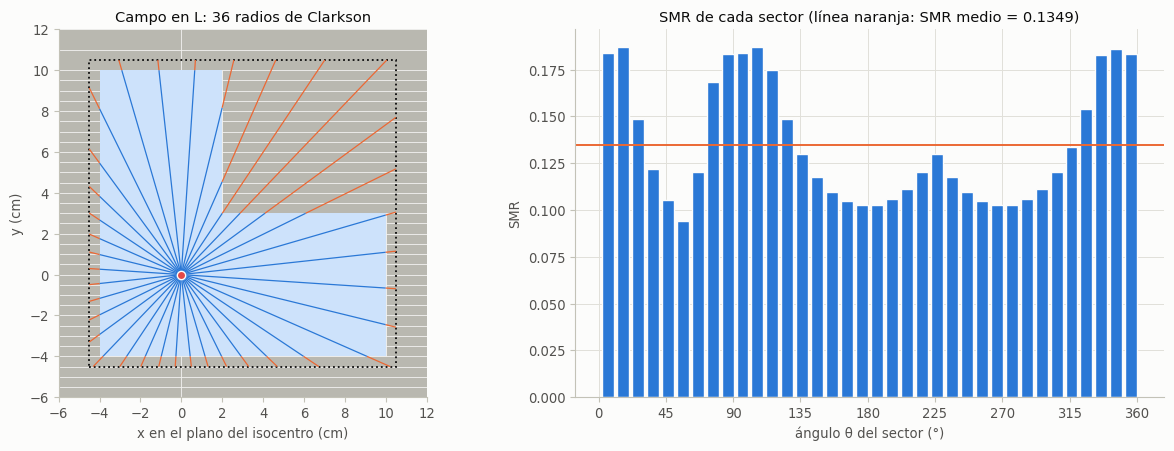

In [17]:
p_L, d_demo = (0.0, 0.0), 10.0                       # el punto (plano del isocentro, cm) y la profundidad de la demostración
res_L = clarkson(datos, ab_L, p_L, d_demo, 1.0, 36)
estado_L = estado_punto(ab_L, p_L)
oar_L = interp2(datos.poar, res_L.d, math.hypot(*p_L), "OAR")       # perfil primario en el punto (sección 8.1)
prod_L, det_L = sp_tpr_clarkson(datos, res_L, res_L.d, oar_L, estado_L)
t_L = datos.nombre_tpr
textos = ["; ".join(f"{tipo} {t0:.2f}→{t1:.2f}" for t0, t1, tipo in tramos) for tramos in res_L.segmentos]
ancho = max(len(t) for t in textos)
print(f"{'sector':>6} {'θ (°)':>7}   {'tramos (cm, plano del punto)':<{ancho}}   {DISP} del sector")
for i in range(res_L.n_sectores):
    print(f"{i + 1:>6} {math.degrees(res_L.angulos[i]):>7.1f}   {textos[i]:<{ancho}}   {res_L.aportes[i]:.4f}")
print(f"\n{DISP} medio = (1/{res_L.n_sectores})·Σ {DISP}_i = {res_L.spr_medio:.4f}")
tp_L = "" if det_L["T_P"] == 1.0 else f" × {det_L['T_P']:.4f}"
print(f"[Sp·{t_L}·OAR] = Sp(0)·[{t_L}(d, 0)·OAR{' × T_P' if tp_L else ''} + {DISP} medio] = {det_L['sp0']:.4f}·[{det_L['tpr0']:.4f}"
      f" × {det_L['oar']:.4f}{tp_L} + {res_L.spr_medio:.4f}] = {prod_L:.4f}   (punto {ESTADO_CORTO[estado_L]},"
      f" d = {res_L.d:.2f} cm)")
abierto_L = det_L["sp0"] * (det_L["tpr0"] * det_L["oar"] + det_L["spr_medio"])      # con T_P = 1, como el motor
s_eq_L = cuadrado_equivalente_de_producto(datos, res_L.d, abierto_L, det_L["oar"])
s4_L = equivalente_4AP(*area_perimetro(ab_L))
sp4_L, tpr4_L = sp_de(datos, s4_L), tpr_de(datos, res_L.d, s4_L)
oar4_f, oar4_v = ("", "") if det_L["oar"] == 1.0 else (" × OAR", f" × {det_L['oar']:.4f}")
rd_txt_L = ("rd equivalente (el cuadrado que da el mismo producto)" if det_L["T_P"] == 1.0 else    # como el desglose
            "rd equivalente, con el punto como si estuviera abierto (el cuadrado que da el mismo producto sin T_P)")
print(f"{rd_txt_L} = {s_eq_L:.2f} cm;  con 4A/P = {s4_L:.2f} cm"
      f" sería Sp({s4_L:.2f} cm)·{t_L}({res_L.d:.2f} cm; {s4_L:.2f} cm){oar4_f} = {sp4_L:.4f} × {tpr4_L:.4f}{oar4_v} ="
      f" {sp4_L * tpr4_L * det_L['oar']:.4f}")
if estado_L == "abierto":
    _, (xb_7, yb_7) = punto_mas_cercano_del_borde(ab_L, p_L)
    print(f"Distancia del punto a la zona cerrada más cercana: {res_L.distancia_borde:.2f} cm, hasta el punto"
          f" ({xb_7:.2f}, {yb_7:.2f}) cm del borde\n")
else:
    print(f"El punto no está abierto ({ESTADO_CORTO[estado_L]}): no hay distancia al borde\n")
p_bloque = (6.0, 2.0)                                # el punto del campo con bloque de la sección 6.2
res_bloque = clarkson(datos, ab_bloque, p_bloque, d_demo, 1.0, 36)
i_bloque = [i for i, tramos in enumerate(res_bloque.segmentos)
            if [t[2] for t in tramos][:3] == ["abierto", "bloque", "abierto"]]
x1_b, x2_b, y1_b, y2_b = ab_bloque.mandibulas
print("Dos sectores desarmados, de dos campos distintos:" if i_bloque else "Un sector desarmado:")
desarmar_sector(datos, res_L, min(5, res_L.n_sectores - 1), "campo en L de la sección 6.1 (el de la tabla de arriba)")
print()
if i_bloque:
    desarmar_sector(datos, res_bloque, i_bloque[0], f"campo de {x2_b - x1_b:g} × {y2_b - y1_b:g} con bloque de la sección 6.2"
                                                    " (otro campo, no el L)")
else:
    print(f"En el campo con bloque de la sección 6.2, ningún radio va abierto → bloque → abierto desde"
          f" ({p_bloque[0]:g}, {p_bloque[1]:g}) cm.")

fig = plt.figure(figsize=(12.5, 4.6))
ax = fig.add_subplot(1, 2, 1)
dibujar_campo(ax, ab_L, p_L, res_L, titulo=f"Campo en L: {plural(res_L.n_sectores, 'radio')} de Clarkson")
ax = fig.add_subplot(1, 2, 2)
ax.bar(np.degrees(res_L.angulos), res_L.aportes, width=8.0, color=COLOR["azul"], edgecolor=COLOR["fondo"], lw=1.0)
ax.axhline(res_L.spr_medio, color=COLOR["naranja"], lw=1.4)
ax.set(title=f"{DISP} de cada sector (línea naranja: {DISP} medio = {res_L.spr_medio:.4f})", xlabel="ángulo θ del sector (°)",
       ylabel=DISP, xticks=range(0, 361, 45))
fig.tight_layout()
plt.show()

## 8. El motor: factores, ecuaciones, orquestador y desglose

### 8.1 Los factores

**Qué se hace.** Una función por factor, cada una leyendo su tabla:
* `sc_de_mandibulas`: Sc con las mandíbulas. `"4AP"` (por omisión) usa la **ecuación 4**,
  $r_c=\dfrac{4\,r_{jU}\,r_{jL}}{2r_{jU}+2r_{jL}}$; `"PEV"` usa la vista desde el punto (**ecuaciones B1 y B2**) y
  distingue 5 × 20 de 20 × 5; `"matriz"` interpola en la tabla medida Sc(X, Y). Con láminas terciarias (Varian) la
  TG-71 recomienda el tamaño de las **mandíbulas**, no el de la abertura: las láminas se tratan como un bloque.
* `oar`: perfil primario, bilineal en (d, x radial). Es un perfil medido a profundidad constante, que ya contiene la
  distancia y el camino oblicuos: por eso el inverso del cuadrado va solo hasta el plano del punto (sección 6.3).
* `wf`: factor de cuña = tabla en el eje (d, $r_d$) × cociente fuera del eje, con $x_g$ medida en la dirección del
  gradiente y positiva hacia el talón. El argumento $r_d$ es el cuadrado equivalente **del campo** en el plano del
  punto (TG-71, 2.A.2.d.i y tabla VI: «side of equivalent square»): la dependencia con el campo viene de la dispersión
  de cabezal y es propia del campo, no del punto. Solo hay datos de la cuña física de 30°.
* `cf_profundidad_efectiva`: $\mathrm{CF}=\dfrac{\mathrm{TPR}(d_{ef},r_d)}{\mathrm{TPR}(d,r_d)}$ (**ecuación 7**).
  `dmax_de` da la profundidad de máximo (donde la TPR del 10 × 10 es mayor), que usan los avisos de la zona de
  acumulación: del punto (en `calcular_campo`) y de la profundidad efectiva (aquí, si el punto no lo tiene ya).
* `cf_batho`: Batho por capas, $\mathrm{CF}=\prod_k\left[\dfrac{\mathrm{TPR}(d_{1,k},r_d)}{\mathrm{TPR}(d_{2,k},r_d)}\right]^{\rho_k-1}$,
  con $d_{1,k}$ y $d_{2,k}$ las distancias del punto a las caras proximal y distal de la capa $k$ (pulmón o hueso).
  Con una sola capa es la **ecuación 8**; la TG-71 dice que el método se extiende a varias heterogeneidades.
* `isl`: $\left(\dfrac{SSD_0+d_0}{SPD}\right)^2$, con $SPD$ = distancia de la fuente al plano del punto.
* `proyectar_lado`: lleva un lado de campo de un plano a otro por semejanza de triángulos (por ejemplo del isocentro a
  la superficie, $r = s\cdot SSD/SAD$).
* `pdd_desde_tpr`: el PDD a cualquier SSD desde la TPR (**ecuación 16** al revés),
  $\mathrm{PDD}_N(d,r,SSD)=100\,\mathrm{TPR}(d,r_d)\,\dfrac{S_p(r_d)}{S_p(r_{d_0})}\left(\dfrac{SSD+d_0}{SSD+d}\right)^2$,
  con $r_d=r\,(SSD+d)/SSD$ y $r_{d_0}=r\,(SSD+d_0)/SSD$; `pdd_de_tabla` (tabla a SSD 100); `pdd_mayneord` (tabla × F
  de Mayneord, **ecuación 15**); y `pdd_ec14`, la **ecuación 14**: tabla × F × el cociente
  $\mathrm{TPR}(d,r\,f_2(d))/\mathrm{TPR}(d,r\,f_1(d))$ (el campo en profundidad cambia con la SSD), y si se pide, × el
  corchete de $S_p$, que la TG-71 dice que suele poder ignorarse (< 0.5 %).

**Qué mirar.** Sc de 10 × 15, 15 × 10, 5 × 20 y 20 × 5 con los tres métodos (4A/P no ve el intercambio de colimador; la
vista desde el punto y la matriz sí), un factor de cuña fuera del eje y los CF del pulmón del haz AP del caso 7,
calculados con las profundidades que da la geometría y con $r_d$ = 6.00 cm, el lado del campo de 6 × 6 en el plano del
punto.

In [18]:
def factor_pev(datos):
    """F = c·(a − b)/(b·(a − c)) (ecuación B1), con a = SAD, b = fuente → mandíbulas inferiores, c = superiores."""
    a, b, c = datos.SAD, datos.dist_mand_inf, datos.dist_mand_sup
    return c * (a - b) / (b * (a - c))


def sc_de_mandibulas(datos, X, Y, metodo="4AP", avisos=None):
    """Sc con las mandíbulas (X = ancho de las inferiores, Y = de las superiores; cm en el isocentro): (rc, Sc, método).

    «4AP»: ecuación 4; «PEV»: ecuaciones B1 y B2; «matriz»: tabla medida Sc(X, Y) (rc = cuadrado con el mismo Sc).
    """
    if metodo == "4AP":
        rc = equivalente_rectangulo(X, Y)
        return rc, sc_de(datos, rc, avisos), "4A/P (ec. 4)"
    if metodo == "PEV":
        F = factor_pev(datos)
        rc = (F + 1) * Y * X / (F * Y + X)
        return rc, sc_de(datos, rc, avisos), f"vista desde el punto (ec. B1 y B2, F = {F:.4f})"
    if metodo == "matriz":
        Sc = interp2(datos.sc_matriz, Y, X, "Sc(X, Y)", avisos)
        rc = float(np.interp(Sc, datos.sc.to_numpy(dtype=float), datos.sc.index.to_numpy(dtype=float)))
        return rc, Sc, "matriz medida Sc(X, Y)"
    raise ValueError(f"método de Sc desconocido: {metodo}")


def oar(datos, d, x_radial, avisos=None):
    """OAR(d, x): perfil primario, bilineal en la tabla (x = distancia radial a 100 cm)."""
    return interp2(datos.poar, d, x_radial, "OAR", avisos)


def coordenada_talon(direccion, x_iso, y_iso):
    """Coordenada del punto (cm, plano del isocentro) en la dirección del gradiente de la cuña, positiva hacia el talón."""
    clave = direccion.replace("−", "-").upper()
    return {"+Y": y_iso, "-Y": -y_iso, "+X": x_iso, "-X": -x_iso}[clave]


def wf(datos, cuna, d, s, x_g, avisos=None):
    """WF = WF_eje(d, s) × WF(x_g)/WF(0). Devuelve (WF, valor en el eje, cociente fuera del eje)."""
    if cuna is None:
        return 1.0, 1.0, 1.0
    if int(round(float(cuna["WedgeAngle"]))) != 30:
        raise ValueError(f"Solo hay datos de la cuña física de 30°; el haz trae {cuna['WedgeAngle']}°")
    eje = interp2(datos.wf30, d, s, "WF", avisos)
    cociente = interp1(x_g, datos.wf30_fuera_eje.index, datos.wf30_fuera_eje.values, "WF fuera del eje", avisos)
    return eje * cociente, eje, cociente


def dmax_de(datos):
    """Profundidad de máximo del haz (cm): donde la TPR (o TMR) del campo de 10 × 10 cm es mayor."""
    columna = min(datos.tpr.columns, key=lambda s: abs(float(s) - 10.0))
    return float(datos.tpr[columna].idxmax())


def cf_profundidad_efectiva(datos, d, d_ef, s, avisos=None):
    """CF = TPR(d_ef, rd)/TPR(d, rd): profundidad efectiva (ecuación 7 de la TG-71). Devuelve (CF, detalle).

    Si d_ef es menor que dmax, avisa (la corrección cae en la zona de acumulación); si también lo es d, ya avisa
    calcular_campo por el punto mismo y aquí no se repite.
    """
    dmax = dmax_de(datos)
    if d_ef < dmax - 1e-9 and d >= dmax - 1e-9:
        agregar_aviso(avisos, f"la profundidad efectiva ({d_ef:.2f} cm) es menor que dmax ({dmax:.2f} cm): la corrección"
                              " cae en la zona de acumulación, sin equilibrio electrónico")
    a, b = tpr_de(datos, d_ef, s, avisos), tpr_de(datos, d, s, avisos)
    return a / b, {"tpr_a": a, "tpr_b": b, "prof_a": d_ef, "prof_b": d}


def cf_batho(datos, capas, rd, avisos=None):
    """Batho por capas: CF = Π_k [TPR(d1_k, rd)/TPR(d2_k, rd)]^(ρ_k − 1); con una capa es la ecuación 8.

    `capas`: lista de (d1, d2, ρ) o de diccionarios con esas claves; d1 y d2 son las distancias del punto a las caras
    proximal y distal de cada capa. Devuelve (CF, detalle con el factor de cada capa).
    """
    cf, detalle = 1.0, []
    for capa in capas:
        d1, d2, rho = (capa["d1"], capa["d2"], capa["rho"]) if isinstance(capa, dict) else capa
        a, b = tpr_de(datos, d1, rd, avisos), tpr_de(datos, d2, rd, avisos)
        factor = (a / b) ** (rho - 1.0)
        cf *= factor
        detalle.append({"d1": d1, "d2": d2, "rho": rho, "tpr_a": a, "tpr_b": b, "factor": factor})
    return cf, {"capas": detalle, "rd": rd}


def isl(datos, spd):
    """Inverso del cuadrado de las ecuaciones 1 y 2: ((SSD0 + d0)/SPD)², con SPD hasta el plano del punto."""
    return ((datos.SSD0 + datos.d0) / spd) ** 2


def proyectar_lado(lado, distancia_origen, distancia_destino):
    """Lado de un campo llevado de un plano a otro (cm), por semejanza de triángulos desde la fuente."""
    return lado * distancia_destino / distancia_origen


def pdd_desde_tpr(datos, d, r, ssd, avisos=None, detalle=False):
    """PDD_N(d, r, SSD) desde la TPR (ecuación 16 al revés); r = lado en la superficie.

    Con detalle=True devuelve (PDD, intermedios) para el desglose.
    """
    rd, rd0 = proyectar_lado(r, ssd, ssd + d), proyectar_lado(r, ssd, ssd + datos.d0)
    t, sp_rd, sp_rd0 = tpr_de(datos, d, rd, avisos), sp_de(datos, rd, avisos), sp_de(datos, rd0, avisos)
    k = ((ssd + datos.d0) / (ssd + d)) ** 2
    pdd = 100.0 * t * sp_rd / sp_rd0 * k
    if detalle:
        return pdd, {"rd": rd, "rd0": rd0, "tpr": t, "sp_rd": sp_rd, "sp_rd0": sp_rd0, "k": k, "ssd": ssd, "d": d}
    return pdd


def pdd_de_tabla(datos, d, r, avisos=None):
    """PDD_N(d, r) de la tabla medida a SSD 100 (r = lado en la superficie)."""
    return interp2(datos.pdd100, d, r, "PDD", avisos)


def factor_mayneord(datos, d, ssd):
    """F de Mayneord (ecuación 15): pasa el PDD de la SSD de la tabla a otra SSD."""
    s1 = datos.ssd_pdd
    return ((ssd + datos.d0) / (ssd + d) * (s1 + d) / (s1 + datos.d0)) ** 2


def pdd_mayneord(datos, d, r, ssd, avisos=None):
    """PDD de la tabla × F (ecuación 15): desprecia el cociente de TPR y el corchete de Sp de la ecuación 14."""
    return pdd_de_tabla(datos, d, r, avisos) * factor_mayneord(datos, d, ssd)


def pdd_ec14(datos, d, r, ssd, con_corchete=False, avisos=None, detalle=False):
    """Ecuación 14 de la TG-71: PDD de la tabla × F × TPR(d, r·f2(d))/TPR(d, r·f1(d)) [× corchete de Sp].

    f_i(z) = (SSD_i + z)/SSD_i, con SSD1 la de la tabla y SSD2 la del tratamiento; r = lado en la superficie.
    Con detalle=True devuelve (PDD, intermedios) para el desglose.
    """
    s1, s2, d0 = datos.ssd_pdd, ssd, datos.d0
    f1, f2 = (lambda z: (s1 + z) / s1), (lambda z: (s2 + z) / s2)
    tabla, F = pdd_de_tabla(datos, d, r, avisos), factor_mayneord(datos, d, ssd)
    t2, t1 = tpr_de(datos, d, r * f2(d), avisos), tpr_de(datos, d, r * f1(d), avisos)
    corchete = 1.0
    if con_corchete:
        corchete = (sp_de(datos, r * f1(d0), avisos) * sp_de(datos, r * f2(d), avisos)
                    / (sp_de(datos, r * f1(d), avisos) * sp_de(datos, r * f2(d0), avisos)))
    valor = tabla * F * t2 / t1 * corchete
    if detalle:
        return valor, {"tabla": tabla, "F": F, "tpr_2": t2, "tpr_1": t1, "r_2": r * f2(d), "r_1": r * f1(d),
                       "corchete": corchete, "ssd_tabla": s1, "ssd": s2, "d": d}
    return valor


filas = []
for X, Y in ((10, 15), (15, 10), (5, 20), (20, 5)):
    fila = {"campo X × Y (cm)": f"{X} × {Y}"}
    for metodo in ("4AP", "PEV", "matriz"):
        rc, Sc, _ = sc_de_mandibulas(datos, X, Y, metodo)
        fila[f"rc {metodo} (cm)"], fila[f"Sc {metodo}"] = rc, Sc
    filas.append(fila)
imprimir_tabla_formato(pd.DataFrame(filas).set_index("campo X × Y (cm)"),
                       {f"rc {m} (cm)": "{:.2f}" for m in ("4AP", "PEV", "matriz")}, "Sc de rectángulos con los tres métodos:")
d_ej, s_ej, xg_ej = 10.0, 10.0, 3.0                  # profundidad, lado del campo y distancia hacia el talón (cm)
WF_ej, eje_ej, coc_ej = wf(datos, {"WedgeAngle": 30}, d_ej, s_ej, xg_ej)
print(f"Cuña de 30°, {s_ej:g} × {s_ej:g} a {d_ej:g} cm, {xg_ej:g} cm hacia el talón: WF = WF({d_ej:.2f} cm; {s_ej:.2f} cm)"
      f"·WF({xg_ej:.2f} cm)/WF(0) = {eje_ej:.4f} × {coc_ej:.4f} = {WF_ej:.4f}")
g_cf = paciente_a_haz((70, -20, 0), (70, -20, 0), "HFS", 0.0, 0.0, 0.0)          # haz AP al centro del tumor
pr_cf = profundidades_en_maniqui(torax_demo, g_cf["fuente"], g_cf["punto"], g_cf["eje"])
rd_cf = proyectar_lado(6.0, 100.0, g_cf["z_plano"])                              # campo de 6 × 6 en el plano del punto
cf7, det7 = cf_profundidad_efectiva(datos, pr_cf["d"], pr_cf["d_ef"], rd_cf)
cf8, det8 = cf_batho(datos, pr_cf["capas"], rd_cf)
c8 = det8["capas"][0]
print(f"Pulmón, haz AP del tórax de la sección 6.4 (profundidades de la geometría; rd = {rd_cf:.2f} cm):")
print(f"  CF ec. 7 = TMR(d_ef; rd)/TMR(d; rd) = TMR({pr_cf['d_ef']:.2f} cm; {rd_cf:.2f} cm)/TMR({pr_cf['d']:.2f} cm;"
      f" {rd_cf:.2f} cm) = {det7['tpr_a']:.4f}/{det7['tpr_b']:.4f} = {cf7:.4f}")
n8 = len(det8["capas"])
print(f"  CF ec. 8 = [TMR(d1; rd)/TMR(d2; rd)]^(ρ − 1) = [TMR({c8['d1']:.2f} cm; {rd_cf:.2f} cm)/TMR({c8['d2']:.2f} cm;"
      f" {rd_cf:.2f} cm)]^({c8['rho']:.2f} − 1) = [{c8['tpr_a']:.4f}/{c8['tpr_b']:.4f}]^({c8['rho'] - 1:.2f}) = {c8['factor']:.4f}"
      + (f"   ({plural(n8, 'capa heterogénea', 'capas heterogéneas')} en el rayo)" if n8 == 1 else
         f"   (la primera de {plural(n8, 'capa heterogénea', 'capas heterogéneas')}; el CF de Batho, producto de todas, es"
         f" {cf8:.4f})"))
print(f"PDD(10 cm; 10 cm; SSD 100): tabla = {pdd_de_tabla(datos, 10, 10):.2f} %, desde la TMR (ec. 16) = {pdd_desde_tpr(datos, 10, 10, 100):.2f} %")

Sc de rectángulos con los tres métodos:
                 rc 4AP (cm)  Sc 4AP rc PEV (cm)  Sc PEV rc matriz (cm) Sc matriz
campo X × Y (cm)                                                                 
10 × 15                12.00  1.0084       12.49  1.0101          12.52    1.0102
15 × 10                12.00  1.0084       11.54  1.0065          11.57    1.0066
5 × 20                  8.00  0.9897        9.07  0.9952           9.13    0.9955
20 × 5                  8.00  0.9897        7.15  0.9845           7.16    0.9846

Cuña de 30°, 10 × 10 a 10 cm, 3 cm hacia el talón: WF = WF(10.00 cm; 10.00 cm)·WF(3.00 cm)/WF(0) = 0.5490 × 0.9170 = 0.5034
Pulmón, haz AP del tórax de la sección 6.4 (profundidades de la geometría; rd = 6.00 cm):
  CF ec. 7 = TMR(d_ef; rd)/TMR(d; rd) = TMR(4.24 cm; 6.00 cm)/TMR(6.99 cm; 6.00 cm) = 0.9210/0.8352 = 1.1027
  CF ec. 8 = [TMR(d1; rd)/TMR(d2; rd)]^(ρ − 1) = [TMR(5.47 cm; 6.00 cm)/TMR(1.80 cm; 6.00 cm)]^(0.25 − 1) = [0.8826/0.9921]^(-0.75) = 1.0916   (

### 8.2 Las ecuaciones: una función por ecuación de la TG-71

**Qué se hace.** Cada función recibe los factores ya leídos y devuelve tres cosas: las UM sin redondear, la dosis por
UM y un diccionario con cada factor (en el orden en que se multiplican). Así la app puede mostrar exactamente qué
entró en cada cálculo, y la sección 12 las alimenta con los factores publicados de la TG-71.

| Función | Ecuación de la TG-71 |
|---|---|
| `ecuacion_1` | (1) TPR, punto a cualquier distancia: $\mathrm{UM}=D/[D'_0\,S_c\,S_p\,\mathrm{TPR}\,\mathrm{OAR}\,\mathrm{WF}\,\mathrm{TF}\,\mathrm{CF}\,((SSD_0+d_0)/SPD)^2]$ |
| `ecuacion_1_clarkson` | (1) con el producto $[S_p\,\mathrm{TPR}\,\mathrm{OAR}]$ de Clarkson o de Day |
| `ecuacion_2` | (2) punto en el isocentro: $SPD = SAD$, sin OAR |
| `ecuacion_3` | (3) PDD, SSD fija: $\mathrm{UM}=D\cdot100/[D'_0\,S_c\,S_p(r_{d_0})\,\mathrm{PDD}_N\,\mathrm{OAR}\,\mathrm{WF}\,\mathrm{TF}\,\mathrm{CF}\,((SSD_0+d_0)/(SSD+d_0))^2]$ |
| `ecuacion_10` | (10) electrones a la SSD nominal: $\mathrm{UM}=D\cdot100/[D'_0\,\mathrm{PDD}\,S_e]$ |
| `ecuacion_11` | (11) electrones, SSD efectiva: $\times\,((SSD_{ef}+d_0)/(SSD_{ef}+d_0+g))^2$; con dos SSD efectivas (recorte rectangular) se usa la media geométrica de las dos correcciones, como el ejemplo de la TG-71 |
| `ecuacion_12` | (12) electrones, factor de aire: $\times\,((SSD_0+d_0)/(SSD_0+d_0+g))^2\,f_{aire}$ |
| `se_raiz_cuadrada`, `faire_raiz_cuadrada` | (13) y (22): $S_e(L\times W)=\sqrt{S_e(L)\,S_e(W)}$ y lo mismo para $f_{aire}$ |

**Qué mirar.** El primer ejemplo resuelto de la TG-71 (266 UM) con `ecuacion_2`.

In [19]:
def ecuacion_1(D, D0p, Sc, Sp, TPR, WF, TF, OAR, SSD0, d0, SPD, CF=1.0):
    """Ecuación 1 de la TG-71: UM = D / [D'0·Sc(rc)·Sp(rd)·TPR(d, rd)·OAR(d, x)·WF·TF·CF·((SSD0 + d0)/SPD)²]."""
    f = {"D'0": D0p, "Sc": Sc, "Sp": Sp, "TPR": TPR, "OAR": OAR, "WF": WF, "TF": TF, "CF": CF,
         "ISL": ((SSD0 + d0) / SPD) ** 2}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_1_clarkson(D, D0p, Sc, sp_tpr_oar, WF, TF, SSD0, d0, SPD, CF=1.0):
    """Ecuación 1 de la TG-71 con el producto [Sp·TPR·OAR] de Clarkson (o de Day) en lugar de Sp·TPR·OAR."""
    f = {"D'0": D0p, "Sc": Sc, "[Sp·TPR·OAR]": sp_tpr_oar, "WF": WF, "TF": TF, "CF": CF,
         "ISL": ((SSD0 + d0) / SPD) ** 2}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_2(D, D0p, Sc, Sp, TPR, WF, TF, SSD0, d0, SAD, CF=1.0):
    """Ecuación 2 de la TG-71 (punto en el isocentro): UM = D / [D'0·Sc·Sp·TPR·WF·TF·CF·((SSD0 + d0)/SAD)²]."""
    f = {"D'0": D0p, "Sc": Sc, "Sp": Sp, "TPR": TPR, "WF": WF, "TF": TF, "CF": CF, "ISL": ((SSD0 + d0) / SAD) ** 2}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_3(D, D0p, Sc, Sp_rd0, PDD_N, WF, TF, OAR, SSD0, d0, SSD, CF=1.0):
    """Ecuación 3 de la TG-71: UM = D·100 % / [D'0·Sc(rc)·Sp(rd0)·PDD_N(d, r, SSD)·OAR·WF·TF·CF·((SSD0 + d0)/(SSD + d0))²]."""
    f = {"D'0": D0p, "Sc": Sc, "Sp(rd0)": Sp_rd0, "PDD/100": PDD_N / 100.0, "OAR": OAR, "WF": WF, "TF": TF, "CF": CF,
         "ISL": ((SSD0 + d0) / (SSD + d0)) ** 2}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_10(D, D0p, PDD, Se):
    """Ecuación 10 de la TG-71 (electrones a la SSD nominal): UM = D·100 % / [D'0·PDD(d, ra, SSD0)·Se(ra, SSD0)]."""
    f = {"D'0": D0p, "PDD/100": PDD / 100.0, "Se": Se}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_11(D, D0p, PDD, Se, ssdef_lista, d0, g):
    """Ecuación 11 de la TG-71 (SSD efectiva); con varias SSDef se usa la media geométrica de sus correcciones."""
    correcciones = [((s + d0) / (s + d0 + g)) ** 2 for s in ssdef_lista]
    f = {"D'0": D0p, "PDD/100": PDD / 100.0, "Se": Se, "ISL efectiva": math.prod(correcciones) ** (1.0 / len(correcciones))}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def ecuacion_12(D, D0p, PDD, Se, SSD0, d0, g, f_aire):
    """Ecuación 12 de la TG-71 (factor de aire): UM = D·100 % / [D'0·PDD·Se·((SSD0 + d0)/(SSD0 + d0 + g))²·f_aire]."""
    f = {"D'0": D0p, "PDD/100": PDD / 100.0, "Se": Se, "ISL nominal": ((SSD0 + d0) / (SSD0 + d0 + g)) ** 2,
         "f_aire": f_aire}
    dpu = math.prod(f.values())
    return D / dpu, dpu, f


def se_raiz_cuadrada(se_LL, se_WW):
    """Ecuación 13 de la TG-71: Se(L × W) = √(Se(L × L)·Se(W × W))."""
    return math.sqrt(se_LL * se_WW)


def faire_raiz_cuadrada(f_LL, f_WW):
    """Ecuación 22 de la TG-71: f_aire(L × W) = √(f_aire(L × L)·f_aire(W × W))."""
    return math.sqrt(f_LL * f_WW)


um_ej, dpu_ej, fac_ej = ecuacion_2(250.0, 0.8, 1.008, 1.020, 1.143, 1.0, 1.0, 90.0, 10.0, 100.0)
print("Ejemplo 1 de fotones de la TG-71 con la ecuación 2 (D = 250 cGy, isocentro a 6 cm, campo 10 × 15 → 12 cm):")
print("  D/UM = " + " × ".join(fac_ej))
print("       = " + " × ".join(f"{v:.4f}" for v in fac_ej.values()) + f" = {dpu_ej:.4f} cGy/UM")
print(f"  UM = 250.00 / {dpu_ej:.4f} = {um_ej:.1f} UM   (publicado: 266 UM)")

Ejemplo 1 de fotones de la TG-71 con la ecuación 2 (D = 250 cGy, isocentro a 6 cm, campo 10 × 15 → 12 cm):
  D/UM = D'0 × Sc × Sp × TPR × WF × TF × CF × ISL
       = 0.8000 × 1.0080 × 1.0200 × 1.1430 × 1.0000 × 1.0000 × 1.0000 × 1.0000 = 0.9401 cGy/UM
  UM = 250.00 / 0.9401 = 265.9 UM   (publicado: 266 UM)


### 8.3 El orquestador: `calcular_campo`

**Qué se hace.** `calcular_campo(plan, haz, datos, maniqui, punto_mm, opciones)` sigue el flujo de la guía, en este
orden:
1. Lee del haz y del plan (mm → cm; Gy → cGy).
2. Geometría del punto (IEC 61217): SPD hasta el plano del punto, profundidad a lo largo del rayo (dato) y en la
   dirección del eje (la de la TG-71, la que se usa), profundidad efectiva y capas heterogéneas, y SSD del eje (aviso
   si difiere más de 0.5 cm de la del plan). Si el punto queda fuera del maniquí, se detiene con un error claro.
3. Abertura, estado del punto (abierto, bajo láminas, bajo bloque o fuera), fracción bloqueada
   $1 - A_{ab}/A_{m}$ ($A_{ab}$ el área abierta y $A_m$ la del rectángulo de las mandíbulas), y la distancia euclídea
   del punto a la zona cerrada.
4. Sc con las mandíbulas (método de `opciones["metodo_sc"]`).
5. El cuadrado equivalente **del campo**: $s_{iso}$ = 4A/P de la abertura (o el rectángulo efectivo de
   `opciones["rectangulo"]`), llevado al plano del punto, $r_d = s_{iso}\,f_d$. Producto de campo según
   `opciones["metodo_campo"]`: `"clarkson"` (por omisión), `"4AP"`, `"rectangulo_efectivo"` o `"day"`. Con 4A/P y
   rectángulo efectivo: $S_p(r_d)\cdot\mathrm{TPR}(d,r_d)$ y el OAR aparte. Si el punto no está abierto, el aviso de su
   estado y el resultado queda marcado como **no válido** para verificar.
6. OAR, WF (con $r_d$ del campo), TF (si hay bandeja), CF (según `opciones["heterogeneidad"]`: `"ninguna"`,
   `"profundidad_efectiva"` o `"batho"` por capas, con $r_d$ del campo) e inverso del cuadrado.
7. Ecuación 1 (o 1 con Clarkson o Day); con `opciones["ecuacion"] = 3`, la ecuación 3 con $r$ = equivalente en la
   superficie y el PDD de `opciones["pdd"]` (`"desde_tpr"`, o `"tabla"`: a SSD 100 la tabla, y a otra SSD la tabla
   corregida con la ecuación 14).
8. UM independientes = D / (dosis por UM), diferencias con las UM del planeador (sección 9) y avisos: punto a menos de
   2 cm del borde, valores fuera de tabla, campo equivalente menor de 4 cm, SSD fuera de 80–120 cm, punto a menos de
   $d_{max}$ de profundidad, interfase de densidad a menos de 1 cm dentro del cuerpo, punto dentro de una
   heterogeneidad, profundidad efectiva menor que $d_{max}$, Batho sin capas o con el punto dentro de una
   heterogeneidad, cuña con campo mayor de 20 cm, punto bajo protección o fuera del campo, radios fuera de la tabla.
9. El desglose (sección 8.4).

Todo queda en un `ResultadoCampo`, con cada intermedio, para que la app lo guarde y lo muestre. Para comparar
métodos, `sp_tpr_oar` es siempre la misma magnitud, $[S_p\cdot\mathrm{TPR}\cdot\mathrm{OAR}]$ (con 4A/P y rectángulo,
el producto por el OAR), y `sp_pdd` guarda el $S_p(r_{d_0})\cdot\mathrm{PDD}/100$ de la ecuación 3.

In [20]:
@dataclass
class ResultadoCampo:
    """Todos los intermedios del cálculo de un campo de fotones."""
    nombre: str = ""
    ecuacion: str = ""
    nombre_tpr: str = "TPR"
    d0: float = math.nan
    SSD0: float = math.nan
    D0p: float = math.nan
    SAD: float = math.nan
    brazo: float = math.nan
    SSD_eje: float = math.nan            # cm, recalculada por el motor
    SSD_plan: float = math.nan           # cm, la del plan
    SSD_rayo: float = math.nan           # cm, fuente → entrada del rayo que va al punto
    d_rayo: float = math.nan             # cm, a lo largo del rayo (el «Beam Dose Point Depth» de DICOM; solo dato)
    d: float = math.nan                  # cm, en la dirección del eje (TG-71): la que entra en TPR, OAR y CF
    d_ef: float = math.nan               # cm, ecuación 6, en la dirección del eje
    d_ef_rayo: float = math.nan          # cm, ecuación 6 a lo largo del rayo (solo dato)
    SPD: float = math.nan                # cm, fuente → plano del punto (TG-71)
    distancia_oblicua: float = math.nan  # cm, fuente → punto (solo dato)
    x_iso: float = math.nan              # cm, proyección del punto al plano del isocentro
    y_iso: float = math.nan
    x_radial: float = math.nan
    f_d: float = math.nan
    X_mand: float = math.nan             # cm, aberturas de las mandíbulas
    Y_mand: float = math.nan
    rc: float = math.nan
    metodo_sc: str = ""
    texto_sc: str = ""
    Sc: float = math.nan
    metodo_campo: str = ""
    s_iso: float = math.nan              # cm, cuadrado equivalente del campo en el isocentro (4A/P de la abertura o rectángulo)
    rd: float = math.nan                 # cm, el mismo en el plano del punto: Sp y TPR (4A/P), WF, CF y fila de la TG-114
    rd_punto: float = math.nan           # cm, cuadrado con el mismo Sp·TPR que el Clarkson o el Day del punto (solo dato)
    Sp: float = math.nan
    TPR: float = math.nan
    producto: float = math.nan           # lo que entra en la ecuación: Sp·TPR, [Sp·TPR·OAR] (Clarkson, Day) o Sp(rd0)·PDD/100
    sp_tpr_oar: float = math.nan         # [Sp·TPR·OAR], la misma magnitud en todos los métodos (no existe en la ec. 3)
    sp_pdd: float = math.nan             # Sp(rd0)·PDD/100 de la ecuación 3
    OAR: float = math.nan
    WF: float = 1.0
    TF: float = 1.0
    CF: float = 1.0
    ISL: float = math.nan
    dosis_por_um: float = math.nan       # cGy/UM
    D: float = math.nan                  # cGy
    um_indep: float = math.nan
    um_eclipse: float = math.nan
    dif_dosis: float = math.nan          # %, convención de la TG-114
    dif_um: float = math.nan             # %, convención de Sellakumar y RadCalc
    area_abierta: float = math.nan       # cm²
    perimetro: float = math.nan          # cm
    fraccion_bloqueada: float = math.nan
    longitud_pulmon: float = 0.0         # cm, a lo largo del rayo
    capas: list = field(default_factory=list)   # capas heterogéneas antes del punto (Batho)
    rho_punto: float = 1.0               # densidad electrónica relativa en el punto
    estado_punto: str = ""
    valido: bool = True                  # False si el punto está bajo protección o fuera del campo: no sirve para verificar
    distancia_borde: float = math.nan    # cm, plano del punto: distancia euclídea a la zona cerrada
    hay_cuna: bool = False
    heterogeneidad: str = "ninguna"
    maniqui_heterogeneo: bool = False
    clarkson: Optional[ResultadoClarkson] = None
    detalles: dict = field(default_factory=dict)
    avisos: list = field(default_factory=list)
    desglose: str = ""


OPCIONES_POR_OMISION = {
    "metodo_sc": "4AP",            # "4AP", "PEV" o "matriz"
    "metodo_campo": "clarkson",    # "clarkson", "4AP", "rectangulo_efectivo" o "day"
    "rectangulo": None,            # (X, Y) en cm en el plano del isocentro, para "rectangulo_efectivo"
    "n_sectores": 36,
    "incluir_transmision": False,
    "heterogeneidad": "ninguna",   # "ninguna", "profundidad_efectiva" o "batho"
    "ecuacion": 1,                 # 1 o 3
    "pdd": "desde_tpr",            # para la ecuación 3: "desde_tpr" (ec. 16) o "tabla"
}


def calcular_campo(plan, haz, datos, maniqui, punto_mm=None, opciones=None):
    """UM independientes de un campo de fotones con el flujo de la TG-71 (ecuaciones 1 a 8 y 16)."""
    op = dict(OPCIONES_POR_OMISION)
    op.update(opciones or {})
    r = ResultadoCampo(nombre=haz["BeamName"], nombre_tpr=datos.nombre_tpr, d0=datos.d0, SSD0=datos.SSD0,
                       D0p=datos.D0p, SAD=datos.SAD, metodo_sc=op["metodo_sc"], metodo_campo=op["metodo_campo"],
                       heterogeneidad=op["heterogeneidad"])
    av = r.avisos

    # 1. Leer del haz y del plan (mm → cm; Gy → cGy)
    if haz["RadiationType"] != "PHOTON":
        raise ValueError("calcular_campo es para fotones; los electrones van con calcular_electrones")
    punto_mm = plan["PuntoReferencia"]["Coordenadas_mm"] if punto_mm is None else punto_mm
    r.D = 100.0 * haz["BeamDose"]
    r.um_eclipse = math.nan if haz.get("BeamMeterset") is None else float(haz["BeamMeterset"])
    r.SSD_plan = math.nan if haz.get("SourceToSurfaceDistance") is None else haz["SourceToSurfaceDistance"] / 10.0
    r.brazo = haz["GantryAngle"]

    # 2. Geometría del punto, profundidades y SSD del eje (SPD y d como en la TG-71: hasta el plano del punto)
    geo = paciente_a_haz(punto_mm, haz["IsocenterPosition"], plan["PatientPosition"], haz["GantryAngle"],
                         haz["BeamLimitingDeviceAngle"], haz["PatientSupportAngle"], datos.SAD)
    prof = profundidades_en_maniqui(maniqui, geo["fuente"], geo["punto"], geo["eje"])
    r.SPD, r.distancia_oblicua, r.f_d = geo["SPD"], geo["distancia_oblicua"], geo["f_d"]
    r.x_iso, r.y_iso, r.x_radial = geo["x_iso"], geo["y_iso"], geo["x_radial"]
    r.SSD_rayo, r.d_rayo, r.d, r.d_ef = prof["ssd_rayo"], prof["d_rayo"], prof["d"], prof["d_ef"]
    r.d_ef_rayo, r.longitud_pulmon, r.capas = prof["d_ef_rayo"], prof["longitud_pulmon"], prof["capas"]
    r.rho_punto = prof["rho_punto"]
    r.SSD_eje = ssd_eje(maniqui, geo)
    r.maniqui_heterogeneo = len(maniqui.inhomogeneidades) > 0
    if not math.isnan(r.SSD_plan) and abs(r.SSD_eje - r.SSD_plan) > 0.5:
        agregar_aviso(av, f"la SSD del eje calculada ({r.SSD_eje:.2f} cm) difiere de la del plan ({r.SSD_plan:.2f} cm)"
                          " en más de 0.5 cm")
    if not 80.0 <= r.SSD_eje <= 120.0:
        agregar_aviso(av, f"SSD de {r.SSD_eje:.2f} cm, fuera de 80–120 cm")
    dmax = dmax_de(datos)
    if r.d < dmax - 1e-9:                                    # la TG-71 (2.A.3): los datos con d < dm son dudosos
        agregar_aviso(av, f"el punto está a menos de dmax de profundidad (d = {r.d:.2f} cm, dmax = {dmax:.2f} cm: zona de"
                          " acumulación, sin equilibrio electrónico); conviene un punto más profundo")
    if cerca_de_interfase(maniqui, geo["punto"]):
        agregar_aviso(av, "el punto está a menos de 1 cm de una interfase de densidad: la TG-114 recomienda que el punto"
                          " esté al menos a 1 cm aguas abajo y al costado de una heterogeneidad grande, para evitar la"
                          " falta de equilibrio electrónico")
    if abs(prof["rho_punto"] - 1.0) > UMBRAL_CAPA:          # con cualquier corrección (o sin ella)
        agregar_aviso(av, f"el punto está dentro de una heterogeneidad (ρ = {prof['rho_punto']:.2f}): las ecuaciones 2 y 3"
                          " de la TG-71 suponen un maniquí de agua plano y homogéneo; sus correcciones usan datos medidos en"
                          " equilibrio electrónico (por eso pide no calcular el CF cerca de una interfase) y presenta"
                          " Batho (ec. 8) para puntos debajo de una heterogeneidad; conviene verificar en un punto de"
                          " tejido blando")

    # 3. Abertura, estado del punto, fracción bloqueada y distancia al borde
    ab = abertura_desde_haz(haz, datos)
    p_iso = (r.x_iso, r.y_iso)
    r.estado_punto = estado_punto(ab, p_iso)
    r.valido = avisar_estado_punto(r.estado_punto, av)       # bajo protección o fuera: no sirve para verificar
    x1, x2, y1, y2 = ab.mandibulas
    r.X_mand, r.Y_mand = x2 - x1, y2 - y1
    r.area_abierta, r.perimetro = area_perimetro(ab)
    r.fraccion_bloqueada = 1.0 - r.area_abierta / (r.X_mand * r.Y_mand)
    r.distancia_borde = distancia_al_borde(ab, p_iso, r.f_d)

    # 4. Sc con las mandíbulas
    r.rc, r.Sc, r.texto_sc = sc_de_mandibulas(datos, r.X_mand, r.Y_mand, op["metodo_sc"], av)
    r.detalles["sc"] = {"F": factor_pev(datos), "a": datos.SAD, "b": datos.dist_mand_inf, "c": datos.dist_mand_sup}

    # 5. Cuadrado equivalente del campo y producto de campo
    metodo = op["metodo_campo"]
    if metodo == "rectangulo_efectivo":
        if op["rectangulo"] is None:
            raise ValueError("el método «rectangulo_efectivo» pide opciones['rectangulo'] = (X, Y) en cm")
        r.s_iso = equivalente_rectangulo(*op["rectangulo"])
        r.detalles["rectangulo"] = tuple(op["rectangulo"])
    else:
        r.s_iso = equivalente_4AP(r.area_abierta, r.perimetro)
    r.rd = proyectar_lado(r.s_iso, datos.SAD, r.SPD)         # = s_iso·f_d, en el plano del punto
    r.OAR = oar(datos, r.d, r.x_radial, av)
    if metodo == "clarkson":
        res = clarkson(datos, ab, p_iso, r.d, r.f_d, op["n_sectores"], op["incluir_transmision"])
        for a in res.avisos:
            agregar_aviso(av, a)
        r.clarkson = res
        r.producto, r.detalles["campo"] = sp_tpr_clarkson(datos, res, r.d, r.OAR, r.estado_punto, av)
        det = r.detalles["campo"]
        abierto = det["sp0"] * (det["tpr0"] * r.OAR + det["spr_medio"])   # el campo que ve el punto, con T_P = 1
        r.rd_punto = cuadrado_equivalente_de_producto(datos, r.d, abierto, r.OAR)
        r.sp_tpr_oar = r.producto
    elif metodo == "day":
        if ab.bloques or abs(r.area_abierta - r.X_mand * r.Y_mand) > 0.005 * r.X_mand * r.Y_mand:
            raise ValueError("Day solo sirve para campos rectangulares, sin láminas dentro del campo ni bloques")
        r.producto, r.detalles["campo"] = day(datos, ab, p_iso, r.d, r.f_d, r.OAR, av)
        r.rd_punto = cuadrado_equivalente_de_producto(datos, r.d, r.producto, r.OAR)
        r.sp_tpr_oar = r.producto
    elif metodo in ("4AP", "rectangulo_efectivo"):
        r.Sp, r.TPR = sp_de(datos, r.rd, av), tpr_de(datos, r.d, r.rd, av)
        r.producto = r.Sp * r.TPR
        r.sp_tpr_oar = r.producto * r.OAR
    else:
        raise ValueError(f"método de campo desconocido: {metodo}")

    # 6. WF, TF y CF con el cuadrado equivalente del campo (el OAR ya se leyó; el inverso del cuadrado va en la ecuación)
    cuna = haz.get("Wedge")
    r.hay_cuna = cuna is not None
    if r.hay_cuna:
        x_g = coordenada_talon(cuna["DireccionTalon"], r.x_iso, r.y_iso)
        r.WF, eje, cociente = wf(datos, cuna, r.d, r.rd, x_g, av)
        r.detalles["wf"] = {"eje": eje, "cociente": cociente, "x_g": x_g, "talon": cuna["DireccionTalon"],
                            "id": cuna.get("WedgeID", ""), "angulo": float(cuna["WedgeAngle"])}
        ancho = r.Y_mand if "Y" in cuna["DireccionTalon"].upper() else r.X_mand
        if ancho > 20.0:
            agregar_aviso(av, f"cuña con campo de {ancho:.2f} cm en la dirección del gradiente (más de 20 cm)")
    r.TF = datos.TF if haz.get("BlockTray") else 1.0
    het = op["heterogeneidad"]
    if het == "profundidad_efectiva":
        r.CF, r.detalles["cf"] = cf_profundidad_efectiva(datos, r.d, r.d_ef, r.rd, av)
    elif het == "batho":
        if abs(prof["rho_punto"] - 1.0) > UMBRAL_CAPA:
            agregar_aviso(av, "Batho (ec. 8) no aplica con el punto dentro de una heterogeneidad; se usó la profundidad"
                              " efectiva (ec. 7)")
            r.heterogeneidad = "profundidad_efectiva"
            r.CF, r.detalles["cf"] = cf_profundidad_efectiva(datos, r.d, r.d_ef, r.rd, av)
        elif not prof["capas"]:
            agregar_aviso(av, "Batho: no hay capas heterogéneas antes del punto; CF = 1")
            r.detalles["cf"] = {"capas": [], "rd": r.rd}
        else:
            r.CF, r.detalles["cf"] = cf_batho(datos, prof["capas"], r.rd, av)
    elif het != "ninguna":
        raise ValueError(f"corrección de heterogeneidad desconocida: {het}")

    # 7. Ecuación
    if op["ecuacion"] == 1:
        if metodo in ("clarkson", "day"):
            um, dpu, fac = ecuacion_1_clarkson(r.D, datos.D0p, r.Sc, r.producto, r.WF, r.TF, datos.SSD0, datos.d0,
                                               r.SPD, r.CF)
            r.ecuacion = "ecuación 1 de la TG-71 con " + ("Clarkson" if metodo == "clarkson" else "Day")
        else:
            um, dpu, fac = ecuacion_1(r.D, datos.D0p, r.Sc, r.Sp, r.TPR, r.WF, r.TF, r.OAR, datos.SSD0, datos.d0,
                                      r.SPD, r.CF)
            r.ecuacion = "ecuación 1 de la TG-71 con " + ("4A/P de la abertura" if metodo == "4AP" else "rectángulo efectivo")
    elif op["ecuacion"] == 3:
        if metodo not in ("4AP", "rectangulo_efectivo"):
            raise ValueError("la ecuación 3 usa un campo equivalente: metodo_campo «4AP» o «rectangulo_efectivo»")
        r_sup = proyectar_lado(r.s_iso, datos.SAD, r.SSD_eje)              # campo en la superficie
        rd0 = proyectar_lado(r_sup, r.SSD_eje, r.SSD_eje + datos.d0)       # campo a la profundidad de normalización
        sp_rd0 = sp_de(datos, rd0, av)
        if op["pdd"] == "desde_tpr":
            pdd, det_pdd = pdd_desde_tpr(datos, r.d, r_sup, r.SSD_eje, av, detalle=True)
            tipo_pdd, texto_pdd = "ec16", f"desde la {datos.nombre_tpr} (ec. 16)"
        elif op["pdd"] != "tabla":
            raise ValueError(f"opciones['pdd'] desconocido: {op['pdd']} (use «desde_tpr» o «tabla»)")
        elif abs(r.SSD_eje - datos.ssd_pdd) < 0.05:
            pdd, det_pdd = pdd_de_tabla(datos, r.d, r_sup, av), {}
            tipo_pdd, texto_pdd = "tabla", f"tabla medida a SSD {datos.ssd_pdd:g} cm"
        else:
            pdd, det_pdd = pdd_ec14(datos, r.d, r_sup, r.SSD_eje, False, av, detalle=True)
            tipo_pdd = "ec14"
            texto_pdd = f"tabla a SSD {datos.ssd_pdd:g} cm corregida con la ec. 14 (sin el corchete de Sp)"
        r.Sp, r.producto = sp_rd0, sp_rd0 * pdd / 100.0
        r.sp_tpr_oar, r.sp_pdd = math.nan, r.producto
        r.detalles["ec3"] = {"r": r_sup, "rd0": rd0, "pdd": pdd, "texto": texto_pdd, "tipo": tipo_pdd, "pdd_det": det_pdd}
        um, dpu, fac = ecuacion_3(r.D, datos.D0p, r.Sc, sp_rd0, pdd, r.WF, r.TF, r.OAR, datos.SSD0, datos.d0,
                                  r.SSD_eje, r.CF)
        r.ecuacion = "ecuación 3 de la TG-71 (PDD, SSD fija) con " + ("4A/P" if metodo == "4AP" else "rectángulo efectivo")
    else:
        raise ValueError("opciones['ecuacion'] tiene que ser 1 o 3")
    r.ISL, r.dosis_por_um, r.um_indep = fac["ISL"], dpu, um
    r.detalles["factores"] = fac

    # 8. Diferencias con el planeador y avisos
    if not math.isnan(r.um_eclipse) and r.um_eclipse > 0:
        r.dif_dosis = 100.0 * (r.um_eclipse * dpu - r.D) / r.D
        r.dif_um = 100.0 * (r.um_indep - r.um_eclipse) / r.um_eclipse
    if r.estado_punto == "abierto" and r.distancia_borde < 2.0:
        agregar_aviso(av, f"el punto está a {r.distancia_borde:.2f} cm del borde del campo (menos de 2 cm: la TG-114"
                          " recomienda un punto a 2 cm del borde del haz o del bloque, para evitar la penumbra)")
    if r.rd < 4.0:
        agregar_aviso(av, f"campo equivalente de {r.rd:.2f} cm, menor de 4 cm: conviene medir")

    # 9. Desglose
    r.desglose = armar_desglose(r)
    return r

### 8.4 El desglose: cada parámetro en su fórmula

**Qué se hace.** `armar_desglose` escribe, para cada campo, cada factor con su fórmula y sus números y el argumento con
que se leyó. Al final de cada línea, entre corchetes, va de dónde salen **los datos que esa línea agrega**:
**[plan]** (dato del RTPLAN: mandíbulas, láminas, bloques, cuña, bandeja, `BeamDose`, `BeamMeterset`, SSD; por ejemplo
«plan: sin cuña»), **[tabla]** (datos de haz: tablas medidas, calibración y constantes de la máquina, como la SAD o
$SSD_0$), **[geometría]** (calculado con la geometría IEC y el maniquí: SSD, d, SPD, $f_d$, x, capas), **[opción]**
(una elección del cálculo) y **[cálculo]** (una operación del motor con números que aparecen en otras líneas del
desglose). Si una línea agrega datos de dos orígenes, o agrega datos y además opera con ellos, lleva los dos:
**[plan + tabla]** en $S_c(r_c)$, que lee la tabla Sc con las mandíbulas del plan; **[tabla + cálculo]** en el CF de la
ecuación 7, que lee dos valores de la tabla y los divide, en la línea de números de Clarkson, que trae $S_p(0)$ y
$\mathrm{TMR}(d,0)$, y en la de $D'_0$, que suma $SSD_0 + d_0$; **[tabla + geometría + cálculo]** en una capa de Batho,
que lee la tabla con las distancias $d_1$ y $d_2$ de esa capa, y en la línea de la SPD, que divide la SPD de la
geometría por la SAD de la máquina para dar $f_d$. Toda línea que opera con números (suma, resta, producto, cociente,
potencia o raíz) lleva «cálculo». Leer una tabla no cuenta como cálculo: una tabla leída con un argumento que aparece
en otra línea lleva solo **[tabla]**, por ejemplo $S_p(r_d)$, con el $r_d$ de la línea de arriba. La línea de las UM lleva
**[plan + cálculo]** cuando trae las UM del planeador (`BeamMeterset`) y **[cálculo]** si no las trae. Las líneas sin
corchetes son el título (el haz, la ecuación y el método elegidos), la de «NO VÁLIDO PARA VERIFICAR» y los avisos. La
tabla de correspondencias:

| Símbolo | Función del motor | De dónde sale |
|---|---|---|
| $D$ | `calcular_campo` | plan: `ReferencedBeamSequence → BeamDose` (Gy → cGy) |
| $D'_0$ | `DatosHaz.D0p` | calibración del haz (TG-51) en las condiciones de normalización |
| $S_c(r_c)$ | `sc_de_mandibulas` | tabla Sc (aire, minifantoma), con las mandíbulas del plan: $r_c$ por la ec. 4, por B1–B2 o la matriz |
| $s_{iso}$, $r_d$ | `area_perimetro`, `equivalente_4AP`, `proyectar_lado` | cuadrado equivalente **del campo**: 4A/P de la abertura (o el rectángulo efectivo) en el isocentro, $s_{iso}$, y llevado al plano del punto, $r_d = s_{iso}\cdot SPD/SAD$ |
| $S_p(r_d)$ | `sp_de` | $S_{c,p}/S_c$ (ec. 17), con $r_d$ del campo |
| $\mathrm{TPR}(d,r_d)$ | `tpr_de` | tabla TMR/TPR, con $d$ (en la dirección del eje) de `profundidades_en_maniqui` |
| $[S_p\,\mathrm{TPR}\,\mathrm{OAR}]$ | `clarkson` + `sp_tpr_clarkson`, o `day` | $S_p(0)$, $\mathrm{TPR}(d,0)$ y la tabla de SMR (sección 5) |
| $\mathrm{OAR}(d,x)$ | `oar` | perfil primario medido a profundidad constante, con $x$ radial de `paciente_a_haz` |
| WF | `wf` | tabla de la cuña en el eje × cociente fuera del eje, con $r_d$ del campo |
| TF | `DatosHaz.TF` | factor de bandeja (si `BlockTray`) |
| CF | `cf_profundidad_efectiva`, `cf_batho` | ec. 7 u 8 (por capas), con $d_{ef}$ o $d_1$, $d_2$ del maniquí y $r_d$ del campo |
| $(SSD_0+d_0)/SPD$ | dentro de `ecuacion_1`, `ecuacion_1_clarkson` y `ecuacion_3` (la fórmula de `isl` de la 8.1) | $SPD$ = fuente → plano del punto, de la geometría IEC |
| $\mathrm{PDD}_N$ | `pdd_desde_tpr`, `pdd_de_tabla`, `pdd_ec14` | ec. 16, tabla a SSD 100, o tabla corregida con la ec. 14 |
| UM | `ecuacion_1`, `ecuacion_1_clarkson`, `ecuacion_3` (con el punto en el isocentro, la ecuación 1 es la 2; `ecuacion_2` se usa en la 8.1 y en la validación con la TG-71) | D / (dosis por UM) |

Las distancias se informan dos veces: la profundidad a lo largo del rayo (lo que DICOM llama «Beam Dose Point
Depth») y la de la TG-71, en la dirección del eje, que es la que entra en las tablas; lo mismo con la distancia
oblicua y la SPD hasta el plano del punto. Si el punto queda bajo protección o fuera del campo, el desglose termina
con la línea «NO VÁLIDO PARA VERIFICAR».

**Qué mirar.** El formato aparece en cada caso de la sección 11.

In [21]:
def _f2(valor):
    """Número con 2 decimales, o «—» si falta."""
    return "—" if valor is None or (isinstance(valor, float) and math.isnan(valor)) else f"{valor:.2f}"


def _linea(texto, fuente="", ancho=100):
    """Una línea del desglose con su fuente al final, entre corchetes."""
    return f"{texto:<{ancho}} [{fuente}]" if fuente else texto


def _lineas_rc(r):
    """Fórmula de rc con sus números y su fuente, según el método de Sc (ecuación 4, ecuaciones B1 y B2, o matriz)."""
    X, Y = r.X_mand, r.Y_mand
    if r.metodo_sc == "4AP":
        return [(f"rc = 2XY/(X + Y) = 2 × {X:.2f} × {Y:.2f}/({X:.2f} + {Y:.2f}) = {r.rc:.2f} cm (ec. 4)", "cálculo")]
    if r.metodo_sc == "PEV":
        s = r.detalles["sc"]
        F = s["F"]
        return [(f"F = c·(a − b)/[b·(a − c)] = {s['c']:.2f} × ({s['a']:.2f} − {s['b']:.2f})/[{s['b']:.2f} ×"
                 f" ({s['a']:.2f} − {s['c']:.2f})] = {F:.4f} (ec. B1; c y b: fuente → mandíbulas Y y X; a = SAD)",
                 "tabla + cálculo"),
                (f"rc = (F + 1)·Y·X/(F·Y + X) = ({F:.4f} + 1) × {Y:.2f} × {X:.2f}/({F:.4f} × {Y:.2f} + {X:.2f}) = {r.rc:.2f} cm"
                 " (ec. B2)", "cálculo")]
    return [(f"rc = {r.rc:.2f} cm: el cuadrado con el mismo Sc (solo dato; se lee al revés en la tabla Sc)", "tabla")]


def armar_desglose(r):
    """Texto con cada parámetro aplicado en su fórmula, con sus números, y de dónde salió (plan, tabla, geometría...)."""
    t = r.nombre_tpr
    disp = "SMR" if t == "TMR" else "SPR"
    normal = "d0 = dmax" if t == "TMR" else f"d0 = {r.d0:.2f} cm"
    sectores = (f" de {plural(r.clarkson.n_sectores, 'sector', 'sectores')}" if r.metodo_campo == "clarkson"
                and r.clarkson is not None else "")
    L = [f"Campo {r.nombre} · {r.ecuacion}{sectores} ({t}, {normal})"]
    if abs(r.SPD - r.SAD) < 0.01 and r.x_radial < 0.01 and "ec3" not in r.detalles:
        L[0] += " · punto en el isocentro: es la ecuación 2"
    # Geometría
    L.append(_linea(f"  Geometría    : SSD del eje = {r.SSD_eje:.2f} cm (plan: {_f2(r.SSD_plan)} cm); d = {r.d:.2f} cm en la"
                    f" dirección del eje (a lo largo del rayo: {r.d_rayo:.2f} cm)", "plan + geometría"))
    L.append(_linea(f"                 SPD = {r.SPD:.2f} cm hasta el plano del punto (distancia oblicua: {r.distancia_oblicua:.2f} cm);"
                    f" f_d = SPD/SAD = {r.SPD:.2f}/{r.SAD:.2f} = {r.f_d:.4f}", "tabla + geometría + cálculo"))
    borde = f", a {r.distancia_borde:.2f} cm de la zona cerrada" if r.estado_punto == "abierto" else ""
    L.append(_linea(f"                 punto en el plano del isocentro: x = {r.x_iso:.2f} cm, y = {r.y_iso:.2f} cm,"
                    f" x radial = {r.x_radial:.2f} cm; punto {ESTADO_CORTO[r.estado_punto]}{borde}", "plan + geometría"))
    if r.maniqui_heterogeneo:
        L.append(_linea(f"                 d_ef = {r.d_ef:.2f} cm (ec. 6; a lo largo del rayo: {r.d_ef_rayo:.2f} cm);"
                        f" pulmón en el rayo = {r.longitud_pulmon:.2f} cm; capas heterogéneas antes del punto: {len(r.capas)}",
                        "geometría"))
    # Dosis, calibración y Sc
    L.append(_linea(f"  D            = {r.D:7.2f} cGy     dosis de este campo en el punto (BeamDose del plan)", "plan"))
    L.append(_linea(f"  D'0          = {r.D0p:.4f} cGy/UM  calibración: 10 × 10, SSD0 = {r.SSD0:.2f} cm y d0 = {r.d0:.2f} cm"
                    f" (SSD0 + d0 = {r.SSD0 + r.d0:.2f} cm)", "tabla + cálculo"))
    if r.metodo_sc == "matriz":
        L.append(_linea(f"  Sc(X, Y)     = Sc({r.X_mand:.2f} cm; {r.Y_mand:.2f} cm) = {r.Sc:.4f}     matriz medida, X = mandíbulas"
                        " inferiores, Y = superiores", "plan + tabla"))
    else:
        L.append(_linea(f"  Sc(rc)       = Sc({r.rc:.2f} cm) = {r.Sc:.4f}     mandíbulas X × Y = {r.X_mand:.2f} × {r.Y_mand:.2f} cm",
                        "plan + tabla"))
    for texto, fuente in _lineas_rc(r):
        L.append(_linea("                 " + texto, fuente))
    # Cuadrado equivalente del campo (isocentro y plano del punto)
    if "rectangulo" in r.detalles:
        X, Y = r.detalles["rectangulo"]
        origen = (f"rectángulo efectivo {X:.2f} × {Y:.2f} cm → 2XY/(X + Y) = 2 × {X:.2f} × {Y:.2f}/({X:.2f} + {Y:.2f})"
                  f" = {r.s_iso:.2f} cm")
        fuente_s = "opción + cálculo"
    else:
        origen = f"4A/P de la abertura = 4 × {r.area_abierta:.2f} cm²/{r.perimetro:.2f} cm = {r.s_iso:.2f} cm"
        fuente_s = "plan + cálculo"
    L.append(_linea(f"  s_iso        = {origen}, en el isocentro", fuente_s))
    uso_rd = " (para WF, CF y la categoría de la TG-114)" if r.metodo_campo in ("clarkson", "day") or "ec3" in r.detalles else ""
    L.append(_linea(f"  rd           = s_iso·SPD/SAD = {r.s_iso:.2f} × {r.SPD:.2f}/{r.SAD:.2f} = {r.rd:.2f} cm, en el plano del"
                    f" punto{uso_rd}", "cálculo"))
    # Producto de campo
    det = r.detalles.get("campo", {})
    oar_linea = f"OAR(d, x) = OAR({r.d:.2f} cm; {r.x_radial:.2f} cm) = {r.OAR:.4f}"
    if r.metodo_campo == "clarkson":
        con_tp = det["T_P"] != 1.0
        tp, tp_val = (" × T_P", f" × {det['T_P']:.4f}") if con_tp else ("", "")
        L.append(_linea(f"  [Sp·{t}·OAR] = Sp(0)·[{t}(d,0)·OAR{tp} + {disp} medio]", "cálculo"))
        L.append(_linea(f"               = {det['sp0']:.4f}·[{det['tpr0']:.4f} × {r.OAR:.4f}{tp_val} + {det['spr_medio']:.4f}]"
                        f" = {r.producto:.4f}     Clarkson, d = {r.d:.2f} cm", "tabla + cálculo"))
        L.append(_linea(f"                 {oar_linea}, solo sobre la primaria", "tabla"))
        if con_tp:
            if r.estado_punto == "fuera":
                L.append(_linea(f"                 T_P = {det['T_P']:.4f}: sin primaria (el punto está fuera de las mandíbulas)",
                                "geometría"))
            else:
                L.append(_linea(f"                 T_P = {det['T_P']:.4f}: transmisión hasta el punto ({ESTADO_CORTO[r.estado_punto]})",
                                "tabla"))
        L.append(_linea(f"                 rd equivalente del punto (cuadrado con el mismo Sp·{t}) = {r.rd_punto:.2f} cm: solo dato"
                        + (", con el punto como si estuviera abierto" if con_tp else ""), "tabla + cálculo"))
    elif r.metodo_campo == "day":
        L.append(_linea(f"  [Sp·{t}·OAR] = Sp(0)·[{t}(d,0)·OAR + ¼·Σ {disp}(d, 2a × 2b)]", "cálculo"))
        L.append(_linea(f"               = {det['sp0']:.4f}·[{det['tpr0']:.4f} × {r.OAR:.4f} + {det['aporte']:.4f}] = {r.producto:.4f}"
                        "     Day", "tabla + cálculo"))
        L.append(_linea(f"                 a = {det['a'][0]:.2f} y {det['a'][1]:.2f} cm, b = {det['b'][0]:.2f} y {det['b'][1]:.2f} cm:"
                        " distancias del punto a las mandíbulas X e Y, en el plano del punto", "plan + geometría"))
        L.append(_linea("                 " + "; ".join(f"{X:.2f} × {Y:.2f} → {s:.2f} cm: {disp} = {v:.4f}"
                                                         for X, Y, s, v in det["rectangulos"]), "tabla + cálculo"))
        L.append(_linea(f"                 {oar_linea}, solo sobre la primaria", "tabla"))
        L.append(_linea(f"                 rd equivalente del punto (cuadrado con el mismo Sp·{t}) = {r.rd_punto:.2f} cm: solo dato",
                        "tabla + cálculo"))
    elif "ec3" in r.detalles:
        e3 = r.detalles["ec3"]
        L.append(_linea(f"  r            = s_iso·SSD/SAD = {r.s_iso:.2f} × {r.SSD_eje:.2f}/{r.SAD:.2f} = {e3['r']:.2f} cm, en la"
                        " superficie", "cálculo"))
        L.append(_linea(f"  rd0          = r·(SSD + d0)/SSD = {e3['r']:.2f} × {r.SSD_eje + r.d0:.2f}/{r.SSD_eje:.2f} = {e3['rd0']:.2f} cm",
                        "cálculo"))
        L.append(_linea(f"  Sp(rd0)      = Sp({e3['rd0']:.2f} cm) = {r.Sp:.4f}", "tabla"))
        L.append(_linea(f"  PDD(d,r,SSD) = PDD({r.d:.2f} cm; {e3['r']:.2f} cm; {r.SSD_eje:.2f} cm) = {e3['pdd']:.2f} %   {e3['texto']}",
                        "tabla" if e3["tipo"] == "tabla" else "tabla + cálculo"))
        p = e3["pdd_det"]
        if e3["tipo"] == "ec16":
            L.append(_linea(f"                 = 100·{t}(d, rd)·Sp(rd)/Sp(rd0)·((SSD + d0)/(SSD + d))² = 100 × {p['tpr']:.4f} ×"
                            f" {p['sp_rd']:.4f}/{p['sp_rd0']:.4f} × ({r.SSD_eje + r.d0:.2f}/{r.SSD_eje + r.d:.2f})²,"
                            f" con rd = {p['rd']:.2f} cm", "tabla + cálculo"))
        elif e3["tipo"] == "ec14":
            L.append(_linea(f"                 = PDD de la tabla × F × {t}(d, r·f2)/{t}(d, r·f1) = {p['tabla']:.2f} % × {p['F']:.4f} ×"
                            f" {p['tpr_2']:.4f}/{p['tpr_1']:.4f}, con r·f2 = {p['r_2']:.2f} cm y r·f1 = {p['r_1']:.2f} cm",
                            "tabla + cálculo"))
        L.append(_linea(f"  OAR(d, x)    = OAR({r.d:.2f} cm; {r.x_radial:.2f} cm) = {r.OAR:.4f}", "tabla"))
        L.append(_linea(f"                 Sp(rd0)·PDD/100 = {r.Sp:.4f} × {e3['pdd'] / 100:.4f} = {r.sp_pdd:.4f} (lo que entra en la ec. 3)",
                        "cálculo"))
    else:
        L.append(_linea(f"  Sp(rd)       = Sp({r.rd:.2f} cm) = {r.Sp:.4f}", "tabla"))
        L.append(_linea(f"  {t}(d, rd)   = {t}({r.d:.2f} cm; {r.rd:.2f} cm) = {r.TPR:.4f}", "tabla"))
        L.append(_linea(f"  OAR(d, x)    = OAR({r.d:.2f} cm; {r.x_radial:.2f} cm) = {r.OAR:.4f}", "tabla"))
        L.append(_linea(f"                 [Sp·{t}·OAR] = {r.Sp:.4f} × {r.TPR:.4f} × {r.OAR:.4f} = {r.sp_tpr_oar:.4f}, para"
                        " comparar con Clarkson (aquí el OAR va sobre todo el producto)", "cálculo"))
    # Cuña, bandeja y heterogeneidad
    if "wf" in r.detalles:
        w = r.detalles["wf"]
        L.append(_linea(f"  Cuña         : {w['id']} de {w['angulo']:g}° con el talón hacia {w['talon']}; x_g = {w['x_g']:.2f} cm del"
                        " eje, medido hacia el talón", "plan + geometría"))
        L.append(_linea(f"  WF           = WF(d, rd)·WF(x_g)/WF(0) = WF({r.d:.2f} cm; {r.rd:.2f} cm) × WF({w['x_g']:.2f} cm)/WF(0)"
                        f" = {w['eje']:.4f} × {w['cociente']:.4f} = {r.WF:.4f}", "tabla + cálculo"))
    else:
        L.append(_linea("  WF           = 1.0000", "plan: sin cuña"))
    if r.TF != 1.0:
        L.append(_linea(f"  TF           = {r.TF:.4f}     bandeja porta-bloques (BlockTray del plan)", "plan + tabla"))
    else:
        L.append(_linea("  TF           = 1.0000", "plan: sin bandeja"))
    c = r.detalles.get("cf")
    if r.heterogeneidad == "ninguna":
        L.append(_linea("  CF           = 1.0000     sin corrección por heterogeneidad", "opción"))
    elif r.heterogeneidad == "profundidad_efectiva":
        L.append(_linea(f"  CF           = {t}(d_ef; rd)/{t}(d; rd) = {t}({c['prof_a']:.2f} cm; {r.rd:.2f} cm)/{t}({c['prof_b']:.2f} cm;"
                        f" {r.rd:.2f} cm) = {c['tpr_a']:.4f}/{c['tpr_b']:.4f} = {r.CF:.4f} (ec. 7)", "tabla + cálculo"))
    elif not c["capas"]:
        L.append(_linea("  CF           = 1.0000     Batho: no hay capas heterogéneas antes del punto", "geometría"))
    else:
        n = len(c["capas"])
        L.append(_linea(f"  CF           = Π_k [{t}(d1_k; rd)/{t}(d2_k; rd)]^(ρ_k − 1) = {r.CF:.4f}     Batho por capas"
                        f" ({plural(n, 'capa')}; con una capa es la ec. 8): el producto de las líneas de abajo", "cálculo"))
        for k, (cp, cg) in enumerate(zip(c["capas"], r.capas), 1):
            L.append(_linea(f"                 capa {k}: [{t}({cp['d1']:.2f} cm; {r.rd:.2f} cm)/{t}({cp['d2']:.2f} cm; {r.rd:.2f} cm)]"
                            f"^({cp['rho']:.2f} − 1) = [{cp['tpr_a']:.4f}/{cp['tpr_b']:.4f}]^({cp['rho'] - 1:.2f}) = {cp['factor']:.4f}"
                            f"   (a lo largo del rayo: d1 = {cg['d1_rayo']:.2f} cm, d2 = {cg['d2_rayo']:.2f} cm)",
                            "tabla + geometría + cálculo"))
    # Inverso del cuadrado, dosis por UM y UM
    if "ec3" in r.detalles:
        L.append(_linea(f"  ISL          = ((SSD0 + d0)/(SSD + d0))² = ({r.SSD0 + r.d0:.2f}/{r.SSD_eje + r.d0:.2f})² = {r.ISL:.4f}",
                        "cálculo"))
    else:
        L.append(_linea(f"  ISL          = ((SSD0 + d0)/SPD)² = ({r.SSD0 + r.d0:.2f}/{r.SPD:.2f})² = {r.ISL:.4f}     SPD hasta el"
                        " plano del punto", "cálculo"))
    fac = r.detalles["factores"]
    L.append(_linea("  D/UM         = " + " × ".join(k.replace("TPR", t) for k in fac), "cálculo"))
    L.append(_linea("               = " + " × ".join(f"{v:.4f}" for v in fac.values()) + f" = {r.dosis_por_um:.4f} cGy/UM",
                    "cálculo"))
    texto_ecl, fuente_um = "Eclipse: —", "cálculo"
    if not math.isnan(r.um_eclipse):
        texto_ecl = (f"Eclipse: {r.um_eclipse:.1f} UM   diferencia en dosis: {r.dif_dosis:+.2f} %"
                     f"   (en UM: {r.dif_um:+.2f} %)")
        fuente_um = "plan + cálculo"                    # agrega las UM del planeador (BeamMeterset del plan)
    L.append(_linea(f"  UM           = {r.D:.2f} / {r.dosis_por_um:.4f} = {r.um_indep:.1f} UM      {texto_ecl}", fuente_um))
    if not r.valido:
        L.append("  NO VÁLIDO PARA VERIFICAR: " + TEXTOS_ESTADO[r.estado_punto])
    if r.avisos:
        L.append("  Avisos: " + " | ".join(r.avisos))
    return "\n".join(L)

### 8.5 Electrones

**Qué se hace.** Los electrones siguen el mismo flujo que los fotones: plan tipo RTPLAN → geometría → factores →
ecuaciones → TG-114 → reporte.
* `leer_haz_electrones` lee del haz el **cono** (`ApplicatorSequence → ApplicatorID`, cuyo lado sale de la
  configuración de la máquina) y el **recorte** de cerrobend (el bloque de tipo `APERTURE`, con su contorno en
  `BlockData`). Si el recorte no es rectangular, avisa y usa el rectángulo que lo encierra, $L\times W$.
* `calcular_haz_electrones` saca la SSD del eje y la profundidad del punto de la geometría (como en fotones, y compara
  la SSD con la del plan) y llama al núcleo `calcular_electrones`, que aplica las ecuaciones con las tablas de 9 MeV:
  * $S_e$ de un recorte rectangular $L\times W$ con la raíz cuadrada (**ecuación 13**), cada lado leído en la fila de su
    cono;
  * a la SSD nominal, la **ecuación 10**;
  * a SSD extendida ($g = SSD - SSD_0$), la **ecuación 11** (SSD efectiva de cada lado; media geométrica de las dos
    correcciones) y la **ecuación 12** (inverso del cuadrado nominal × factor de aire, con la raíz cuadrada de la
    **ecuación 22**). La TG-71 advierte que los dos métodos no tienen por qué coincidir.
* Con la misma geometría que fotones, `calcular_haz_electrones` avisa si el punto está dentro de una heterogeneidad
  ($|\rho - 1| > 0.05$), si el rayo cruza capas heterogéneas antes del punto o si el punto está a menos de 1 cm de una
  interfase de densidad dentro del cuerpo (el mismo disco de 1 cm que en fotones; la superficie de la piel no cuenta).
  La regla de 1 cm es la de la sección 6.4: la TG-114 recomienda que el punto esté al menos a 1 cm aguas abajo y al
  costado de una heterogeneidad grande, para evitar la falta de equilibrio electrónico (presentación del TG-114 en la
  AAPM, Stern y col., 2013); en electrones, el cuaderno aplica la misma recomendación. Las ecuaciones de electrones de
  la TG-71 usan datos medidos en agua y no traen corrección por heterogeneidad, y este cálculo no corrige: las UM no
  cambian, solo aparecen los avisos. El punto en aire se rechaza igual que en fotones. Un punto a menos de $d_m$ de
  profundidad no lleva aviso en electrones: el PDD se mide desde la superficie del agua. Además avisa si el punto
  está fuera del eje (las ecuaciones de electrones de este cuaderno son para el eje) y si el recorte no cabe en el
  cono.

El PDD es el del cono 10 abierto; sirve para recortes de 5 cm o más. Para recortes menores el motor avisa que hay
que medir.

**Qué mirar.** Se usa en el caso 9.

In [22]:
def se_cuadrado(datos_e, cono, L, avisos=None):
    """Se del recorte cuadrado L × L en el cono (interpolación lineal en la fila del cono)."""
    fila = datos_e.se.loc[float(cono)].dropna()
    return interp1(L, fila.index, fila.values, f"Se (cono {cono:g})", avisos)


def leer_haz_electrones(haz, datos_e, avisos=None):
    """Cono (ApplicatorSequence) y recorte (bloque APERTURE) de un haz de electrones del RTPLAN, en cm.

    Devuelve el ApplicatorID, el lado del cono C, los lados L × W del rectángulo que encierra al recorte y el área del
    recorte. Sin recorte, el campo es el cono abierto.
    """
    if haz.get("RadiationType") != "ELECTRON":
        raise ValueError("leer_haz_electrones es para haces de electrones (RadiationType «ELECTRON»)")
    aplicadores = haz.get("ApplicatorSequence") or []
    if not aplicadores:
        raise ValueError("el haz de electrones no trae ApplicatorSequence: falta el cono")
    ident = aplicadores[0]["ApplicatorID"]
    if ident not in datos_e.aplicadores:
        raise ValueError(f"cono «{ident}» desconocido; la máquina tiene: {', '.join(datos_e.aplicadores)}")
    C = float(datos_e.aplicadores[ident])
    recortes = [b for b in haz.get("Blocks", []) if b.get("BlockType") == "APERTURE"]
    if not recortes:
        return {"aplicador": ident, "C": C, "L": C, "W": C, "area": C * C, "con_recorte": False}
    pol = np.asarray(recortes[0]["BlockData"], dtype=float) / 10.0
    (x0, y0), (x1, y1) = pol.min(axis=0), pol.max(axis=0)
    L, W = float(x1 - x0), float(y1 - y0)
    area = float(0.5 * abs(np.dot(pol[:, 0], np.roll(pol[:, 1], -1)) - np.dot(pol[:, 1], np.roll(pol[:, 0], -1))))
    if area < L * W * (1.0 - 1e-3):
        agregar_aviso(avisos, f"el recorte no es rectangular ({area:.2f} cm² frente a {L * W:.2f} cm² del rectángulo que"
                              f" lo encierra): se usó el rectángulo de {L:.2f} × {W:.2f} cm")
    if max(L, W) > C + 1e-9:
        agregar_aviso(avisos, f"el recorte de {L:.2f} × {W:.2f} cm no cabe en el cono de {C:g} cm: revise el plan")
    return {"aplicador": ident, "C": C, "L": L, "W": W, "area": area, "con_recorte": True}


def calcular_electrones(datos_e, cono, L, W, ssd, D, profundidad=None, um_eclipse=None, avisos=None):
    """UM de un campo de electrones con recorte L × W: ecuaciones 10 y 13 (SSD nominal) u 11, 12, 13 y 22 (SSD extendida)."""
    av = [] if avisos is None else avisos
    se_L, se_W = se_cuadrado(datos_e, cono, L, av), se_cuadrado(datos_e, cono, W, av)
    Se = se_raiz_cuadrada(se_L, se_W)
    prof = datos_e.dm if profundidad is None else profundidad
    if min(L, W) < 5.0:
        agregar_aviso(av, "recorte menor de 5 cm: el PDD del cono 10 abierto no sirve; hay que medir el PDD")
    PDD = interp1(prof, datos_e.pdd.index, datos_e.pdd.values, "PDD de electrones", av)
    g = ssd - datos_e.SSD0
    dm = datos_e.dm
    L_ = [f"Electrones {datos_e.energia} · cono {cono:g} × {cono:g} cm, recorte {L:.2f} × {W:.2f} cm, SSD = {ssd:.2f} cm,"
          f" D = {D:.2f} cGy a {prof:.2f} cm",
          _linea(f"  D'0          = {datos_e.D0p:.4f} cGy/UM  calibración: cono 10 × 10 a la SSD nominal, en dm = {dm:.2f} cm",
                 "tabla"),
          _linea(f"  Se(L × L)    = Se({L:.2f} cm) = {se_L:.4f}     Se(W × W) = Se({W:.2f} cm) = {se_W:.4f}   fila del cono {cono:g}",
                 "tabla"),
          _linea(f"  Se(L × W)    = √[Se(L × L)·Se(W × W)] = √({se_L:.4f} × {se_W:.4f}) = {Se:.4f}     raíz cuadrada (ec. 13)",
                 "cálculo"),
          _linea(f"  PDD          = PDD({prof:.2f} cm) = {PDD:.2f} %     cono 10 abierto, normalizado en dm", "tabla")]
    resultados = {}
    if abs(g) < 0.05:
        um, dpu, fac = ecuacion_10(D, datos_e.D0p, PDD, Se)
        resultados["ecuación 10"] = {"um": um, "dpu": dpu, "factores": fac}
    else:
        s_L = interp1(L, datos_e.ssdef.index, datos_e.ssdef.values, "SSD efectiva", av)
        s_W = interp1(W, datos_e.ssdef.index, datos_e.ssdef.values, "SSD efectiva", av)
        um, dpu, fac = ecuacion_11(D, datos_e.D0p, PDD, Se, [s_L, s_W], dm, g)
        resultados["ecuación 11"] = {"um": um, "dpu": dpu, "factores": fac}
        L_.append(_linea(f"  SSDef        = {s_L:.2f} cm (lado {L:.2f} cm) y {s_W:.2f} cm (lado {W:.2f} cm)", "tabla"))
        L_.append(_linea(f"  g            = SSD − SSD0 = {ssd:.2f} − {datos_e.SSD0:.2f} = {g:.2f} cm     espacio de aire adicional"
                         " (air gap)", "tabla + cálculo"))
        L_.append(_linea("  ISL efectiva = √[((SSDef_L + dm)/(SSDef_L + dm + g))²·((SSDef_W + dm)/(SSDef_W + dm + g))²]", "cálculo"))
        L_.append(_linea(f"               = √[({s_L + dm:.2f}/{s_L + dm + g:.2f})² × ({s_W + dm:.2f}/{s_W + dm + g:.2f})²]"
                         f" = {fac['ISL efectiva']:.4f}     (ec. 11)", "cálculo"))
        f_L = interp2(datos_e.f_aire, ssd, L, "f_aire", av)
        f_W = interp2(datos_e.f_aire, ssd, W, "f_aire", av)
        fa = faire_raiz_cuadrada(f_L, f_W)
        um12, dpu12, fac12 = ecuacion_12(D, datos_e.D0p, PDD, Se, datos_e.SSD0, dm, g, fa)
        resultados["ecuación 12"] = {"um": um12, "dpu": dpu12, "factores": fac12}
        L_.append(_linea(f"  f_aire       = √[f_aire(L × L)·f_aire(W × W)] = √({f_L:.4f} × {f_W:.4f}) = {fa:.4f}     a SSD"
                         f" {ssd:.2f} cm (ec. 22)", "tabla + cálculo"))
        L_.append(_linea(f"  ISL nominal  = ((SSD0 + dm)/(SSD0 + dm + g))² = ({datos_e.SSD0 + dm:.2f}/{datos_e.SSD0 + dm + g:.2f})²"
                         f" = {fac12['ISL nominal']:.4f}     (ec. 12)", "cálculo"))
    for nombre, res in resultados.items():
        res["dif_dosis"] = math.nan if um_eclipse is None else 100.0 * (um_eclipse * res["dpu"] - D) / D
        res["dif_um"] = math.nan if um_eclipse is None else 100.0 * (res["um"] - um_eclipse) / um_eclipse
        texto = "" if um_eclipse is None else (f"   Eclipse: {um_eclipse:.1f} UM, diferencia en dosis {res['dif_dosis']:+.2f} %"
                                                f" (en UM {res['dif_um']:+.2f} %)")
        L_.append(_linea(f"  {nombre}: D/UM = " + " × ".join(res["factores"]), "cálculo"))
        L_.append(_linea("               = " + " × ".join(f"{v:.4f}" for v in res["factores"].values())
                         + f" = {res['dpu']:.4f} cGy/UM", "cálculo"))
        L_.append(_linea(f"  UM ({nombre.replace('ecuación', 'ec.')})  = {D:.2f}/{res['dpu']:.4f} = {res['um']:.1f} UM" + texto,
                         "cálculo" if um_eclipse is None else "plan + cálculo"))
    if av:
        L_.append("  Avisos: " + " | ".join(av))
    return {"resultados": resultados, "Se": Se, "PDD": PDD, "avisos": av, "desglose": "\n".join(L_)}


def calcular_haz_electrones(plan, haz, datos_e, maniqui, punto_mm=None):
    """UM de un haz de electrones del plan: cono y recorte del RTPLAN, SSD y profundidad de la geometría, y el núcleo."""
    av = []
    lect = leer_haz_electrones(haz, datos_e, av)
    punto_mm = plan["PuntoReferencia"]["Coordenadas_mm"] if punto_mm is None else punto_mm
    geo = paciente_a_haz(punto_mm, haz["IsocenterPosition"], plan["PatientPosition"], haz["GantryAngle"],
                         haz["BeamLimitingDeviceAngle"], haz["PatientSupportAngle"], datos_e.SSD0)
    prof = profundidades_en_maniqui(maniqui, geo["fuente"], geo["punto"], geo["eje"])
    ssd = ssd_eje(maniqui, geo)
    ssd_plan = math.nan if haz.get("SourceToSurfaceDistance") is None else haz["SourceToSurfaceDistance"] / 10.0
    if not math.isnan(ssd_plan) and abs(ssd - ssd_plan) > 0.5:
        agregar_aviso(av, f"la SSD del eje calculada ({ssd:.2f} cm) difiere de la del plan ({ssd_plan:.2f} cm) en más de 0.5 cm")
    if geo["x_radial"] > 0.01:
        agregar_aviso(av, f"punto a {geo['x_radial']:.2f} cm del eje: las ecuaciones de electrones de este cuaderno son para el eje")
    if abs(prof["rho_punto"] - 1.0) > UMBRAL_CAPA:
        agregar_aviso(av, f"el punto está dentro de una heterogeneidad (ρ = {prof['rho_punto']:.2f}): las ecuaciones de"
                          " electrones de la TG-71 usan datos medidos en agua y no traen corrección por heterogeneidad, y"
                          " este cálculo no corrige; conviene verificar en un punto de tejido blando")
    if prof["capas"]:
        densidades = ", ".join(f"{c['rho']:.2f}" for c in prof["capas"])
        agregar_aviso(av, f"el rayo cruza {plural(len(prof['capas']), 'capa heterogénea', 'capas heterogéneas')} antes del"
                          f" punto (ρ = {densidades}): las ecuaciones de electrones de la TG-71 usan datos medidos en agua y"
                          " el cálculo independiente no corrige por heterogeneidad")
    if cerca_de_interfase(maniqui, geo["punto"]):
        agregar_aviso(av, "el punto está a menos de 1 cm de una interfase de densidad: el cuaderno aplica también en"
                          " electrones la recomendación de la TG-114 de que el punto esté al menos a 1 cm aguas abajo y al"
                          " costado de una heterogeneidad grande (para evitar la falta de equilibrio electrónico); conviene"
                          " verificar en otro punto")
    D = 100.0 * haz["BeamDose"]
    um_ecl = None if haz.get("BeamMeterset") is None else float(haz["BeamMeterset"])
    fraccion = 1.0 - lect["area"] / lect["C"] ** 2
    cabecera = [f"Haz {haz['BeamName']} · {haz['RadiationType']} de {haz['NominalBeamEnergy']:g} MeV, brazo"
                f" {haz['GantryAngle']:g}° · ecuaciones de electrones de la TG-71",
                _linea(f"  Cono         : ApplicatorID «{lect['aplicador']}» → {lect['C']:g} × {lect['C']:g} cm (configuración de la"
                       " máquina)", "plan + tabla"),
                _linea(f"  Recorte      : bloque APERTURE → {lect['L']:.2f} × {lect['W']:.2f} cm ({lect['area']:.2f} cm²); tapa el"
                       f" {100 * fraccion:.0f} % del cono" if lect["con_recorte"] else "  Recorte      : ninguno (cono abierto)",
                       "plan + cálculo" if lect["con_recorte"] else "plan"),
                _linea(f"  Geometría    : SSD del eje = {ssd:.2f} cm (plan: {_f2(ssd_plan)} cm); d = {prof['d']:.2f} cm",
                       "plan + geometría"),
                _linea(f"  D            = {D:7.2f} cGy     dosis de este campo en el punto (BeamDose del plan)", "plan")]
    nucleo = calcular_electrones(datos_e, lect["C"], lect["L"], lect["W"], ssd, D, prof["d"], um_ecl, av)
    return {"nombre": haz["BeamName"], "lectura": lect, "fraccion_bloqueada": fraccion, "SSD": ssd, "SSD_plan": ssd_plan,
            "d": prof["d"], "D": D, "um_eclipse": um_ecl, "resultados": nucleo["resultados"], "avisos": av,
            "capas": prof["capas"], "rho_punto": prof["rho_punto"],
            "desglose": "\n".join(cabecera) + "\n" + nucleo["desglose"]}

## 9. Comparación con el planeador (TG-114) y reporte

**Qué se hace.** Se comparan las UM del planeador con el cálculo independiente, campo por campo y en el total del
punto, y se aplica el nivel de acción de la TG-114.

**De dónde salen los niveles.** El informe del TG-114 no se pudo abrir para este cuaderno. Sus tablas II y III, que usa
el motor, se cotejaron una por una con la presentación del TG-114 en la AAPM (Stern y col., 2013), que las reproduce:
los valores coinciden todos. Esa presentación dice además que las tablas son **guías**: cada servicio debe fijar sus
propios niveles de acción (idealmente al poner en servicio la calculadora) y dejarlos por escrito; y que valen para
todos los haces de fotones sin IMRT **y también para los de electrones**.

**Dos convenciones de diferencia, las dos en el reporte.**
* La de la TG-114, **en dosis**: con las UM del planeador, ¿cuánta dosis da el cálculo independiente?
  $\Delta_D = 100\,\dfrac{D_{indep}-D_{Eclipse}}{D_{Eclipse}}$, con $D_{indep}=\mathrm{UM}_{Eclipse}\cdot(D/\mathrm{UM})_{indep}$.
  Es la del ejemplo de pulmón de la presentación del TG-114: la verificación en agua da 37.6 cGy frente a los 41.9 cGy
  del planeador, una diferencia de −10.3 % (relativa al planeador); con la profundidad radiológica da 43.1 cGy, +2.9 %.
* La de Sellakumar y de RadCalc, **en UM**: $\Delta_{UM} = 100\,\dfrac{\mathrm{UM}_{indep}-\mathrm{UM}_{Eclipse}}{\mathrm{UM}_{Eclipse}}$.

Para diferencias pequeñas una es casi el negativo de la otra ($\Delta_{UM}\approx-\Delta_D$): si el cálculo
independiente da más dosis por UM, pide menos UM. Hay que fijarse en cuál usa cada documento.

**Total del punto:** $\sum_i \mathrm{UM}_{Eclipse,i}\cdot(D/\mathrm{UM})_{indep,i}$ contra $\sum_i D_i$ (los `BeamDose`).

**Niveles de acción de la TG-114** (en %): tabla II si el planeador calcula sin corrección por heterogeneidad y tabla
III si corrige. Las columnas dicen si el algoritmo de verificación es **similar** o **diferente** del del planeador, y
si la geometría del cálculo independiente es la **misma** del paciente, **aproximada** o un **cubo** de agua. Por
omisión: **algoritmo diferente, geometría aproximada** (tablas medidas frente al modelo del planeador; profundidades
del plan sobre agua plana o un contorno simple).

Ojo con la elección de la tabla: sus títulos eligen por el cálculo **del planeador** (II si no corrige, III si
corrige), y así lo hace este cuaderno, también con la opción «ninguna» del caso 7. En el ejemplo de pulmón de la
presentación, en cambio, el planeador corrige, pero la verificación en agua se juzga con la tabla II (columna de
cubo de agua, 5 %) y solo la corregida con la tabla III (4.5 %). Qué tabla usar con una verificación sin corrección
lo decide el servicio; aquí se elige por el planeador, como convención propia.

**Reglas de categoría** (convención de este cuaderno; cada servicio debe fijar las suyas):
* Con heterogeneidad en el maniquí → tabla III: «campo pequeño o heterogeneidad de baja densidad» si $r_d < 6$ cm (el
  cuadrado equivalente **del campo** en el plano del punto, no el que Clarkson asigna al punto) o hay pulmón en el
  rayo; si no, «campo con cuña o punto fuera del eje» si hay cuña o $x_{radial} > 2$ cm; si no, «campo grande».
* Sin heterogeneidad → tabla II: «campo con cuña o punto fuera del eje» si hay cuña o $x_{radial} > 2$ cm; si no,
  «conformación importante» si la fracción bloqueada pasa de 0.20; si no, «poca conformación».
* Electrones: la tabla II de la TG-114 se aplica también a electrones, como dice la presentación del TG-114. La fila y
  la columna son convención de este cuaderno: «poca conformación» si el recorte tapa hasta el 20 % del cono y
  «conformación importante» si tapa más, con la misma columna que en fotones.
* Para el total del plan se usa el nivel más amplio de sus campos.

**Veredicto:** si $|\Delta_D|$ del total ≤ nivel → «Dentro del nivel de acción»; si no → «Investigar», con una lista de
qué revisar **adaptada de la TG-114**: la de la presentación del TG-114 para resolver discrepancias (revisar y comparar
los parámetros de los dos cálculos, la ubicación del punto, aplicar al cálculo independiente las correcciones que le
falten, buscar datos incorrectos o un modelado inadecuado en cualquiera de los dos sistemas, y el criterio clínico),
con los detalles de este cuaderno; la medición queda como último recurso. En electrones, la misma lista adaptada a
sus datos. Si en algún campo el punto está bajo protección (láminas o bloque) o fuera de las mandíbulas, ese cálculo
no sirve para verificar (queda marcado como no válido) y el veredicto es **«No evaluable en este punto»**: hay que
elegir otro punto, en zona abierta y lejos de los bordes (la presentación del TG-114 recomienda 2 cm del borde del haz
o del bloque, y al menos 1 cm de una heterogeneidad grande).

**Qué mirar.** Las dos tablas tal como las usa el motor.

In [23]:
TABLA_II_TG114 = pd.DataFrame(
    [[2.0, 2.5, 3.0, 2.5, 3.0, 3.0], [2.5, 3.0, 4.0, 3.0, 3.5, 4.0], [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]],
    index=pd.Index(["Poca conformación del campo", "Conformación importante o cambio de contorno",
                    "Campo con cuña o punto fuera del eje"], name="Tabla II · planeador sin heterogeneidad"),
    columns=["similar · misma", "similar · aprox.", "similar · cubo", "diferente · misma", "diferente · aprox.",
             "diferente · cubo"])
TABLA_III_TG114 = pd.DataFrame(
    [[2.0, 3.0, 2.5, 3.5], [2.0, 3.0, 3.5, 4.5], [3.0, 3.5, 4.0, 5.0]],
    index=pd.Index(["Campo grande", "Campo con cuña o punto fuera del eje",
                    "Campo pequeño o heterogeneidad de baja densidad"], name="Tabla III · planeador con heterogeneidad"),
    columns=["similar · misma", "similar · aprox.", "diferente · misma", "diferente · aprox."])
ALGORITMO, GEOMETRIA = "diferente", "aprox."

# Qué revisar si hay que investigar: adaptado de la lista para resolver discrepancias de la presentación del TG-114 en la
# AAPM (Stern y col., 2013), con los detalles de este cuaderno; la medición, como último recurso.
QUE_REVISAR_TG114 = [
    "los parámetros de los dos cálculos, comparados con el plan aprobado: que los dos usen los correctos (energía,"
    " mandíbulas, láminas, UM y dosis por campo) y que estén todos los accesorios (cuña y su orientación, bandeja y bloques)",
    "la ubicación del punto, sobre todo respecto de las heterogeneidades (al menos 1 cm aguas abajo y al costado de una"
    " grande) y de los bordes (a 2 cm); y su geometría: profundidad y SSD (contorno, incidencia oblicua, falta de tejido)"
    " y punto fuera del eje",
    "aplicar al cálculo independiente las correcciones que le falten; por ejemplo, la de heterogeneidad: el planeador"
    " corrige y la calculadora puede calcular en agua, con la profundidad efectiva o con Batho",
    "datos incorrectos o un modelado inadecuado en cualquiera de los dos sistemas: los datos de haz y las tablas de la"
    " calculadora (versión, interpolación, extrapolación a campo cero) y los del planeador",
    "el criterio clínico",
    "si la diferencia no se explica: repetir con otro punto o método; la medición en maniquí queda como último recurso",
]
QUE_REVISAR_ELECTRONES = [      # la misma lista, adaptada a los datos y al cálculo de electrones
    "los parámetros de los dos cálculos, comparados con el plan aprobado: energía, cono (ApplicatorID), recorte, UM y dosis"
    " por campo",
    "la ubicación del punto, sobre todo respecto de las heterogeneidades (al menos 1 cm de una grande); y su geometría:"
    " profundidad y SSD (contorno, incidencia oblicua, falta de tejido) y punto fuera del eje",
    "aplicar al cálculo independiente las correcciones que le falten: el planeador puede corregir las heterogeneidades y"
    " el cálculo independiente de electrones no",
    "datos incorrectos o un modelado inadecuado en cualquiera de los dos sistemas: factor de cono y de recorte, PDD, SSD"
    " efectiva y factor de aire de la calculadora, y los del planeador",
    "el criterio clínico",
    "si la diferencia no se explica: repetir con otro punto o método; la medición en maniquí queda como último recurso",
]


def categoria_tg114(r):
    """Tabla (II o III) y fila de la TG-114 para un campo de fotones, con las reglas de este cuaderno (rd del campo)."""
    if r.maniqui_heterogeneo:
        if r.rd < 6.0 or r.longitud_pulmon > 0:
            return "III", "Campo pequeño o heterogeneidad de baja densidad"
        if r.hay_cuna or r.x_radial > 2.0:
            return "III", "Campo con cuña o punto fuera del eje"
        return "III", "Campo grande"
    if r.hay_cuna or r.x_radial > 2.0:
        return "II", "Campo con cuña o punto fuera del eje"
    if r.fraccion_bloqueada > 0.20:
        return "II", "Conformación importante o cambio de contorno"
    return "II", "Poca conformación del campo"


def nivel_tg114(tabla, fila, algoritmo=ALGORITMO, geometria=GEOMETRIA):
    """Nivel de acción (%) de la tabla II o III de la TG-114."""
    t = TABLA_II_TG114 if tabla == "II" else TABLA_III_TG114
    return float(t.loc[fila, f"{algoritmo} · {geometria}"])


def veredicto_tg114(dif, nivel, valido=True):
    """Veredicto de la TG-114 para una diferencia en dosis (%) frente al nivel de acción (%)."""
    if not valido:
        return "No evaluable en este punto"
    if dif is None or math.isnan(dif):
        return "Sin UM del planeador: no se puede comparar"
    return "Dentro del nivel de acción" if abs(dif) <= nivel else "Investigar"


def comparar_tg114(resultados, algoritmo=ALGORITMO, geometria=GEOMETRIA):
    """Diferencias por campo y del total en el punto, nivel de acción y veredicto (TG-114)."""
    campos = []
    for r in resultados:
        tabla, fila = categoria_tg114(r)
        campos.append({"campo": r.nombre, "tabla": tabla, "categoria": fila,
                       "nivel": nivel_tg114(tabla, fila, algoritmo, geometria)})
    D_indep = sum(r.um_eclipse * r.dosis_por_um for r in resultados)
    D_plan = sum(r.D for r in resultados)
    dif_total = 100.0 * (D_indep - D_plan) / D_plan
    k = int(np.argmax([c["nivel"] for c in campos]))
    nivel = campos[k]["nivel"]
    no_validos = [r.nombre for r in resultados if not r.valido]
    return {"campos": campos, "D_indep": D_indep, "D_plan": D_plan, "dif_total": dif_total, "nivel": nivel,
            "tabla": campos[k]["tabla"], "categoria": campos[k]["categoria"], "columna": f"{algoritmo} · {geometria}",
            "no_validos": no_validos, "veredicto": veredicto_tg114(dif_total, nivel, not no_validos)}


def calcular_plan(plan, datos, maniqui, opciones=None, algoritmo=ALGORITMO, geometria=GEOMETRIA):
    """Recorre los haces, calcula cada campo en el punto de referencia, suma dosis y compara con la TG-114."""
    resultados = [calcular_campo(plan, haz, datos, maniqui, None, opciones) for haz in plan["Beams"]]
    return {"plan": plan, "resultados": resultados, "comparacion": comparar_tg114(resultados, algoritmo, geometria)}


def texto_metodo(r):
    """Nombre corto del método de campo (y de la ecuación 3 si se usó)."""
    nombre = {"clarkson": f"Clarkson ({r.clarkson.n_sectores if r.clarkson else 0})", "4AP": "4A/P",
              "rectangulo_efectivo": "rect. efectivo", "day": "Day"}[r.metodo_campo]
    return nombre + (" · ec. 3" if "ec3" in r.detalles else "")


def _encabezado_reporte(plan, energia, titulo):
    """Encabezado común de los reportes: paciente, plan, equipo, energía, punto y la advertencia."""
    p = plan["PuntoReferencia"]
    x, y, z = p["Coordenadas_mm"]
    print("=" * 112)
    print(titulo)
    print("Datos inventados para estudiar el motor; no es un cálculo clínico.")
    print(f"Paciente {plan['PatientID']} · plan «{plan['RTPlanLabel']}» · {plan['TreatmentMachineName']} · {energia}"
          f" · posición {plan['PatientPosition']} · {plural(plan['NumberOfFractionsPlanned'], 'fracción', 'fracciones')}")
    print(f"Punto: {p['Nombre']}, ({x:.1f}, {y:.1f}, {z:.1f}) mm")


def _imprimir_veredicto(veredicto, no_validos=(), etiqueta="", electrones=False):
    """Veredicto y, según el caso, qué revisar (lista adaptada de la TG-114, en fotones y en electrones) o por qué no se
    puede evaluar."""
    print(f"Veredicto{etiqueta}: {veredicto.upper()}")
    if veredicto == "Investigar":
        print("Qué revisar (adaptado de la TG-114, para electrones):" if electrones else "Qué revisar (adaptado de la TG-114):")
        for item in (QUE_REVISAR_ELECTRONES if electrones else QUE_REVISAR_TG114):
            print("  -", item)
    elif veredicto == "No evaluable en este punto":
        print(f"  El punto está bajo protección o fuera del campo en: {', '.join(no_validos)}. Ahí la dosis depende de la"
              " transmisión y de la penumbra, que la verificación independiente no modela con exactitud; elija otro"
              " punto, en zona abierta y lejos de los bordes.")


def dosis_por_um_de_columnas(r):
    """D/UM rehecha con las columnas de las tablas de factores, para comprobar que no esconden ningún factor.

    Ecuación 1: D'0 × Sc × [Sp·TPR·OAR] × WF × TF × CF × ISL. Ecuación 3: D'0 × Sc × Sp(rd0)·PDD/100 × OAR × WF × TF ×
    CF × ISL. Si no coincide con la D/UM del cálculo, el cuaderno se detiene con un mensaje.
    """
    campo = r.sp_pdd * r.OAR if "ec3" in r.detalles else r.sp_tpr_oar
    valor = r.D0p * r.Sc * campo * r.WF * r.TF * r.CF * r.ISL
    assert math.isclose(valor, r.dosis_por_um, rel_tol=1e-9), (
        f"{r.nombre}: las columnas de la tabla no rehacen la D/UM ({valor:.6f} frente a {r.dosis_por_um:.6f} cGy/UM)")
    return valor


def reporte(calculo, datos):
    """Reporte: encabezado, tablas por campo, total, nivel aplicado con su categoría, veredicto y avisos."""
    plan, res, comp = calculo["plan"], calculo["resultados"], calculo["comparacion"]
    t = datos.nombre_tpr
    # El encabezado y el pie muestran el D'0, la tabla (TMR o TPR) y d0 de `datos`: tienen que ser los de todas las filas
    distintos = [r.nombre for r in res if (r.nombre_tpr, r.d0, r.D0p) != (datos.nombre_tpr, datos.d0, datos.D0p)]
    assert not distintos, (f"el reporte recibió datos de haz ({datos.nombre_tpr}, d0 = {datos.d0:.2f} cm, D'0 ="
                           f" {datos.D0p:.4f} cGy/UM) distintos de los que usó el cálculo de: {', '.join(distintos)}")
    for r in res:
        dosis_por_um_de_columnas(r)
    _encabezado_reporte(plan, datos.energia, "VERIFICACIÓN INDEPENDIENTE DE UM · TG-71 / TG-114")
    print(f"Datos de haz con {t}, d0 = {datos.d0:.2f} cm")
    print("-" * 112)
    dos = "{:.2f}"
    geo = pd.DataFrame([{"campo": r.nombre, "brazo (°)": r.brazo, "SSD (cm)": r.SSD_eje, "d (cm)": r.d,
                         "d_ef (cm)": r.d_ef, "SPD (cm)": r.SPD, "x radial (cm)": r.x_radial,
                         "mandíbulas X × Y (cm)": f"{r.X_mand:.2f} × {r.Y_mand:.2f}", "rc (cm)": r.rc,
                         "método": texto_metodo(r), "s_iso (cm)": r.s_iso, "rd (cm)": r.rd,
                         "bloqueado": r.fraccion_bloqueada, "punto": ESTADO_CORTO[r.estado_punto]}
                        for r in res]).set_index("campo")
    imprimir_tabla_formato(geo, {"brazo (°)": "{:.1f}", "SSD (cm)": dos, "d (cm)": dos, "d_ef (cm)": dos, "SPD (cm)": dos,
                                 "x radial (cm)": dos, "rc (cm)": dos, "s_iso (cm)": dos, "rd (cm)": dos,
                                 "bloqueado": "{:.2f}"},
                           "Geometría por campo (d y SPD hasta el plano del punto; s_iso y rd: cuadrado equivalente del campo"
                           " en el isocentro y en el plano del punto):")
    fac = pd.DataFrame([{"campo": r.nombre, "Sc": r.Sc, f"[Sp·{t}·OAR]": r.sp_tpr_oar, "Sp(rd0)·PDD/100": r.sp_pdd,
                         "OAR": r.OAR, "WF": r.WF, "TF": r.TF, "CF": r.CF, "ISL": r.ISL, "D/UM (cGy/UM)": r.dosis_por_um}
                        for r in res]).set_index("campo")
    imprimir_tabla_formato(fac, {}, f"Factores por campo ([Sp·{t}·OAR] es la misma magnitud en todos los métodos: con 4A/P"
                                    f" y rectángulo, Sp·{t} × OAR; con Clarkson y Day el OAR va solo sobre la primaria;"
                                    " la ecuación 3 usa Sp(rd0)·PDD/100):")
    print(f"  D/UM = D'0 × Sc × [Sp·{t}·OAR] × WF × TF × CF × ISL, con D'0 = {datos.D0p:.4f} cGy/UM; con la ecuación 3,"
          f" Sp(rd0)·PDD/100 × OAR en lugar de [Sp·{t}·OAR]. Las columnas rehacen la D/UM con todas sus cifras (el motor lo"
          " comprueba); con las cifras impresas, hasta el redondeo de la última.")
    dosis = pd.DataFrame([{"campo": r.nombre, "D (cGy)": r.D, "UM Eclipse": r.um_eclipse, "UM indep.": r.um_indep,
                           "dif. dosis (%)": r.dif_dosis, "dif. UM (%)": r.dif_um, "válido": r.valido,
                           "TG-114": f"tabla {c['tabla']}", "categoría": c["categoria"], "nivel (%)": c["nivel"]}
                          for r, c in zip(res, comp["campos"])]).set_index("campo")
    imprimir_tabla_formato(dosis, {"D (cGy)": dos, "UM Eclipse": "{:.1f}", "UM indep.": "{:.1f}", "dif. dosis (%)": "{:+.2f}",
                                   "dif. UM (%)": "{:+.2f}", "nivel (%)": "{:.1f}"}, "Dosis, UM y diferencias:")
    print(f"Total en el punto: Σ UM_Eclipse·(D/UM)_indep = {comp['D_indep']:.2f} cGy frente a Σ BeamDose = {comp['D_plan']:.2f} cGy"
          f" → diferencia en dosis {comp['dif_total']:+.2f} %")
    print(f"Nivel aplicado: {comp['nivel']:.1f} % (tabla {comp['tabla']} de la TG-114, «{comp['categoria']}»,"
          f" columna «{comp['columna']}»)")
    _imprimir_veredicto(comp["veredicto"], comp["no_validos"])
    avisos = []
    for r in res:
        for a in r.avisos:
            agregar_aviso(avisos, f"{r.nombre}: {a}")
    if avisos:
        print("Avisos:")
        for a in avisos:
            print("  -", a)
    print("=" * 112)


def comparar_tg114_electrones(h, algoritmo=ALGORITMO, geometria=GEOMETRIA):
    """Nivel de acción de un haz de electrones y veredicto de cada método.

    La tabla II de la TG-114 se aplica también a electrones (presentación del TG-114 en la AAPM, Stern y col., 2013); la
    fila (según cuánto tapa el recorte) y la columna son convención de este cuaderno.
    """
    fila = ("Conformación importante o cambio de contorno" if h["fraccion_bloqueada"] > 0.20
            else "Poca conformación del campo")
    nivel = nivel_tg114("II", fila, algoritmo, geometria)
    veredictos = {m: veredicto_tg114(res["dif_dosis"], nivel) for m, res in h["resultados"].items()}
    return {"tabla": "II", "categoria": fila, "nivel": nivel, "columna": f"{algoritmo} · {geometria}", "veredictos": veredictos}


def calcular_plan_electrones(plan, datos_e, maniqui, algoritmo=ALGORITMO, geometria=GEOMETRIA):
    """Cada haz de electrones del plan en el punto de referencia, con su nivel de acción (tabla II de la TG-114; fila y
    columna según la convención de este cuaderno)."""
    haces = [calcular_haz_electrones(plan, haz, datos_e, maniqui) for haz in plan["Beams"]]
    return {"plan": plan, "resultados": haces, "comparacion": [comparar_tg114_electrones(h, algoritmo, geometria) for h in haces]}


FACTORES_ELECTRONES = ("D'0", "PDD/100", "Se", "ISL efectiva", "ISL nominal", "f_aire")   # columnas de la tabla del reporte


def dosis_por_um_de_columnas_electrones(res):
    """D/UM de electrones rehecha con las columnas de la tabla del reporte (D'0 × PDD/100 × Se × ISL efectiva, o × ISL
    nominal × f_aire); si no coincide con la del cálculo, el cuaderno se detiene con un mensaje."""
    valor = math.prod(res["factores"][k] for k in FACTORES_ELECTRONES if k in res["factores"])
    assert set(res["factores"]) <= set(FACTORES_ELECTRONES) and math.isclose(valor, res["dpu"], rel_tol=1e-9), (
        f"las columnas de la tabla de electrones no rehacen la D/UM ({valor:.6f} frente a {res['dpu']:.6f} cGy/UM)")
    return valor


def reporte_electrones(calculo, datos_e):
    """Reporte corto de electrones: encabezado, desglose, factores y diferencias, nivel de acción y veredicto."""
    _encabezado_reporte(calculo["plan"], datos_e.energia, "VERIFICACIÓN INDEPENDIENTE DE UM · ELECTRONES · TG-71 / TG-114")
    print("-" * 112)
    for h, comp in zip(calculo["resultados"], calculo["comparacion"]):
        print(h["desglose"])
        print()
        for res in h["resultados"].values():
            dosis_por_um_de_columnas_electrones(res)
        tabla = pd.DataFrame([{"método": m, **{k: res["factores"].get(k, math.nan) for k in FACTORES_ELECTRONES},
                               "D/UM (cGy/UM)": res["dpu"], "UM indep.": res["um"],
                               "UM Eclipse": math.nan if h["um_eclipse"] is None else h["um_eclipse"],
                               "dif. dosis (%)": res["dif_dosis"], "dif. UM (%)": res["dif_um"],
                               "nivel (%)": comp["nivel"], "veredicto": comp["veredictos"][m]}
                              for m, res in h["resultados"].items()]).set_index("método")
        imprimir_tabla_formato(tabla, {"UM indep.": "{:.1f}", "UM Eclipse": "{:.1f}", "dif. dosis (%)": "{:+.2f}",
                                       "dif. UM (%)": "{:+.2f}", "nivel (%)": "{:.1f}"}, f"Haz {h['nombre']}:")
        formulas = "; ".join(f"{m.replace('ecuación', 'ec.')}: D/UM = " + " × ".join(res["factores"])
                             for m, res in h["resultados"].items())          # las fórmulas de las filas de la tabla
        print(f"  {formulas}. Las columnas rehacen la D/UM con todas sus cifras (el motor lo comprueba); con las cifras"
              " impresas, hasta el redondeo de la última.")
        print(f"Nivel aplicado: {comp['nivel']:.1f} % (tabla II de la TG-114, que vale también para electrones; la fila,"
              f" según cuánto tapa el recorte, y la columna son convención de este cuaderno: «{comp['categoria']}», columna"
              f" «{comp['columna']}»): el recorte tapa el {100 * h['fraccion_bloqueada']:.0f} % del cono.")
        for m, v in comp["veredictos"].items():
            _imprimir_veredicto(v, etiqueta=f" con la {m}", electrones=True)
    print("=" * 112)


imprimir_tabla(TABLA_II_TG114, "Tabla II de la TG-114 (nivel de acción en %):", 1)
imprimir_tabla(TABLA_III_TG114, "Tabla III de la TG-114 (nivel de acción en %):", 1)
print(f"Columna por omisión: algoritmo {ALGORITMO}, geometría {GEOMETRIA}")
print("Valores cotejados con la presentación del TG-114 en la AAPM (Stern y col., 2013). Son guías: cada servicio fija sus"
      " propios niveles, idealmente al poner en servicio la calculadora.")

Tabla II de la TG-114 (nivel de acción en %):
                                              similar · misma  similar · aprox.  similar · cubo  diferente · misma  diferente · aprox.  diferente · cubo
Tabla II · planeador sin heterogeneidad                                                                                                                 
Poca conformación del campo                               2.0               2.5             3.0                2.5                 3.0               3.0
Conformación importante o cambio de contorno              2.5               3.0             4.0                3.0                 3.5               4.0
Campo con cuña o punto fuera del eje                      2.0               2.5             3.0                3.5                 4.0               5.0

Tabla III de la TG-114 (nivel de acción en %):
                                                 similar · misma  similar · aprox.  diferente · misma  diferente · aprox.
Tabla III · planead

## 10. El «Eclipse» simulado (no es parte del motor)

**Qué es.** Un planeador de mentira, para tener contra qué comparar. Usa la misma geometría que el motor (las mismas
funciones de IEC, láminas y profundidades) y la misma convención de distancias de la TG-71 (SPD y profundidad hasta el
plano del punto; su perfil primario es el de un plano a profundidad constante), pero calcula con el **modelo
verdadero**, con las diferencias que tendría un planeador real frente a una calculadora de tablas:
* Sc con la vista desde el punto y una pequeña reducción por las láminas:
  $S_c = S_c(r_{c,PEV})\,[1-\varepsilon\,(1-A_{lam}/A_{m})]$, con $A_{lam}$ el área que dejan abierta las láminas y
  las mandíbulas (sin descontar los bloques de bandeja, que casi no tapan la fuente vista desde el punto) y $A_m$ la de
  las mandíbulas.
* Si el maniquí tiene heterogeneidades calcula a la profundidad efectiva (como un planeador que corrige); si no, a la
  física.
* Primaria $\mathrm{TMR}_0(d_{tps})\cdot\mathrm{OAR}(d_{tps},x)\cdot T_P$; dispersión integrada con 720 radios y el
  núcleo verdadero, sumando también la transmisión de las láminas y de los bloques.
* Dosis por UM $= D'_0\,S_c\,S_p(0)\,[P+S]\,((SSD_0+d_{max})/SPD)^2\,\mathrm{WF}\,\mathrm{TF}\,F_{lat}$, con $P$ la
  primaria, $S$ la dispersión, la cuña verdadera (con el cuadrado equivalente del campo, 4A/P × $f_d$) y, si hay
  pulmón en el rayo, una pérdida por desequilibrio lateral $F_{lat}=1-k\,(L_p/10)\,e^{-r_d/\lambda_{lat}}$ ($L_p$ =
  longitud de pulmón en el rayo, en cm) que ningún método de tablas reproduce.
* `planificar(plan, maniqui, modelo, pesos, dosis)` llena en cada haz `SourceToSurfaceDistance` (mm, eje central),
  `BeamDose` = dosis·peso/100 (Gy) y `BeamMeterset` (UM redondeadas a 0.1), como lo exportaría el planeador.

Para electrones, el «Eclipse» (un Monte Carlo simulado) usa un Se del recorte rectangular igual a 0.997 veces el de la
raíz cuadrada, y el inverso del cuadrado con una SSD efectiva igual al promedio de las de los dos lados:
$D/\mathrm{UM} = D'_0\cdot\mathrm{PDD}/100\cdot S_e\cdot\mathrm{ISL}$. `planificar_electrones` llena los mismos tres
atributos de cada haz de electrones.

La tabla que imprime el «Eclipse» trae todas las columnas de su dosis por UM (también $D'_0$ y el $S_p(0)$ del modelo),
y el cuaderno comprueba, fila por fila, que su producto da la D/UM de la tabla (con todas sus cifras; con las cifras
impresas, el producto a mano coincide hasta el redondeo de la última).

**Lo que esta comparación prueba y lo que no.** Como el planeador simulado comparte la geometría del motor, un error de
geometría (IEC, profundidad, láminas) lo tendrían los dos y no se vería aquí: esta comparación prueba los **factores y
las ecuaciones**, no la geometría. La geometría se comprueba en las pruebas 8, 10, 11, 13, 16 y 17 de la sección 13 y,
en la app, contra el planeador real.

**Qué se espera** (lo dan los modelos, no se fuerza): en agua, diferencias de 0.1 a 1.5 % en valor absoluto; en el
pulmón, sin corrección entre −8 y −12 %, con profundidad efectiva entre 0 y +3 % y con Batho por capas entre −1 y
+3 %; en electrones, dentro de 1 %. El resumen del final de la sección 11 compara estas bandas con lo que sale y
lista las filas que quedan fuera, con su caso y su método.

**Qué mirar.** Las partes del cálculo del «Eclipse» para el haz de ejemplo de la sección 6 (10 × 15 a SSD 90).

In [24]:
def eclipse_dosis_por_um(m, plan, haz, maniqui, punto_mm, n_rayos=720):
    """«Eclipse» simulado: dosis por UM en el punto con el modelo verdadero (no es parte del motor)."""
    geo = paciente_a_haz(punto_mm, haz["IsocenterPosition"], plan["PatientPosition"], haz["GantryAngle"],
                         haz["BeamLimitingDeviceAngle"], haz["PatientSupportAngle"], m.SAD)
    prof = profundidades_en_maniqui(maniqui, geo["fuente"], geo["punto"], geo["eje"])     # d y SPD de la TG-71
    ab = abertura_desde_haz(haz)
    A, P = area_perimetro(ab)
    A_lam, _ = area_perimetro(Abertura(ab.mandibulas, ab.franjas))      # solo láminas y mandíbulas, sin bloques
    x1, x2, y1, y2 = ab.mandibulas
    X, Y = x2 - x1, y2 - y1
    Sc = m.sc_verdadero(m.rc_pev(X, Y)) * (1 - m.eps_sc_mlc * (1 - A_lam / (X * Y)))
    d_tps = prof["d_ef"] if maniqui.inhomogeneidades else prof["d"]
    p_iso, f_d = (geo["x_iso"], geo["y_iso"]), geo["f_d"]
    T_P = {"abierto": 1.0, "mlc": m.t_mlc, "bloque": m.t_bloque, "fuera": 0.0}[estado_punto(ab, p_iso)]
    primaria = float(m.tmr0(d_tps) * m.poar_verdadero(d_tps, geo["x_radial"]) * T_P)
    pesos = {"abierto": 1.0, "mlc": m.t_mlc, "bloque": m.t_bloque}
    dispersion = 0.0
    for th in (np.arange(n_rayos) + 0.5) * 2 * np.pi / n_rayos:
        for t0, t1, tipo in segmentos_rayo(ab, p_iso, (math.cos(th), math.sin(th))):
            dispersion += pesos[tipo] * float(m.smr_circ(d_tps, t1 * f_d) - m.smr_circ(d_tps, t0 * f_d))
    dispersion /= n_rayos
    s_eq_d = equivalente_4AP(A, P) * f_d
    cuna = haz.get("Wedge")
    WF = 1.0 if cuna is None else float(m.wf_verdadero(prof["d"], s_eq_d,
                                                        coordenada_talon(cuna["DireccionTalon"], geo["x_iso"], geo["y_iso"])))
    TF = m.TF if haz.get("BlockTray") else 1.0
    F_lat = 1.0
    if prof["longitud_pulmon"] > 0:
        F_lat = 1.0 - m.lat_k * (prof["longitud_pulmon"] / 10.0) * math.exp(-s_eq_d / m.lat_s)
    ISL = ((m.SSD0 + m.dmax) / geo["SPD"]) ** 2
    dpu = m.D0p * Sc * m.sp0_verdadero * (primaria + dispersion) * ISL * WF * TF * F_lat
    return dpu, {"ssd_eje": ssd_eje(maniqui, geo), "d_tps": d_tps, "D0p": m.D0p, "Sc": Sc, "sp0": m.sp0_verdadero,
                 "primaria": primaria, "dispersion": dispersion, "WF": WF, "TF": TF, "F_lat": F_lat, "ISL": ISL}


def planificar(plan, maniqui, m, pesos, dosis_cGy):
    """El «Eclipse» simulado llena SourceToSurfaceDistance (mm), BeamDose (Gy) y BeamMeterset (UM) de cada haz."""
    punto = plan["PuntoReferencia"]["Coordenadas_mm"]
    filas = []
    for haz, peso in zip(plan["Beams"], pesos):
        dpu, det = eclipse_dosis_por_um(m, plan, haz, maniqui, punto)
        D = dosis_cGy * peso
        haz["SourceToSurfaceDistance"] = round(10.0 * det["ssd_eje"], 1)
        haz["BeamDose"] = D / 100.0
        haz["BeamMeterset"] = round(D / dpu, 1)
        filas.append({"campo": haz["BeamName"], "peso": peso, "D (cGy)": D, "SSD (cm)": det["ssd_eje"],
                      "d_tps (cm)": det["d_tps"], "D'0": det["D0p"], "Sc": det["Sc"], "Sp(0) del modelo": det["sp0"],
                      "primaria": det["primaria"], "dispersión": det["dispersion"], "WF": det["WF"], "TF": det["TF"],
                      "F_lat": det["F_lat"], "ISL": det["ISL"], "D/UM (cGy/UM)": dpu, "UM": haz["BeamMeterset"]})
    return pd.DataFrame(filas).set_index("campo")


def dosis_por_um_de_columnas_eclipse(tabla):
    """Rehace la D/UM de cada fila de la tabla del «Eclipse» con sus columnas; si no coincide, el cuaderno se detiene.

    Fotones: D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat. Electrones: D'0 × PDD/100 ×
    Se × ISL. Devuelve la fórmula, para imprimirla debajo de la tabla.
    """
    if "primaria" in tabla.columns:
        formula = "D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat"
        valores = (tabla["D'0"] * tabla["Sc"] * tabla["Sp(0) del modelo"] * (tabla["primaria"] + tabla["dispersión"])
                   * tabla["ISL"] * tabla["WF"] * tabla["TF"] * tabla["F_lat"])
    else:
        formula = "D'0 × PDD/100 × Se × ISL"
        valores = tabla["D'0"] * tabla["PDD/100"] * tabla["Se"] * tabla["ISL"]
    for campo, valor, dpu in zip(tabla.index, valores, tabla["D/UM (cGy/UM)"]):
        assert math.isclose(valor, dpu, rel_tol=1e-9), (
            f"«Eclipse», {campo}: las columnas de la tabla no rehacen la D/UM ({valor:.6f} frente a {dpu:.6f} cGy/UM)")
    return formula


def mostrar_eclipse(tabla):
    """Imprime lo que «exportó» el planeador simulado para cada haz, con las columnas de su D/UM (comprobadas)."""
    formula = dosis_por_um_de_columnas_eclipse(tabla)
    dos = "{:.2f}"
    imprimir_tabla_formato(tabla, {"peso": dos, "D (cGy)": dos, "SSD (cm)": dos, "d_tps (cm)": dos, "d (cm)": dos,
                                   "cono (cm)": "{:.0f}", "UM": "{:.1f}"},
                           "«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):")
    print(f"  D/UM = {formula}; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas,"
          " hasta el redondeo de la última.")
    print()


def eclipse_electrones(me, cono, L, W, ssd, D, d=None):
    """«Eclipse» de electrones: Se rectangular = 0.997 × raíz cuadrada; ISL con el promedio de las SSDef.

    Devuelve (UM, D/UM, factores), con D/UM = D'0 × PDD/100 × Se × ISL.
    """
    se = me.eclipse_rect * math.sqrt(me.se_verdadero(cono, L) * me.se_verdadero(cono, W))
    pdd = 100.0 if d is None else float(np.interp(d, *zip(*me.pdd_cono10)))
    g = ssd - me.SSD0
    s_ef = 0.5 * (me.ssdef_verdadera(L) + me.ssdef_verdadera(W))
    factores = {"D'0": me.D0p, "PDD/100": pdd / 100.0, "Se": se, "ISL": ((s_ef + me.dm) / (s_ef + me.dm + g)) ** 2}
    dpu = me.D0p * pdd / 100.0 * se * ((s_ef + me.dm) / (s_ef + me.dm + g)) ** 2
    return round(D / dpu, 1), dpu, factores


def planificar_electrones(plan, maniqui, me, dosis_cGy):
    """El «Eclipse» de electrones llena SourceToSurfaceDistance (mm), BeamDose (Gy) y BeamMeterset (UM) de cada haz."""
    punto = plan["PuntoReferencia"]["Coordenadas_mm"]
    filas = []
    for haz in plan["Beams"]:
        cono = dict(me.aplicadores)[haz["ApplicatorSequence"][0]["ApplicatorID"]]
        recortes = [b for b in haz.get("Blocks", []) if b.get("BlockType") == "APERTURE"]
        L = W = float(cono)
        if recortes:
            pol = np.asarray(recortes[0]["BlockData"], dtype=float) / 10.0
            L, W = (float(v) for v in pol.max(axis=0) - pol.min(axis=0))
        geo = paciente_a_haz(punto, haz["IsocenterPosition"], plan["PatientPosition"], haz["GantryAngle"],
                             haz["BeamLimitingDeviceAngle"], haz["PatientSupportAngle"], me.SSD0)
        prof = profundidades_en_maniqui(maniqui, geo["fuente"], geo["punto"], geo["eje"])
        ssd = ssd_eje(maniqui, geo)
        um, dpu, fac = eclipse_electrones(me, cono, L, W, ssd, dosis_cGy, prof["d"])
        haz["SourceToSurfaceDistance"] = round(10.0 * ssd, 1)
        haz["BeamDose"] = dosis_cGy / 100.0
        haz["BeamMeterset"] = um
        filas.append({"campo": haz["BeamName"], "cono (cm)": float(cono), "L × W (cm)": f"{L:.2f} × {W:.2f}",
                      "D (cGy)": dosis_cGy, "SSD (cm)": ssd, "d (cm)": prof["d"], **fac, "D/UM (cGy/UM)": dpu, "UM": um})
    return pd.DataFrame(filas).set_index("campo")


agua_demo = Maniqui("plano", z_superficie=10.0, nombre="agua plana a SSD 90")
mostrar_eclipse(planificar(plan_ejemplo, agua_demo, modelo, [1.0], 200.0))
print("El haz quedó con: SourceToSurfaceDistance =", haz_ejemplo["SourceToSurfaceDistance"], "mm; BeamDose =",
      haz_ejemplo["BeamDose"], "Gy; BeamMeterset =", haz_ejemplo["BeamMeterset"], "UM")

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
       peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                            
AP     1.00  200.00    90.00      10.00  1.0000  1.0102           0.9597   0.6735     0.1509  1.0000  1.0000  1.0000  1.0000        0.7992  250.2

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

El haz quedó con: SourceToSurfaceDistance = 900.0 mm; BeamDose = 2.0 Gy; BeamMeterset = 250.2 UM


## 11. Casos

Nueve casos típicos. En cada uno: qué se quiere ver, el plan (con nombres DICOM), lo que «exporta» el planeador
simulado, el cálculo del motor con su desglose, el dibujo del campo y el reporte. Convenciones comunes:
* Paciente en HFS; los puntos se dan en coordenadas DICOM del paciente (mm). Brazo, colimador y camilla en 0° salvo que
  se diga otra cosa.
* «Láminas abiertas» = cada par retirado 5 mm detrás de las mandíbulas. La dosis de cada campo sale de los pesos.
* Maniquíes: agua plana con la superficie 10 cm por encima del isocentro (SSD 90 cm, isocentro a 10 cm de
  profundidad, la profundidad de referencia que recomienda la TG-71) para el caso 1, y la misma para los casos 2 a 5,
  que no piden otra; la pelvis elíptica (caso 6); el tórax con pulmones (caso 7); agua plana con la superficie en el
  isocentro (SSD 100 cm, casos 8 y 9) y 10 cm por debajo (SSD 110 cm, caso 9).
* Las coordenadas de los maniquíes van en cm desde el origen DICOM del paciente; en los casos 1 a 6, 8 y 9 ese origen
  es el isocentro, y en el caso 7 el isocentro está en el centro del tumor, (7.0, 2.0) cm.
* Cada caso dice qué ecuación de la TG-71 usa y por qué se eligió.

**Qué mirar en esta celda.** Los maniquíes y el registro vacío donde cada caso deja una fila por campo y método. Cada
celda de caso empieza con `empezar_celda(...)`, que borra las filas que esa misma celda dejó en una corrida anterior:
si se cambia un dato (incluso el nombre de un haz, la SSD o el número de campos) y se repite la celda, el resumen queda
con las filas nuevas y sin las viejas.

In [25]:
agua_ssd90 = Maniqui("plano", z_superficie=10.0, nombre="agua plana, superficie 10 cm sobre el isocentro (SSD 90 cm)")
agua_ssd100 = Maniqui("plano", z_superficie=0.0, nombre="agua plana, superficie en el isocentro (SSD 100 cm)")
pelvis = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"), nombre="pelvis elíptica de 36 × 22 cm")
torax = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 16.0, 10.0, 1.0, "tórax"),
                inhomogeneidades=[Elipse(-7.5, 0.5, 5.5, 7.0, 0.25, "pulmón derecho"),
                                  Elipse(7.5, 0.5, 5.5, 7.0, 0.25, "pulmón izquierdo"),
                                  Elipse(7.0, 2.0, 1.8, 1.8, 1.0, "tumor")],
                nombre="tórax elíptico de 32 × 20 cm con dos pulmones (ρ = 0.25) y un tumor (ρ = 1.0)")
agua_ssd110 = Maniqui("plano", z_superficie=-10.0, nombre="agua plana, superficie 10 cm bajo el isocentro (SSD 110 cm)")
for mq in (agua_ssd90, agua_ssd100, pelvis, torax, agua_ssd110):
    print("-", mq.nombre)

RESUMEN_CASOS = {}        # clave (caso, campo, método); cada fila recuerda la celda que la escribió
_CELDA = {"actual": None}


def empezar_celda(etiqueta):
    """Primera línea de cada celda de caso: borra las filas que esta misma celda dejó en una corrida anterior.

    Así, si se cambia el nombre de un haz, la SSD o el número de campos, no quedan filas viejas en el resumen.
    """
    for clave in [c for c, fila in RESUMEN_CASOS.items() if fila["celda"] == etiqueta]:
        del RESUMEN_CASOS[clave]
    _CELDA["actual"] = etiqueta


def _celda_actual():
    assert _CELDA["actual"] is not None, "Falta empezar_celda(...) al comienzo de la celda del caso"
    return _CELDA["actual"]


def familia_metodo(r):
    """Familia del método de un cálculo de fotones, sacada del cálculo mismo (no del texto de la etiqueta)."""
    if "ec3" in r.detalles:
        return "ecuación 3 (PDD)"
    return {"clarkson": "Clarkson", "day": "Day", "4AP": "campo equivalente",
            "rectangulo_efectivo": "campo equivalente"}[r.metodo_campo]


def medio_de_densidades(densidades):
    """El medio que dicen unas densidades (las de las capas que cruza el rayo y la del punto), no el maniquí: «agua» si
    ninguna se aparta de 1 más de UMBRAL_CAPA; si no, «aire» (ρ < UMBRAL_AIRE, una cavidad de gas), «pulmón» (baja
    densidad, de UMBRAL_AIRE a UMBRAL_PULMON, como la longitud de
    pulmón del motor), «densidad intermedia» (de UMBRAL_PULMON a 1 − UMBRAL_CAPA) o «alta densidad» (ρ > 1 + UMBRAL_CAPA),
    juntas si hay más de una."""
    het = [float(v) for v in densidades if abs(float(v) - 1.0) > UMBRAL_CAPA]
    partes = [nombre for nombre, hay in (("aire", any(v < UMBRAL_AIRE for v in het)),
                                          ("pulmón", any(UMBRAL_AIRE <= v < UMBRAL_PULMON for v in het)),
                                          ("densidad intermedia", any(UMBRAL_PULMON <= v < 1.0 for v in het)),
                                          ("alta densidad", any(v > 1.0 for v in het))) if hay]
    return " y ".join(partes) or "agua"


def medio_del_calculo(r):
    """El medio que cruza el rayo o en que está el punto, con la corrección por heterogeneidad que usó el motor:
    «agua», o «pulmón, …», «alta densidad, …» (y las demás de medio_de_densidades) con «sin corrección», «profundidad
    efectiva» o «Batho»."""
    medio = medio_de_densidades([c["rho"] for c in r.capas] + [r.rho_punto])
    if medio == "agua":
        return "agua"
    return medio + ", " + {"ninguna": "sin corrección", "profundidad_efectiva": "profundidad efectiva",
                           "batho": "Batho"}[r.heterogeneidad]


def registrar_caso(caso, metodo, r):
    """Guarda (o sobrescribe) la fila de un cálculo de fotones en el resumen de casos (al final de la sección 11)."""
    RESUMEN_CASOS[(caso, r.nombre, metodo)] = {
        "caso": caso, "campo": r.nombre, "método": metodo, "familia": familia_metodo(r), "medio": medio_del_calculo(r),
        "válido": r.valido, "UM indep.": r.um_indep, "UM Eclipse": r.um_eclipse, "dif. dosis (%)": r.dif_dosis,
        "dif. UM (%)": r.dif_um, "celda": _celda_actual()}


def registrar_caso_electrones(caso, h, metodo):
    """Guarda (o sobrescribe) la fila de un haz de electrones en el resumen de casos."""
    res = h["resultados"][metodo]
    campo = f"{h['nombre']}, SSD {h['SSD']:.0f} cm"
    # «agua» solo si el rayo no cruza capas heterogéneas y el punto no está en una (el cálculo de electrones no corrige)
    en_agua = not h["capas"] and abs(h["rho_punto"] - 1.0) <= UMBRAL_CAPA
    RESUMEN_CASOS[(caso, campo, metodo)] = {
        "caso": caso, "campo": campo, "método": metodo, "familia": "electrones",
        "medio": "agua" if en_agua else "heterogéneo, sin corrección", "válido": True,
        "UM indep.": res["um"], "UM Eclipse": h["um_eclipse"], "dif. dosis (%)": res["dif_dosis"], "dif. UM (%)": res["dif_um"],
        "celda": _celda_actual()}


def tabla_metodos(pares, titulo):
    """Compara varios cálculos del mismo campo con magnitudes comparables: [(nombre, ResultadoCampo), ...].

    Si todas las filas usan los mismos datos de haz (la misma tabla, TMR o TPR, y el mismo D'0), el encabezado y el pie
    los muestran una vez; si no, la tabla los da por fila (columnas «tabla» y «D'0»).
    """
    comunes = len({(r.nombre_tpr, r.D0p) for _, r in pares}) == 1
    t = pares[0][1].nombre_tpr if comunes else "TPR"
    for _, r in pares:
        dosis_por_um_de_columnas(r)             # las columnas de abajo rehacen la D/UM de cada fila
    filas = [{"método": nombre, **({} if comunes else {"tabla": r.nombre_tpr, "D'0": r.D0p}), "Sc": r.Sc,
              "rd del campo (cm)": r.rd, "rd del punto (cm)": r.rd_punto,
              f"[Sp·{t}·OAR]": r.sp_tpr_oar, "Sp(rd0)·PDD/100": r.sp_pdd, "OAR": r.OAR, "WF": r.WF, "TF": r.TF,
              "CF": r.CF, "ISL": r.ISL, "D/UM (cGy/UM)": r.dosis_por_um, "UM indep.": r.um_indep, "UM Eclipse": r.um_eclipse,
              "dif. dosis (%)": r.dif_dosis, "dif. UM (%)": r.dif_um} for nombre, r in pares]
    imprimir_tabla_formato(pd.DataFrame(filas).set_index("método"),
                           {"rd del campo (cm)": "{:.2f}", "rd del punto (cm)": "{:.2f}", "UM indep.": "{:.1f}",
                            "UM Eclipse": "{:.1f}", "dif. dosis (%)": "{:+.2f}", "dif. UM (%)": "{:+.2f}"}, titulo)
    if comunes:
        print(f"  [Sp·{t}·OAR] es la misma magnitud en todas las filas (con 4A/P y rectángulo, Sp·{t} × OAR)."
              " «rd del punto» es el cuadrado con el mismo producto que ve Clarkson o Day (solo dato).")
    else:
        print("  Cada fila va con la normalización de sus datos de haz (columna «tabla» y su D'0): [Sp·T·OAR] no se"
              " compara entre filas; lo que se compara es la D/UM. «rd del punto» es el cuadrado con el mismo producto"
              " que ve Clarkson o Day (solo dato).")
    d0p_txt = (f"con D'0 = {pares[0][1].D0p:.4f} cGy/UM" if comunes else
               "con el D'0 de cada fila (las filas usan datos de haz distintos)")
    print(f"  D/UM = D'0 × Sc × [Sp·{t}·OAR] × WF × TF × CF × ISL, {d0p_txt} e ISL ="
          " ((SSD0 + d0)/SPD)²; con la ecuación 3, Sp(rd0)·PDD/100 × OAR en lugar de"
          f" [Sp·{t}·OAR] e ISL = ((SSD0 + d0)/(SSD + d0))². Las columnas rehacen la D/UM con todas sus cifras (se"
          " comprueba); con las cifras impresas, hasta el redondeo de la última.")
    print()


def resumen_laminas(haz):
    """Agrupa los pares de láminas dentro de las mandíbulas Y que tienen las mismas posiciones (mm)."""
    limites = np.asarray(haz["LeafPositionBoundaries"], dtype=float)
    n = len(limites) - 1
    mlc = np.asarray(haz["MLCX"], dtype=float)
    y1, y2 = haz["ASYMY"]
    grupos = []
    for k in range(n):
        if limites[k + 1] <= y1 or limites[k] >= y2:
            continue
        par = (mlc[k], mlc[n + k])
        if grupos and grupos[-1][2] == par and abs(grupos[-1][1] - limites[k]) < 1e-9:
            grupos[-1][1] = limites[k + 1]
        else:
            grupos.append([limites[k], limites[k + 1], par])
    for ya, yb, (a, b) in grupos:
        estado = "cerrado" if a == b else f"X1 = {a:7.1f} mm, X2 = {b:7.1f} mm"
        print(f"    pares con y de {ya:7.1f} a {yb:7.1f} mm: {estado}")

- agua plana, superficie 10 cm sobre el isocentro (SSD 90 cm)
- agua plana, superficie en el isocentro (SSD 100 cm)
- pelvis elíptica de 36 × 22 cm
- tórax elíptico de 32 × 20 cm con dos pulmones (ρ = 0.25) y un tumor (ρ = 1.0)
- agua plana, superficie 10 cm bajo el isocentro (SSD 110 cm)


### Caso 1 · Campo abierto de 10 × 15 cm

**Qué se quiere ver.** El caso más simple, elegido como referencia para leer los demás: agua plana a SSD 90, punto en
el isocentro a 10 cm, 200 cGy. Mandíbulas ASYMX ±50 y ASYMY ±75 mm (X = 10 cm de mandíbulas inferiores, Y = 15 cm de
superiores). Se usa la **ecuación 1** de la TG-71 con el punto en el isocentro ($SPD = SAD$ y OAR = 1: es la
**ecuación 2**), con el producto de campo de Clarkson y con 4A/P, y con Sc por 4A/P (**ecuación 4**) y por vista desde
el punto (**ecuaciones B1 y B2**).

**Qué mirar.** En el desglose, cada factor con su fórmula y su origen. Clarkson y 4A/P casi coinciden, pero Clarkson
queda unas décimas de por ciento por debajo, como en todos los cuadrados y rectángulos centrados (prueba 2). No es un
error del motor sino del método: en cada sector la dispersión del círculo de radio $\rho$ se lee en la tabla con el
cuadrado de igual área (lado $\rho\sqrt{\pi}$), que dispersa un poco menos que el círculo porque sus esquinas están más
lejos del punto; y la interpolación lineal entre columnas de una curva cóncava queda algo por debajo de la curva. En un
rectángulo hay además una parte menor que es de la regla 4A/P, que tampoco es exacta: el mundo simulado permite
separarlas, y la salida compara los dos métodos con el valor verdadero del 10 × 15 (Clarkson ≈ 0.15 % por debajo,
4A/P ≈ 0.04 % por encima). El Sc
de vista desde el punto es algo mayor (las mandíbulas superiores, más cerca de la fuente, son las de 15 cm) y acerca
el resultado al del planeador.

In [26]:
empezar_celda("caso 1")        # borra las filas que esta celda dejó en una corrida anterior
maniqui1 = agua_ssd90          # el maniquí del caso (la segunda parte usa el mismo)
plan1 = nuevo_plan("Caso 1", [nuevo_haz(1, "AP 10×15", 0.0, [-50, 50], [-75, 75],
                                        laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)))])
mostrar_eclipse(planificar(plan1, maniqui1, modelo, [1.0], 200.0))
haz1 = plan1["Beams"][0]
r1_clk = calcular_campo(plan1, haz1, datos, maniqui1)
r1_4ap = calcular_campo(plan1, haz1, datos, maniqui1, opciones={"metodo_campo": "4AP"})
r1_pev = calcular_campo(plan1, haz1, datos, maniqui1, opciones={"metodo_sc": "PEV"})
for r in (r1_clk, r1_4ap, r1_pev):
    print(r.desglose)
    print()
tabla_metodos([("Clarkson, Sc 4A/P", r1_clk), ("4A/P, Sc 4A/P", r1_4ap), ("Clarkson, Sc PEV", r1_pev)],
              "Caso 1 · métodos:")
registrar_caso("1", "Clarkson, Sc 4A/P", r1_clk)
registrar_caso("1", "4A/P, Sc 4A/P", r1_4ap)
registrar_caso("1", "Clarkson, Sc PEV", r1_pev)
dif_sc1 = 100 * (r1_pev.Sc / r1_clk.Sc - 1)
cuadrado1 = " (en un cuadrado las dos reglas dan el mismo rc)" if abs(r1_clk.X_mand - r1_clk.Y_mand) < 1e-9 else ""
sc1_txt = segun_signo(dif_sc1, f"{abs(dif_sc1):.2f} % mayor que por 4A/P", f"{abs(dif_sc1):.2f} % menor que por 4A/P",
                      f"igual al de 4A/P{cuadrado1}")
print(f"Qué mirar: Clarkson da {100 * (r1_clk.sp_tpr_oar / r1_4ap.sp_tpr_oar - 1):+.2f} % en [Sp·{r1_clk.nombre_tpr}·OAR]"
      f" frente a 4A/P (por eso pide {100 * (r1_clk.um_indep / r1_4ap.um_indep - 1):+.2f} % de UM);"
      f" el Sc por vista desde el punto es {sc1_txt};"
      f" frente al planeador: {r1_clk.dif_dosis:+.2f} % (Sc 4A/P) y {r1_pev.dif_dosis:+.2f} % (Sc PEV) en dosis.")
# Solo el mundo simulado sabe el valor verdadero (sección 3). Se compara con el rectángulo de las mandíbulas del cálculo,
# llevado al plano del punto, y solo si el campo es ese rectángulo abierto, centrado en el punto y en agua.
x1_1, x2_1, y1_1, y2_1 = abertura_desde_haz(haz1, datos).mandibulas
X1, Y1 = r1_clk.X_mand * r1_clk.f_d, r1_clk.Y_mand * r1_clk.f_d
desvio1 = math.hypot(r1_clk.x_iso - 0.5 * (x1_1 + x2_1), r1_clk.y_iso - 0.5 * (y1_1 + y2_1)) * r1_clk.f_d
no_aplica1 = []
if haz1.get("Blocks"):
    no_aplica1.append("el campo tiene bloques")
if abs(r1_clk.area_abierta - r1_clk.X_mand * r1_clk.Y_mand) > 0.005 * r1_clk.X_mand * r1_clk.Y_mand:
    no_aplica1.append(f"el área abierta ({r1_clk.area_abierta:.2f} cm²) no es la de las mandíbulas"
                      f" ({r1_clk.X_mand * r1_clk.Y_mand:.2f} cm²)")
if desvio1 >= 0.01:
    no_aplica1.append(f"el centro de las mandíbulas está a {desvio1:.2f} cm del punto")
if r1_clk.maniqui_heterogeneo or r1_clk.nombre_tpr != "TMR":
    no_aplica1.append("el valor verdadero es el de agua con tablas TMR")
print(f"  Rectángulo para el valor verdadero: X × Y = {X1:.2f} × {Y1:.2f} cm en el plano del punto (las mandíbulas del"
      " cálculo).")
if no_aplica1:
    print("  La comparación con el valor verdadero no aplica: " + "; ".join(no_aplica1) + ".")
else:
    oar1 = float(modelo.poar_verdadero(r1_clk.d, r1_clk.x_radial))     # el OAR verdadero, solo sobre la primaria
    verdad1 = modelo.sp0_verdadero * (float(modelo.tmr0(r1_clk.d)) * oar1 + float(modelo.s_inf(r1_clk.d)) * modelo.g_rect(X1, Y1))
    regla1 = ("la regla 4A/P en un rectángulo" if r1_clk.x_radial < 0.01 else
              "la regla 4A/P en un rectángulo y el OAR también sobre la dispersión")
    print(f"  Frente al valor verdadero del {X1:.2f} × {Y1:.2f} centrado en el punto ([Sp·TMR·OAR] = {verdad1:.4f}, del mundo"
          f" simulado; el motor no lo ve): Clarkson {100 * (r1_clk.sp_tpr_oar / verdad1 - 1):+.2f} % (el sesgo del método)"
          f" y 4A/P {100 * (r1_4ap.sp_tpr_oar / verdad1 - 1):+.2f} % ({regla1}).")

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
          peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                               
AP 10×15  1.00  200.00    90.00      10.00  1.0000  1.0102           0.9597   0.6735     0.1509  1.0000  1.0000  1.0000  1.0000        0.7992  250.2

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP 10×15 · ecuación 1 de la TG-71 con Clarkson de 36 sectores (TMR, d0 = dmax) · punto en el isocentro: es la ecuación 2
  Geometría    : SSD del eje = 90.00 cm (plan: 90.00 cm); d = 10.00 cm en la dirección del eje (a lo largo del rayo: 10.00 cm) 

**Caso 1, segunda parte · Intercambio del colimador.** Se intercambian las mandíbulas X e Y del haz del caso 1, con las
láminas abiertas para la abertura nueva, el mismo punto, la misma dosis y el mismo maniquí (con los datos por omisión,
un 15 × 10: ASYMX ±75, ASYMY ±50): 4A/P da el mismo Sc, la vista desde el punto no. Y con la matriz medida Sc(X, Y),
5 × 20 contra 20 × 5. Después, el reporte del caso y el dibujo del campo con sus 36 radios.

**Qué mirar.** La diferencia de ≈ 0.4 % entre 10 × 15 y 15 × 10, y de ≈ 1.1 % entre 5 × 20 y 20 × 5, que 4A/P no ve
(la TG-71 dice que suele ser menor de 2 %, pero que depende de la máquina y debe medirse).

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
          peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                               
AP 15×10  1.00  200.00    90.00      10.00  1.0000  1.0066           0.9597   0.6735     0.1509  1.0000  1.0000  1.0000  1.0000        0.7964  251.1

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Intercambio del colimador con el campo completo:
                 Sc 4A/P  Sc PEV UM Eclipse UM indep. (Sc 4A/P) dif. dosis Sc 4A/P (%) UM indep. (Sc PEV) dif. dosis Sc PEV (%)
campo X × Y (cm)                                                             

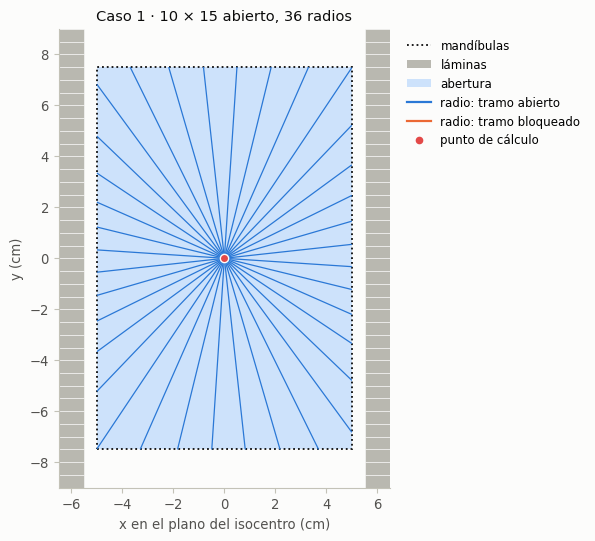

In [27]:
empezar_celda("caso 1, segunda parte")        # borra las filas que esta celda dejó en una corrida anterior
# El haz del caso 1 con las mandíbulas X e Y intercambiadas y las láminas abiertas para la abertura nueva; el mismo punto,
# la misma dosis y el mismo maniquí del caso 1
X_1, Y_1 = (haz1["ASYMX"][1] - haz1["ASYMX"][0]) / 10.0, (haz1["ASYMY"][1] - haz1["ASYMY"][0]) / 10.0
nombre_1b = haz1["BeamName"].replace(f"{X_1:g}×{Y_1:g}", f"{Y_1:g}×{X_1:g}")
nombre_1b = nombre_1b if nombre_1b != haz1["BeamName"] else f"{haz1['BeamName']} (X e Y intercambiadas)"
haz1b = nuevo_haz(haz1["BeamNumber"], nombre_1b, haz1["GantryAngle"], haz1["ASYMY"], haz1["ASYMX"],
                  laminas_desde_forma(np.asarray(haz1["LeafPositionBoundaries"]) / 10.0,
                                      forma_abierta(haz1["ASYMY"][0] / 10.0, haz1["ASYMY"][1] / 10.0)),
                  colimador=haz1["BeamLimitingDeviceAngle"], camilla=haz1["PatientSupportAngle"],
                  isocentro_mm=haz1["IsocenterPosition"], cuna=haz1["Wedge"], bandeja=haz1["BlockTray"],
                  limites_cm=np.asarray(haz1["LeafPositionBoundaries"]) / 10.0)
plan1b = nuevo_plan("Caso 1 girado", [haz1b], punto_mm=plan1["PuntoReferencia"]["Coordenadas_mm"],
                    nombre_punto=plan1["PuntoReferencia"]["Nombre"], fracciones=plan1["NumberOfFractionsPlanned"])
mostrar_eclipse(planificar(plan1b, maniqui1, modelo, [1.0], 100.0 * haz1["BeamDose"]))
r1b_4ap = calcular_campo(plan1b, plan1b["Beams"][0], datos, maniqui1)
r1b_pev = calcular_campo(plan1b, plan1b["Beams"][0], datos, maniqui1, opciones={"metodo_sc": "PEV"})
registrar_caso("1", f"{r1b_4ap.X_mand:g} × {r1b_4ap.Y_mand:g}, Clarkson, Sc 4A/P", r1b_4ap)
filas = []
for ra, rp in ((r1_clk, r1_pev), (r1b_4ap, r1b_pev)):
    filas.append({"campo X × Y (cm)": f"{ra.X_mand:g} × {ra.Y_mand:g}", "Sc 4A/P": ra.Sc, "Sc PEV": rp.Sc, "UM Eclipse": ra.um_eclipse,
                  "UM indep. (Sc 4A/P)": ra.um_indep, "dif. dosis Sc 4A/P (%)": ra.dif_dosis,
                  "UM indep. (Sc PEV)": rp.um_indep, "dif. dosis Sc PEV (%)": rp.dif_dosis})
abierto1 = not haz1.get("Blocks") and r1_clk.fraccion_bloqueada < 0.005       # el caso 1 es el rectángulo abierto
nota1b = ("" if desvio1 < 0.01 else " (el punto no está en el centro de las mandíbulas del caso 1: con las mandíbulas"
          " intercambiadas queda en otro lugar del campo, y las UM no cambian solo por el Sc)")
imprimir_tabla_formato(pd.DataFrame(filas).set_index("campo X × Y (cm)"),
                       {"UM Eclipse": "{:.1f}", "UM indep. (Sc 4A/P)": "{:.1f}", "UM indep. (Sc PEV)": "{:.1f}",
                        "dif. dosis Sc 4A/P (%)": "{:+.2f}", "dif. dosis Sc PEV (%)": "{:+.2f}"},
                       ("Intercambio del colimador con el campo completo" if abierto1 else
                        "Intercambio del colimador (el campo del caso 1 tiene láminas o bloques dentro de las mandíbulas: la"
                        " segunda fila es el rectángulo abierto de las mandíbulas intercambiadas)") + nota1b + ":")
contra_1 = f"{r1_clk.X_mand:g} × {r1_clk.Y_mand:g} contra {r1b_4ap.X_mand:g} × {r1b_4ap.Y_mand:g}"
print(f"Diferencia {contra_1}: Sc 4A/P: {100 * (r1_clk.Sc / r1b_4ap.Sc - 1):+.2f} %, Sc PEV:"
      f" {100 * (r1_pev.Sc / r1b_pev.Sc - 1):+.2f} %")
dif_sc1b = 100 * (r1b_4ap.Sc / r1b_pev.Sc - 1)
print(f"En el {r1b_4ap.X_mand:g} × {r1b_4ap.Y_mand:g}, el Sc por 4A/P es "
      + segun_signo(dif_sc1b, f"{abs(dif_sc1b):.2f} % mayor que el de vista desde el punto",
                    f"{abs(dif_sc1b):.2f} % menor que el de vista desde el punto", "igual al de vista desde el punto") + ".")
filas = []
rectangulos_1b = ((5, 20), (20, 5))                   # el mismo rectángulo con las mandíbulas intercambiadas
for X, Y in rectangulos_1b:
    fila = {"campo X × Y (cm)": f"{X} × {Y}"}
    for metodo in ("4AP", "PEV", "matriz"):
        fila[f"Sc {metodo}"] = sc_de_mandibulas(datos, X, Y, metodo)[1]
    filas.append(fila)
t = pd.DataFrame(filas).set_index("campo X × Y (cm)")
contra_1b = f"{t.index[0]} contra {t.index[1]}"
imprimir_tabla(t, f"{contra_1b}:")
print(f"Diferencia {contra_1b}: " + ", ".join(f"{c}: {100 * (t[c].iloc[0] / t[c].iloc[1] - 1):+.2f} %" for c in t.columns))
print()
reporte(calcular_plan(plan1, datos, maniqui1), datos)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
dibujar_campo(ax, abertura_desde_haz(haz1, datos), (r1_clk.x_iso, r1_clk.y_iso), r1_clk.clarkson,
              titulo=f"Caso 1 · {r1_clk.X_mand:g} × {r1_clk.Y_mand:g}"
                     f"{' abierto' if r1_clk.fraccion_bloqueada < 0.005 else ''}, {plural(r1_clk.clarkson.n_sectores, 'radio')}")
leyenda_campo(ax, con_bloques=bool(abertura_desde_haz(haz1, datos).bloques))
fig.tight_layout()
plt.show()

### Caso 2 · Campo en L con láminas

**Qué se quiere ver.** Un campo irregular de verdad: mandíbulas de x −4.5 a 10.5 y de y −4.5 a 10.5 cm, y láminas que
dejan una L (x de −4 a 10 cm para y de −4 a 3 cm; x de −4 a 2 cm para y de 3 a 10 cm; el resto cerrado). Punto en el
isocentro (a 4 cm de los bordes izquierdo e inferior, y a 3.6 cm de la esquina interior), 200 cGy, agua plana a SSD 90.
Se comparan: el rectángulo efectivo 12 × 9 cm que un físico dibujaría a mano, el cuadrado 4A/P de la abertura
(10.0 cm), Clarkson con 36 sectores y el planeador. Se usa la **ecuación 1** de la TG-71 con el producto
$[S_p\cdot\mathrm{TMR}\cdot\mathrm{OAR}]$ de Clarkson (el punto está en el isocentro, así que es la **ecuación 2**:
$SPD = SAD$ y OAR = 1). Se eligió porque es el campo irregular típico de láminas, justo lo que Clarkson integra.

**Qué mirar.** Que el Sc va con las mandíbulas (15 × 15), no con la abertura, porque las láminas son terciarias. Que
los tres métodos dan el producto de campo con diferencias de algunas décimas de por ciento; Clarkson es el que integra
la forma real. El planeador además baja un poco el Sc por las láminas (≈ 0.45 %), y eso aparece como diferencia.

In [28]:
empezar_celda("caso 2")        # borra las filas que esta celda dejó en una corrida anterior


def forma_L_caso2(y_centro):
    """La L del caso 2 (cm), dato de este caso: x de −4 a 10 para y de −4 a 3; x de −4 a 2 para y de 3 a 10; el resto cerrado."""
    if -4.0 < y_centro < 3.0:
        return (-4.0, 10.0)
    if 3.0 < y_centro < 10.0:
        return (-4.0, 2.0)
    return None


plan2 = nuevo_plan("Caso 2", [nuevo_haz(1, "AP en L", 0.0, [-45, 105], [-45, 105], laminas_desde_forma(LIMITES, forma_L_caso2))])
haz2 = plan2["Beams"][0]
print("Láminas del caso 2 (pares dentro de las mandíbulas Y):")
resumen_laminas(haz2)
print()
mostrar_eclipse(planificar(plan2, agua_ssd90, modelo, [1.0], 200.0))
rect2 = (12.0, 9.0)                                  # el rectángulo efectivo que dibujaría a mano el físico (cm)
r2_rect = calcular_campo(plan2, haz2, datos, agua_ssd90, opciones={"metodo_campo": "rectangulo_efectivo",
                                                                     "rectangulo": rect2})
r2_4ap = calcular_campo(plan2, haz2, datos, agua_ssd90, opciones={"metodo_campo": "4AP"})
r2_clk = calcular_campo(plan2, haz2, datos, agua_ssd90)
for r in (r2_rect, r2_4ap, r2_clk):
    print(r.desglose)
    print()
pares2 = [(f"rectángulo efectivo {rect2[0]:g} × {rect2[1]:g}", r2_rect), ("4A/P de la abertura", r2_4ap),
          (texto_metodo(r2_clk), r2_clk)]
tabla_metodos(pares2, "Caso 2 · métodos:")
for nombre, r in pares2:
    registrar_caso("2", nombre, r)
print(f"Qué mirar: frente a Clarkson, el rectángulo efectivo da {100 * (r2_rect.sp_tpr_oar / r2_clk.sp_tpr_oar - 1):+.2f} % y"
      f" 4A/P {100 * (r2_4ap.sp_tpr_oar / r2_clk.sp_tpr_oar - 1):+.2f} % en [Sp·TMR·OAR]; Clarkson frente al planeador:"
      f" {r2_clk.dif_dosis:+.2f} % en dosis.")

Láminas del caso 2 (pares dentro de las mandíbulas Y):
    pares con y de   -45.0 a   -40.0 mm: cerrado
    pares con y de   -40.0 a    30.0 mm: X1 =   -40.0 mm, X2 =   100.0 mm
    pares con y de    30.0 a   100.0 mm: X1 =   -40.0 mm, X2 =    20.0 mm
    pares con y de   100.0 a   110.0 mm: cerrado

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
         peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                              
AP en L  1.00  200.00    90.00      10.00  1.0000  1.0140           0.9597   0.6735     0.1392  1.0000  1.0000  1.0000  1.0000        0.7909  252.9

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifra

**Caso 2, segunda parte · Convergencia y aporte de cada sector.** Clarkson con 8, 12, 18, 36, 72, 180, 360 y 720
sectores; el dibujo de los 36 radios (abiertos en azul, bajo láminas en naranja), el gráfico polar del aporte de cada
sector y la convergencia. Al final, el reporte.

**Qué mirar.** Con 36 sectores el resultado ya está dentro de 0.2 % del de 720 (prueba 4). Con 8 sectores el error
depende de dónde caen los pocos radios. En el polar, los sectores que miran a lo largo de los dos brazos de la L
(θ ≈ 0° y θ ≈ 90°) son los que más aportan.

Caso 2 · convergencia de Clarkson:
           SMR medio [Sp·TMR·OAR] diferencia con N = 720 (%)
N sectores                                                  
8             0.1359       0.7793                     +0.117
12            0.1375       0.7809                     +0.324
18            0.1348       0.7783                     -0.016
36            0.1349       0.7784                     -0.001
72            0.1349       0.7784                     +0.003
180           0.1349       0.7784                     -0.001
360           0.1349       0.7784                      0.000
720           0.1349       0.7784                      0.000



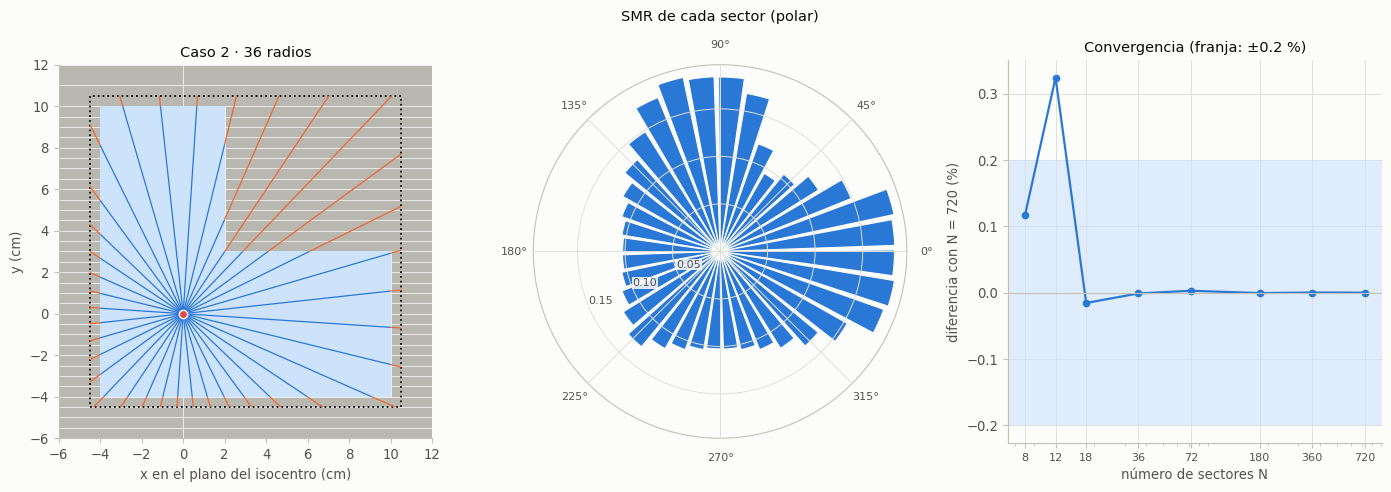

VERIFICACIÓN INDEPENDIENTE DE UM · TG-71 / TG-114
Datos inventados para estudiar el motor; no es un cálculo clínico.
Paciente SIM-0001 · plan «Caso 2» · Clinac simulado · 6 MV (simulado) · posición HFS · 25 fracciones
Punto: Isocentro, (0.0, 0.0, 0.0) mm
Datos de haz con TMR, d0 = 1.50 cm
----------------------------------------------------------------------------------------------------------------
Geometría por campo (d y SPD hasta el plano del punto; s_iso y rd: cuadrado equivalente del campo en el isocentro y en el plano del punto):
        brazo (°) SSD (cm) d (cm) d_ef (cm) SPD (cm) x radial (cm) mandíbulas X × Y (cm) rc (cm)         método s_iso (cm) rd (cm) bloqueado    punto
campo                                                                                                                                                
AP en L       0.0    90.00  10.00     10.00   100.00          0.00         15.00 × 15.00   15.00  Clarkson (36)      10.00   10.00      0.38  abierto

Factor

In [29]:
ab2 = abertura_desde_haz(haz2, datos)
p2 = (r2_clk.x_iso, r2_clk.y_iso)
convergencia = []
for N in (8, 12, 18, 36, 72, 180, 360, 720):
    res = clarkson(datos, ab2, p2, r2_clk.d, r2_clk.f_d, N)
    prod, _ = sp_tpr_clarkson(datos, res, r2_clk.d, r2_clk.OAR, r2_clk.estado_punto)
    convergencia.append((N, res, prod))
prod720 = convergencia[-1][2]
tabla_conv = pd.DataFrame([{"N sectores": N, f"{DISP} medio": res.spr_medio, "[Sp·TMR·OAR]": prod,
                            "diferencia con N = 720 (%)": 100 * (prod / prod720 - 1)} for N, res, prod in convergencia])
imprimir_tabla_formato(tabla_conv.set_index("N sectores"), {"diferencia con N = 720 (%)": "{:+.3f}"},
                       "Caso 2 · convergencia de Clarkson:")
fig = plt.figure(figsize=(14, 4.8))
ax = fig.add_subplot(1, 3, 1)
dibujar_campo(ax, ab2, p2, r2_clk.clarkson, titulo=f"Caso 2 · {plural(r2_clk.clarkson.n_sectores, 'radio')}")
ax = fig.add_subplot(1, 3, 2, projection="polar")
ax.set_axisbelow(False)              # el eje radial y sus etiquetas, por encima de las barras
res36 = r2_clk.clarkson
ax.bar(res36.angulos, res36.aportes, width=2 * np.pi / res36.n_sectores * 0.85, color=COLOR["azul"],
       edgecolor=COLOR["fondo"], lw=0.8)
ax.set_title(f"{DISP} de cada sector (polar)", pad=14)
ax.set_rgrids([0.05, 0.10, 0.15], angle=202.5)
ax.tick_params(labelsize=8)
for etiqueta in ax.get_yticklabels():
    etiqueta.set_bbox({"facecolor": COLOR["fondo"], "edgecolor": "none", "alpha": 0.85, "pad": 0.6})
ax = fig.add_subplot(1, 3, 3)
Ns = [c[0] for c in convergencia]
ax.plot(Ns, [100 * (c[2] / prod720 - 1) for c in convergencia], "o-", color=COLOR["azul"])
ax.axhspan(-0.2, 0.2, color=COLOR["azul_claro"], alpha=0.6, lw=0)
ax.axhline(0, color=COLOR["eje"], lw=0.8)
ax.set_xscale("log")
ax.set_xticks(Ns)
ax.set_xticklabels([str(n) for n in Ns], fontsize=8)
ax.set(title="Convergencia (franja: ±0.2 %)", xlabel="número de sectores N", ylabel="diferencia con N = 720 (%)")
fig.tight_layout()
plt.show()
reporte(calcular_plan(plan2, datos, agua_ssd90), datos)

### Caso 3 · 20 × 20 cm con bloque central en bandeja y punto fuera del eje

**Qué se quiere ver.** Mandíbulas ±100 mm, láminas abiertas y un bloque de cerrobend en bandeja que tapa una franja
central de 3 cm de ancho (x de −15 a 15 mm, y de −100 a 100 mm). El punto está en el haz en (6, 2) cm (paciente:
(60, 0, 20) mm), en el plano del isocentro. 200 cGy, agua plana a SSD 90. Se compara Clarkson con el 4A/P de la
abertura y con el rectángulo efectivo de la mitad donde está el punto (8.5 × 20 cm). Se usa la **ecuación 1** de la
TG-71 con el punto fuera del eje: $SPD$ = 100 cm (el punto está en el plano del isocentro; la distancia oblicua no
entra) y $\mathrm{OAR}(d,x)$, con el producto $[S_p\cdot\mathrm{TMR}\cdot\mathrm{OAR}]$ de Clarkson y el TF de la
bandeja. Se eligió porque es el caso típico de un bloque que parte el campo: un cuadrado equivalente no ve la
dispersión que llega al punto desde la otra mitad abierta del campo, más allá del bloque.

**Qué mirar.** Dos sectores desarmados: uno que solo cruza campo abierto y uno abierto → bloque → abierto (la
dispersión de la otra mitad sí llega al punto; el tramo bajo el bloque no suma). El TF = 0.970 de la bandeja. El OAR
del punto (6.32 cm del eje) va solo sobre la primaria en Clarkson; si se pusiera sobre todo el producto, como hace
4A/P, la dosis por UM subiría 0.44 %: con un perfil realista el OAR sí pesa. Con
`incluir_transmision=True` se suma además el 3 % de transmisión del bloque, que el planeador sí incluye.

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
                     peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                                          
AP 20×20 con bloque  1.00  200.00    90.00      10.00  1.0000  1.0319           0.9597   0.6895     0.1628  1.0000  0.9700  1.0000  1.0000        0.8187  244.3

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP 20×20 con bloque · ecuación 1 de la TG-71 con Clarkson de 36 sectores (TMR, d0 = dmax)
  Geometría    : SSD del eje = 90.00 cm (plan: 90.00 cm); d = 10.00 cm en la dirección del eje (a lo largo del rayo: 10.02 cm

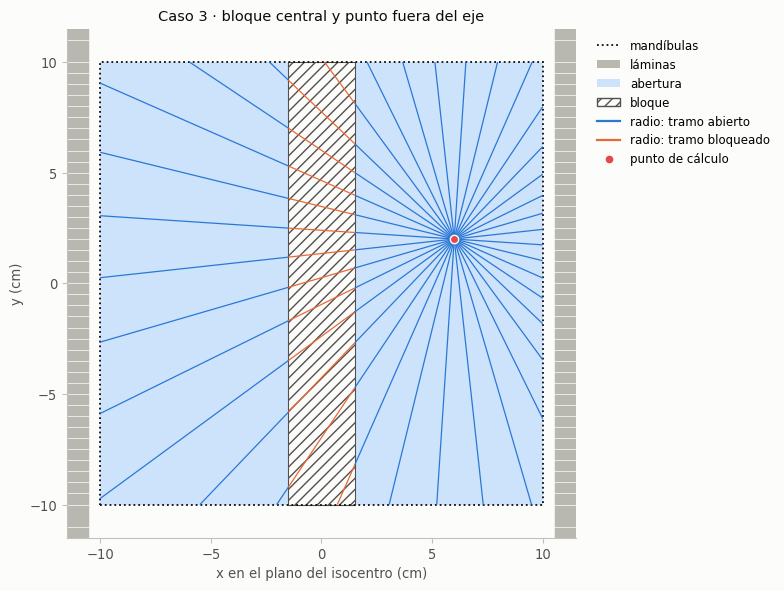

In [30]:
empezar_celda("caso 3")        # borra las filas que esta celda dejó en una corrida anterior
bloque_3 = {"BlockName": "bloque central", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
            "BlockData": [[-15.0, -100.0], [15.0, -100.0], [15.0, 100.0], [-15.0, 100.0]]}
plan3 = nuevo_plan("Caso 3", [nuevo_haz(1, "AP 20×20 con bloque", 0.0, [-100, 100], [-100, 100],
                                        laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)), bandeja=True,
                                        bloques=[bloque_3])],
                   punto_mm=(60.0, 0.0, 20.0), nombre_punto="Punto fuera del eje, (6, 2) cm en el haz")
haz3 = plan3["Beams"][0]
mostrar_eclipse(planificar(plan3, agua_ssd90, modelo, [1.0], 200.0))
r3_clk = calcular_campo(plan3, haz3, datos, agua_ssd90)
r3_tr = calcular_campo(plan3, haz3, datos, agua_ssd90, opciones={"incluir_transmision": True})
r3_4ap = calcular_campo(plan3, haz3, datos, agua_ssd90, opciones={"metodo_campo": "4AP"})
# El rectángulo efectivo de la parte abierta donde está el punto, sacado del bloque y de las mandíbulas del haz
ab3 = abertura_desde_haz(haz3, datos)
x1_3, x2_3, y1_3, y2_3 = ab3.mandibulas
if len(ab3.bloques) == 1:                                          # un solo bloque: ¿es una franja que cruza el campo?
    bx3, by3 = ab3.bloques[0].T
    izq3, der3 = float(bx3.min()) - x1_3, x2_3 - float(bx3.max())  # anchos abiertos a cada lado del bloque (cm)
    cruza3 = by3.min() <= y1_3 + 1e-9 and by3.max() >= y2_3 - 1e-9 and min(izq3, der3) >= 0
    area3 = abs(r3_clk.area_abierta - (izq3 + der3) * (y2_3 - y1_3)) <= 0.005 * r3_clk.area_abierta
else:
    izq3 = der3 = 0.0
    cruza3 = area3 = False
franja3 = cruza3 and area3
lado3 = der3 if franja3 and r3_clk.x_iso >= bx3.max() else izq3 if franja3 and r3_clk.x_iso <= bx3.min() else 0.0
mitades3 = franja3 and abs(izq3 - der3) < 0.01                     # bloque centrado: dos mitades iguales
rect3 = (lado3, y2_3 - y1_3) if lado3 > 0 else None
r3_rect = None if rect3 is None else calcular_campo(plan3, haz3, datos, agua_ssd90,
                                                    opciones={"metodo_campo": "rectangulo_efectivo", "rectangulo": rect3})
for r in (r3_clk, r3_4ap, r3_rect):
    if r is not None:
        print(r.desglose)
        print()
tipos3 = [[tipo for _, _, tipo in tramos] for tramos in r3_clk.clarkson.segmentos]
con_bloque3 = [i for i, t in enumerate(tipos3) if t[:3] == ["abierto", "bloque", "abierto"]]
sectores3 = [i for i, t in enumerate(tipos3) if t == ["abierto"]][:1] + con_bloque3[-1:]   # el último con bloque: la
if sectores3:                                                                             # sección 7.1 desarma el primero
    print(f"{'Dos sectores' if len(sectores3) == 2 else 'Un sector'} de Clarkson"
          f" desarmado{'s' if len(sectores3) == 2 else ''} (radios en el plano del punto):")
else:
    print("Ningún radio de Clarkson va solo por campo abierto ni cruza abierto → bloque → abierto.")
for i in sectores3:
    desarmar_sector(datos, r3_clk.clarkson, i, "campo del caso 3")
    print()
det3 = r3_clk.detalles["campo"]
abierto3, t3 = r3_clk.estado_punto == "abierto", r3_clk.nombre_tpr
lugar3 = ESTADO_CORTO[r3_clk.estado_punto]
tp3_f, tp3_v = ("", "") if det3["T_P"] == 1.0 else (" × T_P", f" × {det3['T_P']:.4f}")      # la T_P, como en el desglose
print(f"El OAR del punto: OAR({r3_clk.d:.2f} cm; {r3_clk.x_radial:.2f} cm) = {r3_clk.OAR:.4f}.")
print(f"  Solo sobre la primaria (Clarkson): Sp(0)·[{t3}(d,0)·OAR{tp3_f} + {DISP} medio] = {det3['sp0']:.4f}·[{det3['tpr0']:.4f}"
      f" × {r3_clk.OAR:.4f}{tp3_v} + {det3['spr_medio']:.4f}] = {r3_clk.sp_tpr_oar:.4f}"
      + ("" if not tp3_f else f"   (T_P = {det3['T_P']:.4f}: "
         + (f"sin primaria, el punto está {lugar3})" if r3_clk.estado_punto == "fuera"
            else f"transmisión hasta el punto, {lugar3})")))
if abierto3:
    oar_todo = det3["sp0"] * (det3["tpr0"] + det3["spr_medio"]) * r3_clk.OAR
    print(f"  Sobre todo el producto (como 4A/P): Sp(0)·[{t3}(d,0) + {DISP} medio]·OAR = {det3['sp0']:.4f}·[{det3['tpr0']:.4f}"
          f" + {det3['spr_medio']:.4f}] × {r3_clk.OAR:.4f} = {oar_todo:.4f}  →  {100 * (oar_todo / r3_clk.sp_tpr_oar - 1):+.2f} %")
else:
    primaria3 = ("no tiene primaria (T_P = 0)" if r3_clk.estado_punto == "fuera"
                 else "su primaria entra solo con la transmisión T_P")
    print(f"  Sobre todo el producto (como 4A/P): no se calcula, porque el punto no está abierto ({lugar3}): {primaria3},"
          " y la diferencia mezclaría ese efecto con el de llevar el OAR a la dispersión.")
print()
pares3 = [(texto_metodo(r3_clk), r3_clk), ("Clarkson + transmisión del bloque" if ab3.bloques else "Clarkson + transmisión",
                                           r3_tr), ("4A/P de la abertura", r3_4ap)]
if r3_rect is not None:
    pares3.append((f"rectángulo de la {'mitad' if mitades3 else 'parte abierta del punto'} {rect3[0]:g} × {rect3[1]:g}", r3_rect))
else:
    if not ab3.bloques:
        razon3 = "el campo no tiene bloque"
    elif len(ab3.bloques) > 1:
        razon3 = "el campo tiene más de un bloque"
    elif not cruza3:
        razon3 = "el bloque no es una franja que cruce el campo de lado a lado"
    elif not area3:
        razon3 = "la parte abierta no es la de las mandíbulas menos el bloque (hay láminas dentro del campo)"
    else:
        razon3 = "el punto no queda a un lado del bloque" + ("" if abierto3 else f" (está {lugar3})")
    print(f"El rectángulo de la parte abierta donde está el punto no aplica: {razon3}.\n")
tabla_metodos(pares3, "Caso 3 · métodos:")
for nombre, r in pares3:
    registrar_caso("3", nombre, r)
n3 = r3_clk.clarkson.n_sectores
cruzan3 = [i for i, t in enumerate(tipos3) if "bloque" in t and "abierto" in t[t.index("bloque") + 1:]]
if not ab3.bloques:
    ve3 = f"el campo no tiene bloque: Clarkson integra la dispersión de toda la abertura (rd del punto = {r3_clk.rd_punto:.2f} cm)"
elif not abierto3:                    # el punto bajo el bloque (o bajo las láminas, o fuera de las mandíbulas)
    tipo3 = {"bloque": "bloque", "mlc": "mlc"}.get(r3_clk.estado_punto)
    empiezan3 = sum(1 for t in tipos3 if t and t[0] == tipo3)
    llegan3 = sum(1 for t in tipos3 if "abierto" in t)
    if tipo3 is None:
        inicio3 = ""
    elif empiezan3 == n3:
        inicio3 = ("el único radio de Clarkson empieza ahí" if n3 == 1 else "todos los radios de Clarkson empiezan ahí") + "; "
    else:
        inicio3 = f"{empiezan3} de {plural(n3, 'radio')} de Clarkson {'empieza' if empiezan3 == 1 else 'empiezan'} ahí; "
    if n3 == 1:
        llegan_txt3 = "su único radio llega a una" if llegan3 else "su único radio no llega a ninguna"
    elif llegan3 == 0:
        llegan_txt3 = f"ninguno de los {n3} radios llega a una"
    else:
        llegan_txt3 = f"{llegan3} de {plural(n3, 'radio')} {'llega' if llegan3 == 1 else 'llegan'} a una"
    ve3 = (f"el punto está {lugar3}: {inicio3}Clarkson suma la dispersión de las partes abiertas que"
           f" {'cruza su radio' if n3 == 1 else 'cruzan sus radios'} ({llegan_txt3}), "
           + ("no hay primaria (T_P = 0)" if r3_clk.estado_punto == "fuera"
              else f"la primaria entra solo con la transmisión (T_P = {det3['T_P']:.4f})")
           + f" y el resultado no es válido para verificar (rd del punto ="
           f" {r3_clk.rd_punto:.2f} cm, con el punto como si estuviera abierto)")
elif cruzan3:
    ve3 = (f"Clarkson ve la dispersión que llega desde la otra {'mitad' if mitades3 else 'parte'} abierta del campo, más allá"
           f" del bloque (rd del punto = {r3_clk.rd_punto:.2f} cm)")
else:
    ve3 = f"ningún radio de Clarkson cruza el bloque hacia otra parte abierta del campo (rd del punto = {r3_clk.rd_punto:.2f} cm)"
dif3 = 100 * (r3_4ap.dosis_por_um / r3_clk.dosis_por_um - 1)
if not abierto3:
    sobre_4ap3 = (f"4A/P no ve que el punto está {lugar3} (su producto no lleva la transmisión), así que no se compara con"
                  " Clarkson: en este punto ningún método sirve para verificar")
elif r3_rect is not None and mitades3:
    sobre_4ap3 = (f"4A/P de la abertura completa da lo mismo que la mitad (dos mitades iguales:"
                  f" 4·2A/(2P) = 4A/P = {r3_4ap.s_iso:.2f} cm) y frente a Clarkson da {dif3:+.2f} % en dosis por UM")
elif r3_rect is not None:
    sobre_4ap3 = (f"4A/P de la abertura completa ({r3_4ap.s_iso:.2f} cm) no es el de la parte abierta del punto"
                  f" ({r3_rect.s_iso:.2f} cm), porque las dos partes no son iguales, y frente a Clarkson da {dif3:+.2f} %"
                  " en dosis por UM")
else:
    sobre_4ap3 = f"4A/P de la abertura completa ({r3_4ap.s_iso:.2f} cm) da, frente a Clarkson, {dif3:+.2f} % en dosis por UM"
print(f"Qué mirar: {ve3}; {sobre_4ap3}.")
reporte(calcular_plan(plan3, datos, agua_ssd90), datos)
fig, ax = plt.subplots(figsize=(7.5, 6))
dibujar_campo(ax, abertura_desde_haz(haz3, datos), (r3_clk.x_iso, r3_clk.y_iso), r3_clk.clarkson,
              titulo=(f"Caso 3 · bloque{' central' if mitades3 else ''}" if ab3.bloques else "Caso 3 · sin bloque")
                     + f" y punto {'fuera del eje' if r3_clk.x_radial > 0.01 else 'en el eje'}"
                     + ("" if abierto3 else f", {lugar3}"))
leyenda_campo(ax, con_bloques=bool(ab3.bloques))
fig.tight_layout()
plt.show()

### Caso 4 · Medio haz

**Qué se quiere ver.** Mandíbulas asimétricas ASYMX = [0, 100] mm y ASYMY ±75 mm (un campo de 10 × 15 cm con el borde en
el eje). Punto en el centro del medio haz, a (5, 0) cm (paciente: (50, 0, 0) mm), agua plana a SSD 90, 200 cGy. Se
comparan Clarkson, Day (los cuatro cuadrantes alrededor del punto) y 4A/P (10 × 15 → 12 cm) con OAR(x = 5 cm). Se usa
la **ecuación 1** de la TG-71 con el punto fuera del eje ($SPD$ = 100 cm, porque el punto está en el plano del
isocentro, y el OAR a 5 cm del eje). Se eligió porque en un campo rectangular el método de Day reparte la dispersión
en cuatro cuadrantes por simetría, sin trazar radios: cada cuadrante es ¼ del rectángulo $2a\times 2b$ centrado en el
punto, que se lee con su cuadrado equivalente. Es un método independiente de Clarkson y sirve para comprobarlo.

**Qué mirar.** Que Clarkson y Day coinciden dentro de 0.19 % (la prueba 12 pide menos de 0.5 %). 4A/P ve el mismo
campo de 10 × 15 centrado en el punto, como en el caso 1, pero pone el OAR (+2.0 % a 5 cm del eje y 10 cm de
profundidad) sobre todo el producto: por eso queda 0.54 % por encima de Clarkson en
$[S_p\cdot\mathrm{TMR}\cdot\mathrm{OAR}]$, 0.35 % por llevar el OAR también a la dispersión y el resto (0.19 %) por la
diferencia entre Clarkson y la tabla del cuadrado equivalente en un rectángulo centrado, la misma del caso 1 (allí se
separa en el sesgo de Clarkson y el de la regla 4A/P, que Day comparte). El Sc es el de las mandíbulas, 10 × 15 → 12 cm.

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
              peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                                   
AP medio haz  1.00  200.00    90.00      10.00  1.0000  1.0102           0.9597   0.6871     0.1509  1.0000  1.0000  1.0000  1.0000        0.8125  246.2

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP medio haz · ecuación 1 de la TG-71 con Clarkson de 36 sectores (TMR, d0 = dmax)
  Geometría    : SSD del eje = 90.00 cm (plan: 90.00 cm); d = 10.00 cm en la dirección del eje (a lo largo del rayo: 10.01 cm) [plan + geometría]
       

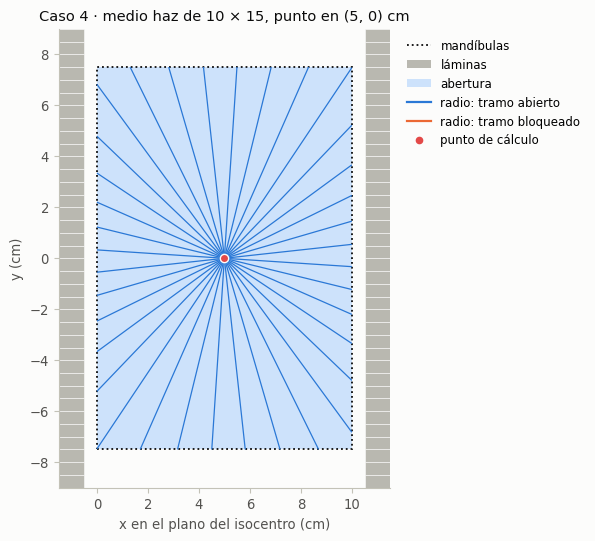

In [31]:
empezar_celda("caso 4")        # borra las filas que esta celda dejó en una corrida anterior
plan4 = nuevo_plan("Caso 4", [nuevo_haz(1, "AP medio haz", 0.0, [0, 100], [-75, 75],
                                        laminas_desde_forma(LIMITES, forma_abierta(0.0, 10.0)))],
                   punto_mm=(50.0, 0.0, 0.0), nombre_punto="Centro del medio haz, (5, 0) cm")
haz4 = plan4["Beams"][0]
mostrar_eclipse(planificar(plan4, agua_ssd90, modelo, [1.0], 200.0))
r4_clk = calcular_campo(plan4, haz4, datos, agua_ssd90)
r4_day = calcular_campo(plan4, haz4, datos, agua_ssd90, opciones={"metodo_campo": "day"})
r4_4ap = calcular_campo(plan4, haz4, datos, agua_ssd90, opciones={"metodo_campo": "4AP"})
for r in (r4_clk, r4_day, r4_4ap):
    print(r.desglose)
    print()
pares4 = [(texto_metodo(r4_clk), r4_clk), ("Day", r4_day), ("4A/P con OAR", r4_4ap)]
tabla_metodos(pares4, "Caso 4 · métodos:")
for nombre, r in pares4:
    registrar_caso("4", nombre, r)
print(f"Qué mirar: en [Sp·TMR·OAR], Day frente a Clarkson {100 * (r4_day.sp_tpr_oar / r4_clk.sp_tpr_oar - 1):+.3f} %;"
      f" 4A/P (con el OAR = {r4_4ap.OAR:.4f} sobre todo el producto) frente a Clarkson"
      f" {100 * (r4_4ap.sp_tpr_oar / r4_clk.sp_tpr_oar - 1):+.3f} %.")
det4 = r4_clk.detalles["campo"]
oar_disp4 = det4["sp0"] * det4["spr_medio"] * (r4_clk.OAR - 1)
resto4 = 100 * (r4_4ap.sp_tpr_oar / r4_clk.sp_tpr_oar - 1) - 100 * oar_disp4 / r4_clk.sp_tpr_oar
x1_4, x2_4, y1_4, y2_4 = abertura_desde_haz(haz4, datos).mandibulas
centrado4 = (abs(r4_clk.x_iso - 0.5 * (x1_4 + x2_4)) < 0.01 and abs(r4_clk.y_iso - 0.5 * (y1_4 + y2_4)) < 0.01
             and r4_clk.fraccion_bloqueada < 0.005)
if centrado4:          # el mismo rectángulo, centrado en un punto del eje: Clarkson frente a la tabla del cuadrado equivalente
    res_c4 = clarkson(datos, abertura_rectangular(r4_clk.X_mand, r4_clk.Y_mand), (0.0, 0.0), r4_clk.d, r4_clk.f_d,
                      r4_clk.clarkson.n_sectores)
    clk_c4 = sp_tpr_clarkson(datos, res_c4, r4_clk.d, 1.0, "abierto")[0]
    rd_c4 = equivalente_rectangulo(r4_clk.X_mand, r4_clk.Y_mand) * r4_clk.f_d
    tabla_c4 = sp_de(datos, rd_c4) * tpr_de(datos, r4_clk.d, rd_c4)
    sobre_resto4 = (f"es la diferencia entre Clarkson y la tabla del cuadrado equivalente en un rectángulo centrado en el"
                    f" punto: en el mismo {r4_clk.X_mand:g} × {r4_clk.Y_mand:g} centrado en un punto del eje, a"
                    f" {r4_clk.d:.2f} cm, la tabla da {100 * (tabla_c4 / clk_c4 - 1):+.2f} % frente a Clarkson (con los datos"
                    f" por omisión es lo que el caso 1 separa en el sesgo de Clarkson y la regla 4A/P; Day lo comparte porque"
                    f" lee cada cuadrante con su cuadrado equivalente)")
else:
    sobre_resto4 = ("mezcla la diferencia entre Clarkson y la tabla del cuadrado equivalente con la asimetría del campo"
                    " alrededor del punto, que no está en el centro de un campo abierto")
print(f"  De eso, llevar el OAR también a la dispersión suma Sp(0)·{DISP} medio·(OAR − 1)/[Sp·TMR·OAR] = {det4['sp0']:.4f} ×"
      f" {det4['spr_medio']:.4f} × {r4_clk.OAR - 1:.4f}/{r4_clk.sp_tpr_oar:.4f} = {100 * oar_disp4 / r4_clk.sp_tpr_oar:+.2f} %;"
      f" el resto, {resto4:+.2f} %, {sobre_resto4}.")
reporte(calcular_plan(plan4, datos, agua_ssd90), datos)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
medio4 = min(abs(x1_4), abs(x2_4), abs(y1_4), abs(y2_4)) < 0.01            # una mandíbula en el eje
dibujar_campo(ax, abertura_desde_haz(haz4, datos), (r4_clk.x_iso, r4_clk.y_iso), r4_clk.clarkson,
              titulo=f"Caso 4 · {'medio haz' if medio4 else 'campo'} de {r4_clk.X_mand:g} × {r4_clk.Y_mand:g}, punto en"
                     f" ({round(r4_clk.x_iso, 2) + 0.0:g}, {round(r4_clk.y_iso, 2) + 0.0:g}) cm")
leyenda_campo(ax, con_bloques=bool(abertura_desde_haz(haz4, datos).bloques))
fig.tight_layout()
plt.show()

### Caso 5 · Cuña física de 30° y punto fuera del eje

**Qué se quiere ver.** Campo de 10 × 10 cm (ASYMX y ASYMY ±50 mm) con la cuña física de 30°, talón hacia +Y. El punto
está a 3 cm hacia el talón, en (0, 3) cm del haz (paciente: (0, 0, 30) mm), agua plana a SSD 90, 200 cGy. Se usa la
**ecuación 1** de la TG-71 con el punto fuera del eje y el factor de cuña $\mathrm{WF}(d, r_d, x)$: el del eje (tabla
por profundidad y campo, como la tabla VI de la TG-71) por el cociente fuera del eje en la dirección del gradiente; el
OAR va con la distancia radial. Se eligió porque la cuña con el punto fuera del eje es, en la columna que usa este
cuaderno (algoritmo diferente, geometría aproximada), la fila de la tabla II de la TG-114 con el nivel más amplio.

**Qué mirar.** El WF del punto, menor que el del eje (hay más espesor de cuña hacia el talón). El argumento de la cuña
es el cuadrado equivalente **del campo** en el plano del punto ($r_d$ = 4A/P × $f_d$ = 10 cm), como pide la TG-71
(tabla VI: «lado del cuadrado equivalente»), no el que Clarkson asigna al punto. Con las reglas de este cuaderno
(sección 9), la categoría de la TG-114 pasa a «campo con cuña o punto fuera del eje».

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
             peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                                  
AP cuña 30°  1.00  200.00    90.00      10.00  1.0000  1.0000           0.9597   0.6827     0.1214  0.5034  1.0000  1.0000  1.0000        0.3885  514.9

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP cuña 30° · ecuación 1 de la TG-71 con Clarkson de 36 sectores (TMR, d0 = dmax)
  Geometría    : SSD del eje = 90.00 cm (plan: 90.00 cm); d = 10.00 cm en la dirección del eje (a lo largo del rayo: 10.00 cm) [plan + geometría]
           

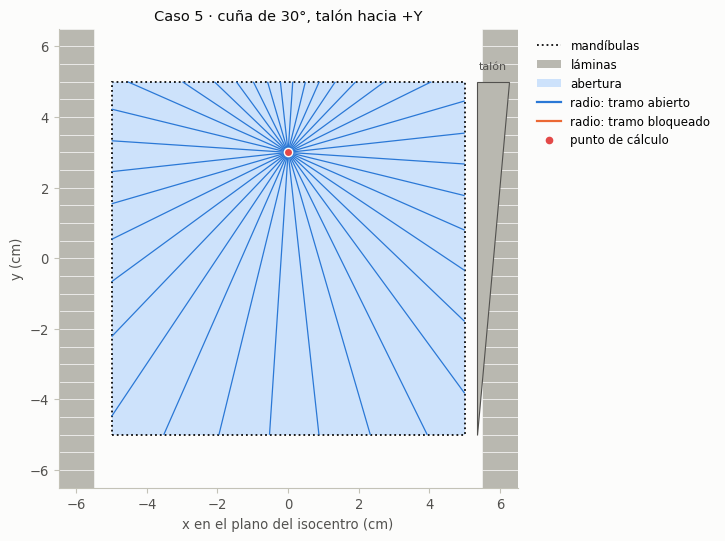

In [32]:
empezar_celda("caso 5")        # borra las filas que esta celda dejó en una corrida anterior
cuna_5 = {"WedgeID": "W30", "WedgeAngle": 30.0, "WedgeType": "STANDARD", "DireccionTalon": "+Y"}
plan5 = nuevo_plan("Caso 5", [nuevo_haz(1, "AP cuña 30°", 0.0, [-50, 50], [-50, 50],
                                        laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)), cuna=cuna_5)],
                   punto_mm=(0.0, 0.0, 30.0), nombre_punto="Punto 3 cm hacia el talón, (0, 3) cm en el haz")
haz5 = plan5["Beams"][0]
mostrar_eclipse(planificar(plan5, agua_ssd90, modelo, [1.0], 200.0))
r5_clk = calcular_campo(plan5, haz5, datos, agua_ssd90)
r5_4ap = calcular_campo(plan5, haz5, datos, agua_ssd90, opciones={"metodo_campo": "4AP"})
for r in (r5_clk, r5_4ap):
    print(r.desglose)
    print()
WF_eje5 = wf(datos, cuna_5, r5_clk.d, r5_clk.rd, 0.0)[0]
xg5 = r5_clk.detalles["wf"]["x_g"]
donde5 = ("en el eje" if abs(xg5) < 0.005 else
          f"{abs(xg5):.2f} cm hacia {'el talón' if xg5 > 0 else 'la punta'} de la cuña")
print(f"WF en el eje = WF({r5_clk.d:.2f} cm; {r5_clk.rd:.2f} cm) = {WF_eje5:.4f}; en el punto (x_g ="
      f" {xg5:.2f} cm) = {r5_clk.WF:.4f} → {100 * (r5_clk.WF / WF_eje5 - 1):+.2f} % por estar {donde5}")
print(f"Argumento de la cuña: rd del campo = {r5_clk.rd:.2f} cm (el rd que Clarkson asigna al punto,"
      f" {r5_clk.rd_punto:.2f} cm, queda solo como dato)")
pares5 = [(texto_metodo(r5_clk), r5_clk), ("4A/P", r5_4ap)]
tabla_metodos(pares5, "Caso 5 · métodos:")
for nombre, r in pares5:
    registrar_caso("5", nombre, r)
reporte(calcular_plan(plan5, datos, agua_ssd90), datos)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ab5 = abertura_desde_haz(haz5, datos)
talon5 = cuna_5["DireccionTalon"].replace("−", "-").upper()
dibujar_campo(ax, ab5, (r5_clk.x_iso, r5_clk.y_iso), r5_clk.clarkson,
              titulo=f"Caso 5 · cuña de {cuna_5['WedgeAngle']:g}°, talón hacia {cuna_5['DireccionTalon']}")
x1_5, x2_5, y1_5, y2_5 = ab5.mandibulas
if talon5 in ("+Y", "-Y"):          # la cuña dibujada a la derecha del campo, gruesa del lado del talón
    yt5, yp5 = (y2_5, y1_5) if talon5 == "+Y" else (y1_5, y2_5)
    cuna_dibujo5 = [[x2_5 + 0.35, yp5], [x2_5 + 0.35, yt5], [x2_5 + 1.25, yt5]]
    texto5 = (x2_5 + 0.8, yt5 + (0.3 if talon5 == "+Y" else -0.3), "bottom" if talon5 == "+Y" else "top")
else:                               # la cuña dibujada debajo del campo
    xt5, xp5 = (x2_5, x1_5) if talon5 == "+X" else (x1_5, x2_5)
    cuna_dibujo5 = [[xp5, y1_5 - 0.35], [xt5, y1_5 - 0.35], [xt5, y1_5 - 1.25]]
    texto5 = (xt5, y1_5 - 1.3, "top")
ax.add_patch(Polygon(cuna_dibujo5, closed=True, facecolor=COLOR["gris_laminas"], edgecolor=COLOR["tinta_2"], lw=0.8))
ax.text(texto5[0], texto5[1], "talón", ha="center", va=texto5[2], fontsize=8, color=COLOR["tinta_2"])
leyenda_campo(ax, con_bloques=bool(ab5.bloques))
fig.tight_layout()
plt.show()

### Caso 6 · Caja de cuatro campos en una pelvis elíptica

**Qué se quiere ver.** Una pelvis elíptica de 36 × 22 cm (semiejes 18 cm lateral y 11 cm AP) centrada en el
isocentro. AP (0°) y PA (180°): mandíbulas ±80 × ±80 mm y láminas con semiancho $w(y) = 8 - \max(0, |y| - 5)$ cm
(esquinas recortadas; cerrado si $|y| \ge 8$). Laterales izquierdo (90°) y derecho (270°): mandíbulas X ±60 y Y ±80 mm,
láminas de −6 a 6 cm salvo los pares con y < −4 cm, que van de −6 a 3 cm. Pesos 0.30, 0.30, 0.20 y 0.20; 180 cGy en el
isocentro. Se usa la **ecuación 1** de la TG-71 con Clarkson en cada campo (el punto es el isocentro, así que en cada
uno es la **ecuación 2**) y se suma la dosis de los cuatro en el punto: la TG-114 prefiere un punto común a todos los
campos del plan, aunque no lo exige (presentación del TG-114 en la AAPM, Stern y col., 2013). Se eligió porque es el
plan clásico de pelvis: profundidades distintas por campo y un contorno que no es plano.

**Qué mirar.** Profundidades de 11 cm (AP y PA) y 18 cm (laterales), con SSD de 89 y 82 cm que el motor recalcula y
compara con las del plan. El total en el punto suma las cuatro contribuciones con las UM del planeador.

In [33]:
empezar_celda("caso 6")        # borra las filas que esta celda dejó en una corrida anterior


def forma_ap_pa(y_centro):
    """Semiancho w(y) = 8 − max(0, |y| − 5) cm; par cerrado si |y| ≥ 8 cm."""
    if abs(y_centro) >= 8.0:
        return None
    w = 8.0 - max(0.0, abs(y_centro) - 5.0)
    return (-w, w)


def forma_lateral(y_centro):
    """De −6 a 6 cm, salvo los pares con y < −4 cm, de −6 a 3 cm."""
    return (-6.0, 3.0) if y_centro < -4.0 else (-6.0, 6.0)


mlc_ap_pa = laminas_desde_forma(LIMITES, forma_ap_pa)
mlc_lat = laminas_desde_forma(LIMITES, forma_lateral)
plan6 = nuevo_plan("Caso 6", [nuevo_haz(1, "AP", 0.0, [-80, 80], [-80, 80], mlc_ap_pa),
                              nuevo_haz(2, "PA", 180.0, [-80, 80], [-80, 80], mlc_ap_pa),
                              nuevo_haz(3, "LAT IZQ", 90.0, [-60, 60], [-80, 80], mlc_lat),
                              nuevo_haz(4, "LAT DER", 270.0, [-60, 60], [-80, 80], mlc_lat)])
mostrar_eclipse(planificar(plan6, pelvis, modelo, [0.30, 0.30, 0.20, 0.20], 180.0))
calc6 = calcular_plan(plan6, datos, pelvis)
for r in calc6["resultados"]:
    print(r.desglose)
    print()
    registrar_caso("6", texto_metodo(r), r)
reporte(calc6, datos)

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
         peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)    UM
campo                                                                                                                                             
AP       0.30   54.00    89.00      11.00  1.0000  1.0208           0.9597   0.6429     0.1776  1.0000  1.0000  1.0000  1.0000        0.8038  67.2
PA       0.30   54.00    89.00      11.00  1.0000  1.0208           0.9597   0.6429     0.1776  1.0000  1.0000  1.0000  1.0000        0.8038  67.2
LAT IZQ  0.20   36.00    82.00      18.00  1.0000  1.0151           0.9597   0.4643     0.1618  1.0000  1.0000  1.0000  1.0000        0.6099  59.0
LAT DER  0.20   36.00    82.00      18.00  1.0000  1.0151           0.9597   0.4643     0.1618  1.0000  1.0000  1.0000  1.0000        0.6099  59.0

  D/UM = D'0 × Sc × Sp(0) del m

**Caso 6, dibujo.** Corte axial visto desde los pies (izquierda del paciente a la derecha del dibujo, anterior arriba)
con los cuatro haces, y la vista desde la fuente de cada abertura con sus radios de Clarkson.

**Qué mirar.** Las esquinas recortadas por las láminas en AP y PA, y el recorte de los laterales en y < −4 cm.

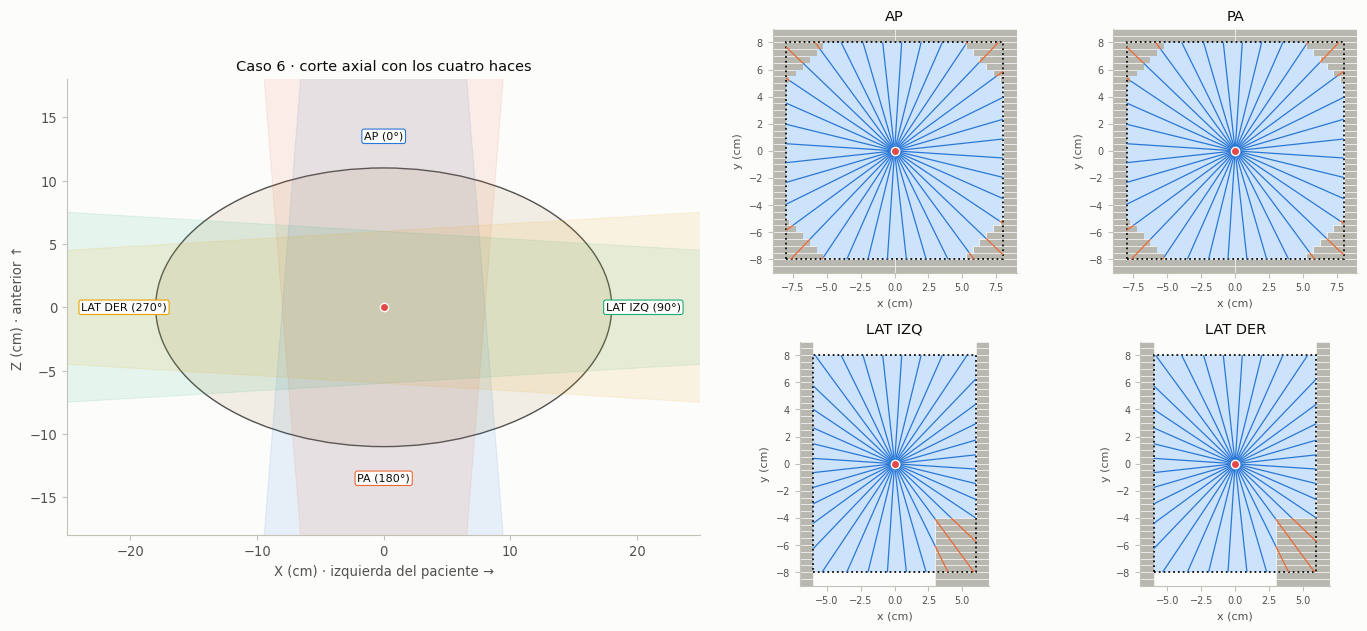

In [34]:
def dibujar_axial(ax, maniqui, plan, titulo="", limites_xz=(-25.0, 25.0, -18.0, 18.0), colores=None):
    """Corte axial (X lateral, Z anteroposterior; vista desde los pies) con el contorno, las heterogeneidades y los haces."""
    e = maniqui.cuerpo
    ax.add_patch(ParcheElipse((e.cx, e.cz), 2 * e.a, 2 * e.b, facecolor="#f1ede4", edgecolor=COLOR["tinta_2"], lw=1.0))
    for h in maniqui.inhomogeneidades:
        pulmon = h.rho < UMBRAL_PULMON
        ax.add_patch(ParcheElipse((h.cx, h.cz), 2 * h.a, 2 * h.b, facecolor="#fde7da" if pulmon else "#d9d6cc",
                                  edgecolor=COLOR["naranja"] if pulmon else COLOR["tinta_2"], lw=0.8))
        ax.text(h.cx, h.cz - h.b - 0.6, f"{h.nombre} (ρ = {h.rho:.2f})", ha="center", va="top", fontsize=7.5,
                color=COLOR["tinta_2"])
    for k, haz in enumerate(plan["Beams"]):
        th = math.radians(haz["GantryAngle"])
        iso = np.asarray(haz["IsocenterPosition"], dtype=float) / 10.0
        c = np.array([iso[0], -iso[1]])                     # (X, Z) del isocentro
        hacia_fuente = np.array([math.sin(th), math.cos(th)])
        S = c + 100.0 * hacia_fuente
        eje_x = np.array([math.cos(th), -math.sin(th)])     # eje x del colimador (colimador en 0°)
        lejos = []
        for xe in (haz["ASYMX"][0] / 10.0, haz["ASYMX"][1] / 10.0):
            v = (c + xe * eje_x - S) / np.linalg.norm(c + xe * eje_x - S)
            lejos.append(S + 140.0 * v)
        col = (colores or SERIES)[k % len(colores or SERIES)]
        ax.add_patch(Polygon([S, lejos[0], lejos[1]], closed=True, facecolor=col, alpha=0.10, edgecolor=col, lw=0.8))
        t_in = entrada_en_maniqui(maniqui, np.array([S[0], 0.0, S[1]]), np.array([-hacia_fuente[0], 0.0, -hacia_fuente[1]]))
        etiqueta = S - (t_in - 2.5) * hacia_fuente
        ax.text(etiqueta[0], etiqueta[1], f"{haz['BeamName']} ({haz['GantryAngle']:g}°)", ha="center", va="center",
                fontsize=8, color=COLOR["tinta"], bbox={"boxstyle": "round,pad=0.2", "fc": COLOR["fondo"], "ec": col, "lw": 0.8})
    p = np.asarray(plan["PuntoReferencia"]["Coordenadas_mm"], dtype=float) / 10.0
    ax.plot(p[0], -p[1], "o", color=COLOR["rojo"], ms=6, markeredgecolor=COLOR["fondo"], zorder=5)
    ax.set_xlim(limites_xz[0], limites_xz[1])
    ax.set_ylim(limites_xz[2], limites_xz[3])
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set(title=titulo, xlabel="X (cm) · izquierda del paciente →", ylabel="Z (cm) · anterior ↑")


n6 = len(plan6["Beams"])
filas6 = max(2, math.ceil(n6 / 2))                    # dos dibujos de abertura por fila
fig = plt.figure(figsize=(14, 3.2 * filas6))
rejilla = fig.add_gridspec(filas6, 4)
dibujar_axial(fig.add_subplot(rejilla[:, :2]), pelvis, plan6,
              f"Caso 6 · corte axial con {'los ' + en_letras(n6) + ' haces' if n6 > 1 else 'su haz'}")
for k, (haz, r) in enumerate(zip(plan6["Beams"], calc6["resultados"])):
    ax = fig.add_subplot(rejilla[k // 2, 2 + k % 2])
    dibujar_campo(ax, abertura_desde_haz(haz, datos), (r.x_iso, r.y_iso), r.clarkson, titulo=f"{haz['BeamName']}",
                  margen=1.0)
    ax.set_xlabel("x (cm)", fontsize=8)
    ax.set_ylabel("y (cm)", fontsize=8)
    ax.tick_params(labelsize=7)
fig.tight_layout()
plt.show()

### Caso 7 · Pulmón: sin corrección, profundidad efectiva y Batho

**Qué se quiere ver.** Un tórax elíptico (semiejes 16 y 10 cm) con dos pulmones (elipses centradas en ±7.5 y 0.5 cm,
semiejes 5.5 y 7.0 cm, ρ = 0.25) y un tumor de 1.8 cm de radio (ρ = 1.0) en el pulmón izquierdo, centrado en (7.0,
2.0) cm. El isocentro está en el centro del tumor: paciente (70, −20, 0) mm. Dos campos de 6 × 6 cm con láminas
abiertas, AP (0°) y lateral izquierdo (90°), pesos 0.5 y 0.5, 200 cGy. El planeador simulado corrige por
heterogeneidad; el motor se corre con `"ninguna"`, `"profundidad_efectiva"` (ecuación 7) y `"batho"` (ecuación 8,
aplicada por capas), y se usa la tabla III de la TG-114. Se usa la **ecuación 1** de la TG-71 con Clarkson y el
factor de corrección por heterogeneidad CF de la **ecuación 5**. Se eligió porque el pulmón es donde una calculadora
en agua se aparta más del planeador, y donde la tabla III de la TG-114 da su nivel de acción más amplio («campo
pequeño o heterogeneidad de baja densidad»).

**Qué mirar.** Sin corrección, el motor subestima la dosis por UM en 8.3 % (AP) y 9.5 % (lateral), −8.9 % en el
total: calcula a la profundidad física, como si el rayo cruzara solo agua, y el veredicto es «Investigar». Con la
profundidad efectiva el total queda en +1.25 %, y con Batho por capas en −0.03 %; esto último es en parte casualidad
de este modelo: el CF de Batho sale menor que el de la ecuación 7 y compensa el desequilibrio lateral del pulmón
($F_{lat}$ = 0.988 en el AP y 0.986 en el lateral), que el planeador incluye y ningún método de tablas modela. Aquí
cada rayo cruza una sola capa de pulmón; la prueba 15 muestra un haz que cruza dos.

In [35]:
empezar_celda("caso 7")        # borra las filas que esta celda dejó en una corrida anterior
iso7 = (70.0, -20.0, 0.0)
mlc_7 = laminas_desde_forma(LIMITES, forma_abierta(-3.0, 3.0))
plan7 = nuevo_plan("Caso 7", [nuevo_haz(1, "AP", 0.0, [-30, 30], [-30, 30], mlc_7, isocentro_mm=iso7),
                              nuevo_haz(2, "LAT IZQ", 90.0, [-30, 30], [-30, 30], mlc_7, isocentro_mm=iso7)],
                   punto_mm=iso7, nombre_punto="Isocentro (centro del tumor)")
mostrar_eclipse(planificar(plan7, torax, modelo, [0.5, 0.5], 200.0))
calc7 = {het: calcular_plan(plan7, datos, torax, {"heterogeneidad": het})
         for het in ("ninguna", "profundidad_efectiva", "batho")}
for het, calc in calc7.items():
    for r in calc["resultados"]:
        print(r.desglose)
        print()
        registrar_caso("7", {"ninguna": "Clarkson, sin corrección", "profundidad_efectiva": "Clarkson + ec. 7",
                             "batho": "Clarkson + Batho por capas (ec. 8)"}[het], r)
opciones7 = "la opción" if len(calc7) == 1 else f"las {en_letras(len(calc7))} opciones"
filas = []
for het, calc in calc7.items():
    for r in calc["resultados"]:
        filas.append({"corrección": het, "campo": r.nombre, "d (cm)": r.d, "d_ef (cm)": r.d_ef, "CF": r.CF,
                      "D/UM (cGy/UM)": r.dosis_por_um, "UM indep.": r.um_indep, "UM Eclipse": r.um_eclipse,
                      "dif. dosis (%)": r.dif_dosis})
    filas.append({"corrección": het, "campo": "TOTAL", "dif. dosis (%)": calc["comparacion"]["dif_total"]})
imprimir_tabla_formato(pd.DataFrame(filas).set_index(["corrección", "campo"]),
                       {"d (cm)": "{:.2f}", "d_ef (cm)": "{:.2f}", "UM indep.": "{:.1f}", "UM Eclipse": "{:.1f}",
                        "dif. dosis (%)": "{:+.2f}"}, f"Caso 7 · {opciones7} de heterogeneidad:")
# Entre opciones solo cambia el CF (Sc, [Sp·TMR·OAR], WF, TF e ISL son los mismos): D/UM ÷ CF es la misma en cada campo
sin_cf7 = {}
for calc in calc7.values():
    for r in calc["resultados"]:
        sin_cf7.setdefault(r.nombre, []).append(r.dosis_por_um / r.CF)
for campo, valores in sin_cf7.items():
    assert all(math.isclose(v, valores[0], rel_tol=1e-9) for v in valores), (
        f"Caso 7, {campo}: la D/UM de las opciones no es la misma D/UM sin corrección por su CF")
print(f"  D/UM = (D/UM sin corrección) × CF; la D/UM sin corrección es la misma con {opciones7}: "
      + "; ".join(f"{c}: {v[0]:.4f} cGy/UM" for c, v in sin_cf7.items())
      + " (se comprueba con todas las cifras; con las cifras impresas, hasta el redondeo de la última).")
for het, calc in calc7.items():
    print(f"\nCorrección por heterogeneidad del motor: «{het}»")
    reporte(calc, datos)

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
         peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                              
AP       0.50  100.00    93.01       4.24  1.0000  0.9765           0.9597   0.8806     0.0672  1.0000  1.0000  0.9877  1.0000        0.8772  114.0
LAT IZQ  0.50  100.00    91.32       5.63  1.0000  0.9765           0.9597   0.8254     0.0778  1.0000  1.0000  0.9864  1.0000        0.8349  119.8

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP · ecuación 1 de la TG-71 con Clarkson de 36 sectores (TMR, d0 = dmax) · punto en el isocentro: es la

**Caso 7, dibujo.** Corte axial con los dos haces y, sobre el eje de cada uno, los tramos de densidad que recorre el
rayo hasta el punto: tejido (ρ = 1) en azul y pulmón (ρ = 0.25) en naranja. A la derecha, las dos aberturas de 6 × 6 cm
con sus radios de Clarkson.

**Qué mirar.** El rayo AP cruza ≈ 3.7 cm de pulmón y el lateral ≈ 4.1 cm; por eso la profundidad efectiva es 2.8 y
3.1 cm menor que la física.

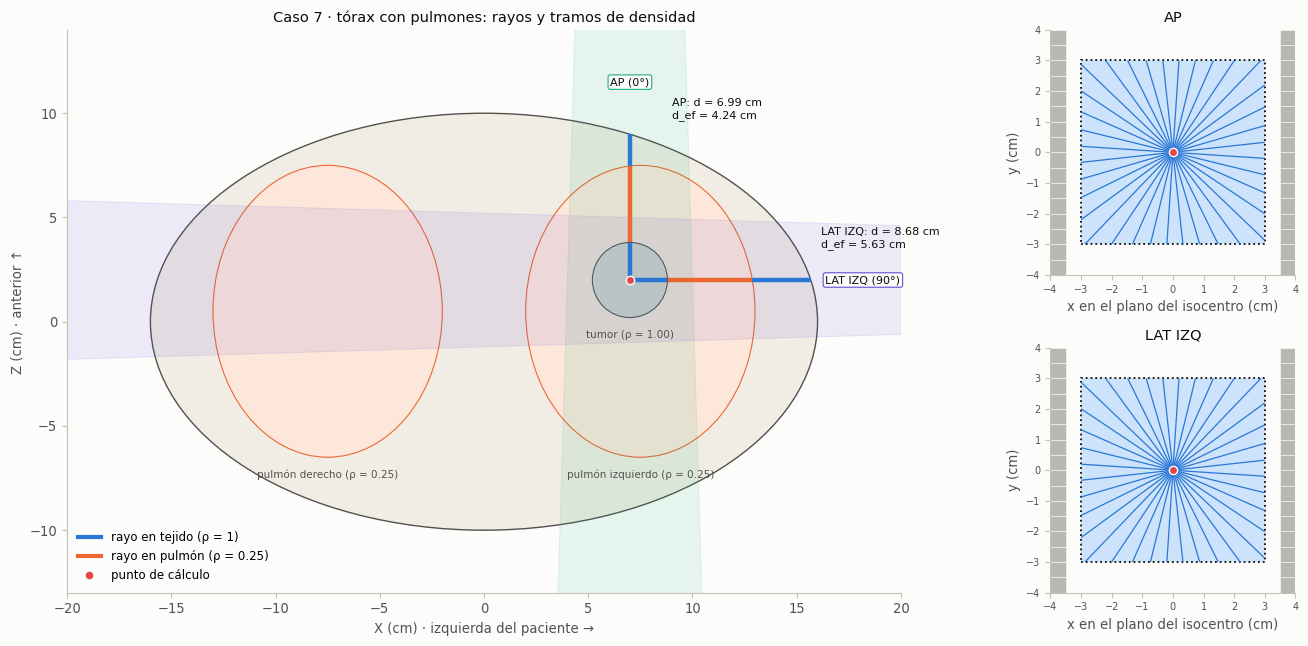

In [36]:
fig = plt.figure(figsize=(14, 6.5))
rejilla = fig.add_gridspec(2, 3)
ax = fig.add_subplot(rejilla[:, :2])
dibujar_axial(ax, torax, plan7, "Caso 7 · tórax con pulmones: rayos y tramos de densidad", (-20.0, 20.0, -13.0, 14.0),
              colores=[COLOR["aguamarina"], COLOR["violeta"]])
calc_dibujo7 = calc7.get("profundidad_efectiva") or next(iter(calc7.values()))     # Clarkson es el mismo en todas
for k, (haz, r) in enumerate(zip(plan7["Beams"], calc_dibujo7["resultados"])):
    ax_bev = fig.add_subplot(rejilla[k, 2])
    dibujar_campo(ax_bev, abertura_desde_haz(haz, datos), (r.x_iso, r.y_iso), r.clarkson, titulo=haz["BeamName"], margen=1.0)
    ax_bev.tick_params(labelsize=7)
densidades7 = {"tejido": set(), "pulmón": set()}       # las densidades que cruzan los rayos dibujados, para la leyenda
for haz in plan7["Beams"]:
    geo = paciente_a_haz(iso7, haz["IsocenterPosition"], "HFS", haz["GantryAngle"], 0.0, 0.0)
    pr = profundidades_en_maniqui(torax, geo["fuente"], geo["punto"], geo["eje"])
    X = geo["fuente"][0] + pr["t"] * pr["u"][0]
    Z = geo["fuente"][2] + pr["t"] * pr["u"][2]
    es_pulmon = (pr["rho"] < UMBRAL_PULMON).astype(int)
    for rho, pulmon in zip(np.round(pr["rho"], 2), es_pulmon):
        densidades7["pulmón" if pulmon else "tejido"].add(float(rho))
    for tramo in np.split(np.arange(len(es_pulmon)), np.nonzero(np.diff(es_pulmon))[0] + 1):
        ax.plot(X[tramo], Z[tramo], lw=3.2, solid_capstyle="butt",
                color=COLOR["naranja"] if es_pulmon[tramo[0]] else COLOR["azul"])
    ax.annotate(f"{haz['BeamName']}: d = {pr['d']:.2f} cm\nd_ef = {pr['d_ef']:.2f} cm", xy=(X[0], Z[0]),
                xytext=(X[0] + (2.0 if haz["GantryAngle"] == 0 else 0.5), Z[0] + (0.8 if haz["GantryAngle"] == 0 else 1.6)),
                fontsize=8, color=COLOR["tinta"])
rho7 = {k: ", ".join(f"{v:g}" for v in sorted(vs)) or "—" for k, vs in densidades7.items()}
ax.legend(handles=[Line2D([], [], color=COLOR["azul"], lw=3, label=f"rayo en tejido (ρ = {rho7['tejido']})"),
                   Line2D([], [], color=COLOR["naranja"], lw=3, label=f"rayo en pulmón (ρ = {rho7['pulmón']})"),
                   Line2D([], [], marker="o", ls="", color=COLOR["rojo"], label="punto de cálculo")], loc="lower left")
fig.tight_layout()
plt.show()

### Caso 8 · SSD fija con bloque de esquina en bandeja (ecuación 3)

**Qué se quiere ver.** Agua plana con la superficie en el isocentro (SSD 100), punto en el eje a 10 cm de profundidad
(paciente (0, 100, 0) mm). Mandíbulas ±100 mm, láminas abiertas y un bloque de esquina en bandeja (x e y de 50 a
100 mm). 200 cGy. Se calcula con la **ecuación 3** (PDD), con el PDD sacado de la TMR (ecuación 16) y con el PDD de la
tabla medida, y se compara con la **ecuación 1** (4A/P y Clarkson). Se eligió porque el tratamiento a SSD fija es
donde se usa la ecuación 3, y así se ve que las dos formulaciones de la TG-71 son la misma física. Al final, la
demostración de Mayneord (ecuaciones 14 y 15) y el mismo campo a SSD 110 con el PDD de la tabla, que el motor corrige
con la ecuación 14.

**Qué mirar.** La ecuación 3 con el PDD de la ecuación 16 da exactamente lo mismo que la ecuación 1 con el mismo campo
(son la misma física escrita de otra forma); con el PDD de la tabla, casi lo mismo. En la demostración de Mayneord, el
factor F pasa el PDD de SSD 100 a SSD 110 con un error de décimas de por ciento, que crece con la profundidad y es menor
en campos grandes. Lo que F desprecia es **sobre todo el cociente de TMR de la ecuación 14** (el campo en profundidad
cambia con la SSD) y, en menor medida, su corchete de Sp, que la TG-71 permite ignorar: la columna de la ecuación 14
sin el corchete queda a unas centésimas de por ciento del exacto. Por eso el motor, cuando la SSD del tratamiento no es
la de la tabla, corrige el PDD medido con la ecuación 14 y no solo con F.

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
            peso D (cGy) SSD (cm) d_tps (cm)     D'0      Sc Sp(0) del modelo primaria dispersión      WF      TF   F_lat     ISL D/UM (cGy/UM)     UM
campo                                                                                                                                                 
AP SSD 100  1.00  200.00   100.00      10.00  1.0000  1.0319           0.9597   0.6735     0.2029  1.0000  0.9700  1.0000  0.8264        0.6957  287.5

  D/UM = D'0 × Sc × Sp(0) del modelo × (primaria + dispersión) × ISL × WF × TF × F_lat; las columnas rehacen la D/UM con todas sus cifras (se comprueba); con las cifras impresas, hasta el redondeo de la última.

Campo AP SSD 100 · ecuación 3 de la TG-71 (PDD, SSD fija) con 4A/P (TMR, d0 = dmax)
  Geometría    : SSD del eje = 100.00 cm (plan: 100.00 cm); d = 10.00 cm en la dirección del eje (a lo largo del rayo: 10.00 cm) [plan + geometría]
                

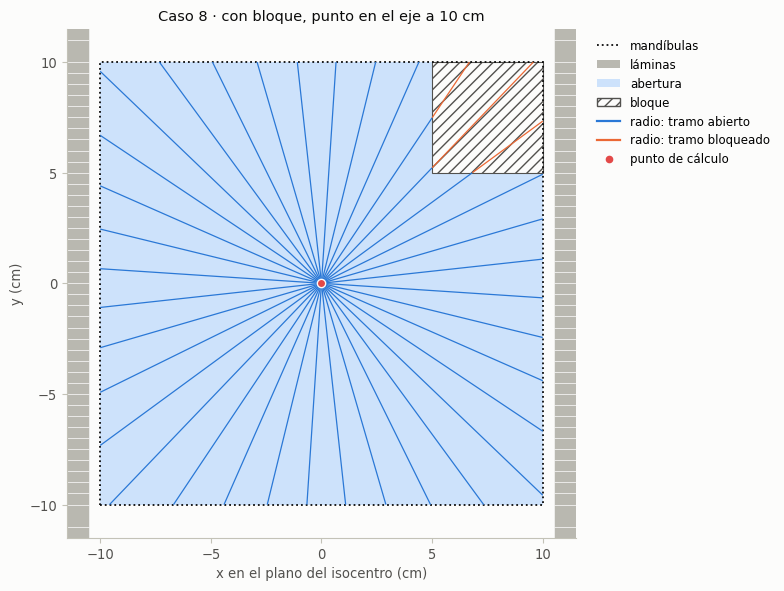

In [37]:
empezar_celda("caso 8")        # borra las filas que esta celda dejó en una corrida anterior
bloque_8 = {"BlockName": "esquina", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
            "BlockData": [[50.0, 50.0], [100.0, 50.0], [100.0, 100.0], [50.0, 100.0]]}
plan8 = nuevo_plan("Caso 8", [nuevo_haz(1, "AP SSD 100", 0.0, [-100, 100], [-100, 100],
                                        laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)), bandeja=True,
                                        bloques=[bloque_8])],
                   punto_mm=(0.0, 100.0, 0.0), nombre_punto="Punto en el eje a 10 cm de profundidad")
haz8 = plan8["Beams"][0]
mostrar_eclipse(planificar(plan8, agua_ssd100, modelo, [1.0], 200.0))
r8_e3_tpr = calcular_campo(plan8, haz8, datos, agua_ssd100, opciones={"metodo_campo": "4AP", "ecuacion": 3, "pdd": "desde_tpr"})
r8_e3_tab = calcular_campo(plan8, haz8, datos, agua_ssd100, opciones={"metodo_campo": "4AP", "ecuacion": 3, "pdd": "tabla"})
r8_e1_4ap = calcular_campo(plan8, haz8, datos, agua_ssd100, opciones={"metodo_campo": "4AP"})
r8_e1_clk = calcular_campo(plan8, haz8, datos, agua_ssd100)
for r in (r8_e3_tpr, r8_e3_tab, r8_e1_4ap, r8_e1_clk):
    print(r.desglose)
    print()
pares8 = [("ec. 3, PDD desde TMR (ec. 16)", r8_e3_tpr), ("ec. 3, PDD de la tabla", r8_e3_tab),
          ("ec. 1, 4A/P", r8_e1_4ap), (f"ec. 1, {texto_metodo(r8_e1_clk)}", r8_e1_clk)]
tabla_metodos(pares8, "Caso 8 · ecuación 3 frente a ecuación 1:")
for nombre, r in pares8:
    registrar_caso("8", nombre, r)
filas = []
ssd_m = 110.0                                        # la SSD a la que se lleva el PDD de la tabla en la demostración
tabla_ssd = f"{datos.ssd_pdd:g}"
for r_sup in (10.0, 30.0):
    for d in (10.0, 20.0):
        exacto = pdd_desde_tpr(datos, d, r_sup, ssd_m)
        aprox = pdd_mayneord(datos, d, r_sup, ssd_m)
        ec14 = pdd_ec14(datos, d, r_sup, ssd_m)
        filas.append({"r (cm)": r_sup, "d (cm)": d, f"PDD a SSD {tabla_ssd}, tabla (%)": pdd_de_tabla(datos, d, r_sup),
                      "F de Mayneord": factor_mayneord(datos, d, ssd_m), f"PDD a SSD {ssd_m:g} con F (%)": aprox,
                      f"PDD a SSD {ssd_m:g}, ec. 14 sin corchete (%)": ec14, f"PDD a SSD {ssd_m:g} exacto, ec. 16 (%)": exacto,
                      "diferencia F (%)": 100 * (aprox / exacto - 1), "diferencia ec. 14 (%)": 100 * (ec14 / exacto - 1)})
tabla_mayneord = pd.DataFrame(filas)
imprimir_tabla_formato(tabla_mayneord.set_index(["r (cm)", "d (cm)"]),
                       {**{c: "{:.2f}" for c in tabla_mayneord.columns if c.startswith("PDD")},
                        "diferencia F (%)": "{:+.2f}", "diferencia ec. 14 (%)": "{:+.3f}"},
                       "Demostración de Mayneord (ecuaciones 14 y 15 frente a la 16; r en la superficie):")
plan8b, haz8b = plan_de_prueba("Caso 8 a SSD 110", dict(haz8, BeamName="AP SSD 110"), (0.0, 200.0, 0.0))
r8b_tab = calcular_campo(plan8b, haz8b, datos, agua_ssd110, opciones={"metodo_campo": "4AP", "ecuacion": 3, "pdd": "tabla"})
r8b_tpr = calcular_campo(plan8b, haz8b, datos, agua_ssd110, opciones={"metodo_campo": "4AP", "ecuacion": 3, "pdd": "desde_tpr"})
r8b_e1 = calcular_campo(plan8b, haz8b, datos, agua_ssd110, opciones={"metodo_campo": "4AP"})
con_ec14 = r8b_tab.detalles["ec3"]["tipo"] == "ec14"
print(f"El mismo campo a SSD {r8b_tab.SSD_eje:.0f} (punto {'en el eje' if r8b_tab.x_radial < 0.01 else 'fuera del eje'} a"
      f" {r8b_tab.d:.0f} cm): con el PDD de la tabla, medida a SSD {tabla_ssd}, "
      + ("el motor lo corrige con la ecuación 14:" if con_ec14 else "el motor la usa tal cual (es la SSD de la tabla):"))
print(r8b_tab.desglose)
print(f"A SSD {r8b_tab.SSD_eje:.0f}: ec. 3 con {'la tabla corregida por la ec. 14' if con_ec14 else 'la tabla'} ="
      f" {r8b_tab.um_indep:.2f} UM; con el PDD de la ec. 16 = {r8b_tpr.um_indep:.2f} UM; ec. 1 = {r8b_e1.um_indep:.2f} UM"
      f" ({100 * (r8b_tab.um_indep / r8b_e1.um_indep - 1):+.3f} % entre la {'ec. 14' if con_ec14 else 'tabla'} y la ec. 1)")
print()
reporte(calcular_plan(plan8, datos, agua_ssd100), datos)
fig, ax = plt.subplots(figsize=(7.5, 6))
dibujar_campo(ax, abertura_desde_haz(haz8, datos), (r8_e1_clk.x_iso, r8_e1_clk.y_iso), r8_e1_clk.clarkson,
              titulo=f"Caso 8 · {'con bloque' if haz8.get('Blocks') else 'sin bloque'}, punto"
                     f" {'en el eje' if r8_e1_clk.x_radial < 0.01 else 'fuera del eje'} a {r8_e1_clk.d:.0f} cm")
leyenda_campo(ax, con_bloques=bool(abertura_desde_haz(haz8, datos).bloques))
fig.tight_layout()
plt.show()

### Caso 9 · Electrones de 9 MeV

**Qué se quiere ver.** Un haz de electrones que entra al motor igual que uno de fotones, desde el plan: el cono de
15 × 15 cm viene en `ApplicatorSequence` (`ApplicatorID` = «A15») y el recorte de 6 × 10 cm como un bloque de tipo
`APERTURE` con su contorno en `BlockData` (mm). El «Eclipse» de electrones llena `SourceToSurfaceDistance`,
`BeamDose` y `BeamMeterset`. El punto está en el eje a dm = 2.1 cm (PDD = 100 %), 200 cGy, en agua plana a SSD 100
(superficie en el isocentro) y a SSD 110 (superficie 10 cm por debajo). A SSD 100 se usan las **ecuaciones 10 y 13**
(Se del rectángulo por la raíz cuadrada). A SSD 110 ($g$ = 10 cm), la **ecuación 11** (SSD efectiva) y la
**ecuación 12** (factor de aire, con la raíz cuadrada de la **ecuación 22**). Se eligió porque reproduce los ejemplos
1 y 2 de electrones de la TG-71 (sección 8.B: recorte de 6 × 10 en el cono de 15 × 15, a SSD 100 y a SSD 110), con
los datos inventados de este cuaderno.

**Qué mirar.** El motor lee el cono y el recorte del plan; la SSD y la profundidad salen de la geometría y se comparan
con las del plan. Los dos métodos de SSD extendida no dan lo mismo (252.4 frente a 251.4 UM, un 0.4 %), como advierte
la TG-71, y el planeador simulado queda dentro de 1 % (+0.29 % a SSD 100; +0.22 % y +0.60 % a SSD 110). El recorte
tapa el 73 % del cono: con la regla de este cuaderno (sección 9: el recorte tapa más del 20 % del cono), el campo cae
en la fila «conformación importante» de la tabla II de la TG-114, con un nivel de 3.5 %.

Haz de electrones del plan (nombres DICOM):
  BeamNumber                 1
  BeamName                   'e⁻ 9 MeV 6×10'
  RadiationType              'ELECTRON'
  NominalBeamEnergy          9.0
  GantryAngle                0.0
  BeamLimitingDeviceAngle    0.0
  PatientSupportAngle        0.0
  IsocenterPosition          [0.0, 0.0, 0.0]
  ApplicatorSequence         [{'ApplicatorID': 'A15', 'ApplicatorType': 'ELECTRON_SQUARE'}]
  Blocks                     [{'BlockName': 'recorte', 'BlockType': 'APERTURE', 'MaterialID': 'cerrobend', 'BlockData': [[-30.0, -50.0], [30.0, -50.0], [30.0, 50.0], [-30.0, 50.0]]}]
  SourceToSurfaceDistance    None
  BeamMeterset               None
  BeamDose                   None

«Eclipse» simulado (mundo simulado; el motor solo verá SSD, BeamDose y BeamMeterset):
              cono (cm)    L × W (cm) D (cGy) SSD (cm) d (cm)     D'0 PDD/100      Se     ISL D/UM (cGy/UM)     UM
campo                                                                               

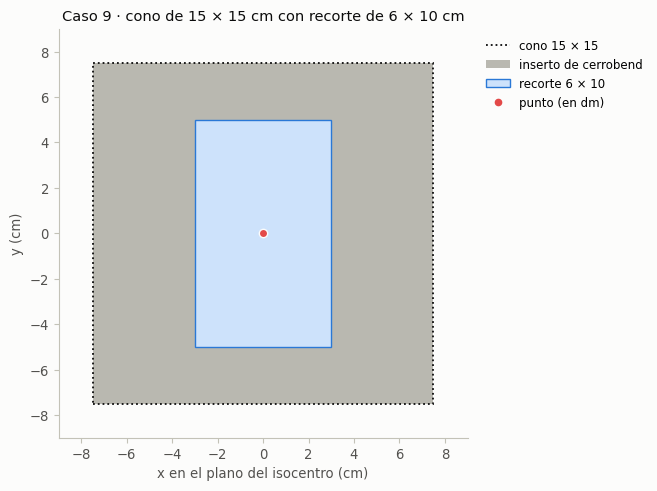

In [38]:
empezar_celda("caso 9")        # borra las filas que esta celda dejó en una corrida anterior
for ssd9, mq9, punto9 in ((100.0, agua_ssd100, (0.0, 21.0, 0.0)), (110.0, agua_ssd110, (0.0, 121.0, 0.0))):
    plan9 = nuevo_plan(f"Caso 9 · SSD {ssd9:.0f}", [nuevo_haz_electrones(1, "e⁻ 9 MeV 6×10", "A15", rectangulo_mm(6.0, 10.0))],
                       punto_mm=punto9, nombre_punto="Punto en el eje a dm = 2.1 cm")
    if ssd9 == 100.0:
        print("Haz de electrones del plan (nombres DICOM):")
        mostrar_haz(plan9["Beams"][0])
        print()
    mostrar_eclipse(planificar_electrones(plan9, mq9, modelo_e, 200.0))
    calc9 = calcular_plan_electrones(plan9, datos_e, mq9)
    reporte_electrones(calc9, datos_e)
    print()
    for h in calc9["resultados"]:
        for metodo in h["resultados"]:
            registrar_caso_electrones("9", h, metodo)
h9 = calc9["resultados"][0]
lect9 = h9["lectura"]                                    # el cono y el recorte que leyó el motor
cono9, L9, W9 = lect9["C"], lect9["L"], lect9["W"]
haz9 = plan9["Beams"][0]
recorte9 = [b for b in haz9.get("Blocks", []) if b.get("BlockType") == "APERTURE"]
c9 = cono9 / 2
contorno9 = (np.asarray(recorte9[0]["BlockData"], dtype=float) / 10.0 if recorte9
             else np.array([[-c9, -c9], [c9, -c9], [c9, c9], [-c9, c9]]))
geo9 = paciente_a_haz(plan9["PuntoReferencia"]["Coordenadas_mm"], haz9["IsocenterPosition"], plan9["PatientPosition"],
                      haz9["GantryAngle"], haz9["BeamLimitingDeviceAngle"], haz9["PatientSupportAngle"], datos_e.SSD0)
fig, ax = plt.subplots(figsize=(7.0, 5.0))
ax.add_patch(Rectangle((-c9, -c9), cono9, cono9, facecolor=COLOR["gris_laminas"], edgecolor="none"))
ax.add_patch(Polygon(contorno9, closed=True, facecolor=COLOR["azul_claro"], edgecolor=COLOR["azul"], lw=1.0))
ax.add_patch(Rectangle((-c9, -c9), cono9, cono9, fill=False, linestyle=":", edgecolor=COLOR["tinta"], lw=1.3))
ax.plot(geo9["x_iso"], geo9["y_iso"], "o", color=COLOR["rojo"], ms=6, markeredgecolor=COLOR["fondo"], zorder=5)
ax.set_xlim(-c9 - 1.5, c9 + 1.5)
ax.set_ylim(-c9 - 1.5, c9 + 1.5)
ax.set_aspect("equal")
ax.grid(False)
ax.set(title=f"Caso 9 · cono de {cono9:g} × {cono9:g} cm con recorte de {L9:g} × {W9:g} cm",
       xlabel="x en el plano del isocentro (cm)", ylabel="y (cm)")
ax.legend(handles=[Line2D([], [], color=COLOR["tinta"], ls=":", lw=1.3, label=f"cono {cono9:g} × {cono9:g}"),
                   Patch(facecolor=COLOR["gris_laminas"], label="inserto de cerrobend"),
                   Patch(facecolor=COLOR["azul_claro"], edgecolor=COLOR["azul"], label=f"recorte {L9:g} × {W9:g}"),
                   Line2D([], [], marker="o", ls="", color=COLOR["rojo"],
                          label="punto (en dm)" if abs(h9["d"] - datos_e.dm) < 0.005 else f"punto (a {h9['d']:.2f} cm)")],
          loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.tight_layout()
plt.show()

### Avisos del motor en acción

**Qué se hace.** Ninguno de los casos anteriores dispara avisos (están bien planteados). Aquí se fuerzan a propósito,
con campos y maniquíes propios de esta celda (copias de los de los casos: cambiar un caso no cambia esta celda), para
ver que cada aviso aparece donde debe:
* un 20 × 20 con bloque central (como el del caso 3) y el punto bajo el bloque → «bajo protección (bajo un bloque)»,
  con Clarkson y con 4A/P;
* un 10 × 10 con un par de láminas cerrado y el punto debajo → «bajo las láminas»; y el punto fuera de las
  mandíbulas → «fuera de las mandíbulas». En esos tres estados el resultado queda marcado como **no válido** para
  verificar, con cualquier método;
* un 10 × 10 con la cuña de 30° (como el del caso 5) y el punto a 0.5 cm del borde → «a menos de 2 cm del borde»;
* un campo de 2 × 2 cm a SSD 125 → Sc fuera de la tabla, punto a menos de 2 cm del borde, campo equivalente menor de
  4 cm y SSD fuera de 80–120 cm (con Clarkson, la dispersión de radios pequeños se lee entre el campo cero y el lado de
  3 cm, sin salirse de la tabla; con 4A/P también saldrían Sp y TMR fuera de la tabla);
* la cuña de 30° en un campo de 25 × 25 cm → «cuña con campo de más de 20 cm»;
* en un tórax como el del caso 7, el punto al borde del tumor → «interfase a menos de 1 cm»;
* el punto dentro del pulmón: sin corrección, el aviso de punto dentro de una heterogeneidad (las ecuaciones 2 y 3 de
  la TG-71 suponen agua homogénea, y sus correcciones no se calculan cerca de una interfase); con Batho, además, que se
  usó la ecuación 7; y Batho en agua sin heterogeneidades (CF = 1);
* un punto a 0.5 cm de profundidad en agua → «a menos de dmax de profundidad» (zona de acumulación); la superficie del
  agua no da el aviso de interfase;
* un punto fuera del maniquí y uno en una cavidad de aire dentro del cuerpo, que el motor rechaza con un error claro.

Al final, el reporte de un plan con el punto bajo el bloque: el veredicto es «no evaluable en este punto».

**Qué mirar.** Que cada cálculo trae su aviso (la celda lo comprueba). Un aviso no detiene el cálculo: le dice al
físico que en esa situación la verificación independiente pierde validez o exactitud; bajo protección o fuera del
campo, además, el número no sirve para verificar.

In [39]:
cuna_av = {"WedgeID": "W30", "WedgeAngle": 30.0, "WedgeType": "STANDARD", "DireccionTalon": "+Y"}
bloque_av = {"BlockName": "bloque central", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
             "BlockData": [[-15.0, -100.0], [15.0, -100.0], [15.0, 100.0], [-15.0, 100.0]]}
agua90_av = Maniqui("plano", z_superficie=10.0, nombre="agua plana a SSD 90")
agua125_av = Maniqui("plano", z_superficie=-25.0, nombre="agua plana con la superficie 25 cm bajo el isocentro (SSD 125 cm)")
pelvis_av = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"), nombre="pelvis elíptica de 36 × 22 cm")
torax_av = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 16.0, 10.0, 1.0, "tórax"),
                   inhomogeneidades=[Elipse(-7.5, 0.5, 5.5, 7.0, 0.25, "pulmón derecho"),
                                     Elipse(7.5, 0.5, 5.5, 7.0, 0.25, "pulmón izquierdo"),
                                     Elipse(7.0, 2.0, 1.8, 1.8, 1.0, "tumor")], nombre="tórax con pulmones")
iso_av = (70.0, -20.0, 0.0)


def haz_bloque_central():
    """20 × 20 con láminas abiertas y un bloque central de 3 cm en bandeja (como el del caso 3)."""
    return nuevo_haz(1, "20×20 con bloque", 0.0, [-100, 100], [-100, 100],
                     laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)), bandeja=True, bloques=[dict(bloque_av)])


haz_10x10_av = nuevo_haz(1, "10×10", 0.0, [-50, 50], [-50, 50], laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)))
haz_par_cerrado_av = nuevo_haz(1, "10×10 con un par cerrado", 0.0, [-50, 50], [-50, 50],
                               laminas_desde_forma(LIMITES, lambda y: None if 2.0 < y < 2.5 else (-5.5, 5.5)))
haz_cuna_av = nuevo_haz(1, "10×10 con cuña", 0.0, [-50, 50], [-50, 50],
                        laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)), cuna=cuna_av)
haz_2x2 = nuevo_haz(1, "2×2", 0.0, [-10, 10], [-10, 10], laminas_desde_forma(LIMITES, forma_abierta(-1.0, 1.0)))
haz_cuna25 = nuevo_haz(1, "cuña 25×25", 0.0, [-125, 125], [-125, 125],
                       laminas_desde_forma(LIMITES, forma_abierta(-12.5, 12.5)), cuna=cuna_av)
haz_torax_av = nuevo_haz(1, "AP 6×6", 0.0, [-30, 30], [-30, 30], laminas_desde_forma(LIMITES, forma_abierta(-3.0, 3.0)),
                         isocentro_mm=iso_av)
avisos_forzados = [      # (qué se fuerza, haz, punto en mm, maniquí, opciones, avisos que tienen que aparecer)
    ("punto bajo el bloque, Clarkson", haz_bloque_central(), (0.0, 0.0, 20.0), agua90_av, {}, ("bajo un bloque",)),
    ("lo mismo con 4A/P", haz_bloque_central(), (0.0, 0.0, 20.0), agua90_av, {"metodo_campo": "4AP"}, ("bajo un bloque",)),
    ("punto bajo un par de láminas cerrado, 4A/P", haz_par_cerrado_av, (0.0, 0.0, 22.5), agua90_av, {"metodo_campo": "4AP"},
     ("bajo las láminas",)),
    ("punto fuera de las mandíbulas, rectángulo efectivo", haz_10x10_av, (70.0, 0.0, 0.0), agua90_av,
     {"metodo_campo": "rectangulo_efectivo", "rectangulo": (10.0, 10.0)}, ("fuera de las mandíbulas",)),
    ("cuña, punto a menos de 2 cm del borde", haz_cuna_av, (0.0, 0.0, 45.0), agua90_av, {}, ("del borde del campo",)),
    ("campo pequeño a una SSD extendida", haz_2x2, (0.0, 350.0, 0.0), agua125_av, {},
     ("Sc:", "del borde del campo", "menor de 4 cm", "fuera de 80–120 cm")),
    ("cuña en un campo de más de 20 cm", haz_cuna25, (0.0, 0.0, 0.0), agua90_av, {}, ("cuña con campo",)),
    ("tórax, punto a menos de 1 cm de una interfase", haz_torax_av, (70.0, -7.0, 0.0), torax_av, {}, ("interfase",)),
    ("punto dentro de una heterogeneidad, sin corrección", haz_torax_av, (70.0, -55.0, 0.0), torax_av, {},
     ("dentro de una heterogeneidad",)),
    ("Batho con el punto dentro de una heterogeneidad", haz_torax_av, (70.0, -55.0, 0.0), torax_av, {"heterogeneidad": "batho"},
     ("no aplica con el punto dentro",)),
    ("Batho sin capas heterogéneas antes del punto", haz_10x10_av, (0.0, 0.0, 0.0), agua90_av, {"heterogeneidad": "batho"},
     ("no hay capas heterogéneas",)),
    ("punto a 0.5 cm de profundidad en agua", haz_10x10_av, (0.0, -95.0, 0.0), agua90_av, {}, ("a menos de dmax",)),
]
for descripcion, haz_base, punto, mq, op, esperados in avisos_forzados:
    plan_p, haz_p = plan_de_prueba("avisos", haz_base, punto)
    r = calcular_campo(plan_p, haz_p, datos, mq, None, op)
    print(f"{descripcion}: campo de {r.X_mand:g} × {r.Y_mand:g} cm, punto en ({r.x_iso:.2f}, {r.y_iso:.2f}) cm del plano del"
          f" isocentro ({ESTADO_CORTO[r.estado_punto]}), SSD = {r.SSD_eje:.2f} cm, d = {r.d:.2f} cm, rd = {r.rd:.2f} cm,"
          f" CF = {r.CF:.4f}, {r.um_indep:.1f} UM para {r.D:.0f} cGy" + ("" if r.valido else " · NO VÁLIDO PARA VERIFICAR"))
    for a in r.avisos:
        print("    aviso:", a)
    for esperado in esperados:
        assert any(esperado in a for a in r.avisos), f"Falta el aviso esperado («{esperado}») en: {descripcion}"
    assert r.valido == (r.estado_punto == "abierto"), f"El resultado debería quedar marcado como no válido en: {descripcion}"
punto_fuera_av = (0.0, 150.0, 0.0)          # mm, por detrás del contorno de la pelvis
error_fuera = ""
try:
    plan_p, haz_p = plan_de_prueba("avisos", haz_10x10_av, punto_fuera_av)
    calcular_campo(plan_p, haz_p, datos, pelvis_av)
except ValueError as e:
    error_fuera = str(e)
print(f"Punto en {punto_fuera_av} mm, con la pelvis «{pelvis_av.nombre}»: {error_fuera}")
assert "fuera del maniquí" in error_fuera, "El motor debería rechazar un punto fuera del maniquí"
cavidad_av = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"),
                     inhomogeneidades=[Elipse(0.0, 0.0, 3.0, 3.0, 0.0, "cavidad de aire")], nombre="pelvis con una cavidad de aire")
error_aire = ""
try:
    plan_p, haz_p = plan_de_prueba("avisos", haz_10x10_av, (0.0, 0.0, 0.0))
    calcular_campo(plan_p, haz_p, datos, cavidad_av)
except ValueError as e:
    error_aire = str(e)
print(f"Punto en (0.0, 0.0, 0.0) mm, con la «{cavidad_av.nombre}»: {error_aire}")
assert "en aire" in error_aire, "El motor debería rechazar un punto en aire dentro del contorno"

print()
plan_inv = nuevo_plan("Avisos · punto bajo el bloque", [haz_bloque_central()], punto_mm=(0.0, 0.0, 20.0),
                      nombre_punto="Punto bajo el bloque central, (0, 2) cm")
mostrar_eclipse(planificar(plan_inv, agua90_av, modelo, [1.0], 200.0))
calc_inv = calcular_plan(plan_inv, datos, agua90_av, {"metodo_campo": "4AP"})
reporte(calc_inv, datos)
assert calc_inv["comparacion"]["veredicto"] == "No evaluable en este punto", "El veredicto debería ser «no evaluable»"

punto bajo el bloque, Clarkson: campo de 20 × 20 cm, punto en (0.00, 2.00) cm del plano del isocentro (bajo un bloque), SSD = 90.00 cm, d = 10.00 cm, rd = 11.93 cm, CF = 1.0000, 1589.9 UM para 200 cGy · NO VÁLIDO PARA VERIFICAR
    aviso: el punto está bajo protección (bajo un bloque); la verificación no es válida en este punto
lo mismo con 4A/P: campo de 20 × 20 cm, punto en (0.00, 2.00) cm del plano del isocentro (bajo un bloque), SSD = 90.00 cm, d = 10.00 cm, rd = 11.93 cm, CF = 1.0000, 250.2 UM para 200 cGy · NO VÁLIDO PARA VERIFICAR
    aviso: el punto está bajo protección (bajo un bloque); la verificación no es válida en este punto
punto bajo un par de láminas cerrado, 4A/P: campo de 10 × 10 cm, punto en (0.00, 2.25) cm del plano del isocentro (bajo las láminas), SSD = 90.00 cm, d = 10.00 cm, rd = 6.44 cm, CF = 1.0000, 267.5 UM para 200 cGy · NO VÁLIDO PARA VERIFICAR
    aviso: el punto está bajo protección (bajo las láminas); la verificación no es válida en este punto
punto fuer

### Resumen de los casos

**Qué mirar.** Las UM independientes, las del planeador simulado y la diferencia en dosis (convención de la TG-114) de
cada cálculo de la sección 11 (una fila por caso, campo y método). Debajo, por grupo (el medio y la familia del método,
que salen del cálculo mismo: el medio, de las densidades que cruza el rayo o en que está el punto), el rango de la
diferencia y de su valor absoluto, la banda que se esperaba (sección 10; solo para los medios de los casos por
omisión, y cada banda sale de su caso: la del pulmón, del tórax del caso 7, así que con otros maniquíes o geometrías
es solo una referencia) y las filas que quedan fuera de ella. Con los datos de este cuaderno quedan fuera dos, y las dos tienen explicación:
el 15 × 10 del caso 1 con Sc por 4A/P coincide con el planeador mejor de lo esperado (+0.02 %) porque dos errores se
compensan (el Sc por 4A/P sale 0.19 % mayor que el de vista desde el punto y Clarkson queda 0.19 % por debajo de la
tabla); y el 4A/P del caso 5 (+1.84 %) porque el punto está a 2 cm del borde y 4A/P le asigna la dispersión de un
campo centrado en él: es la razón por la que, fuera del centro del campo, conviene Clarkson. Hay que recordar además
que el planeador simulado comparte la geometría del motor: esta comparación prueba los **factores y las
ecuaciones**, no la geometría, que se comprueba en las pruebas 8, 10, 11, 13, 16 y 17 de la sección 13 (y, en la
app, contra el planeador real).

In [40]:
resumen = pd.DataFrame(list(RESUMEN_CASOS.values()))
imprimir_tabla_formato(resumen.drop(columns=["válido", "celda"]).set_index(["caso", "campo", "método"]),
                       {"UM indep.": "{:.1f}", "UM Eclipse": "{:.1f}", "dif. dosis (%)": "{:+.2f}", "dif. UM (%)": "{:+.2f}"},
                       "Resumen de la sección 11:")
BANDAS_ESPERADAS = {     # (con signo o en valor absoluto, mínimo, máximo) de la diferencia en dosis, en %; sección 10
    "agua": ("|Δ|", 0.1, 1.5), "pulmón, sin corrección": ("Δ", -12.0, -8.0),
    "pulmón, profundidad efectiva": ("Δ", 0.0, 3.0), "pulmón, Batho": ("Δ", -1.0, 3.0), "electrones": ("|Δ|", 0.0, 1.0)}
# El grupo es el medio (de las densidades que cruza el rayo o en que está el punto) y, en electrones, la familia; solo los
# grupos de los casos por omisión tienen banda esperada (sección 10)
resumen["grupo"] = [(("electrones" if m == "agua" else f"electrones, {m}") if f == "electrones" else m)
                    for m, f in zip(resumen["medio"], resumen["familia"])]
fuera_de_banda, sin_banda = [], []
print("Por grupo (Δ = diferencia en dosis):")
for (grupo, familia), filas_g in resumen.groupby(["grupo", "familia"], sort=False):
    dif = filas_g["dif. dosis (%)"]
    nombre_g = grupo if grupo.startswith(familia) else f"{grupo} · {familia}"
    rango = (f"{plural(len(filas_g), 'cálculo')}; Δ de {dif.min():+.2f} % a {dif.max():+.2f} %; |Δ| de"
             f" {dif.abs().min():.2f} % a {dif.abs().max():.2f} %")
    if grupo not in BANDAS_ESPERADAS:
        sin_banda.append(nombre_g)
        print(f"  {nombre_g}: {rango}  (no hay banda esperada para este medio: la sección 10 las da solo para los de los"
              " casos por omisión)")
        continue
    modo, bajo, alto = BANDAS_ESPERADAS[grupo]
    valor = dif.abs() if modo == "|Δ|" else dif
    banda = f"|Δ| de {bajo:.1f} a {alto:.1f} %" if modo == "|Δ|" else f"Δ de {bajo:+.1f} a {alto:+.1f} %"
    print(f"  {nombre_g}: {rango}  (se esperaba {banda})")
    for (_, fila), v in zip(filas_g.iterrows(), valor):
        if not bajo <= v <= alto:          # fuera de la banda: v < bajo o v > alto (la igualdad queda dentro)
            fuera_de_banda.append(f"caso {fila['caso']} · {fila['campo']} · {fila['método']}: Δ = {fila['dif. dosis (%)']:+.2f} %"
                                  f" ({'por debajo' if v < bajo else 'por encima'} de la banda de {grupo})")
en_agua = resumen[resumen["grupo"] == "agua"]
if len(en_agua):
    k_max = en_agua["dif. dosis (%)"].abs().idxmax()
    print(f"En agua, el mayor |Δ| es el del caso {en_agua.loc[k_max, 'caso']} ({en_agua.loc[k_max, 'campo']},"
          f" {en_agua.loc[k_max, 'método']}): {en_agua.loc[k_max, 'dif. dosis (%)']:+.2f} %.")
else:
    print("Ningún cálculo quedó en agua.")
print("Filas fuera de la banda esperada:" if fuera_de_banda else
      "Ninguna fila queda fuera de la banda esperada" + (" (en los grupos que la tienen)." if sin_banda else "."))
for linea in fuera_de_banda:
    print("  -", linea)

Resumen de la sección 11:
                                                                             familia                         medio UM indep. UM Eclipse dif. dosis (%) dif. UM (%)
caso campo                     método                                                                                                                             
1    AP 10×15                  Clarkson, Sc 4A/P                            Clarkson                          agua     251.1      250.2          -0.34       +0.34
                               4A/P, Sc 4A/P                       campo equivalente                          agua     250.6      250.2          -0.15       +0.15
                               Clarkson, Sc PEV                             Clarkson                          agua     250.6      250.2          -0.17       +0.18
     AP 15×10                  15 × 10, Clarkson, Sc 4A/P                   Clarkson                          agua     251.1      251.1          +0.02       -0

## 12. Validación con los ejemplos resueltos de la TG-71

**Qué se hace.** Se alimentan **las mismas funciones de ecuación del motor** (`ecuacion_1`, `_2`, `_3`, `_10`, `_11`,
`_12`, `se_raiz_cuadrada`, `faire_raiz_cuadrada`) con los factores que publica la TG-71 en su sección 8, y se comparan
con las UM publicadas (redondeadas a UM enteras; tolerancia ±0.6 UM). Fotones: 6 MV de un Clinac 21EX,
$D'_0$ = 0.8 cGy/UM, $SSD_0$ = 90 cm, $d_0$ = 10 cm, SAD = 100 cm. Electrones: 9 MeV, $D'_0$ = 1.0 cGy/UM, dm = 2.1 cm,
$SSD_0$ = 100 cm.

**Ojo con el orden de los argumentos al comparar con el reporte.** En sus ecuaciones generales la TG-71 pone primero
la profundidad, como este cuaderno: TPR(d, r_d), OAR(d, x), PDD_N(d, r, SSD). En los ejemplos resueltos no siempre: en
los ejemplos 2 y 3 escribe la TPR, el WF y el OAR con el campo o la distancia al eje primero (TPR(10.2, 10) y
WF(10.2, 10), ec. 27; TPR(4.4, 9.5), ec. 28; OAR(1.4, 9.5), ec. 29), y en el ejemplo 1 escribe la TPR y el PDD con la
profundidad primero (TPR(6, 12), ec. 25, y PDD_N(6, 11.3, 94), ec. 26). Este cuaderno escribe siempre primero la
profundidad: TPR(d; s), OAR(d; x) y PDD_N(d; r; SSD). En la tabla de abajo los argumentos van en el orden del cuaderno.

| Ejemplo | Factores publicados |
|---|---|
| Fotones 1, isocéntrico (ec. 2) | D = 250 cGy; Sc(12) = 1.008; Sp(12) = 1.020; TPR(6; 12) = 1.143 |
| Fotones 1, no isocéntrico (ec. 3) | Sc(12) = 1.008; Sp(12.5) = 1.024; PDD_N(6; 11.3; 94) = 123.1 %; ISL = (100/104)² |
| Fotones 2, pulmón con MLC y cuña de 15° | D = 90 cGy; Sc(14.4) = 1.015; Sp(10.2) = 1.002; TPR = 1; WF = 0.711 |
| Fotones 2, con heterogeneidad (ec. 7) | CF = TPR(6 cm; 10.2 cm)/TPR(10 cm; 10.2 cm): profundidad radiológica de 6 cm frente a la física de 10 cm, campo de 10.2 cm; con la tabla III de la TG-71 (publicado: 1.152) |
| Fotones 3, oblicuo con EDW de 45° | D = 45 cGy; Sc(6.2) = 0.978; Sp(4.4) = 0.914; TPR(9.5; 4.4) = 1.023; WF = 0.845 |
| Fotones 3, punto fuera del eje | WF = 0.892; OAR(9.5 cm; 1.4 cm) = 1.005 (d = 9.5 cm, x = 1.4 cm; la TG-71 lo escribe OAR(1.4, 9.5)); el punto está a la misma profundidad que el isocentro, así que con la SPD de la TG-71 (hasta el plano del punto) SPD = 100 cm exactos: no se desprecia nada |
| Electrones 1, SSD 100 (ec. 10 y 13) | D = 200 cGy; Se = √(0.997 × 1.003); PDD = 100 % |
| Electrones 2, SSD 110, SSD efectiva (ec. 11) | SSDef = 74.7 y 85.9 cm; g = 10 cm |
| Electrones 2, SSD 110, factor de aire (ec. 12 y 22) | f_aire = √(0.954 × 0.972) |

El CF del ejemplo 2 no se escribe a mano: se calcula con la función del motor, `cf_profundidad_efectiva` (ecuación 7),
sobre un extracto de la **tabla III** de la TG-71 (TPR del 6 MV con $d_0$ = 10 cm, campos de 9 a 12 cm, profundidades
de 5.5 a 10.5 cm). También se comprueban las reglas geométricas del reporte: 4A/P de 10 × 15 = 12.0, de 18 × 12 = 14.4,
de 5.5 × 7 = 6.16, de 14 × 8 = 10.18 y de 4 × 5 = 4.44 cm, y la proyección de 12 cm a la superficie a SSD 94
(11.28 cm) y a la profundidad de normalización, 104 cm (12.48 cm), con la misma función que usa el motor en la
ecuación 3 (`proyectar_lado`).

**Qué mirar.** Que todos los ejemplos dan las UM publicadas: es la prueba de que las ecuaciones del motor (y su
función de la ecuación 7) están bien escritas.

In [41]:
VALIDACION_TG71 = []


def validar(ejemplo, ecuacion, um, publicado, tolerancia=0.6):
    """Compara las UM calculadas con las publicadas por la TG-71 (redondeadas a UM enteras)."""
    VALIDACION_TG71.append({"ejemplo": ejemplo, "ecuación": ecuacion, "UM calculadas": um, "UM publicadas": publicado,
                            "diferencia (UM)": um - publicado, "dentro de ±0.6 UM": abs(um - publicado) <= tolerancia})


D0p_f, SSD0_f, d0_f, SAD_f = 0.8, 90.0, 10.0, 100.0            # 6 MV de un Clinac 21EX, normalización a 10 cm
validar("Fotones 1, isocéntrico", "2",
        ecuacion_2(250.0, D0p_f, 1.008, 1.020, 1.143, 1.0, 1.0, SSD0_f, d0_f, SAD_f)[0], 266)
validar("Fotones 1, no isocéntrico", "3",
        ecuacion_3(250.0, D0p_f, 1.008, 1.024, 123.1, 1.0, 1.0, 1.0, SSD0_f, d0_f, 94.0)[0], 266)
validar("Fotones 2, pulmón con MLC y cuña de 15°", "2",
        ecuacion_2(90.0, D0p_f, 1.015, 1.002, 1.0, 0.711, 1.0, SSD0_f, d0_f, SAD_f)[0], 156)
@dataclass
class TablaTPRMuestra:
    """Lo que necesita cf_profundidad_efectiva: una tabla de TPR (aquí, un extracto de la tabla III de la TG-71)."""
    tpr: pd.DataFrame
    nombre_tpr: str = "TPR"


tabla_III_tg71 = TablaTPRMuestra(pd.DataFrame(        # TPR del 6 MV de la TG-71 (d0 = 10 cm), extracto de la tabla III
    [[1.176, 1.170, 1.164, 1.159], [1.157, 1.152, 1.147, 1.143], [1.139, 1.133, 1.127, 1.124],
     [1.019, 1.017, 1.016, 1.017], [1.000, 1.000, 1.000, 1.000], [0.982, 0.982, 0.982, 0.983]],
    index=indice([5.5, 6.0, 6.5, 9.5, 10.0, 10.5], "d"), columns=indice([9, 10, 11, 12], "s")))
cf_tg71, det_cf_tg71 = cf_profundidad_efectiva(tabla_III_tg71, 10.0, 6.0, 10.2)
print(f"Ejemplo 2 de fotones: CF = TPR(d_ef = 6.00 cm; 10.20 cm)/TPR(d = 10.00 cm; 10.20 cm) = {det_cf_tg71['tpr_a']:.4f}/"
      f"{det_cf_tg71['tpr_b']:.4f} = {cf_tg71:.4f} (publicado: 1.152)")
validar("Fotones 2, con heterogeneidad", "2 y 7",
        ecuacion_2(90.0, D0p_f, 1.015, 1.002, 1.0, 0.711, 1.0, SSD0_f, d0_f, SAD_f, CF=cf_tg71)[0], 135)
validar("Fotones 3, oblicuo con EDW de 45°", "2",
        ecuacion_2(45.0, D0p_f, 0.978, 0.914, 1.023, 0.845, 1.0, SSD0_f, d0_f, SAD_f)[0], 73)
validar("Fotones 3, punto fuera del eje", "1",
        ecuacion_1(45.0, D0p_f, 0.978, 0.914, 1.023, 0.892, 1.0, 1.005, SSD0_f, d0_f, 100.0)[0], 69)
se_tg71 = se_raiz_cuadrada(0.997, 1.003)                        # 9 MeV, recorte 6 × 10 en el cono 15 (tabla VII)
validar("Electrones 1, SSD 100", "10 y 13", ecuacion_10(200.0, 1.0, 100.0, se_tg71)[0], 200)
validar("Electrones 2, SSD 110, SSD efectiva", "11 y 13",
        ecuacion_11(200.0, 1.0, 100.0, se_tg71, [74.7, 85.9], 2.1, 10.0)[0], 252)
validar("Electrones 2, SSD 110, factor de aire", "12, 13 y 22",
        ecuacion_12(200.0, 1.0, 100.0, se_tg71, 100.0, 2.1, 10.0, faire_raiz_cuadrada(0.954, 0.972))[0], 250)
imprimir_tabla_formato(pd.DataFrame(VALIDACION_TG71).set_index("ejemplo"),
                       {"UM calculadas": "{:.1f}", "UM publicadas": "{:.0f}", "diferencia (UM)": "{:+.1f}"},
                       "Ejemplos resueltos de la TG-71 (sección 8 del reporte):")

REGLAS_GEOMETRICAS = []
for nombre, calculado, publicado in [("4A/P de 10 × 15 cm", equivalente_rectangulo(10, 15), 12.0),
                                     ("4A/P de 18 × 12 cm", equivalente_rectangulo(18, 12), 14.4),
                                     ("4A/P de 5.5 × 7 cm", equivalente_rectangulo(5.5, 7), 6.16),
                                     ("4A/P de 14 × 8 cm", equivalente_rectangulo(14, 8), 10.18),
                                     ("4A/P de 4 × 5 cm", equivalente_rectangulo(4, 5), 4.44),
                                     ("12 cm proyectados a la superficie (SSD 94 cm)", proyectar_lado(12.0, 100.0, 94.0), 11.28),
                                     ("y de la superficie a la profundidad de normalización (104 cm)",
                                      proyectar_lado(proyectar_lado(12.0, 100.0, 94.0), 94.0, 94.0 + 10.0), 12.48)]:
    REGLAS_GEOMETRICAS.append({"regla": nombre, "calculado (cm)": calculado, "reporte (cm)": publicado,
                               "coincide (±0.005 cm)": abs(calculado - publicado) <= 0.005})
imprimir_tabla_formato(pd.DataFrame(REGLAS_GEOMETRICAS).set_index("regla"),
                       {"calculado (cm)": "{:.4f}", "reporte (cm)": "{:.2f}"}, "Reglas geométricas de los ejemplos:")

Ejemplo 2 de fotones: CF = TPR(d_ef = 6.00 cm; 10.20 cm)/TPR(d = 10.00 cm; 10.20 cm) = 1.1510/1.0000 = 1.1510 (publicado: 1.152)
Ejemplos resueltos de la TG-71 (sección 8 del reporte):
                                            ecuación UM calculadas UM publicadas diferencia (UM) dentro de ±0.6 UM
ejemplo                                                                                                           
Fotones 1, isocéntrico                             2         265.9           266            -0.1                sí
Fotones 1, no isocéntrico                          3         266.0           266             0.0                sí
Fotones 2, pulmón con MLC y cuña de 15°            2         155.6           156            -0.4                sí
Fotones 2, con heterogeneidad                  2 y 7         135.2           135            +0.2                sí
Fotones 3, oblicuo con EDW de 45°                  2          72.8            73            -0.2                sí
Fotones 3,

## 13. Pruebas de coherencia

**Qué se hace.** Dieciocho pruebas automáticas, cada una con su `assert` y un mensaje en español: si alguna falla, el
cuaderno se detiene ahí. En la app serán las pruebas que cada cambio del código debe pasar. Todas usan **entradas
propias**, armadas en la celda de abajo (campos, formas de láminas, maniquíes y tablas renormalizadas, copias de los de
los casos y las demostraciones), así que cambiar un dato de un caso de la sección 11 o de una demostración no las hace
fallar. Esa celda abre también el registro de resultados: cada prueba guarda un solo resultado (repetir una celda de
pruebas lo sobrescribe), y el resumen final distingue una prueba que falla de una que falta por ejecutar.

**Qué mirar.** El número de pruebas esperadas y las entradas propias.

In [42]:
N_PRUEBAS = 18
PRUEBAS = {}          # clave: el nombre de la prueba; repetir una celda de pruebas sobrescribe su resultado


def registrar_prueba(nombre, paso, valor):
    """Anota (o sobrescribe) el resultado de una prueba y lo imprime."""
    PRUEBAS[nombre] = {"prueba": nombre, "pasó": bool(paso), "valor": valor}
    print(f"{'PASA ' if paso else 'FALLA'} · {nombre}: {valor}")


def forma_L_p(y_centro):
    """La L de las pruebas (cm), fija: x de −4 a 10 para y de −4 a 3; x de −4 a 2 para y de 3 a 10; el resto cerrado."""
    if -4.0 < y_centro < 3.0:
        return (-4.0, 10.0)
    if 3.0 < y_centro < 10.0:
        return (-4.0, 2.0)
    return None


# Entradas propias de las pruebas (copias de los campos y maniquíes de los casos; no dependen de las secciones 5 a 11)
datos10_p = renormalizar(datos, 10.0)
agua90_p = Maniqui("plano", z_superficie=10.0, nombre="agua plana a SSD 90 (pruebas)")
agua100_p = Maniqui("plano", z_superficie=0.0, nombre="agua plana a SSD 100 (pruebas)")
agua110_p = Maniqui("plano", z_superficie=-10.0, nombre="agua plana a SSD 110 (pruebas)")
pelvis_p = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"), nombre="pelvis de 36 × 22 cm (pruebas)")
torax_p = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 16.0, 10.0, 1.0, "tórax"),
                  inhomogeneidades=[Elipse(-7.5, 0.5, 5.5, 7.0, 0.25, "pulmón derecho"),
                                    Elipse(7.5, 0.5, 5.5, 7.0, 0.25, "pulmón izquierdo"),
                                    Elipse(7.0, 2.0, 1.8, 1.8, 1.0, "tumor")], nombre="tórax con pulmones (pruebas)")
iso_torax_p = (70.0, -20.0, 0.0)
punto_pulmon_p = (-75.0, -5.0, 0.0)            # mm, el centro del pulmón derecho del tórax de las pruebas
haz_10x15_p = nuevo_haz(1, "10×15", 0.0, [-50, 50], [-75, 75], laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)))
haz_L_p = nuevo_haz(1, "L", 0.0, [-45, 105], [-45, 105], laminas_desde_forma(LIMITES, forma_L_p))
haz_bloque_p = nuevo_haz(1, "20×20 con bloque", 0.0, [-100, 100], [-100, 100],
                         laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)), bandeja=True,
                         bloques=[{"BlockName": "central", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
                                   "BlockData": [[-15.0, -100.0], [15.0, -100.0], [15.0, 100.0], [-15.0, 100.0]]}])
haz_esquina_p = nuevo_haz(1, "20×20 con esquina", 0.0, [-100, 100], [-100, 100],
                          laminas_desde_forma(LIMITES, forma_abierta(-10.0, 10.0)), bandeja=True,
                          bloques=[{"BlockName": "esquina", "BlockType": "SHIELDING", "MaterialID": "cerrobend",
                                    "BlockData": [[50.0, 50.0], [100.0, 50.0], [100.0, 100.0], [50.0, 100.0]]}])
haz_medio_p = nuevo_haz(1, "medio haz", 0.0, [0, 100], [-75, 75], laminas_desde_forma(LIMITES, forma_abierta(0.0, 10.0)))
haz_cuna_p = nuevo_haz(1, "10×10 con cuña", 0.0, [-50, 50], [-50, 50], laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0)),
                       cuna={"WedgeID": "W30", "WedgeAngle": 30.0, "WedgeType": "STANDARD", "DireccionTalon": "+Y"})
haz_ap_pelvis_p = nuevo_haz(1, "AP", 0.0, [-80, 80], [-80, 80], laminas_desde_forma(LIMITES, forma_abierta(-8.0, 8.0)))
haz_lat_pelvis_p = nuevo_haz(3, "LAT IZQ", 90.0, [-60, 60], [-80, 80],
                             laminas_desde_forma(LIMITES, lambda y: (-6.0, 3.0) if y < -4.0 else (-6.0, 6.0)))
haz_lat_der_torax_p = nuevo_haz(1, "LAT DER", 270.0, [-30, 30], [-30, 30],
                                laminas_desde_forma(LIMITES, forma_abierta(-3.0, 3.0)), isocentro_mm=iso_torax_p)
haz_pulmon_p = nuevo_haz(1, "AP 6×6", 0.0, [-30, 30], [-30, 30], laminas_desde_forma(LIMITES, forma_abierta(-3.0, 3.0)),
                         isocentro_mm=punto_pulmon_p)
haz_e_p = nuevo_haz_electrones(1, "e⁻ 6×10", "A15", rectangulo_mm(6.0, 10.0))
ab_L_p = abertura_desde_haz(haz_L_p, datos)


def calcular_prueba(haz, punto_mm, maniqui, opciones=None, datos_haz=None):
    """Cálculo del motor para una prueba: plan de un haz con 2 Gy en el punto, sin datos del planeador."""
    plan_p, haz_p = plan_de_prueba("prueba", haz, punto_mm)
    return calcular_campo(plan_p, haz_p, datos if datos_haz is None else datos_haz, maniqui, None, opciones)


print(f"Registro de pruebas abierto: se {'espera' if N_PRUEBAS == 1 else 'esperan'} {N_PRUEBAS}. Entradas propias: L de"
      f" {area_perimetro(ab_L_p)[0]:.0f} cm²,"
      f" tablas renormalizadas a d0 = {datos10_p.d0:.0f} cm,"
      f" {plural(len([agua90_p, agua100_p, agua110_p, pelvis_p, torax_p]), 'maniquí', 'maniquíes')}.")

Registro de pruebas abierto: se esperan 18. Entradas propias: L de 140 cm², tablas renormalizadas a d0 = 10 cm, 5 maniquíes.


**Pruebas 1 a 4 · tablas y Clarkson.**
1. $S_p = S_{c,p}/S_c$ coincide con el Sp verdadero en ±3·10⁻⁴ (el redondeo de las tablas no se amplifica).
2. Clarkson (36 sectores) en cuadrados centrados de 5, 10 y 20 cm a 5, 10 y 20 cm de profundidad contra
   $S_p(s)\cdot\mathrm{TPR}(d,s)$ de la tabla: menos de 0.5 % (es lo que se exige). Todas las diferencias salen
   negativas, de −0.05 a −0.3 %: es el sesgo del método que explica la sección 5.2 (cuadrado de igual área e
   interpolación lineal), no un error del motor.
3. Clarkson en un 10 × 15 centrado contra 4A/P (12 cm): menos de 0.5 %.
4. Convergencia en el campo en L: |N = 36 − N = 720| < 0.2 %.

**Qué mirar.** «PASA» en cada una, con su valor.

In [43]:
# Prueba 1
sp_verdad = np.array([modelo.sp_verdadero(s) for s in datos.sp.index])
dif1 = float(np.max(np.abs(datos.sp.to_numpy(dtype=float) - sp_verdad)))
registrar_prueba("1. Sp = Scp/Sc frente al Sp verdadero (±3·10⁻⁴)", dif1 <= 3e-4, f"máx |Sp − Sp verdadero| = {dif1:.1e}")
assert dif1 <= 3e-4, f"Prueba 1: Sp = Scp/Sc se aparta del Sp verdadero en {dif1:.1e} (más de 3·10⁻⁴)"

# Prueba 2
filas, peor2 = [], 0.0
for s in (5.0, 10.0, 20.0):
    for d in (5.0, 10.0, 20.0):
        res = clarkson(datos, abertura_rectangular(s, s), (0.0, 0.0), d, 1.0, 36)
        clk, _ = sp_tpr_clarkson(datos, res, d, 1.0, "abierto")
        tab = sp_de(datos, s) * tpr_de(datos, d, s)
        filas.append({"lado (cm)": s, "d (cm)": d, "Clarkson": clk, "Sp·TMR tabla": tab, "diferencia (%)": 100 * (clk / tab - 1)})
        peor2 = max(peor2, abs(100 * (clk / tab - 1)))
imprimir_tabla_formato(pd.DataFrame(filas).set_index(["lado (cm)", "d (cm)"]), {"diferencia (%)": "{:+.3f}"},
                       "Prueba 2 · cuadrados centrados:")
registrar_prueba("2. Clarkson en cuadrados de 5, 10 y 20 cm frente a la tabla (< 0.5 %)", peor2 < 0.5,
                 f"peor diferencia = {peor2:.3f} %")
assert peor2 < 0.5, f"Prueba 2: Clarkson se aparta {peor2:.3f} % de Sp·TPR de la tabla en un cuadrado centrado"

# Prueba 3
res3 = clarkson(datos, abertura_rectangular(10.0, 15.0), (0.0, 0.0), 10.0, 1.0, 36)
clk3, _ = sp_tpr_clarkson(datos, res3, 10.0, 1.0, "abierto")
tab3 = sp_de(datos, 12.0) * tpr_de(datos, 10.0, 12.0)
dif3 = 100 * (clk3 / tab3 - 1)
registrar_prueba("3. Clarkson en 10 × 15 frente a 4A/P = 12 cm (< 0.5 %)", abs(dif3) < 0.5,
                 f"Clarkson {clk3:.4f}, 4A/P {tab3:.4f}: {dif3:+.3f} %")
assert abs(dif3) < 0.5, f"Prueba 3: Clarkson y 4A/P difieren {dif3:+.3f} % en el 10 × 15"

# Prueba 4
prod4 = {N: sp_tpr_clarkson(datos, clarkson(datos, ab_L_p, (0.0, 0.0), 10.0, 1.0, N), 10.0, 1.0, "abierto")[0]
         for N in (36, 720)}
dif4 = 100 * abs(prod4[36] - prod4[720]) / prod4[720]
registrar_prueba("4. Convergencia en el campo en L: |N = 36 − N = 720| (< 0.2 %)", dif4 < 0.2,
                 f"N = 36: {prod4[36]:.4f}; N = 720: {prod4[720]:.4f}; {dif4:.3f} %")
assert dif4 < 0.2, f"Prueba 4: con 36 sectores el L se aparta {dif4:.3f} % del resultado con 720"

PASA  · 1. Sp = Scp/Sc frente al Sp verdadero (±3·10⁻⁴): máx |Sp − Sp verdadero| = 8.9e-05
Prueba 2 · cuadrados centrados:
                 Clarkson Sp·TMR tabla diferencia (%)
lado (cm) d (cm)                                     
5.0       5.0      0.8761       0.8765         -0.046
          10.0     0.7223       0.7228         -0.067
          20.0     0.4819       0.4823         -0.101
10.0      5.0      0.9175       0.9182         -0.080
          10.0     0.7744       0.7754         -0.124
          20.0     0.5338       0.5348         -0.181
20.0      5.0      0.9653       0.9667         -0.144
          10.0     0.8345       0.8363         -0.209
          20.0     0.5939       0.5956         -0.292

PASA  · 2. Clarkson en cuadrados de 5, 10 y 20 cm frente a la tabla (< 0.5 %): peor diferencia = 0.292 %
PASA  · 3. Clarkson en 10 × 15 frente a 4A/P = 12 cm (< 0.5 %): Clarkson 0.7900, 4A/P 0.7915: -0.188 %
PASA  · 4. Convergencia en el campo en L: |N = 36 − N = 720| (< 0.2 %): N 

**Pruebas 5 a 7 · normalización y SSD fija.**
5. Cambio de normalización: con `renormalizar(datos, 10.0)` (TPR normalizada a 10 cm, $D'_0$ y $SSD_0$ nuevos y otra
   extrapolación a campo cero), las UM de un 10 × 15 abierto (4A/P y Clarkson), del L (4A/P y Clarkson) y del 20 × 20
   con bloque con el punto fuera del eje no cambian más de 0.1 %. En esos cálculos el cambio sale exacto o casi: los
   puntos están a 10 cm y, con 4A/P, en columnas de la tabla; con Clarkson sobre el eje es exacto a cualquier
   profundidad, porque la tabla de dispersión nueva es la vieja por una constante (menos un término por profundidad
   que se cancela con la primaria) y la interpolación lineal respeta eso; fuera del eje queda una diferencia de
   milésimas de por ciento, porque ahí el campo cero extrapolado entra multiplicado por el OAR. Por eso se agrega un
   lateral de pelvis a 18 cm con 4A/P y un lado entre columnas, donde la interpolación sí deja una diferencia, pequeña.
6. SSD fija (un 20 × 20 con bloque de esquina, como el del caso 8): la ecuación 3 con el PDD de la ecuación 16 y la
   ecuación 1 con el mismo campo dan las mismas UM (< 0.01 %) a SSD 100 en el eje, a SSD 100 **fuera del eje**, en
   (−50, 100, −50) mm (con la SPD y la profundidad de la TG-71 las dos ecuaciones son la misma física también ahí), y a
   SSD 90. Con el PDD de la tabla (tal cual a SSD 100 y corregido con la ecuación 14 a SSD 90), menos de 0.3 % en los
   tres puntos.
7. Mayneord: el PDD a SSD 110 con el factor F contra el exacto (ecuación 16), para r = 10 y 30 cm a 10 y 20 cm. Es
   informativa; solo se exige que la diferencia sea menor de 3 %. Se imprime también la de la ecuación 14.

In [44]:
# Prueba 5
filas, peor5 = [], 0.0
for nombre, haz, punto, mq, op in [("10 × 15, Clarkson", haz_10x15_p, (0, 0, 0), agua90_p, {}),
                                   ("10 × 15, 4A/P", haz_10x15_p, (0, 0, 0), agua90_p, {"metodo_campo": "4AP"}),
                                   ("L, 4A/P", haz_L_p, (0, 0, 0), agua90_p, {"metodo_campo": "4AP"}),
                                   ("L, Clarkson", haz_L_p, (0, 0, 0), agua90_p, {}),
                                   ("20 × 20 con bloque, punto en (6, 2) cm, Clarkson", haz_bloque_p, (60, 0, 20), agua90_p, {}),
                                   ("lateral de pelvis a 18 cm, 4A/P (además)", haz_lat_pelvis_p, (0, 0, 0), pelvis_p,
                                    {"metodo_campo": "4AP"})]:
    um_a = calcular_prueba(haz, punto, mq, op).um_indep
    um_b = calcular_prueba(haz, punto, mq, op, datos10_p).um_indep
    filas.append({"cálculo": nombre, "UM con d0 = 1.5 cm": um_a, "UM con d0 = 10 cm": um_b, "diferencia (%)": 100 * (um_b / um_a - 1)})
    peor5 = max(peor5, abs(100 * (um_b / um_a - 1)))
imprimir_tabla_formato(pd.DataFrame(filas).set_index("cálculo"),
                       {"UM con d0 = 1.5 cm": "{:.1f}", "UM con d0 = 10 cm": "{:.1f}", "diferencia (%)": "{:+.4f}"},
                       "Prueba 5 · cambio de normalización:")
registrar_prueba("5. Cambio de normalización a d0 = 10 cm: UM de seis cálculos (< 0.1 %)", peor5 < 0.1,
                 f"peor diferencia = {peor5:.4f} %")
assert peor5 < 0.1, f"Prueba 5: al renormalizar, las UM cambian {peor5:.4f} % (más de 0.1 %)"

# Prueba 6
filas, peor6a = [], 0.0
for nombre, punto, mq in (("SSD 100, en el eje, (0, 100, 0) mm", (0.0, 100.0, 0.0), agua100_p),
                          ("SSD 100, fuera del eje, (−50, 100, −50) mm", (-50.0, 100.0, -50.0), agua100_p),
                          ("SSD 90, en el eje, (0, 0, 0) mm (tabla con la ec. 14)", (0.0, 0.0, 0.0), agua90_p)):
    e1 = calcular_prueba(haz_esquina_p, punto, mq, {"metodo_campo": "4AP"})
    e3 = calcular_prueba(haz_esquina_p, punto, mq, {"metodo_campo": "4AP", "ecuacion": 3, "pdd": "desde_tpr"})
    e3t = calcular_prueba(haz_esquina_p, punto, mq, {"metodo_campo": "4AP", "ecuacion": 3, "pdd": "tabla"})
    filas.append({"punto": nombre, "SPD (cm)": e1.SPD, "x radial (cm)": e1.x_radial, "UM ec. 1": e1.um_indep,
                  "UM ec. 3 (PDD de la ec. 16)": e3.um_indep, "diferencia (%)": 100 * (e3.um_indep / e1.um_indep - 1),
                  "UM ec. 3 (PDD de la tabla)": e3t.um_indep, "diferencia tabla (%)": 100 * (e3t.um_indep / e1.um_indep - 1)})
    peor6a = max(peor6a, abs(100 * (e3.um_indep / e1.um_indep - 1)))
tabla6 = pd.DataFrame(filas).set_index("punto")
imprimir_tabla_formato(tabla6, {"SPD (cm)": "{:.2f}", "x radial (cm)": "{:.2f}", "UM ec. 1": "{:.2f}",
                                "UM ec. 3 (PDD de la ec. 16)": "{:.2f}", "UM ec. 3 (PDD de la tabla)": "{:.2f}",
                                "diferencia (%)": "{:+.5f}", "diferencia tabla (%)": "{:+.3f}"},
                       "Prueba 6 · ecuación 3 frente a ecuación 1 (20 × 20 con bloque de esquina, d = 10 cm):")
dif6b = float(tabla6["diferencia tabla (%)"].abs().max())
registrar_prueba("6. SSD fija: ec. 3 con PDD de la ec. 16 frente a ec. 1, en el eje, fuera del eje y a SSD 90 (< 0.01 %),"
                 " y con PDD de tabla (< 0.3 %)", peor6a < 0.01 and dif6b < 0.3, f"{peor6a:.5f} % y {dif6b:.3f} %")
assert peor6a < 0.01, f"Prueba 6: la ecuación 3 con PDD de la ec. 16 se aparta {peor6a:.5f} % de la ecuación 1"
assert dif6b < 0.3, f"Prueba 6: la ecuación 3 con el PDD de la tabla se aparta {dif6b:.3f} % de la ecuación 1"

# Prueba 7
dif7, dif7_14 = [], []
for r_sup in (10.0, 30.0):
    for d in (10.0, 20.0):
        exacto = pdd_desde_tpr(datos, d, r_sup, 110.0)
        dif7.append(100 * (pdd_mayneord(datos, d, r_sup, 110.0) / exacto - 1))
        dif7_14.append(100 * (pdd_ec14(datos, d, r_sup, 110.0) / exacto - 1))
peor7 = max(abs(v) for v in dif7)
registrar_prueba("7. Mayneord frente al PDD exacto a SSD 110 (informativa, < 3 %)", peor7 < 3.0,
                 "diferencias con F: " + ", ".join(f"{v:+.2f} %" for v in dif7)
                 + "; con la ec. 14 sin corchete: " + ", ".join(f"{v:+.3f} %" for v in dif7_14))
assert peor7 < 3.0, f"Prueba 7: el PDD con el F de Mayneord se aparta {peor7:.2f} % del exacto"

Prueba 5 · cambio de normalización:
                                                 UM con d0 = 1.5 cm UM con d0 = 10 cm diferencia (%)
cálculo                                                                                             
10 × 15, Clarkson                                             251.1             251.1         0.0000
10 × 15, 4A/P                                                 250.6             250.6         0.0000
L, 4A/P                                                       253.2             253.2         0.0000
L, Clarkson                                                   252.2             252.2         0.0000
20 × 20 con bloque, punto en (6, 2) cm, Clarkson              244.7             244.7        +0.0007
lateral de pelvis a 18 cm, 4A/P (además)                      329.8             329.8        +0.0010

PASA  · 5. Cambio de normalización a d0 = 10 cm: UM de seis cálculos (< 0.1 %): peor diferencia = 0.0010 %
Prueba 6 · ecuación 3 frente a ecuación 1 (20 × 

**Pruebas 8 a 11 · geometría y validación.**
8. IEC: brazo 0° y punto 5 cm anterior → SPD = 95 cm; brazo 90° y punto 5 cm a la izquierda → 95 cm; brazo 180° con el
   anterior → 105 cm; brazo 270° con el izquierdo → 105 cm; colimador en 90°: un punto en +x del brazo queda en
   $y_b$ = −1 (por cm).
9. Los nueve ejemplos de la TG-71 de la sección 12, todos dentro de ±0.6 UM (y las reglas geométricas).
10. Rayos: en un 10 × 10 centrado (armado con láminas abiertas), cada uno de los 36 rayos de Clarkson tiene un solo
    tramo abierto, desde el punto, de radio
    $5/\max(|\cos\theta|,|\sin\theta|)$; en el 20 × 20 con bloque central, visto desde (6, 2) cm, hay rayos
    abierto → bloque → abierto.
11. Área y perímetro del campo en L: A = 140 ± 0.5 cm², P = 56 ± 0.5 cm, 4A/P = 10.0 ± 0.05 cm.

In [45]:
# Prueba 8
def _iec(punto_mm, brazo, colimador=0.0):
    return paciente_a_haz(punto_mm, (0.0, 0.0, 0.0), "HFS", brazo, colimador, 0.0)


casos8 = [("brazo 0°, 5 cm anterior: SPD = 95 cm", _iec((0, -50, 0), 0.0)["SPD"], 95.0),
          ("brazo 90°, 5 cm a la izquierda: SPD = 95 cm", _iec((50, 0, 0), 90.0)["SPD"], 95.0),
          ("brazo 180°, 5 cm anterior: SPD = 105 cm", _iec((0, -50, 0), 180.0)["SPD"], 105.0),
          ("brazo 270°, 5 cm a la izquierda: SPD = 105 cm", _iec((50, 0, 0), 270.0)["SPD"], 105.0),
          ("colimador 90°, 1 cm en +x del brazo: y_b = −1 cm", _iec((10, 0, 0), 0.0, 90.0)["y_b"], -1.0)]
ok8 = all(abs(v - esperado) < 1e-9 for _, v, esperado in casos8)
registrar_prueba("8. Geometría IEC 61217 (brazo 0°, 90°, 180°, 270° y colimador 90°)", ok8,
                 "SPD = " + ", ".join(f"{v:.2f}" for _, v, _ in casos8[:4]) + f" cm; y_b = {casos8[4][1]:.2f} cm")
assert ok8, "Prueba 8: la transformación IEC no da las distancias esperadas"

# Prueba 9
ok9 = all(v["dentro de ±0.6 UM"] for v in VALIDACION_TG71) and all(g["coincide (±0.005 cm)"] for g in REGLAS_GEOMETRICAS)
peor9 = max(abs(v["diferencia (UM)"]) for v in VALIDACION_TG71)
registrar_prueba("9. Ejemplos resueltos de la TG-71 (±0.6 UM) y reglas geométricas", ok9,
                 f"{plural(len(VALIDACION_TG71), 'ejemplo')}; peor diferencia = {peor9:.1f} UM")
assert ok9, "Prueba 9: algún ejemplo de la TG-71 no da las UM publicadas"

# Prueba 10
ab10 = abertura_desde_haz(nuevo_haz(1, "10x10", 0.0, [-50, 50], [-50, 50],
                                    laminas_desde_forma(LIMITES, forma_abierta(-5.0, 5.0))), datos)
ok10a = True
for th in angulos_clarkson(36):
    c, s = math.cos(th), math.sin(th)
    tramos = segmentos_rayo(ab10, (0.0, 0.0), (c, s))
    esperado = 5.0 / max(abs(c), abs(s))
    ok10a &= (len(tramos) == 1 and tramos[0][2] == "abierto" and abs(tramos[0][0]) < 1e-12
              and abs(tramos[0][1] - esperado) < 1e-9)
res10 = clarkson(datos, abertura_desde_haz(haz_bloque_p, datos), (6.0, 2.0), 10.0, 1.0, 36)
n10b = sum(1 for tramos in res10.segmentos if [t[2] for t in tramos][:3] == ["abierto", "bloque", "abierto"])
registrar_prueba("10. Rayos: un tramo abierto de 5/max(|cos|, |sin|) en el 10 × 10; abierto → bloque → abierto con el bloque",
                 ok10a and n10b > 0, f"10 × 10 correcto: {'sí' if ok10a else 'no'}; rayos con bloque en medio: {n10b}")
assert ok10a, "Prueba 10: en el 10 × 10 algún rayo no tiene un solo tramo abierto del largo esperado"
assert n10b > 0, "Prueba 10: con el bloque central no aparecen rayos abierto → bloque → abierto"

# Prueba 11
A11, P11 = area_perimetro(ab_L_p)
s11 = equivalente_4AP(A11, P11)
ok11 = abs(A11 - 140.0) <= 0.5 and abs(P11 - 56.0) <= 0.5 and abs(s11 - 10.0) <= 0.05
registrar_prueba("11. Área y perímetro del L (140 cm², 56 cm, 4A/P = 10.0 cm)", ok11,
                 f"A = {A11:.2f} cm², P = {P11:.2f} cm, 4A/P = {s11:.3f} cm")
assert ok11, f"Prueba 11: el L da A = {A11:.2f} cm², P = {P11:.2f} cm, 4A/P = {s11:.3f} cm"

PASA  · 8. Geometría IEC 61217 (brazo 0°, 90°, 180°, 270° y colimador 90°): SPD = 95.00, 95.00, 105.00, 105.00 cm; y_b = -1.00 cm
PASA  · 9. Ejemplos resueltos de la TG-71 (±0.6 UM) y reglas geométricas: 9 ejemplos; peor diferencia = 0.4 UM
PASA  · 10. Rayos: un tramo abierto de 5/max(|cos|, |sin|) en el 10 × 10; abierto → bloque → abierto con el bloque: 10 × 10 correcto: sí; rayos con bloque en medio: 11
PASA  · 11. Área y perímetro del L (140 cm², 56 cm, 4A/P = 10.0 cm): A = 140.00 cm², P = 56.00 cm, 4A/P = 10.000 cm


**Pruebas 12 a 14 · Day, maniquí elíptico e independencia del motor.**
12. Day contra Clarkson en un medio haz (como el del caso 4): menos de 0.5 %.
13. Maniquí elíptico (la pelvis del caso 6): brazo 0° da d = 11.00 cm y SSD = 89.00 cm; brazo 90° da d = 18.00 cm y
    SSD = 82.00 cm (±0.02 cm).
14. **Independencia:** el motor no usa el modelo verdadero. La prueba hace cinco cosas:
    * busca en el espacio de nombres todos los nombres que apuntan al modelo o a sus clases (también los que empiezan
      con «_») y los pone en `None`, y vacía las cachés (`lru_cache`) que tienen nombre en el espacio de nombres,
      para que nada quede calculado de antes;
    * **bloquea** las dos clases del modelo (y las que alguien haya derivado de ellas): cambia cada dato y cada función
      de las clases por un error, y el código de sus funciones propias (también las de propiedades, `staticmethod`
      y `classmethod`; no las que genera `dataclass`, como `__init__`) por uno que lanza el error; vacía el
      diccionario de cada objeto del modelo y pone en «sin valor» los valores por omisión de sus campos. Mientras
      dura la prueba, usar el modelo por los caminos que se probaron (un alias, un diccionario, un método guardado,
      una subclase, una copia, un clon de la clase, `vars(modelo)` guardado antes) lanza un error («el motor intentó
      leer … del modelo verdadero» o «… usar …»);
    * con el modelo bloqueado, y **antes** de calcularlos con el modelo libre, repite diecisiete cálculos del motor,
      que recorren estas ramas: Clarkson (con el punto abierto y, con transmisión, con el punto bajo un bloque), 4A/P,
      rectángulo efectivo, Day, ecuación 3 con el PDD de la ecuación 16, de la tabla y de la tabla corregida por la
      ecuación 14, cuña con el punto fuera del eje, Sc por vista desde el punto y por la matriz, profundidad efectiva,
      Batho por capas, sin capas y con el punto dentro del pulmón, y electrones a la SSD nominal (ecuaciones 10 y 13)
      y a SSD 110 (ecuaciones 11, 12, 13 y 22);
    * comprueba que esos cálculos corren con el modelo bloqueado y que dan las mismas UM que con el modelo libre;
    * revisa que ninguna función guarde el modelo escondido (como valor por omisión o en un cierre) y que ningún objeto
      de datos lo lleve dentro.

    Al final lo restaura todo, aunque algo falle a mitad, y comprueba que el modelo quedó igual que antes: el mismo
    diccionario de cada clase y los mismos resultados de sus métodos. Si el motor falla con el modelo bloqueado o da
    otras UM, la prueba queda en «FALLA» con ese mensaje; si lo que falla es la propia prueba (al revisar el espacio de
    nombres, al bloquear o al restaurar el modelo), también queda en «FALLA», pero con un mensaje que lo dice, sin
    culpar al motor. Si se detiene la celda, la prueba queda en «FALLA» («no terminó») hasta que se repita; si se
    detuvo durante los cálculos con el modelo bloqueado, además lo dice el mensaje y el modelo se restaura.

    Lo que esta prueba no puede ver:
    * números o código del modelo guardados antes de la prueba: un valor copiado (por ejemplo, μ escrito a mano en el
      motor, o un resultado guardado en un diccionario), una copia de sus funciones o de su código, los valores que
      guarda el `__init__` que genera `dataclass`, una caché que no es un nombre del espacio de nombres, y el respaldo
      que guarda la propia prueba para restaurar el modelo;
    * las fórmulas del modelo reescritas dentro del motor;
    * los datos de haz ya cargados y derivados antes de la prueba (secciones 4 y 5: Sp = Scp/Sc, el campo cero, la
      tabla de dispersión), que los diecisiete cálculos usan tal como están: la prueba no ve si esa derivación usó el
      modelo;
    * las ramas que esos cálculos no recorren: las que solo agregan un aviso o detienen el cálculo con un error; el
      punto bajo las láminas o fuera de las mandíbulas y la transmisión de las láminas en Clarkson; un haz sin láminas
      (sin MLCX) o sin sus límites; el cono de electrones sin recorte; los valores fuera de tabla que se llevan al
      extremo; y la comparación con las UM del planeador (los planes de la prueba no las traen);
    * las funciones `isl`, `ecuacion_2` y `pdd_mayneord` de la sección 8.1, porque el motor no las llama: cada
      ecuación calcula su inverso del cuadrado, en el isocentro la ecuación 1 es la 2, y Mayneord es una
      demostración.

In [46]:
# Prueba 12
r12_clk = calcular_prueba(haz_medio_p, (50.0, 0.0, 0.0), agua90_p)
r12_day = calcular_prueba(haz_medio_p, (50.0, 0.0, 0.0), agua90_p, {"metodo_campo": "day"})
dif12 = 100 * abs(r12_day.um_indep / r12_clk.um_indep - 1)
registrar_prueba("12. Day frente a Clarkson en el medio haz (< 0.5 %)", dif12 < 0.5,
                 f"Day {r12_day.um_indep:.1f} UM, Clarkson {r12_clk.um_indep:.1f} UM: {dif12:.3f} %")
assert dif12 < 0.5, f"Prueba 12: Day y Clarkson difieren {dif12:.3f} % en el medio haz"

# Prueba 13
r13_ap = calcular_prueba(haz_ap_pelvis_p, (0.0, 0.0, 0.0), pelvis_p)
r13_lat = calcular_prueba(haz_lat_pelvis_p, (0.0, 0.0, 0.0), pelvis_p)
ok13 = (abs(r13_ap.d - 11.0) <= 0.02 and abs(r13_ap.SSD_eje - 89.0) <= 0.02
        and abs(r13_lat.d - 18.0) <= 0.02 and abs(r13_lat.SSD_eje - 82.0) <= 0.02)
registrar_prueba("13. Maniquí elíptico: d y SSD de los haces AP y lateral", ok13,
                 f"AP: d = {r13_ap.d:.2f} cm, SSD = {r13_ap.SSD_eje:.2f} cm; lateral: d = {r13_lat.d:.2f} cm,"
                 f" SSD = {r13_lat.SSD_eje:.2f} cm")
assert ok13, "Prueba 13: las profundidades o SSD del maniquí elíptico no son las esperadas"

# Prueba 14
def _um_electrones_14(punto=(0.0, 21.0, 0.0), maniqui=None, ecuacion="ecuación 10"):
    plan_e, haz_e = plan_de_prueba("prueba", haz_e_p, punto)
    return calcular_haz_electrones(plan_e, haz_e, datos_e, agua100_p if maniqui is None else maniqui)["resultados"][ecuacion]["um"]


calculos_14 = [         # (rama del motor que recorre, cálculo que devuelve sus UM)
    ("Clarkson en el L", lambda: calcular_prueba(haz_L_p, (0, 0, 0), agua90_p).um_indep),
    ("4A/P en el L", lambda: calcular_prueba(haz_L_p, (0, 0, 0), agua90_p, {"metodo_campo": "4AP"}).um_indep),
    ("rectángulo efectivo en el L", lambda: calcular_prueba(haz_L_p, (0, 0, 0), agua90_p,
                                                            {"metodo_campo": "rectangulo_efectivo", "rectangulo": (12.0, 9.0)}).um_indep),
    ("Day en el medio haz", lambda: calcular_prueba(haz_medio_p, (50, 0, 0), agua90_p, {"metodo_campo": "day"}).um_indep),
    ("ecuación 3 con el PDD de la ec. 16 (SSD 100)", lambda: calcular_prueba(haz_esquina_p, (0, 100, 0), agua100_p,
                                                                           {"metodo_campo": "4AP", "ecuacion": 3}).um_indep),
    ("ecuación 3 con el PDD de la tabla (SSD 100)", lambda: calcular_prueba(haz_esquina_p, (0, 100, 0), agua100_p,
                                                                          {"metodo_campo": "4AP", "ecuacion": 3, "pdd": "tabla"}).um_indep),
    ("ecuación 3 con la tabla corregida por la ec. 14 (SSD 90)", lambda: calcular_prueba(haz_esquina_p, (0, 0, 0), agua90_p,
                                                                                       {"metodo_campo": "4AP", "ecuacion": 3,
                                                                                        "pdd": "tabla"}).um_indep),
    ("cuña con el punto fuera del eje y Sc por vista desde el punto", lambda: calcular_prueba(haz_cuna_p, (0, 0, 30), agua90_p,
                                                                                            {"metodo_sc": "PEV"}).um_indep),
    ("Sc de la matriz", lambda: calcular_prueba(haz_10x15_p, (0, 0, 0), agua90_p, {"metodo_sc": "matriz"}).um_indep),
    ("profundidad efectiva en el pulmón", lambda: calcular_prueba(haz_lat_der_torax_p, iso_torax_p, torax_p,
                                                                  {"heterogeneidad": "profundidad_efectiva"}).um_indep),
    ("Batho por capas", lambda: calcular_prueba(haz_lat_der_torax_p, iso_torax_p, torax_p, {"heterogeneidad": "batho"}).um_indep),
    ("Batho sin capas", lambda: calcular_prueba(haz_10x15_p, (0, 0, 0), agua90_p, {"heterogeneidad": "batho"}).um_indep),
    ("Batho con el punto dentro del pulmón", lambda: calcular_prueba(haz_pulmon_p, punto_pulmon_p, torax_p,
                                                                     {"heterogeneidad": "batho"}).um_indep),
    ("Clarkson con transmisión y el punto bajo un bloque", lambda: calcular_prueba(haz_bloque_p, (0, 0, 20), agua90_p,
                                                                                 {"incluir_transmision": True}).um_indep),
    ("electrones a la SSD nominal (ec. 10 y 13)", _um_electrones_14),
    ("electrones a SSD 110 con la SSD efectiva (ec. 11 y 13)", lambda: _um_electrones_14((0.0, 121.0, 0.0), agua110_p, "ecuación 11")),
    ("electrones a SSD 110 con el factor de aire (ec. 12, 13 y 22)",
     lambda: _um_electrones_14((0.0, 121.0, 0.0), agua110_p, "ecuación 12")),
]
CLASES_MODELO = (ModeloVerdadero, ModeloElectrones)


def clases_del_modelo():
    """Las dos clases del modelo verdadero y las que alguien haya derivado de ellas."""
    clases, pendientes = [], list(CLASES_MODELO)
    while pendientes:
        c = pendientes.pop(0)
        if c not in clases:
            clases.append(c)
            pendientes += type.__subclasses__(c)
    return clases


def es_del_modelo(v):
    """True si v es una clase del modelo verdadero (o una derivada) o un objeto de ellas. Mira el tipo real, type(v), y
    no el atributo __class__, que un objeto ajeno puede falsear o hacer fallar."""
    return (issubclass(type(v), type) and issubclass(v, CLASES_MODELO)) or issubclass(type(v), CLASES_MODELO)


def buscar_modelo(espacio):
    """(a) Nombres globales que son el modelo, un alias suyo o una de sus clases, empiecen o no con «_»; (b) funciones
    que lo guardan escondido (valor por omisión o cierre) y objetos de datos que lo llevan dentro; (c) lo que la prueba
    no pudo revisar (con su error)."""
    nombres = sorted(n for n, v in espacio.items() if es_del_modelo(v))
    escondidos, no_revisados = [], []
    for n, v in espacio.items():
        try:
            if type(v) is types.FunctionType:
                capturas = list(v.__defaults__ or ()) + list((v.__kwdefaults__ or {}).values())
                for celda in v.__closure__ or ():
                    try:
                        capturas.append(celda.cell_contents)
                    except ValueError:          # celda de cierre todavía vacía: no guarda nada
                        pass
                if any(es_del_modelo(c) for c in capturas):
                    escondidos.append(f"la función {n}")
            elif dataclasses.is_dataclass(type(v)) and not issubclass(type(v), type) and not es_del_modelo(v):
                try:
                    valores = list(object.__getattribute__(v, "__dict__").values())   # campos y agregados
                except AttributeError:                       # dataclass con slots: no tiene diccionario
                    valores = []
                    for f in dataclasses.fields(v):
                        try:
                            valores.append(object.__getattribute__(v, f.name))
                        except AttributeError:               # campo con slot todavía sin valor
                            pass
                if any(es_del_modelo(x) for x in valores):
                    escondidos.append(f"el objeto {n}")
        except Exception as e:  # noqa: BLE001
            no_revisados.append(f"{n} ({type(e).__name__}: {e})")
    return nombres, escondidos, no_revisados


class LecturaProhibida:
    """Durante la prueba 14 reemplaza cada dato y cada función de las clases del modelo: leerlo lanza un error."""

    def __init__(self, clase, nombre):
        self.texto = f"el motor intentó leer {clase}.{nombre} del modelo verdadero"

    def __get__(self, objeto, tipo=None):
        raise RuntimeError(self.texto)

    def __set__(self, objeto, valor):
        raise RuntimeError(self.texto)

    def __delete__(self, objeto):
        raise RuntimeError(self.texto)


def leer_prohibido(self, nombre):
    """Lectura de cualquier dato de un objeto del modelo durante la prueba 14: lanza un error."""
    raise RuntimeError(f"el motor intentó leer {type(self).__name__}.{nombre} del modelo verdadero")


def _codigo_prohibido(*args, **kwargs):
    raise RuntimeError("MENSAJE")


def funciones_de(valor):
    """Las funciones de Python que guarda un atributo de clase: la función misma, las de una propiedad o la de un
    staticmethod o classmethod (por su tipo real)."""
    if issubclass(type(valor), property):
        return [f for f in (valor.fget, valor.fset, valor.fdel) if f is not None]
    if issubclass(type(valor), (staticmethod, classmethod)):
        return [valor.__func__]
    return [valor] if type(valor) is types.FunctionType else []


def bloquear_modelo(guardado):
    """Bloquea el modelo verdadero. Primero anota en `guardado` todo lo que va a cambiar y después lo cambia: así, si algo
    falla a mitad, restaurar_modelo deja todo como estaba."""
    # 1. Anotar, sin cambiar nada todavía
    guardado["clases"] = [(c, dict(vars(c))) for c in clases_del_modelo()]
    guardado["codigos"], guardado["campos"], guardado["objetos"] = [], [], []
    for c, propios in guardado["clases"]:
        for valor in propios.values():
            for f in funciones_de(valor):
                if f.__closure__ is None and all(f is not g for g, _ in guardado["codigos"]):
                    guardado["codigos"].append((f, f.__code__))
        for campo in (propios.get("__dataclass_fields__") or {}).values():
            guardado["campos"].append((campo, campo.default, campo.default_factory))
    for o in gc.get_objects():
        if issubclass(type(o), CLASES_MODELO) and not issubclass(type(o), type):
            try:
                d = object.__getattribute__(o, "__dict__")
            except AttributeError:              # un objeto sin __dict__ (solo __slots__): lo cierran sus descriptores
                continue
            guardado["objetos"].append((d, dict(d)))
    # 2. Cambiar
    # El código de cada función del modelo lanza el error: cierra un clon de la clase, una función guardada antes y
    # llamada con otro objeto, o un método de una propiedad, staticmethod o classmethod guardado aparte
    plantilla = _codigo_prohibido.__code__
    for f, codigo in guardado["codigos"]:
        mensaje = f"el motor intentó usar {f.__qualname__} del modelo verdadero"
        f.__code__ = plantilla.replace(co_consts=tuple(mensaje if k == "MENSAJE" else k for k in plantilla.co_consts),
                                       co_name=codigo.co_name)
    # Los valores por omisión de los campos (dataclasses.fields) quedan en MISSING: cierra una copia de los Field
    for campo, _, _ in guardado["campos"]:
        campo.default = campo.default_factory = dataclasses.MISSING
    # El diccionario de cada objeto del modelo queda vacío: cierra vars(modelo) o su __dict__ guardados antes
    for d, _ in guardado["objetos"]:
        d.clear()
    # Cada dato y función de las clases, por un LecturaProhibida, y su __getattribute__ por leer_prohibido: cierra
    # cualquier lectura por la clase o por un objeto. Con type.__setattr__, para que una metaclase propia no lo impida
    for c, propios in guardado["clases"]:
        campos = list(propios.get("__dataclass_fields__") or {})
        for nombre in dict.fromkeys([n for n in propios if not (n.startswith("__") and n.endswith("__"))]
                                    + [n for n in ("__init__", "__dataclass_fields__") if n in propios] + campos):
            type.__setattr__(c, nombre, LecturaProhibida(c.__name__, nombre))
        type.__setattr__(c, "__getattribute__", leer_prohibido)


def restaurar_modelo(guardado):
    """Deja el modelo exactamente como estaba (los mismos atributos de cada clase, en el mismo orden, sin agregados; el
    código de sus funciones, los valores por omisión de sus campos y el diccionario de sus objetos). Cada parte va en su
    propio try: devuelve la lista de errores en lugar de detenerse en el primero."""
    errores = []
    for c, propios in reversed(guardado.get("clases", [])):
        try:
            for nombre in [n for n in vars(c) if n not in propios]:
                type.__delattr__(c, nombre)
            for nombre, valor in propios.items():
                if vars(c).get(nombre) is not valor:
                    type.__setattr__(c, nombre, valor)
        except Exception as e:  # noqa: BLE001
            errores.append(f"clase {c.__name__}: {type(e).__name__}: {e}")
    for parte, accion in (("objetos", lambda d, contenido: (d.clear(), d.update(contenido))),
                          ("campos", lambda campo, defecto, fabrica: (setattr(campo, "default", defecto),
                                                                       setattr(campo, "default_factory", fabrica))),
                          ("codigos", lambda f, codigo: setattr(f, "__code__", codigo))):
        for item in guardado.get(parte, []):
            try:
                accion(*item)
            except Exception as e:  # noqa: BLE001
                errores.append(f"{parte}: {type(e).__name__}: {e}")
    return errores


def foto_del_modelo():
    """Lo que tiene que quedar igual después de la prueba: el diccionario de cada clase del modelo (nombres y objetos, en
    orden) y los resultados de sus métodos."""
    clases = [(c, [(n, id(v)) for n, v in vars(c).items()]) for c in clases_del_modelo()]
    m, me = modelo, modelo_e
    metodos = [float(m.tmr0(10.0)), float(m.s_inf(10.0)), m.g_rect(10.0, 15.0), m.sp_verdadero(12.0),
               m.tmr_verdadero(10.0, 12.0), m.sc_verdadero(12.0), m.rc_pev(10.0, 15.0), float(m.poar_verdadero(10.0, 5.0)),
               float(m.wf_verdadero(10.0, 10.0, 3.0)), m.pdd_verdadero(10.0, 10.0), m.sp0_verdadero, m.F_pev,
               me.factor_cono(15), float(me.factor_recorte(6.0, 15)), float(me.se_verdadero(15, 6.0)),
               me.ssdef_verdadera(6.0), float(me.f_aire_verdadero(110.0, 6.0))]
    return clases, metodos


# La prueba: buscar, anular los nombres, vaciar cachés, bloquear, calcular con el modelo bloqueado, restaurar, calcular
# con el modelo libre y comparar. Cada error tiene su mensaje; los de la propia prueba no culpan al motor.
CLAVE14 = "14. Independencia: el motor corre con el modelo verdadero bloqueado y da las mismas UM"
PRUEBAS[CLAVE14] = {"prueba": CLAVE14, "pasó": False,     # si la celda se detiene antes del final, queda en FALLA
                    "valor": "la prueba no terminó (se detuvo la celda): repítala"}
corrio, igual14 = False, False
error14 = {"busqueda": "", "bloqueo": "", "motor": "", "interrupcion": "", "restauracion": "", "foto": ""}
foto14, nombres14, escondidos14, no_revisados14, guardados14, bloqueo14 = None, [], [], [], {}, {}
um_sin14, um_antes14 = [], []
try:
    foto14 = foto_del_modelo()
    nombres14, escondidos14, no_revisados14 = buscar_modelo(dict(globals()))
    for n, v in list(globals().items()):        # cachés lru_cache con nombre: que nada quede calculado de antes
        try:
            if callable(getattr(v, "cache_clear", None)) and callable(getattr(v, "cache_info", None)):
                v.cache_clear()
        except Exception as e:  # noqa: BLE001   (por ejemplo, un weakref.proxy a un objeto que ya no existe)
            no_revisados14.append(f"{n} ({type(e).__name__}: {e})")
except Exception as e:  # noqa: BLE001
    error14["busqueda"] = f"{type(e).__name__}: {e}"
if not error14["busqueda"]:
    try:
        guardados14 = {n: globals()[n] for n in nombres14}
        globals().update({n: None for n in nombres14})
        try:
            bloquear_modelo(bloqueo14)
        except Exception as e:  # noqa: BLE001
            error14["bloqueo"] = f"{type(e).__name__}: {e}"
        if not error14["bloqueo"]:
            try:
                um_sin14 = [f() for _, f in calculos_14]   # con el modelo bloqueado, ANTES que con el modelo libre
                corrio = True
            except Exception as e:  # noqa: BLE001  (si el motor usara el modelo, fallaría aquí)
                error14["motor"] = f"{type(e).__name__}: {e}"
            except BaseException as e:  # noqa: BLE001  (la celda se detuvo, por ejemplo con el botón de parar)
                error14["interrupcion"] = type(e).__name__
    finally:
        globals().update(guardados14)            # primero los nombres (no puede fallar)
        errores_restauracion14 = restaurar_modelo(bloqueo14)
        error14["restauracion"] = "; ".join(errores_restauracion14)
try:
    um_antes14 = [f() for _, f in calculos_14]   # con el modelo libre
    igual14 = foto14 is not None and foto_del_modelo() == foto14 and not error14["restauracion"]
except Exception as e:  # noqa: BLE001
    error14["foto"] = f"{type(e).__name__}: {e}"
dif14 = (max(abs(a - b) for a, b in zip(um_antes14, um_sin14)) if corrio and len(um_antes14) == len(um_sin14)
         else math.inf)
ok14 = corrio and dif14 < 1e-9 and not escondidos14 and not no_revisados14 and igual14
ramas14 = "; ".join(n for n, _ in calculos_14)
if error14["busqueda"] or no_revisados14:
    falla14 = f"la prueba no pudo revisar el espacio de nombres ({error14['busqueda'] or ', '.join(no_revisados14)})"
elif error14["bloqueo"]:
    falla14 = f"la prueba no pudo bloquear el modelo ({error14['bloqueo']}); se restauró lo que se había cambiado"
elif error14["interrupcion"]:
    falla14 = (f"la prueba se interrumpió ({error14['interrupcion']}) durante los cálculos con el modelo bloqueado;"
               " el modelo se restauró")
elif error14["motor"]:
    falla14 = f"el motor no corrió con el modelo bloqueado: {error14['motor']}"
else:
    falla14 = ""
registrar_prueba(CLAVE14, ok14,
                 (f"{plural(len(calculos_14), 'cálculo')} ({ramas14}) con {', '.join(nombres14)} en None y las clases"
                  f" del modelo bloqueadas: |diferencia| máxima = {dif14:.1e} UM; referencias escondidas al modelo:"
                  f" {len(escondidos14)}; el modelo quedó como estaba: {'sí' if igual14 else 'no'}"
                  + (f" ({error14['restauracion'] or error14['foto']})" if not igual14 else ""))
                 if corrio and not falla14 else falla14 + ("" if igual14 else f"; el modelo no quedó como estaba"
                                           f" ({error14['restauracion'] or error14['foto'] or 'cambió'})"))
assert not (error14["busqueda"] or no_revisados14), f"Prueba 14: {falla14}"
assert not error14["bloqueo"], f"Prueba 14: {falla14}"
assert not error14["interrupcion"], f"Prueba 14: {falla14}"
assert not escondidos14, f"Prueba 14: guardan el modelo verdadero escondido: {', '.join(escondidos14)}"
assert corrio and dif14 < 1e-9, f"Prueba 14: el motor depende del modelo verdadero ({error14['motor'] or 'las UM cambian'})"
assert all(globals()[n] is v for n, v in guardados14.items()), "Prueba 14: no se restauró el modelo verdadero"
assert igual14, (f"Prueba 14: el modelo verdadero no quedó como estaba después de la prueba"
                 f" ({error14['restauracion'] or error14['foto'] or 'cambió'})")
assert {"modelo", "modelo_e", "ModeloVerdadero", "ModeloElectrones"} <= set(nombres14), "Prueba 14: falta anular algún nombre"

PASA  · 12. Day frente a Clarkson en el medio haz (< 0.5 %): Day 246.5 UM, Clarkson 247.0 UM: 0.185 %
PASA  · 13. Maniquí elíptico: d y SSD de los haces AP y lateral: AP: d = 11.00 cm, SSD = 89.00 cm; lateral: d = 18.00 cm, SSD = 82.00 cm
PASA  · 14. Independencia: el motor corre con el modelo verdadero bloqueado y da las mismas UM: 17 cálculos (Clarkson en el L; 4A/P en el L; rectángulo efectivo en el L; Day en el medio haz; ecuación 3 con el PDD de la ec. 16 (SSD 100); ecuación 3 con el PDD de la tabla (SSD 100); ecuación 3 con la tabla corregida por la ec. 14 (SSD 90); cuña con el punto fuera del eje y Sc por vista desde el punto; Sc de la matriz; profundidad efectiva en el pulmón; Batho por capas; Batho sin capas; Batho con el punto dentro del pulmón; Clarkson con transmisión y el punto bajo un bloque; electrones a la SSD nominal (ec. 10 y 13); electrones a SSD 110 con la SSD efectiva (ec. 11 y 13); electrones a SSD 110 con el factor de aire (ec. 12, 13 y 22)) con ModeloElectrones,

**Pruebas 15 a 18 · Batho por capas, perímetro exacto, robustez geométrica y electrones desde el plan.**
15. **Batho por capas.** (a) Un haz lateral derecho al centro del tumor del tórax cruza los dos pulmones: el motor
    tiene que encontrar las dos capas y multiplicar sus factores; el CF queda cerca del de la ecuación 7 (menos de
    3 % entre los dos métodos) y lejos del que daría solo la última capa (más de 10 % por encima de él). (b) Una capa de
    hueso (ρ = 1.6) de 3 cm sobre el punto: una sola capa, CF menor que 1 y a menos de 3 % del de la ecuación 7.
16. **Perímetro exacto con bordes oblicuos y curvos.** Un rombo (cuadrado de 14.14 cm girado 45°, hecho con cuatro
    bloques de esquina): P = 56.57 ± 0.3 cm; un círculo de 7 cm de radio (cuatro bloques con borde en arco, 400 lados
    en total): P = 2π·7 ± 1 %; el L sigue en 56.00 cm; un solo par de láminas abierto (8 × 0.5 cm): A = 4 cm² y
    P = 17 cm.
17. **Robustez geométrica.** Un punto fuera del maniquí, o en aire dentro del contorno (en una cavidad), se rechaza
    con un error claro; un punto dentro del pulmón da el aviso con las tres opciones de heterogeneidad; el aire de
    afuera del contorno no cuenta como pulmón y una cavidad de aire dentro del cuerpo sí cuenta como capa (y como
    pulmón en el rayo); con el punto bajo un bloque, bajo las láminas o fuera de las mandíbulas, Clarkson, 4A/P y el
    rectángulo efectivo dan el aviso de ese estado y el resultado queda como no válido; ningún radio de Clarkson corre
    paralelo a los ejes con ningún número de sectores de 1 a 720; la distancia al borde es la euclídea (la esquina
    interior del L está a √13 = 3.61 cm); y las interfases: un punto en agua a 0.5 cm de profundidad no da el aviso de
    interfase (la superficie no cuenta) y sí el de la zona de acumulación, y un punto en tejido a 0.5 cm del borde de
    un pulmón interno da el de interfase.
18. **Electrones desde el plan.** El motor lee el cono («A15» → 15 cm) y el recorte (bloque APERTURE de 6 × 10 cm) del
    haz DICOM y da lo mismo que el núcleo con esos números; con un recorte no rectangular avisa y usa el rectángulo
    que lo encierra. Y da los avisos de heterogeneidad con la misma geometría que fotones, más el de capas antes del
    punto, que es propio de electrones: en agua, ninguno (tampoco a 0.5 cm de profundidad: la superficie no es una
    interfase, y en electrones no hay aviso de zona de acumulación); con el punto dentro de un hueso, dos, el de punto
    dentro de una heterogeneidad y el de capas antes del punto (el rayo cruza el hueso hasta el punto); con el punto
    0.8 cm bajo 1 cm de pulmón, el de capas y el de interfase a menos de 1 cm; 1.2 cm bajo ese pulmón, solo el de
    capas; y a 0.5 cm del borde de un pulmón que el rayo no cruza, solo el de interfase. Como el cálculo de electrones
    no corrige por heterogeneidad, las UM del hueso y de los pulmones con el punto a 2.1 cm son las del agua.

In [47]:
# Prueba 15
r15_b = calcular_prueba(haz_lat_der_torax_p, iso_torax_p, torax_p, {"heterogeneidad": "batho"})
r15_e = calcular_prueba(haz_lat_der_torax_p, iso_torax_p, torax_p, {"heterogeneidad": "profundidad_efectiva"})
cf15_ultima, _ = cf_batho(datos, r15_b.capas[-1:], r15_b.rd)
print(f"(a) Lateral derecho al centro del tumor: d = {r15_b.d:.2f} cm, d_ef = {r15_b.d_ef:.2f} cm,"
      f" {plural(len(r15_b.capas), 'capa')}: {texto_capas(r15_b.capas)}")
for k, c in enumerate(r15_b.detalles["cf"]["capas"], 1):
    print(f"    capa {k}: [TMR({c['d1']:.2f} cm; {r15_b.rd:.2f} cm)/TMR({c['d2']:.2f} cm; {r15_b.rd:.2f} cm)]^({c['rho']:.2f} − 1)"
          f" = [{c['tpr_a']:.4f}/{c['tpr_b']:.4f}]^({c['rho'] - 1:.2f}) = {c['factor']:.4f}")
print(f"    CF por capas = {r15_b.CF:.4f}; ecuación 7 = {r15_e.CF:.4f} ({100 * (r15_b.CF / r15_e.CF - 1):+.2f} %);"
      f" solo con la última capa sería {cf15_ultima:.4f}")
hueso_p = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 20.0, 10.0, 1.0, "cuerpo"),
                  inhomogeneidades=[Elipse(0.0, 4.5, 6.0, 1.5, 1.6, "hueso")], nombre="agua con una capa de hueso")
r15h_b = calcular_prueba(haz_10x15_p, (0.0, 0.0, 0.0), hueso_p, {"heterogeneidad": "batho"})
r15h_e = calcular_prueba(haz_10x15_p, (0.0, 0.0, 0.0), hueso_p, {"heterogeneidad": "profundidad_efectiva"})
print(f"(b) Capa de hueso sobre el punto: d = {r15h_b.d:.2f} cm, d_ef = {r15h_b.d_ef:.2f} cm, capas:"
      f" {texto_capas(r15h_b.capas)}; CF por capas = {r15h_b.CF:.4f}; ecuación 7 = {r15h_e.CF:.4f}"
      f" ({100 * (r15h_b.CF / r15h_e.CF - 1):+.2f} %)")
ok15a = (len(r15_b.capas) == 2 and abs(r15_b.CF / r15_e.CF - 1) < 0.03
         and abs(r15_b.CF - math.prod(c["factor"] for c in r15_b.detalles["cf"]["capas"])) < 1e-12
         and r15_b.CF / cf15_ultima - 1 > 0.10)
ok15b = len(r15h_b.capas) == 1 and abs(r15h_b.capas[0]["rho"] - 1.6) < 1e-9 and r15h_b.CF < 1.0 and abs(r15h_b.CF / r15h_e.CF - 1) < 0.03
registrar_prueba("15. Batho por capas: dos pulmones en el rayo y una capa de hueso, cerca de la ecuación 7 (< 3 %)",
                 ok15a and ok15b, f"pulmones: {r15_b.CF:.4f} frente a {r15_e.CF:.4f} (ec. 7), solo la última capa {cf15_ultima:.4f};"
                 f" hueso: {r15h_b.CF:.4f} frente a {r15h_e.CF:.4f}")
assert ok15a, "Prueba 15: Batho no usa bien las dos capas de pulmón del haz lateral derecho"
assert ok15b, "Prueba 15: Batho no corrige bien la capa de hueso"

# Prueba 16
def bloques_circulo(radio=7.0, semilado=10.0, n=100):
    """Cuatro bloques de esquina con borde en arco (n tramos cada uno) que dejan abierto un círculo de ese radio."""
    bloques = []
    for k in range(4):
        a0, a1 = k * math.pi / 2, (k + 1) * math.pi / 2
        arco = [(radio * math.cos(a), radio * math.sin(a)) for a in np.linspace(a0, a1, n + 1)]
        afuera1 = (semilado * round(math.cos(a1)), semilado * round(math.sin(a1)))
        esquina = (semilado * math.copysign(1.0, math.cos(a0 + math.pi / 4)), semilado * math.copysign(1.0, math.sin(a0 + math.pi / 4)))
        afuera0 = (semilado * round(math.cos(a0)), semilado * round(math.sin(a0)))
        bloques.append(np.array(arco + [afuera1, esquina, afuera0], dtype=float))
    return bloques


campo20 = (-10.0, 10.0, -10.0, 10.0)
A16r, P16r = area_perimetro(Abertura(campo20, [campo20], bloques_rombo(10.0), True))
A16c, P16c = area_perimetro(Abertura(campo20, [campo20], bloques_circulo(7.0), True))
A16L, P16L = area_perimetro(ab_L_p)
par_p = nuevo_haz(1, "un par", 0.0, [-50, 50], [-50, 50], laminas_desde_forma(LIMITES, lambda y: (-4.0, 4.0) if 0.0 < y < 0.5 else None))
A16p, P16p = area_perimetro(abertura_desde_haz(par_p, datos))
P_circulo = 2 * math.pi * 7.0
print(f"Rombo: A = {A16r:.3f} cm² (exacta 200.000), P = {P16r:.3f} cm (exacto {40 * math.sqrt(2):.3f});"
      f" círculo de 7 cm: A = {A16c:.3f} cm² (π·7² = {math.pi * 49:.3f}), P = {P16c:.3f} cm (2π·7 = {P_circulo:.3f});"
      f" L: P = {P16L:.3f} cm; un par: A = {A16p:.3f} cm², P = {P16p:.3f} cm")
ok16 = (abs(P16r - 40 * math.sqrt(2)) <= 0.3 and abs(P16c / P_circulo - 1) <= 0.01 and abs(P16L - 56.0) <= 0.005
        and abs(A16p - 4.0) <= 1e-6 and abs(P16p - 17.0) <= 1e-6)
registrar_prueba("16. Perímetro exacto: rombo (56.57 ± 0.3 cm), círculo (2π·7 ± 1 %), L (56.00 cm) y un solo par (4 cm², 17 cm)",
                 ok16, f"rombo {P16r:.3f} cm, círculo {P16c:.3f} cm ({100 * (P16c / P_circulo - 1):+.3f} %), L {P16L:.3f} cm,"
                 f" un par {A16p:.3f} cm² y {P16p:.3f} cm")
assert ok16, "Prueba 16: el perímetro no da los valores exactos con bordes oblicuos, curvos o de un solo par"

# Prueba 17
error17 = ""
try:
    calcular_prueba(haz_10x15_p, (0.0, 150.0, 0.0), pelvis_p)
except ValueError as e:
    error17 = str(e)
ok17a = "fuera del maniquí" in error17
g17 = paciente_a_haz((0, 0, 0), (0, 0, 0), "HFS", 0.0, 0.0, 0.0)
pr17_pelvis = profundidades_en_maniqui(pelvis_p, g17["fuente"], g17["punto"], g17["eje"])
cavidad_p = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"),
                    inhomogeneidades=[Elipse(0.0, 6.0, 2.0, 1.0, 0.0, "cavidad de aire")], nombre="pelvis con una cavidad")
pr17_cav = profundidades_en_maniqui(cavidad_p, g17["fuente"], g17["punto"], g17["eje"])
ok17b = (pr17_pelvis["longitud_pulmon"] == 0.0 and not pr17_pelvis["capas"] and len(pr17_cav["capas"]) == 1
         and pr17_cav["capas"][0]["rho"] == 0.0 and abs(pr17_cav["longitud_pulmon"] - 2.0) < 0.02)
# El punto en aire dentro del contorno se rechaza; el punto dentro del pulmón avisa con cualquier corrección
cavidad3_p = Maniqui("eliptico", cuerpo=Elipse(0.0, 0.0, 18.0, 11.0, 1.0, "pelvis"),
                     inhomogeneidades=[Elipse(0.0, 0.0, 3.0, 3.0, 0.0, "cavidad de aire")], nombre="pelvis con cavidad central")
error17_aire = ""
try:
    calcular_prueba(haz_10x15_p, (0.0, 0.0, 0.0), cavidad3_p)
except ValueError as e:
    error17_aire = str(e)
avisa17 = []
for het in ("ninguna", "profundidad_efectiva", "batho"):
    r17h = calcular_prueba(haz_pulmon_p, punto_pulmon_p, torax_p, {"heterogeneidad": het})
    avisa17.append(any("dentro de una heterogeneidad" in a for a in r17h.avisos))
ok17f = "en aire" in error17_aire and all(avisa17)
# Interfases: la superficie del agua no es una interfase (un punto a menos de dmax tiene su propio aviso, el de la zona
# de acumulación); el borde de un pulmón interno a menos de 1 cm, sí
r17_sup = calcular_prueba(haz_10x15_p, (0.0, 5.0, 0.0), agua100_p)              # 0.5 cm bajo la superficie del agua
haz_borde17 = nuevo_haz(1, "AP 6×6", 0.0, [-30, 30], [-30, 30], laminas_desde_forma(LIMITES, forma_abierta(-3.0, 3.0)),
                        isocentro_mm=(-15.0, -5.0, 0.0))
r17_borde = calcular_prueba(haz_borde17, (-15.0, -5.0, 0.0), torax_p)          # en tejido, a 0.5 cm del pulmón derecho
sup17 = (not any("interfase" in a for a in r17_sup.avisos), any("a menos de dmax" in a for a in r17_sup.avisos))
borde17 = any("interfase" in a for a in r17_borde.avisos) and abs(r17_borde.rho_punto - 1.0) < 1e-9 and not r17_borde.capas
ok17g = all(sup17) and borde17
estados17 = []
for haz, punto, esperado in ((haz_bloque_p, (0.0, 0.0, 20.0), "bajo un bloque"),
                             (nuevo_haz(1, "par cerrado", 0.0, [-50, 50], [-50, 50],
                                        laminas_desde_forma(LIMITES, lambda y: None if 2.0 < y < 2.5 else (-5.5, 5.5))),
                              (0.0, 0.0, 22.5), "bajo las láminas"),
                             (haz_10x15_p, (70.0, 0.0, 0.0), "fuera de las mandíbulas")):
    for op in ({}, {"metodo_campo": "4AP"}, {"metodo_campo": "rectangulo_efectivo", "rectangulo": (10.0, 10.0)}):
        r17 = calcular_prueba(haz, punto, agua90_p, op)
        estados17.append((not r17.valido) and any(esperado in a for a in r17.avisos))
ok17c = all(estados17)
dist_eje = min(float(np.min(np.minimum(np.abs(np.sin(a)), np.abs(np.cos(a)))))       # seno de la distancia angular
               for a in (angulos_clarkson(N) for N in range(1, 721)))
ok17d = dist_eje > 1e-4
d17_L = distancia_al_borde(ab_L_p, (0.0, 0.0))
d17_mand = distancia_al_borde(abertura_rectangular(10.0, 10.0), (4.0, 0.0), 1.1)
ok17e = abs(d17_L - math.sqrt(13.0)) < 1e-9 and abs(d17_mand - 1.1) < 1e-9
print(f"Punto fuera del maniquí: «{error17}»")
print(f"Pelvis sin cavidad: pulmón en el rayo = {pr17_pelvis['longitud_pulmon']:.2f} cm, capas = {len(pr17_pelvis['capas'])};"
      f" con una cavidad de aire de 2 cm: {texto_capas(pr17_cav['capas'])}")
print(f"Punto no abierto con Clarkson, 4A/P y rectángulo efectivo (bloque, láminas, fuera): {sum(estados17)} de"
      f" {len(estados17)} con su aviso y marcados como no válidos")
print(f"Rejilla angular de Clarkson, N de 1 a 720: el radio más cercano a un eje está a {math.degrees(math.asin(dist_eje)):.4f}°")
print(f"Distancia al borde: esquina interior del L = {d17_L:.4f} cm (√13 = {math.sqrt(13):.4f});"
      f" 10 × 10 desde (4, 0) cm con f_d = 1.1: {d17_mand:.4f} cm")
print(f"Punto en el centro de una cavidad de aire dentro de la pelvis: «{error17_aire}»")
print(f"Punto en el centro del pulmón derecho (ρ = 0.25), sin corrección, con la ec. 7 y con Batho: aviso de punto dentro de"
      f" una heterogeneidad en {sum(avisa17)} de {len(avisa17)}")
print(f"Punto a 0.5 cm de profundidad en agua: sin aviso de interfase: {'sí' if sup17[0] else 'no'}; con el de la zona de"
      f" acumulación: {'sí' if sup17[1] else 'no'}. Punto en tejido a 0.5 cm del borde del pulmón derecho: con aviso de"
      f" interfase: {'sí' if borde17 else 'no'}")
registrar_prueba("17. Robustez geométrica: punto fuera del maniquí o en aire, punto en heterogeneidad, aire, puntos no abiertos,"
                 " rejilla angular, distancia al borde e interfases",
                 ok17a and ok17b and ok17c and ok17d and ok17e and ok17f and ok17g,
                 f"error claro: {'sí' if ok17a else 'no'}; punto en aire rechazado: {'sí' if 'en aire' in error17_aire else 'no'};"
                 f" aviso en el pulmón: {sum(avisa17)}/{len(avisa17)}; aire y cavidad: {'sí' if ok17b else 'no'}; no válidos:"
                 f" {sum(estados17)}/{len(estados17)}; radio más cercano a un eje: {math.degrees(math.asin(dist_eje)):.4f}°;"
                 f" esquina del L a {d17_L:.4f} cm; superficie del agua sin interfase y con zona de acumulación:"
                 f" {'sí' if all(sup17) else 'no'}; borde de un pulmón interno con interfase: {'sí' if borde17 else 'no'}")
assert ok17f, "Prueba 17: un punto en aire dentro del contorno no se rechaza, o un punto dentro del pulmón no avisa"
assert ok17a, "Prueba 17: un punto fuera del maniquí no se rechaza con un error claro"
assert ok17b, "Prueba 17: el aire de afuera cuenta como pulmón, o la cavidad de aire interna no cuenta como capa"
assert ok17c, "Prueba 17: algún método no avisa o no marca como no válido un punto bajo protección o fuera del campo"
assert ok17d, "Prueba 17: algún radio de Clarkson corre paralelo a los ejes"
assert ok17e, "Prueba 17: la distancia al borde no es la euclídea"
assert ok17g, ("Prueba 17: la superficie del agua da aviso de interfase (o falta el de la zona de acumulación), o el borde de"
               " un pulmón interno a menos de 1 cm no lo da")

# Prueba 18
lect18 = leer_haz_electrones(haz_e_p, datos_e)
plan18, haz18 = plan_de_prueba("prueba", haz_e_p, (0.0, 21.0, 0.0))
h18 = calcular_haz_electrones(plan18, haz18, datos_e, agua100_p)
nucleo18 = calcular_electrones(datos_e, 15.0, 6.0, 10.0, 100.0, 200.0)
av18 = []
recorte_l = nuevo_haz_electrones(1, "recorte en L", "A15", [[-30, -50], [30, -50], [30, 0], [0, 0], [0, 50], [-30, 50]])
lect18_l = leer_haz_electrones(recorte_l, datos_e, av18)
ok18 = (lect18["C"] == 15.0 and abs(lect18["L"] - 6.0) < 1e-9 and abs(lect18["W"] - 10.0) < 1e-9
        and abs(h18["SSD"] - 100.0) < 1e-9 and abs(h18["d"] - 2.1) < 1e-9
        and abs(h18["resultados"]["ecuación 10"]["um"] - nucleo18["resultados"]["ecuación 10"]["um"]) < 1e-9
        and abs(lect18_l["L"] - 6.0) < 1e-9 and abs(lect18_l["W"] - 10.0) < 1e-9 and any("no es rectangular" in a for a in av18))
print(f"Cono {lect18['aplicador']} → {lect18['C']:g} cm; recorte {lect18['L']:.2f} × {lect18['W']:.2f} cm; SSD = {h18['SSD']:.2f} cm,"
      f" d = {h18['d']:.2f} cm; UM desde el plan = {h18['resultados']['ecuación 10']['um']:.2f}, con el núcleo ="
      f" {nucleo18['resultados']['ecuación 10']['um']:.2f}; recorte en L: {av18[0] if av18 else 'sin aviso'}")
# Electrones con heterogeneidades: avisos con la misma geometría que fotones, más el de capas antes del punto, que es
# propio de electrones (el cálculo no corrige, así que las UM no cambian)
hueso18 = Maniqui("plano", z_superficie=0.0, inhomogeneidades=[Elipse(0.0, -2.1, 3.0, 1.5, 1.6, "hueso")],
                  nombre="agua con un hueso alrededor del punto, a 1.5 cm de su borde (pruebas)")
pulmon18 = Maniqui("plano", z_superficie=0.0, inhomogeneidades=[Elipse(0.0, -0.8, 6.0, 0.5, 0.25, "pulmón")],
                   nombre="agua con 1 cm de pulmón entre 0.3 y 1.3 cm de profundidad (pruebas)")
pulmon_lado18 = Maniqui("plano", z_superficie=0.0, inhomogeneidades=[Elipse(1.5, -2.1, 1.0, 1.0, 0.25, "pulmón")],
                        nombre="agua con un pulmón al costado del punto, a 0.5 cm, que el rayo no cruza (pruebas)")
DENTRO18, CAPAS18, INTERFASE18 = "punto dentro de una heterogeneidad", "capas antes del punto", "interfase a menos de 1 cm"
ACUMULACION18 = "zona de acumulación"
TEXTOS18 = {DENTRO18: "dentro de una heterogeneidad", CAPAS18: "el rayo cruza", INTERFASE18: "interfase",
            ACUMULACION18: "a menos de dmax"}                                   # cómo se reconoce cada aviso
escenarios18 = [("en agua", agua100_p, (0.0, 21.0, 0.0), set()),
                ("dentro de un hueso", hueso18, (0.0, 21.0, 0.0), {DENTRO18, CAPAS18}),
                ("0.8 cm bajo 1 cm de pulmón", pulmon18, (0.0, 21.0, 0.0), {CAPAS18, INTERFASE18}),
                ("1.2 cm bajo 1 cm de pulmón", pulmon18, (0.0, 25.0, 0.0), {CAPAS18}),
                ("en agua a 0.5 cm de profundidad", agua100_p, (0.0, 5.0, 0.0), set()),
                ("a 0.5 cm del borde de un pulmón que el rayo no cruza", pulmon_lado18, (0.0, 21.0, 0.0), {INTERFASE18})]
avisos18, um18 = [], []
for nombre, mq, punto, esperados in escenarios18:
    plan_h, haz_h = plan_de_prueba("prueba", haz_e_p, punto)
    hh = calcular_haz_electrones(plan_h, haz_h, datos_e, mq)
    hay = {k for k, texto in TEXTOS18.items() if any(texto in a for a in hh["avisos"])}
    avisos18.append(hay == esperados)
    um18.append(hh["resultados"]["ecuación 10"]["um"])
    print(f"Electrones, punto {nombre}: {um18[-1]:.2f} UM; avisos de heterogeneidad: {'; '.join(sorted(hay)) or 'ninguno'}"
          f" (se esperaban: {'; '.join(sorted(esperados)) or 'ninguno'})")
um_iguales18 = abs(um18[1] - um18[0]) < 1e-9 and abs(um18[2] - um18[0]) < 1e-9 and abs(um18[5] - um18[0]) < 1e-9
ok18h = all(avisos18) and um_iguales18
registrar_prueba("18. Electrones desde el plan: cono y recorte del haz DICOM, aviso con un recorte no rectangular y avisos de"
                 " heterogeneidad", ok18 and ok18h,
                 f"{lect18['C']:g} cm, {lect18['L']:.2f} × {lect18['W']:.2f} cm, {h18['resultados']['ecuación 10']['um']:.2f} UM;"
                 f" recorte en L → {lect18_l['L']:.2f} × {lect18_l['W']:.2f} cm con aviso; heterogeneidades:"
                 f" {sum(avisos18)} de {len(avisos18)} con sus avisos, UM del hueso y de los pulmones a 2.1 cm iguales a las"
                 f" del agua: {'sí' if um_iguales18 else 'no'}")
assert ok18, "Prueba 18: el motor no lee bien el cono o el recorte del haz de electrones"
assert ok18h, "Prueba 18: los avisos de heterogeneidad de electrones no son los esperados, o las UM cambian"

(a) Lateral derecho al centro del tumor: d = 22.68 cm, d_ef = 12.31 cm, 2 capas: d1 = 19.88 cm, d2 = 9.13 cm, ρ = 0.25; d1 = 4.87 cm, d2 = 1.80 cm, ρ = 0.25
    capa 1: [TMR(19.88 cm; 6.00 cm)/TMR(9.13 cm; 6.00 cm)]^(0.25 − 1) = [0.5033/0.7701]^(-0.75) = 1.3757
    capa 2: [TMR(4.87 cm; 6.00 cm)/TMR(1.80 cm; 6.00 cm)]^(0.25 − 1) = [0.9014/0.9920]^(-0.75) = 1.0745
    CF por capas = 1.4781; ecuación 7 = 1.5048 (-1.77 %); solo con la última capa sería 1.0745
(b) Capa de hueso sobre el punto: d = 10.00 cm, d_ef = 11.80 cm, capas: d1 = 6.00 cm, d2 = 3.00 cm, ρ = 1.60; CF por capas = 0.9534; ecuación 7 = 0.9379 (+1.66 %)
PASA  · 15. Batho por capas: dos pulmones en el rayo y una capa de hueso, cerca de la ecuación 7 (< 3 %): pulmones: 1.4781 frente a 1.5048 (ec. 7), solo la última capa 1.0745; hueso: 0.9534 frente a 0.9379
Rombo: A = 200.000 cm² (exacta 200.000), P = 56.569 cm (exacto 56.569); círculo de 7 cm: A = 153.932 cm² (π·7² = 153.938), P = 43.982 cm (2π·7 = 43.982); L: P = 56.000 cm

### Resumen de las pruebas

**Qué mirar.** Las dieciocho en «sí». Si alguna fallara, el cuaderno se habría detenido en su `assert`. Si se
repitieron solo algunas celdas de pruebas, el resumen cuenta las que siguen registradas; si se repitió la celda que
abre el registro y no las demás, avisa que faltan pruebas por ejecutar (no que fallen).

In [48]:
print("Pruebas de coherencia:")
for prueba in PRUEBAS.values():
    print(f"  {'sí' if prueba['pasó'] else 'NO'}  {prueba['prueba']}")
    print(f"        {prueba['valor']}")
n_pasan = sum(1 for prueba in PRUEBAS.values() if prueba["pasó"])
print(f"\n{n_pasan} de {plural(len(PRUEBAS), 'prueba')} {'pasa' if n_pasan == 1 else 'pasan'}.")
faltan = N_PRUEBAS - len(PRUEBAS)
assert faltan <= 0, (f"{'Falta' if faltan == 1 else 'Faltan'} {faltan} de {'la' if N_PRUEBAS == 1 else 'las'}"
                     f" {plural(N_PRUEBAS, 'prueba')} por ejecutar (no es que fallen): vuelva a correr la sección 13 desde"
                     " su primera celda")
assert faltan == 0, (f"Hay {plural(-faltan, 'resultado')} de más (¿cambió el nombre de alguna prueba?): vuelva a correr la"
                     " sección 13 desde su primera celda")
assert n_pasan == N_PRUEBAS, "No pasaron todas las pruebas de coherencia"

Pruebas de coherencia:
  sí  1. Sp = Scp/Sc frente al Sp verdadero (±3·10⁻⁴)
        máx |Sp − Sp verdadero| = 8.9e-05
  sí  2. Clarkson en cuadrados de 5, 10 y 20 cm frente a la tabla (< 0.5 %)
        peor diferencia = 0.292 %
  sí  3. Clarkson en 10 × 15 frente a 4A/P = 12 cm (< 0.5 %)
        Clarkson 0.7900, 4A/P 0.7915: -0.188 %
  sí  4. Convergencia en el campo en L: |N = 36 − N = 720| (< 0.2 %)
        N = 36: 0.7784; N = 720: 0.7784; 0.001 %
  sí  5. Cambio de normalización a d0 = 10 cm: UM de seis cálculos (< 0.1 %)
        peor diferencia = 0.0010 %
  sí  6. SSD fija: ec. 3 con PDD de la ec. 16 frente a ec. 1, en el eje, fuera del eje y a SSD 90 (< 0.01 %), y con PDD de tabla (< 0.3 %)
        0.00000 % y 0.060 %
  sí  7. Mayneord frente al PDD exacto a SSD 110 (informativa, < 3 %)
        diferencias con F: +0.12 %, +0.25 %, +0.09 %, +0.12 %; con la ec. 14 sin corchete: +0.053 %, +0.026 %, +0.055 %, +0.044 %
  sí  8. Geometría IEC 61217 (brazo 0°, 90°, 180°, 270° y colimado

## 14. Qué se lleva a la app y qué falta para uso clínico

**Correspondencia de cada pieza con un módulo de la app**

| Pieza del cuaderno | Módulo de la app |
|---|---|
| `DatosHaz`, `DatosElectrones`, `cargar_datos_haz`, `preparar_datos`, `renormalizar` | **Datos de haz**: tablas medidas desde la base de datos del comisionamiento (con versión y fecha); derivados al cargar (Sp = Scp/Sc, campo cero, tabla de dispersión SMR o SPR); la lista de aplicadores de electrones (`ApplicatorID` → lado) |
| `interp1`, `interp2`, `fila_a_profundidad`, `extrapolar_campo_cero`, `tabla_spr`, `spr_de_radio`, `nombre_dispersion` | **Lectura de tablas**, con avisos fuera de rango |
| `nuevo_plan`, `nuevo_haz`, `nuevo_haz_electrones` (diccionario con nombres DICOM), `leer_haz_electrones` | **Lectura del RTPLAN con pydicom**: `BeamSequence`, `ControlPointSequence[0]`, `BeamLimitingDevicePositionSequence`, `WedgeSequence` (orientación DICOM → dirección del talón), `BlockSequence` (bloques y recortes `APERTURE` de electrones), `ApplicatorSequence` (conos), `FractionGroupSequence → ReferencedBeamSequence` |
| `abertura_desde_haz`, `segmentos_rayo`, `estado_punto`, `borde_abertura`, `area_perimetro`, `distancia_al_borde`, equivalentes, `proyectar_lado` | **Geometría del campo** (vista desde la fuente): borde exacto, área, perímetro y distancia euclídea al borde |
| `paciente_a_haz`, `Maniqui`, `profundidades_en_maniqui`, `capas_heterogeneas`, `ssd_eje`, `cerca_de_interfase` | **Geometría del paciente**: IEC 61217, SPD y profundidad hasta el plano del punto (TG-71), capas heterogéneas; en la app, desde el contorno de la TC o la profundidad radiológica del planeador |
| `clarkson`, `angulos_clarkson`, `sp_tpr_clarkson`, `desarmar_sector`, `day`, `cuadrado_equivalente_de_producto` | **Integración de la dispersión** |
| `sc_de_mandibulas`, `oar`, `wf`, `dmax_de`, `cf_profundidad_efectiva`, `cf_batho` (por capas), `isl`, `pdd_desde_tpr`, `pdd_de_tabla`, `pdd_mayneord`, `pdd_ec14` | **Factores** |
| `ecuacion_1` … `ecuacion_12`, `se_raiz_cuadrada`, `faire_raiz_cuadrada` | **Ecuaciones de la TG-71** (núcleo; sus pruebas unitarias son los ejemplos de la sección 12) |
| `calcular_campo`, `calcular_plan`, `calcular_haz_electrones`, `calcular_plan_electrones`, `calcular_electrones` | **Orquestador** (fotones y electrones, desde el plan) |
| `categoria_tg114`, `nivel_tg114`, `veredicto_tg114`, `comparar_tg114`, `comparar_tg114_electrones` | **Comparación TG-114**, con las reglas de categoría que fije el servicio y el «no evaluable» de los puntos bajo protección |
| `armar_desglose`, `reporte`, `reporte_electrones` | **Reporte y registro** de la verificación (PDF, base de datos de verificaciones, firma) |
| Secciones 12 y 13 | **Pruebas automáticas** que cada cambio del código debe pasar |

**Una convención que hay que respetar al llevarlo a la app.** El motor usa las distancias de la TG-71: el inverso del
cuadrado va hasta el **plano del punto** (SPD = distancia de la fuente al plano perpendicular al eje que contiene el
punto) y la profundidad es la medida en la dirección del eje; lo que cambia fuera del eje ya viene en el OAR medido.
Eso exige que la tabla de OAR de la máquina sea un **perfil primario medido a profundidad constante** (como la tabla V
de la TG-71), con la distancia radial proyectada a 100 cm. Si el servicio midiera los perfiles de otra forma (por
ejemplo, en abanico, a lo largo de rayos desde la fuente), habría que adaptar esa pieza para no contar dos veces la
caída fuera del eje. Del RTPLAN, la profundidad «Beam Dose Point Depth» viene a lo largo del rayo: el motor la informa
como dato y usa la del eje.

**Qué falta para uso clínico**
* Las **tablas medidas** de la máquina real, con su verificación por medición (la TG-71 pide comprobar cada tabla y un
  conjunto de casos clínicos con cámara de ionización).
* **Cuñas dinámicas** (EDW, que dependen sobre todo de la mandíbula fija) y la lectura de la orientación DICOM de la
  cuña física.
* **Haces sin filtro aplanador** (Halcyon, FFF): otro perfil y otro Sc; en el Halcyon, el MLC de doble capa hace de
  colimador principal (no hay mandíbulas).
* **Otras posiciones del paciente** (FFS, HFP, FFP) y la **convención de camilla y colimador confirmada** con la
  máquina.
* El **contorno real desde la TC** (o la profundidad radiológica que reporta el planeador), en lugar de maniquíes
  elípticos; y el tratamiento de la falta de tejido (mama, cabeza y cuello).
* La **validación con medición** de una serie de planes clínicos antes de usarla.
* **IMRT y VMAT quedan fuera de la TG-71**: necesitan otra verificación (por ejemplo, cálculo por segmentos o
  dosimetría paciente por paciente).

## 15. Referencias

1. J. P. Gibbons, J. A. Antolak, D. S. Followill, M. S. Huq, E. E. Klein, K. L. Lam, J. R. Palta, D. M. Roback,
   M. Reid y F. M. Khan, «Monitor unit calculations for external photon and electron beams: Report of the AAPM Therapy
   Physics Committee Task Group No. 71», *Med. Phys.* **41**, 031501 (2014). Ecuaciones 1 a 22, apéndices A y B y
   ejemplos resueltos de la sección 8.
2. R. L. Stern, R. Heaton, M. W. Fraser, S. M. Goddu, T. H. Kirby, K. L. Lam, A. Molineu y T. C. Zhu, «Verification of
   monitor unit calculations for non-IMRT clinical radiotherapy: Report of AAPM Task Group 114», *Med. Phys.* **38**,
   504–530 (2011). Tablas II y III de niveles de acción. El informe no se pudo abrir para este cuaderno; sus tablas y
   recomendaciones se cotejaron con la presentación del grupo de trabajo: R. L. Stern y col., «TG114: Verification of
   Monitor Unit Calculations for Non-IMRT Clinical Radiotherapy», reunión clínica de primavera de la AAPM, 17 de marzo
   de 2013 (en el cuaderno, «la presentación del TG-114 en la AAPM, Stern y col., 2013»): tablas II y III, elección del
   punto (2 cm del borde, 1 cm de una heterogeneidad grande, un punto común preferido), niveles que valen también para
   electrones, la lista para resolver discrepancias y el ejemplo de pulmón.
3. J. P. Gibbons y D. M. Roback, «Monitor Unit Calculations for Photons and Electrons: Report of TG-71»
   (diapositivas, AAPM).
4. P. Sellakumar, C. Arun, S. S. Sanjay y S. B. Ramesh, «Comparison of monitor units calculated by radiotherapy
   treatment planning system and an independent monitor unit verification software», *Phys. Med.* **27**, 21–29 (2011).
   RadCalc frente al planeador Plato en 623 campos de 245 pacientes: diferencia media en UM de 0.84 %, desviación
   estándar de 3.04 %; por sitio, desviaciones de 1.37 % en pelvis, 2.32 % en tórax y 6.01 % en mama. En ese estudio los
   campos irregulares se corrigieron con el método del cuadrado equivalente con bloqueo.
5. F. M. Khan y J. P. Gibbons, *Khan's The Physics of Radiation Therapy* (Lippincott Williams & Wilkins), capítulos de
   cálculo de dosis (TAR, TMR, SMR y el método de Clarkson).
6. Trabajos originales citados por la TG-71 y usados aquí: J. R. Clarkson, «A note on depth doses in fields of
   irregular shape», *Br. J. Radiol.* **14**, 265–268 (1941); M. J. Day y E. G. Aird, «The equivalent field method for
   dose determinations in rectangular fields», *Br. J. Radiol. Suppl.* **25**, 138–151 (1996); T. D. Sterling, H. Perry
   y L. Katz (regla 4A/P), *Br. J. Radiol.* **37**, 544–550 (1964); H. F. Batho, «Lung corrections in cobalt 60
   therapy», *J. Can. Assoc. Radiol.* **15**, 79–83 (1964); W. Mayneord y L. F. Lamerton (factor F), *Br. J. Radiol.*
   **14**, 255–264 (1941).

El artículo de Linthout y col. (2004) que acompaña a estos documentos trata la verificación de IMRT, fuera del alcance
de la TG-71 y de este cuaderno.

> **Datos inventados para estudiar el motor; no es un cálculo clínico.**